In [6]:
import pandas as pd
import numpy as np
import glob

# 1. LOAD DATA
full_file = "INCLUSION_LEVELS_FULL-mm10-2.tab"
diff_files = glob.glob("DiffAS-mm10-2*.tab")
diff_file = diff_files[0]

df_full = pd.read_csv(full_file, sep='\t')
df_diff = pd.read_csv(diff_file, sep='\t')

# 2. FILTER FOR INTRONS (Using MmuINT and IR labels)
# We look for 'INT' in the EVENT ID which matches your data
ir_full = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()
ir_diff = df_diff[df_diff['EVENT'].str.contains('INT', na=False)].copy()

samples = ['High_Senescence', 'Low_Senescence']

# 3. CLEAN & CALCULATE
for s in samples:
    ir_full[s] = pd.to_numeric(ir_full[s], errors='coerce')
    ir_diff[s] = pd.to_numeric(ir_diff[s], errors='coerce')

ir_full = ir_full.dropna(subset=samples)
ir_diff = ir_diff.dropna(subset=samples)
ir_diff['dPSI'] = ir_diff['High_Senescence'] - ir_diff['Low_Senescence']

# 4. FINAL REPORT
print("="*65)
print(f"{'FINAL SENESCENCE INTRON RETENTION REPORT':^65}")
print("="*65)

print(f"\n[GLOBAL IR BURDEN]")
print(f"  Total Introns Measured:          {len(ir_full)}")
print(f"  High Senescence Avg Retention:   {ir_full['High_Senescence'].mean():.2f}%")
print(f"  Low Senescence Avg Retention:    {ir_full['Low_Senescence'].mean():.2f}%")
print(f"  GLOBAL IR SHIFT (H - L):         {ir_full['High_Senescence'].mean() - ir_full['Low_Senescence'].mean():+.2f}%")

print(f"\n[SIGNIFICANT IR EVENTS (|dPSI| > 15)]")
inc = (ir_diff['dPSI'] > 0).sum()
dec = (ir_diff['dPSI'] < 0).sum()
print(f"  Total Sig. Changes:              {len(ir_diff)}")
print(f"  Increased in High Senescence:    {inc}")
print(f"  Decreased in High Senescence:    {dec}")

print(f"\n[TOP 10 GENES WITH INCREASED INTRON RETENTION]")
top_10 = ir_diff.sort_values(by='dPSI', ascending=False).head(10)
print(f"{'GENE':<15} | {'PSI High':<10} | {'PSI Low':<10} | {'dPSI (%)'}")
print("-" * 65)
for _, row in top_10.iterrows():
    print(f"{row['GENE']:<15} | {row['High_Senescence']:>8.1f}% | {row['Low_Senescence']:>8.1f}% | {row['dPSI']:>+8.1f}%")

KeyError: 'High_Senescence'

THIS IS THE EXPLORATION OF THE OLD HEPATOCYTES SCORED BY SENMAYO

We performed pseudo-bulking (pooling the FASTQs of many individual cells into two large files) because of a fundamental limitation in single-cell RNA sequencing (scRNA-seq) called sparsity or the "dropout" problem.

Your research specifically looks at Intron Retention, which is the hardest type of splicing to quantify.
To detect IR, VAST-tools looks for reads that remain inside the intron. Because introns are often degraded quickly, these reads are rare.
Without pooling, you would almost never find enough "intronic reads" in a single cell to prove that an intron was actually retained.

VAST-tools is one of the most accurate splicing tools because it uses a very strict library of splice junctions. However, it was built for bulk data.
It expects millions of reads per sample.
By creating a "Pseudo-bulk," you are essentially creating a "Synthetic Bulk" sample that represents the "average" high-senescence hepatocyte. This allows the tool to operate within its intended parameters while still letting you compare your two biological conditions (High vs. Low Senescence).

By pseudo-bulking, you converted noisy, sparse single-cell data into high-depth, reliable group data. This allows you to say: "In the population of high-senescence cells, this specific regulator gene is spliced differently compared to the low-senescence population," which is a much stronger and more accurate biological conclusion.

In your VAST-tools output (the .tab files), the PSI (Percent Spliced In) for an intron now represents the fraction of transcripts in that pool that retained the intron.

Zero-Inflation: In RNA-sequencing splicing analysis, a vast majority of genetic events do not change between conditions. If more than 50% of your rows have a ΔPSI of exactly 0.00 (or a value so small it rounds to zero), the median will mathematically be 0, even if the "tail" of the distribution is much larger on one side.

By adding df_active = df_full[df_full['dPSI'] != 0], the code now ignores all rows where there was no change between conditions.

Here Delta PSI is represented in percentage of -100 to 100%.

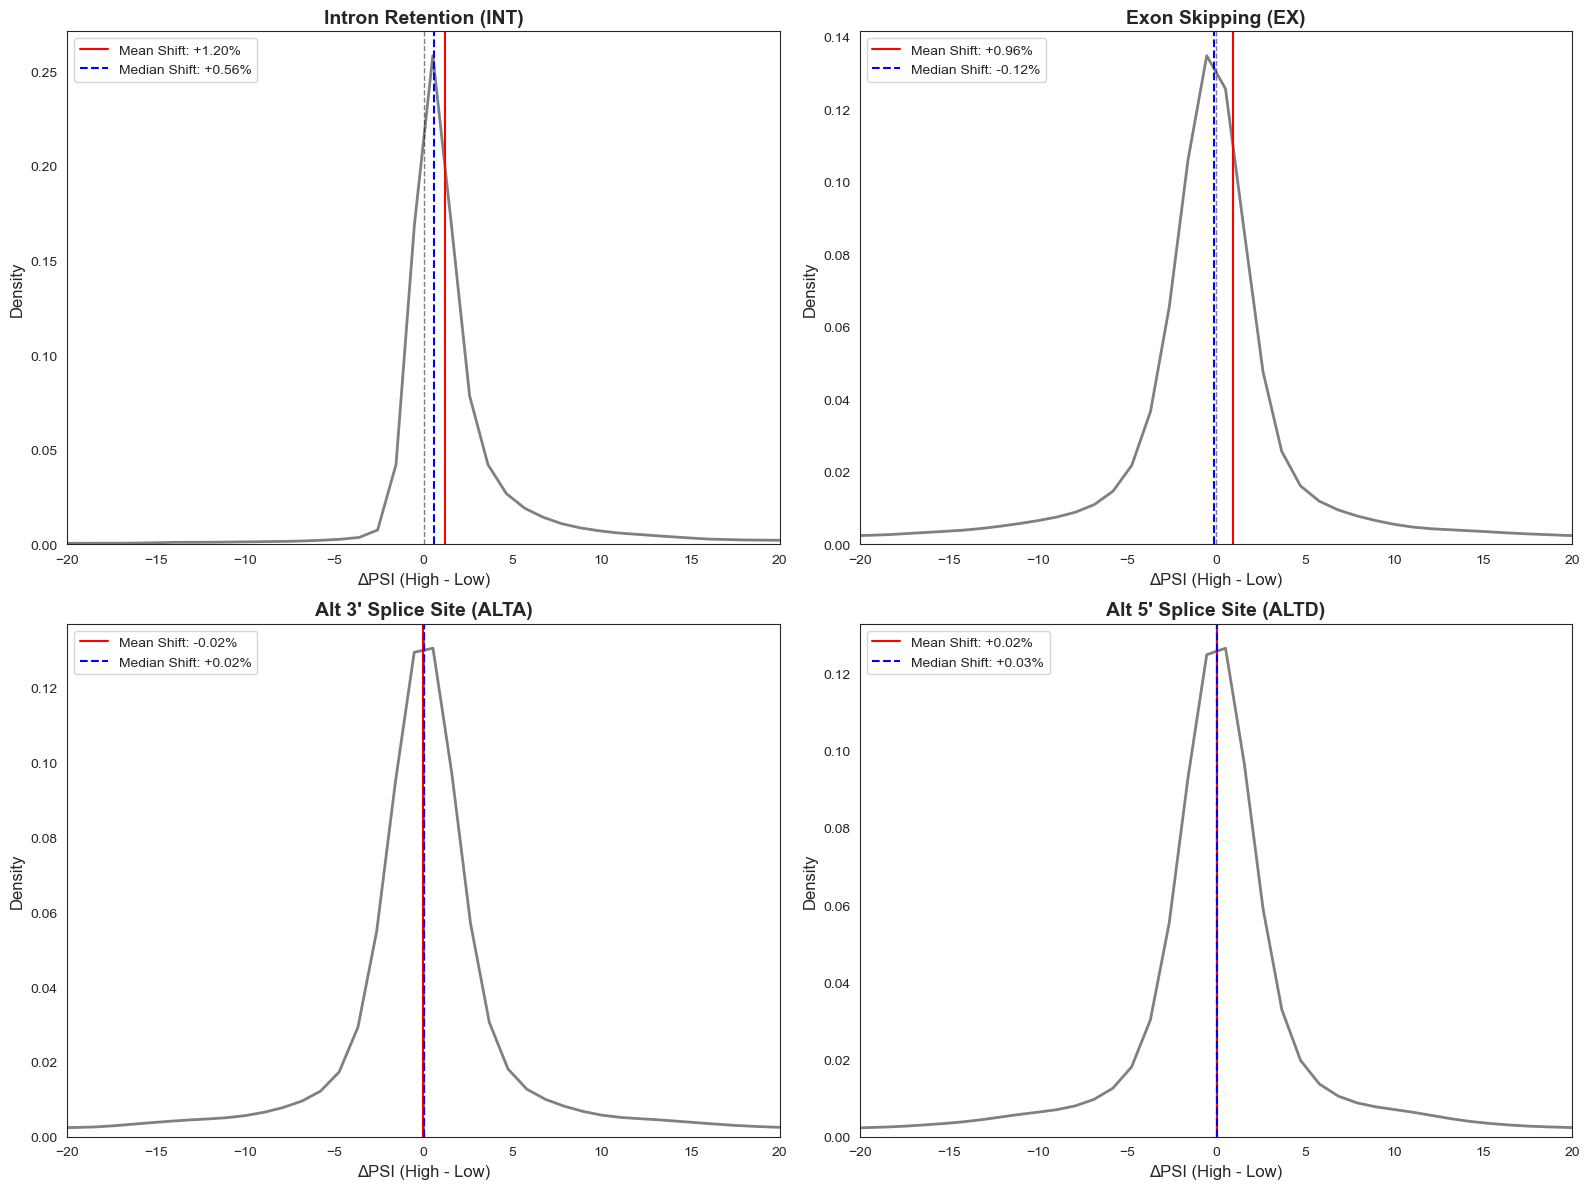

Summary of events with non-zero change (ΔPSI ≠ 0):
Event Type           | Count    | Mean       | Median    
------------------------------------------------------------
Intron Retention     | 44354    |     +1.20% |     +0.56%
Exon Skipping        | 18655    |     +0.96% |     -0.12%
Alt 3' Splice Site   | 18119    |     -0.02% |     +0.02%
Alt 5' Splice Site   | 13527    |     +0.02% |     +0.03%


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD AND CLEAN DATA
df_full = pd.read_csv("INCLUSION_LEVELS_FULL-mm10-2.tab", sep='\t')
df_full[['High_Senescence', 'Low_Senescence']] = df_full[['High_Senescence', 'Low_Senescence']].apply(pd.to_numeric, errors='coerce')
df_full = df_full.dropna(subset=['High_Senescence', 'Low_Senescence'])

# Calculate Delta PSI
df_full['dPSI'] = df_full['High_Senescence'] - df_full['Low_Senescence']

# FILTER: Remove exact 0s to calculate a realistic median for events that actually shifted
df_active = df_full[df_full['dPSI'] != 0].copy()

# 2. DEFINE EVENT TYPES
event_map = {
    'INT': 'Intron Retention',
    'EX': 'Exon Skipping',
    'ALTA': 'Alt 3\' Splice Site',
    'ALTD': 'Alt 5\' Splice Site'
}

# 3. LOOP AND PLOT
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (code, label) in enumerate(event_map.items()):
    # Filter for the specific event type from the filtered (non-zero) data
    subset = df_active[df_active['EVENT'].str.contains(code)].copy()
    
    if len(subset) == 0: continue
        
    mean_shift = subset['dPSI'].mean()
    median_shift = subset['dPSI'].median()
    
    # Continuous distribution: Grey line only (KDE)
    # bw_adjust=0.5 provides a good balance between smoothness and data detail
    sns.kdeplot(subset['dPSI'], ax=axes[i], color="grey", linewidth=2, bw_adjust=0.5)
    
    # Zero Reference Line (Black dashed)
    axes[i].axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    
    # Mean Line (Red solid)
    axes[i].axvline(mean_shift, color='red', linestyle='-', 
                    label=f'Mean Shift: {mean_shift:+.2f}%')
    
    # Median Line (Blue dashed)
    axes[i].axvline(median_shift, color='blue', linestyle='--', 
                    label=f'Median Shift: {median_shift:+.2f}%')
    
    # Titles and Axis Labels
    axes[i].set_title(f'{label} ({code})', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('ΔPSI (High - Low)', fontsize=12) # Updated Label
    axes[i].set_ylabel('Density', fontsize=12)
    
    # X-Axis Limit
    axes[i].set_xlim(-20, 20) 
    axes[i].legend(loc='upper left')

plt.tight_layout()
plt.show()

# 4. SUMMARY OUTPUT
print(f"Summary of events with non-zero change (ΔPSI ≠ 0):")
print(f"{'Event Type':<20} | {'Count':<8} | {'Mean':<10} | {'Median':<10}")
print("-" * 60)
for code, label in event_map.items():
    subset = df_active[df_active['EVENT'].str.contains(code)]
    if len(subset) == 0: continue
    print(f"{label:<20} | {len(subset):<8} | {subset['dPSI'].mean():>+9.2f}% | {subset['dPSI'].median():>+9.2f}%")

PSI (Percent Spliced In): For an Intron Retention event, this represents the percentage of mRNA transcripts that failed to remove the intron.
Positive ΔPSI
 (e.g., +5%): The intron is retained more often in the High Senescence group. This is a sign of splicing failure.
Negative ΔPSI
 (e.g., -5%): The intron is retained less often in the High Senescence group (it is being spliced out more efficiently).

Your ratio is 10.53x.
Interpretation: For every one intron that the senescent cell manages to splice better than a healthy cell, there are ten introns that it fails to splice correctly.

40,508 introns are increasing in retention. This means that nearly half of all detectable introns in the liver are being spliced less efficiently in senescent cells

INSTEAD OF PSI, WE LOOK AT THE INTRON RETENTION DISTRIBUTION USING THE ODS RATIO ESTIMATE

INSTEAD OF DELTA PSI WE WILL NOW USE THE ESTIMATE OF THE QUASIBINOMIAL MODEL:
- WHY QUASI?
In a standard Binomial model, the math assumes that the "noise" (variance) is perfectly predictable. In RNA-seq, this is almost never true

-- Overdispersion: Biological data has more "scatter" than pure math expects. If you use a standard binomial, the model thinks the data is "cleaner" than it is. This leads to artificially tiny p-values and a high rate of false positives.
-- Handling Decimals: As you saw, standard binomial hates decimals. quasibinomial handles non-integer counts (like your 55.23 reads) without complaining, treating them as "weighted" evidence.

- WHAT IS THE ESTIMATE?

-- In this model, the Estimate is the Log Odds Ratio (LogOR): 

ods=inclusion/exclusion

ods ratio=ods high/ods low

You are using the Log Odds Ratio as a proxy for ΔPSI. It is statistically "cleaner" than ΔPSI because it doesn't get "stuck" at 0% or 100% and correctly accounts for the fact that 50/10 reads is much stronger evidence than 5/1 reads.

ΔPSI is a "floating" metric. Because it is a simple ratio, it is extremely "jittery" at low coverage—a single read can swing the value by 50%.
The GLM, by using a Quasi-binomial distribution, "anchors" the estimate. The fact that events with the same coverage result in the same estimate is a sign of model consistency. It means the model is applying the exact same "penalty" for low coverage to every gene, rather than letting random noise create a fake "cloud" of false variation.

---

TO CREATE A LIBRARY OF HIGH QUALITY EVENTS!

In [ ]:
# Filter for the extreme right peak
extreme_retention = subset[subset['Estimate_LogOdds'] > 15].copy()

# Sort by p-value/FDR to find the most robust ones
extreme_retention = extreme_retention.sort_values('FDR')

# Save to a new CSV for manual inspection
extreme_retention.to_csv("Extreme_IR_Cluster.csv", index=False)

print(f"Found {len(extreme_retention)} events in the extreme cluster.")
print(extreme_retention[['Gene', 'Event', 'Estimate_LogOdds']].head(20))

In [ ]:
import pandas as pd
import numpy as np

# ==============================================================================
# 1. LOAD DATA
# ==============================================================================
full_file = "INCLUSION_LEVELS_Full-mm10-2.tab"
print(f"Reading {full_file}...")
df_full = pd.read_csv(full_file, sep='\t')

# ==============================================================================
# 2. FILTER FOR INTRONS
# ==============================================================================
df_ir = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()

# ==============================================================================
# 3. CONVERT SAMPLES TO NUMERIC (Preserves 0, Coerces "N" to NaN)
# ==============================================================================
samples = ['High_Senescence', 'Low_Senescence']
for s in samples:
    df_ir[s] = pd.to_numeric(df_ir[s], errors='coerce')

# ==============================================================================
# 4. APPLY "PLATINUM" CONFIDENCE FILTERS
# ==============================================================================

# Filter A: Must have valid numeric measurements (0 is allowed, N/NaN is removed)
df_ir = df_ir.dropna(subset=samples)

# Filter B: Updated Threshold (|Delta PSI| > 5)
df_ir['dPSI'] = df_ir['High_Senescence'] - df_ir['Low_Senescence']
# We use > 5 here as requested
df_robust = df_ir[df_ir['dPSI'].abs() > 5].copy()

# Filter C: Quality Score Check
def is_platinum_quality(q_string):
    """
    Ensures the measurement (even if 0) is backed by sufficient read coverage.
    """
    if pd.isna(q_string): 
        return False
    q_str = str(q_string).upper()
    return q_str.startswith('OK') or q_str.startswith('SOK')

mask_high = df_robust['High_Senescence-Q'].apply(is_platinum_quality)
mask_low = df_robust['Low_Senescence-Q'].apply(is_platinum_quality)

df_platinum = df_robust[mask_high & mask_low].copy()

# ==============================================================================
# 5. SORT AND REPORT
# ==============================================================================
df_platinum = df_platinum.sort_values(by='dPSI', ascending=False)

print("\n" + "="*70)
print(f"{'PLATINUM CONFIDENCE IR ANALYSIS (THRESHOLD > 5%)':^70}")
print("="*70)
print(f"Total Introns in Table:             {len(df_ir):,}")
print(f"Platinum Quality IR Events (>5%):   {len(df_platinum)}")
print(f"  - Significant Increases in High:  {len(df_platinum[df_platinum['dPSI'] > 0])}")
print(f"  - Significant Decreases in High:  {len(df_platinum[df_platinum['dPSI'] < 0])}")

print(f"\n[TOP 5 HIGH-CONFIDENCE HITS]")
print(f"{'GENE':<15} | {'dPSI':<10} | {'PSI (H/L)':<12} | {'QUALITY (H/L)'}")
print("-" * 70)

for _, row in df_platinum.head(5).iterrows():
    q_h = str(row['High_Senescence-Q']).split(',')[0]
    q_l = str(row['Low_Senescence-Q']).split(',')[0]
    psi_h = f"{row['High_Senescence']:.1f}"
    psi_l = f"{row['Low_Senescence']:.1f}"
    print(f"{row['GENE']:<15} | {row['dPSI']:>+7.1f}%   | {psi_h:>5}/{psi_l:<5} | {q_h}/{q_l}")

# Save results
df_platinum.to_csv("Platinum_Confidence_IR_5pct.csv", index=False)

Reading INCLUSION_LEVELS_Full-mm10-2.tab...

           PLATINUM CONFIDENCE IR ANALYSIS (THRESHOLD > 5%)           
Total Introns in Table:             84,266
Platinum Quality IR Events (>5%):   4285
  - Significant Increases in High:  3419
  - Significant Decreases in High:  866

[TOP 5 HIGH-CONFIDENCE HITS]
GENE            | dPSI       | PSI (H/L)    | QUALITY (H/L)
----------------------------------------------------------------------
Ska3            |  +100.0%   | 100.0/0.0   | OK/OK
Kif2a           |   +99.7%   |  99.7/0.0   | SOK/OK
Emilin2         |   +97.0%   |  97.0/0.0   | OK/OK
Kif22           |   +96.0%   |  96.0/0.0   | OK/SOK
Hdc             |   +95.5%   |  95.5/0.0   | SOK/OK


Checks:
- VAST quality score: must be OK or SOK
- Magnitude of change: the delta psi must be at least 5
- data completeness: there has to be a psi value for both high and low. 0 is a value, NaN is not

SOK (Super OK): This is the highest level of confidence. It means there is very high read coverage supporting both the inclusion and exclusion of the intron/exon. Usually, this means there are at least 20-25 actual reads spanning the junctions.
OK: This is the standard "High Quality" marker. It indicates that the number of reads is sufficient for a reliable PSI calculation (typically >10–15 reads). Results with "OK" are considered publication-ready.
LOW / VLOW (Low / Very Low): VAST-tools has calculated a PSI, but the number of reads is so small (e.g., 2 or 3 reads) that the value might change significantly if you just had one more read. These are "estimates" rather than "measurements."
N (No Coverage): There were zero reads mapping to this event in that sample.
B (Binary): Sometimes seen in Intron Retention. It means the event is "Binary"—the reads only support total inclusion or total exclusion, often due to high coverage of one junction but not the other.

This new script checks the internal VAST-TOOLS scoring. By requiring an "OK" or "SOK" status, we ensure that there were multiple reads mapping to the exon-intron boundaries and the internal intron body. These results are much more likely to validate via RT-qPCR.

With 5% of delta psi being the cut off value.

Excludes Na values

In [ ]:
import pandas as pd
import numpy as np

# ==============================================================================
# 1. LOAD AND PREPROCESS BASE DATA
# ==============================================================================
full_file = "INCLUSION_LEVELS_Full-mm10-2.tab"
df_full = pd.read_csv(full_file, sep='\t')

# Filter for Introns
df_ir = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()

# Convert to numeric
samples = ['High_Senescence', 'Low_Senescence']
for s in samples:
    df_ir[s] = pd.to_numeric(df_ir[s], errors='coerce')

# Drop rows where measurements are missing
df_clean = df_ir.dropna(subset=samples).copy()
df_clean['dPSI'] = df_clean['High_Senescence'] - df_clean['Low_Senescence']

# ==============================================================================
# 2. QUALITY FILTER LOGIC
# ==============================================================================
def is_platinum_quality(q_string):
    if pd.isna(q_string): return False
    q_str = str(q_string).upper()
    return q_str.startswith('OK') or q_str.startswith('SOK')

# Pre-filter for Quality (this remains constant regardless of dPSI threshold)
mask_quality = (
    df_clean['High_Senescence-Q'].apply(is_platinum_quality) & 
    df_clean['Low_Senescence-Q'].apply(is_platinum_quality)
)
df_quality_base = df_clean[mask_quality].copy()

# ==============================================================================
# 3. THRESHOLD SENSITIVITY ANALYSIS
# ==============================================================================
thresholds = [5, 0.5, 0.1]
report_lines = []

report_lines.append("="*70)
report_lines.append(f"{'SENSITIVITY ANALYSIS: PLATINUM IR EVENTS':^70}")
report_lines.append("="*70)
report_lines.append(f"Total Quality-Passed Introns (Base): {len(df_quality_base):,}")
report_lines.append("-" * 70)

for t in thresholds:
    # Apply specific dPSI threshold
    df_subset = df_quality_base[df_quality_base['dPSI'].abs() > t]
    
    count = len(df_subset)
    inc = len(df_subset[df_subset['dPSI'] > 0])
    dec = len(df_subset[df_subset['dPSI'] < 0])
    
    line = f"Threshold |ΔPSI| > {t}%: {count:,} events ({inc} up / {dec} down)"
    report_lines.append(line)

report_lines.append("-" * 70)

# Calculate the jump from 5% to 0.1%
jump = len(df_quality_base[df_quality_base['dPSI'].abs() > 0.1]) - len(df_quality_base[df_quality_base['dPSI'].abs() > 5])
percent_increase = (jump / len(df_quality_base[df_quality_base['dPSI'].abs() > 5])) * 100

report_lines.append(f"Observation: Dropping threshold from 5% to 0.1% adds {jump:,} events.")
report_lines.append(f"Relative increase in library size: {percent_increase:.1f}%")
report_lines.append("="*70)

# Output the final string
print("\n".join(report_lines))

               SENSITIVITY ANALYSIS: PLATINUM IR EVENTS               
Total Quality-Passed Introns (Base): 65,815
----------------------------------------------------------------------
Threshold |ΔPSI| > 5%: 4,285 events (3419 up / 866 down)
Threshold |ΔPSI| > 0.5%: 19,556 events (17658 up / 1898 down)
Threshold |ΔPSI| > 0.1%: 30,421 events (28054 up / 2367 down)
----------------------------------------------------------------------
Observation: Dropping threshold from 5% to 0.1% adds 26,136 events.
Relative increase in library size: 609.9%


At > 5%: The ratio of UP to DOWN is ~4:1 (3,419 vs 866).

At > 0.1%: The ratio of UP to DOWN is ~12:1 (28,054 vs 2,367).

C:\Users\lukas\AppData\Local\Temp\ipykernel_27620\2546155459.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


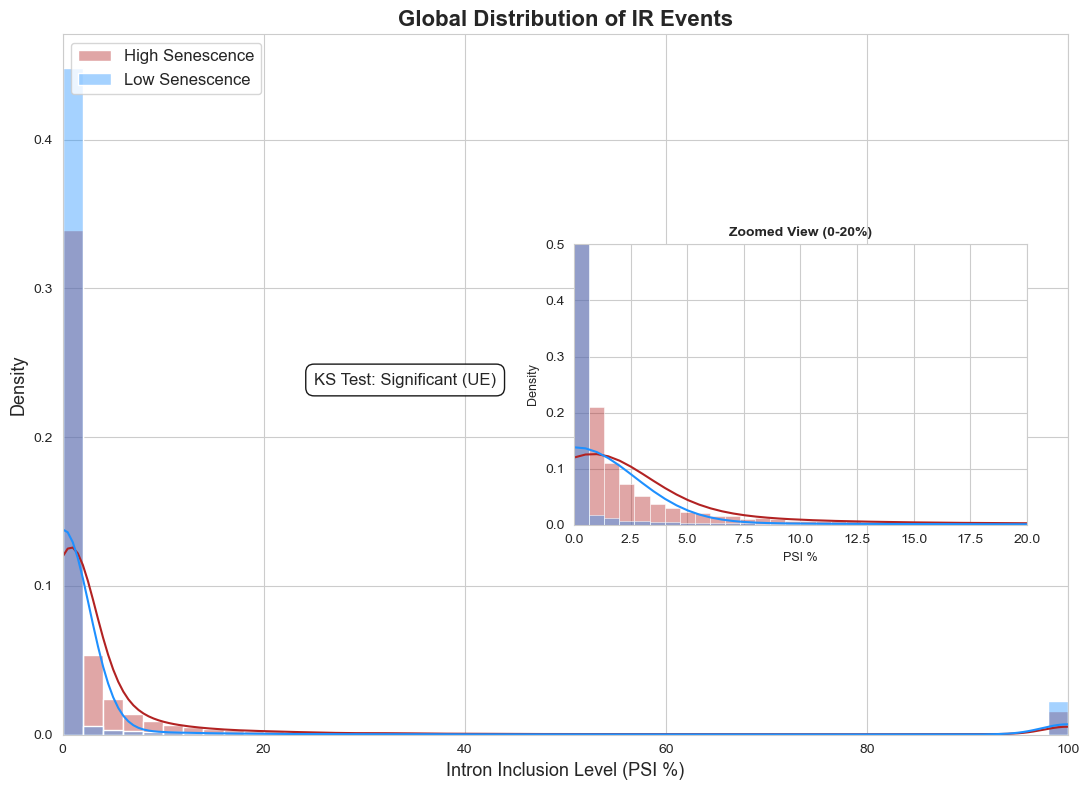

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# 1. LOAD AND PREPARE
full_file = "INCLUSION_LEVELS_Full-mm10-2.tab"
df_full = pd.read_csv(full_file, sep='\t')
df_ir = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()

samples = ['High_Senescence', 'Low_Senescence']
for s in samples:
    df_ir[s] = pd.to_numeric(df_ir[s], errors='coerce')

df_ir = df_ir.dropna(subset=samples)

# --- FILTER FOR "EXISTING" SPLICING ---
# Only keeping rows where at least one sample has inclusion > 0
df_active = df_ir[(df_ir['High_Senescence'] > 0) | (df_ir['Low_Senescence'] > 0)].copy()

# 2. STATISTICAL TEST
ks_stat, p_value = ks_2samp(df_active['High_Senescence'], df_active['Low_Senescence'])

if p_value == 0 or p_value < 1e-300:
    p_val_display = "Significant (UE)"
else:
    p_val_display = f"{p_value:.2e}"

# 3. VISUALIZATION
fig, ax = plt.subplots(figsize=(11, 8))
sns.set_style("whitegrid")

# Main plot distributions
sns.histplot(df_active['High_Senescence'], color="firebrick", label="High Senescence", 
             kde=True, stat="density", alpha=0.4, bins=50, ax=ax)
sns.histplot(df_active['Low_Senescence'], color="dodgerblue", label="Low Senescence", 
             kde=True, stat="density", alpha=0.4, bins=50, ax=ax)

# --- INSET START ---
ax_ins = inset_axes(ax, width="45%", height="40%", loc='center right', borderpad=3)

sns.histplot(df_active['High_Senescence'], color="firebrick", kde=True, 
             stat="density", alpha=0.4, bins=150, ax=ax_ins, label='_nolegend_')
sns.histplot(df_active['Low_Senescence'], color="dodgerblue", kde=True, 
             stat="density", alpha=0.4, bins=150, ax=ax_ins, label='_nolegend_')

# UPDATED: Zoomed constraints now go until 20%
ax_ins.set_xlim(0, 20)      
ax_ins.set_ylim(0, 0.5)     
ax_ins.set_title('Zoomed View (0-20%)', fontsize=10, fontweight='bold')
ax_ins.set_xlabel('PSI %', fontsize=9)
ax_ins.set_ylabel('Density', fontsize=9)
# --- INSET END ---

# 4. ADD ANNOTATION & LABELS
ax.set_title(f'Global Distribution of IR Events', fontsize=16, fontweight='bold')
ax.set_xlabel('Intron Inclusion Level (PSI %)', fontsize=13)
ax.set_ylabel('Density', fontsize=13)
ax.set_xlim(0, 100)

# Annotation: KS Test Only
stats_text = f"KS Test: {p_val_display}"

ax.text(25, ax.get_ylim()[1]*0.5, stats_text, fontsize=12, 
         bbox=dict(facecolor='white', alpha=0.9, edgecolor='black', boxstyle='round,pad=0.5'))

ax.legend(loc='upper left', fontsize=12)
plt.tight_layout()
plt.show()

The Filter Logic: I used (df_ir['High_Senescence'] > 0) | (df_ir['Low_Senescence'] > 0).
In a PSI plot, if both values are 0, that intron is not being retained at all. It "doesn't exist" in terms of splicing activity.
By removing these "double-zeros," the Density calculation becomes much more accurate. In your original plot, the peak at 0 was so high it made the rest of the data look like a flat line. Now, the curves will reflect the actual inclusion levels of introns that are biologically active.

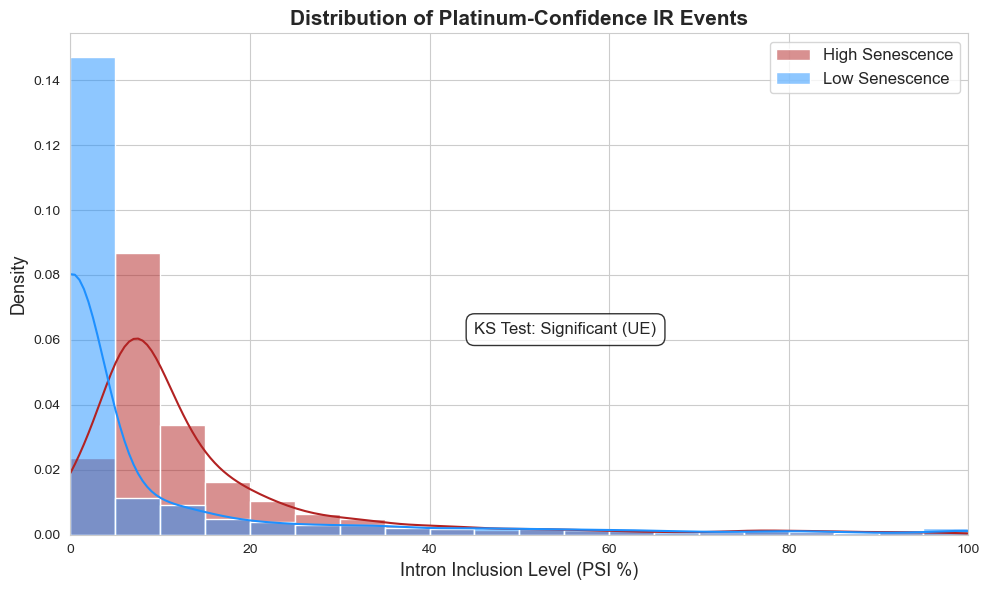

Analysis of Platinum Events:
The distribution shift is Significant (UE) (raw p = 0.0).
Nearly 79.8% of significant IR events are INCREASING in High Senescence.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

# 1. LOAD THE FILTERED PLATINUM DATA
df_platinum = pd.read_csv("Platinum_Confidence_IR_5pct.csv")

# 2. STATISTICAL TEST
ks_stat, p_value = ks_2samp(df_platinum['High_Senescence'], df_platinum['Low_Senescence'])

# Handle Underflow for the display logic
if p_value == 0 or p_value < 1e-300:
    p_val_display = "Significant (UE)"
else:
    p_val_display = f"{p_value:.2e}"

# 3. VISUALIZATION
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# RESTORED: Added labels back to histplot to enable legend
sns.histplot(df_platinum['High_Senescence'], color="firebrick", label="High Senescence",
             kde=True, stat="density", alpha=0.5, bins=20)
sns.histplot(df_platinum['Low_Senescence'], color="dodgerblue", label="Low Senescence",
             kde=True, stat="density", alpha=0.5, bins=20)

# 4. ADD ANNOTATION & LABELS
plt.title('Distribution of Platinum-Confidence IR Events', fontsize=15, fontweight='bold')
plt.xlabel('Intron Inclusion Level (PSI %)', fontsize=13)
plt.ylabel('Density', fontsize=13)
plt.xlim(0, 100)

# Keep the text box containing only the KS Test result
stats_text = f"KS Test: {p_val_display}"

# Positioned in the middle-right area
plt.text(45, plt.gca().get_ylim()[1]*0.4, stats_text, fontsize=12, 
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='black', boxstyle='round,pad=0.5'))

# RESTORED: Show the color legend
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

# 5. SUMMARY PRINT
inc = (df_platinum['dPSI'] > 0).sum()
print(f"Analysis of Platinum Events:")
print(f"The distribution shift is {p_val_display} (raw p = {p_value}).")
print(f"Nearly { (inc/len(df_platinum))*100:.1f}% of significant IR events are INCREASING in High Senescence.")

Biological Interpretation: This represents a systemic loss of splicing fidelity. It is not just that the introns are "sometimes" retained; it’s that a huge portion of the transcriptome has shifted from "Perfectly Spliced" to "Partially Retained."
The Threshold of Toxicity: In many genes, reaching 20-30% Intron Retention is the "tipping point" for Nonsense-Mediated Decay (NMD). This means the cell is likely wasting 20-30% of its energy producing mRNA that will be degraded and never turned into protein.

----

In [ ]:
import scanpy as sc
import gseapy as gp
import pandas as pd
import numpy as np

# 1. LOAD THE ANNDATA FILE TO GET YOUR GENE LIST
h5ad_path = "Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad"
print(f"Loading single-cell dataset: {h5ad_path}...")
adata = sc.read_h5ad(h5ad_path)

# Extract all unique gene symbols from your dataset
dataset_genes = set(adata.var['mouse_gene_symbols'].astype(str).str.capitalize())
print(f"Found {len(dataset_genes)} unique genes in the SC dataset.")

# 2. FETCH SPLICING FACTORS FROM GENE ONTOLOGY
print("Downloading Mouse Gene Ontology library...")
library = gp.get_library(name='GO_Biological_Process_2023', organism='Mouse')
sf_keywords = ["splicing", "spliceosome", "ribonucleoprotein", "rna processing"]

go_sf_genes = []
for term in library.keys():
    if any(key in term.lower() for key in sf_keywords):
        go_sf_genes.extend(library[term])

# Clean the GO list
go_sf_genes = set([str(gene).capitalize() for gene in go_sf_genes])

# 3. INTERSECT: Find Splicing Factors that are actually in your dataset
target_regulators = dataset_genes.intersection(go_sf_genes)
print(f"Identified {len(target_regulators)} splicing factors present in your liver dataset.")

# 4. LOAD VAST-TOOLS SPLICING DATA
vast_file = "INCLUSION_LEVELS_FULL-mm10-2.tab"
print(f"Loading VAST-TOOLS file: {vast_file}...")
df_full = pd.read_csv(vast_file, sep='\t')
df_full['GENE'] = df_full['GENE'].str.capitalize()

# 5. FILTER VAST-TOOLS FOR INTRON RETENTION (INT) AND YOUR TARGET REGULATORS
# This finds IR events occurring WITHIN the genes identified in step 3
df_ir = df_full[
    (df_full['EVENT'].str.contains('INT', na=False)) & 
    (df_full['GENE'].isin(target_regulators))
].copy()

# 6. CALCULATE dPSI (Difference between High and Low Senescence)
def get_mean_psi(value):
    if pd.isna(value) or value == 'NA': return np.nan
    try:
        # Handles comma-separated replicates: '10.5,12.0' -> 11.25
        nums = [float(x) for x in str(value).split(',') if x != 'NA']
        return np.mean(nums) if nums else np.nan
    except: return np.nan

print("Calculating PSI differences...")
df_ir['PSI_High'] = df_ir['High_Senescence'].apply(get_mean_psi)
df_ir['PSI_Low'] = df_ir['Low_Senescence'].apply(get_mean_psi)

# Remove rows with missing data
df_ir = df_ir.dropna(subset=['PSI_High', 'PSI_Low'])
df_ir['dPSI'] = df_ir['PSI_High'] - df_ir['PSI_Low']
df_ir['abs_dPSI'] = df_ir['dPSI'].abs()

# 7. PICK THE MOST CHANGED EVENT PER GENE
df_best_events = df_ir.sort_values('abs_dPSI', ascending=False).drop_duplicates('GENE')

# 8. FORMAT FOR IGV (Add buffer for visualization)
def format_igv_coord(coord_string):
    try:
        chrom = coord_string.split(':')[0]
        start_end = coord_string.split(':')[1]
        start = int(start_end.split('-')[0])
        end = int(start_end.split('-')[1])
        return f"{chrom}:{start-200}-{end+200}"
    except:
        return coord_string

df_best_events['IGV_COORD'] = df_best_events['COORD'].apply(format_igv_coord)

# 9. OUTPUT RESULTS
print("\n" + "="*95)
print(f"{'IR EVENTS IN DETECTED SPLICING REGULATORS':^95}")
print("="*95)
print(f"{'GENE':<12} | {'EVENT':<15} | {'High PSI':<10} | {'Low PSI':<10} | {'dPSI (%)':<10} | {'IGV COORDINATE'}")
print("-" * 95)

df_best_events = df_best_events.sort_values('abs_dPSI', ascending=False)
for _, row in df_best_events.head(25).iterrows():
    print(f"{row['GENE']:<12} | {row['EVENT']:<15} | {row['PSI_High']:>8.1f} | {row['PSI_Low']:>8.1f} | {row['dPSI']:>+8.1f}% | {row['IGV_COORD']}")

# 10. SAVE
output_name = "liver_sf_intron_retention_results.csv"
df_best_events.to_csv(output_name, index=False)
print("\n" + "="*95)
print(f"Analysis Complete.")
print(f"Total Splicing Factors with IR events found: {len(df_best_events)}")
print(f"Results saved to: {output_name}")

Loading single-cell dataset: Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad...
Found 19559 unique genes in the SC dataset.
Identified 645 splicing factors present in your liver dataset.
Loading VAST-TOOLS file: INCLUSION_LEVELS_FULL-mm10-2.tab...
Calculating PSI differences...

                           IR EVENTS IN DETECTED SPLICING REGULATORS                           
GENE         | EVENT           | High PSI   | Low PSI    | dPSI (%)   | IGV COORDINATE
-----------------------------------------------------------------------------------------------
Aqr          | MmuINT0017500   |      0.0 |    100.0 |   -100.0% | chr2:114157409-114159069
Pnldc1       | MmuINT0123031   |      0.0 |    100.0 |   -100.0% | chr17:12891979-12892519
Polr2a       | MmuINT0123829   |      1.4 |    100.0 |    -98.6% | chr11:69744845-69745768
Mrm1         | MmuINT0100677   |      4.5 |    100.0 |    -95.5% | chr11:84814841-84818799
Pus10        | MmuINT0129756   |      

----

CORRELATION BETWEEN DELTA PSI AND EXPRESSION CHANGE IN SENMAYO PSEUDO-BULK

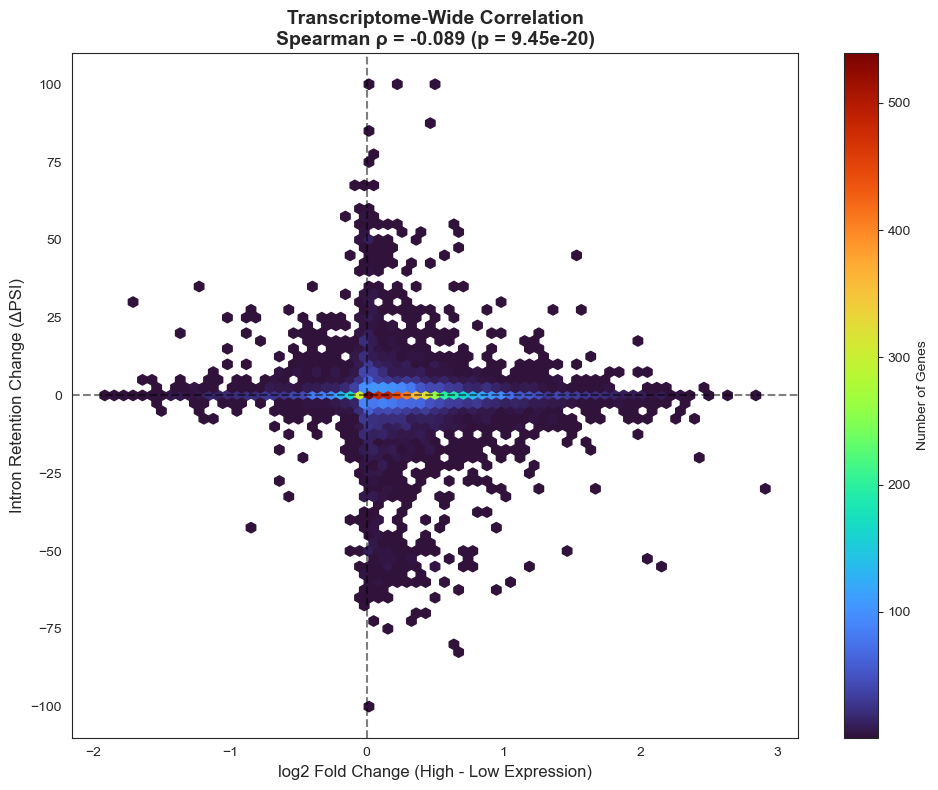

Analysis complete. Matched 10456 genes.


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# 1. Load Data
adata = sc.read_h5ad('Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad')
ir_df = pd.read_csv('INCLUSION_LEVELS_Full-mm10-2.tab', sep='\t')

# 2. Global Expression Change (Converted to Log2 Fold Change)
if 'mouse_gene_symbols' in adata.var.columns:
    adata.var_names = adata.var['mouse_gene_symbols'].str.capitalize()
else:
    adata.var_names = adata.var_names.str.capitalize()

high_cells = adata[adata.obs['senescence_group'] == 'High_Senescence']
low_cells = adata[adata.obs['senescence_group'] == 'Low_Senescence']

# Calculate mean of log-normalized counts (usually natural log in Scanpy)
exp_high = np.array(high_cells.X.mean(axis=0)).flatten()
exp_low = np.array(low_cells.X.mean(axis=0)).flatten()

# Convert natural log difference to Log2 Fold Change
# Formula: ln(ratio) / ln(2) = log2(ratio)
lfc_log2 = (exp_high - exp_low) / np.log(2)

expression_df = pd.DataFrame({
    'Gene': adata.var_names,
    'LFC_Log2': lfc_log2
}).set_index('Gene')

# 3. Global IR Change
def get_mean_psi(value):
    if pd.isna(value) or value == 'NA': return np.nan
    try:
        nums = [float(x) for x in str(value).split(',') if x != 'NA']
        return np.mean(nums) if nums else np.nan
    except: return np.nan

ir_df['GENE'] = ir_df['GENE'].str.capitalize()
ir_df['PSI_High'] = ir_df['High_Senescence'].apply(get_mean_psi)
ir_df['PSI_Low'] = ir_df['Low_Senescence'].apply(get_mean_psi)

ir_summary = ir_df.groupby('GENE')[['PSI_High', 'PSI_Low']].mean()
ir_summary['IR_Change'] = ir_summary['PSI_High'] - ir_summary['PSI_Low']

# 4. Merge Transcriptome-wide
full_transcriptome = expression_df.merge(ir_summary, left_index=True, right_index=True).dropna()

# 5. Calculate Spearman
rho, pval = spearmanr(full_transcriptome['LFC_Log2'], full_transcriptome['IR_Change'])

# 6. Visualization (Density Plot)
plt.figure(figsize=(10, 8))

hb = plt.hexbin(
    full_transcriptome['LFC_Log2'], 
    full_transcriptome['IR_Change'], 
    gridsize=70, 
    cmap='turbo', 
    mincnt=1
)

cb = plt.colorbar(hb, label='Number of Genes')

# Add crosshairs
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.axvline(0, color='black', linestyle='--', alpha=0.5)

# Formatting
plt.title(f"Transcriptome-Wide Correlation\nSpearman ρ = {rho:.3f} (p = {pval:.2e})", fontsize=14, fontweight='bold')
plt.xlabel("log2 Fold Change (High - Low Expression)", fontsize=12) # Updated Label
plt.ylabel("Intron Retention Change (ΔPSI)", fontsize=12)

plt.tight_layout()
plt.show()

print(f"Analysis complete. Matched {len(full_transcriptome)} genes.")

---

FIRST RIBOSOME GENES AND MITOCHONDRIA RIBOSOME GENES THAT SHOWED AN INTERESTING SIGNAL

Loading datasets...
Loaded 105 cytoplasmic and 77 mitochondrial genes.


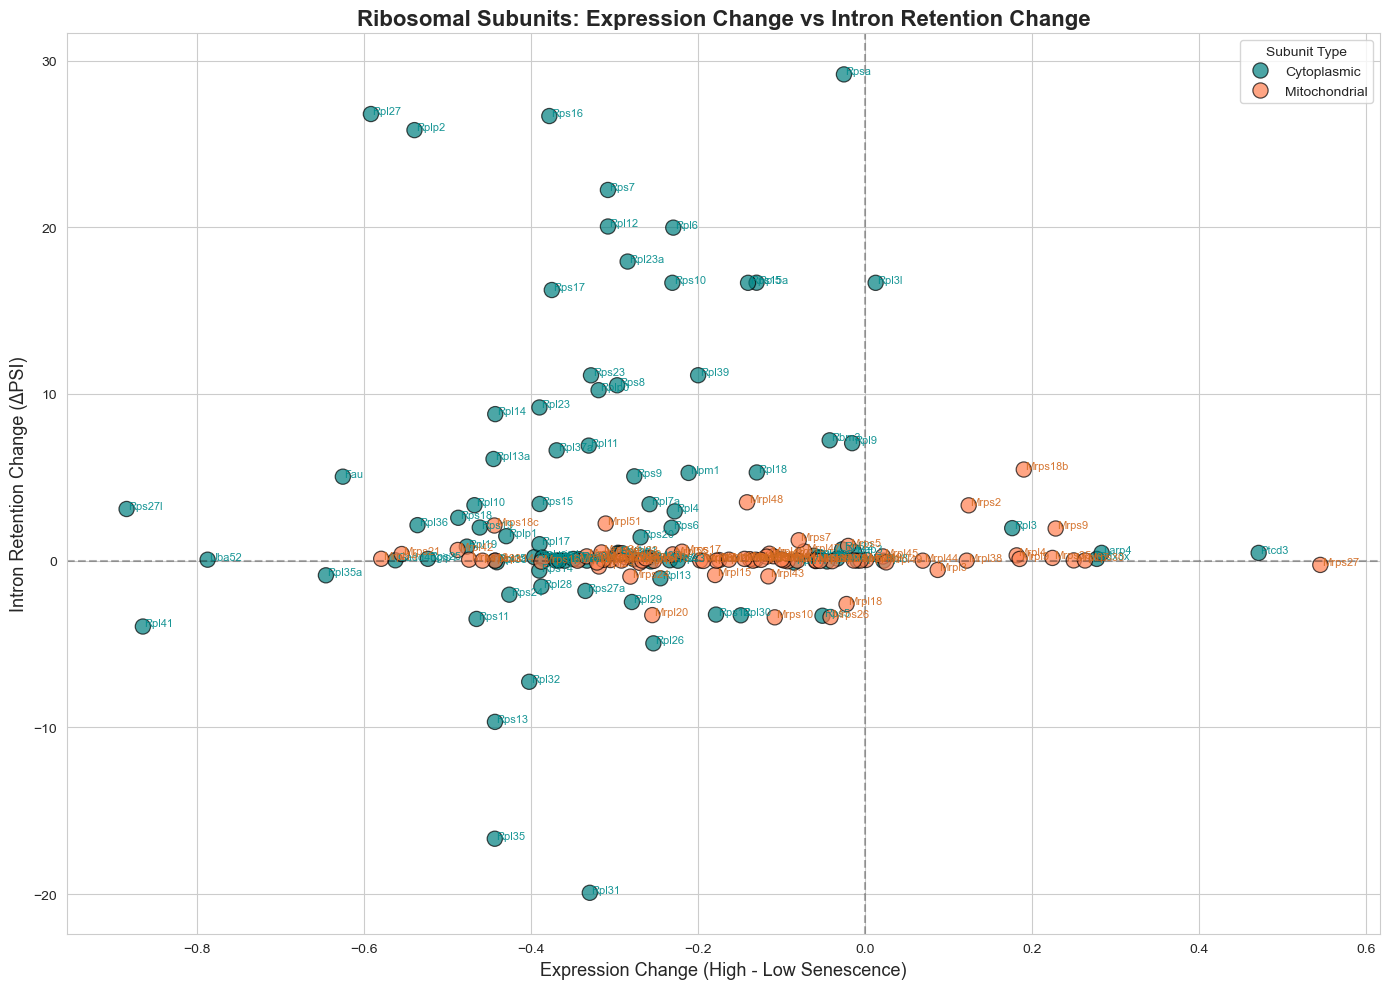

Matched 92 Cytoplasmic genes and 75 Mitochondrial genes.


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD DATA
print("Loading datasets...")
adata = sc.read_h5ad('Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad')
ir_df = pd.read_csv('INCLUSION_LEVELS_Full-mm10-2.tab', sep='\t')

# 2. LOAD GENES FROM BOTH TEXT FILES
path_cytoplasmic = 'Ribosomal subunits.txt'
path_mitochondrial = 'MT Ribosomal subunits.txt'

def load_gene_list(path):
    try:
        df = pd.read_csv(path, header=0, names=['gene_symbol'])
        return set(df['gene_symbol'].dropna().astype(str).str.strip().str.capitalize())
    except FileNotFoundError:
        print(f"Warning: File not found at {path}")
        return set()

cytoplasmic_genes = load_gene_list(path_cytoplasmic)
mitochondrial_genes = load_gene_list(path_mitochondrial)

print(f"Loaded {len(cytoplasmic_genes)} cytoplasmic and {len(mitochondrial_genes)} mitochondrial genes.")

# 3. CALCULATE EXPRESSION CHANGE
if 'mouse_gene_symbols' in adata.var.columns:
    adata.var_names = adata.var['mouse_gene_symbols'].str.capitalize()
else:
    adata.var_names = adata.var_names.str.capitalize()

high_cells = adata[adata.obs['senescence_group'] == 'High_Senescence']
low_cells = adata[adata.obs['senescence_group'] == 'Low_Senescence']

exp_high = np.array(high_cells.X.mean(axis=0)).flatten()
exp_low = np.array(low_cells.X.mean(axis=0)).flatten()

expression_df = pd.DataFrame({
    'Gene': adata.var_names,
    'Exp_Change': exp_high - exp_low
}).set_index('Gene')

# 4. CALCULATE IR CHANGE (VAST-TOOLS)
def get_mean_psi(value):
    if pd.isna(value) or value == 'NA': return np.nan
    try:
        nums = [float(x) for x in str(value).split(',') if x != 'NA']
        return np.mean(nums) if nums else np.nan
    except: return np.nan

ir_df['GENE'] = ir_df['GENE'].str.capitalize()
ir_df['PSI_High'] = ir_df['High_Senescence'].apply(get_mean_psi)
ir_df['PSI_Low'] = ir_df['Low_Senescence'].apply(get_mean_psi)

ir_summary = ir_df.groupby('GENE')[['PSI_High', 'PSI_Low']].mean()
ir_summary['IR_Change'] = ir_summary['PSI_High'] - ir_summary['PSI_Low']

# 5. MERGE AND TAG GENE TYPES
full_merged = expression_df.merge(ir_summary, left_index=True, right_index=True).dropna()

cyto_df = full_merged[full_merged.index.isin(cytoplasmic_genes)].copy()
cyto_df['Subunit_Type'] = 'Cytoplasmic'

mito_df = full_merged[full_merged.index.isin(mitochondrial_genes)].copy()
mito_df['Subunit_Type'] = 'Mitochondrial'

combined_rp_df = pd.concat([cyto_df, mito_df])

# 6. VISUALIZATION
if len(combined_rp_df) == 0:
    print("Error: No genes matched the dataset from either file.")
else:
    plt.figure(figsize=(14, 10))
    sns.set_style("whitegrid")

    palette = {'Cytoplasmic': 'teal', 'Mitochondrial': 'coral'}
    
    sns.scatterplot(
        data=combined_rp_df, x='Exp_Change', y='IR_Change', 
        hue='Subunit_Type', palette=palette,
        s=120, edgecolor='black', alpha=0.7
    )

    # Label genes (with colors matching their category)
    for gene, row in combined_rp_df.iterrows():
        label_color = 'darkcyan' if row['Subunit_Type'] == 'Cytoplasmic' else 'chocolate'
        plt.text(x=row['Exp_Change'] + 0.002, y=row['IR_Change'] + 0.002, 
                 s=gene, fontsize=8, color=label_color, alpha=0.9)

    plt.axhline(0, color='black', linestyle='--', alpha=0.3)
    plt.axvline(0, color='black', linestyle='--', alpha=0.3)
    
    plt.title("Ribosomal Subunits: Expression Change vs Intron Retention Change", fontweight='bold', fontsize=16)
    plt.xlabel("Expression Change (High - Low Senescence)", fontsize=13)
    plt.ylabel("Intron Retention Change (ΔPSI)", fontsize=13)
    plt.legend(title="Subunit Type", frameon=True)
    
    plt.tight_layout()
    plt.show()

    print(f"Matched {len(cyto_df)} Cytoplasmic genes and {len(mito_df)} Mitochondrial genes.")

NOW FOR SPLICING FACTORS, based on the mean expression

Loading datasets...


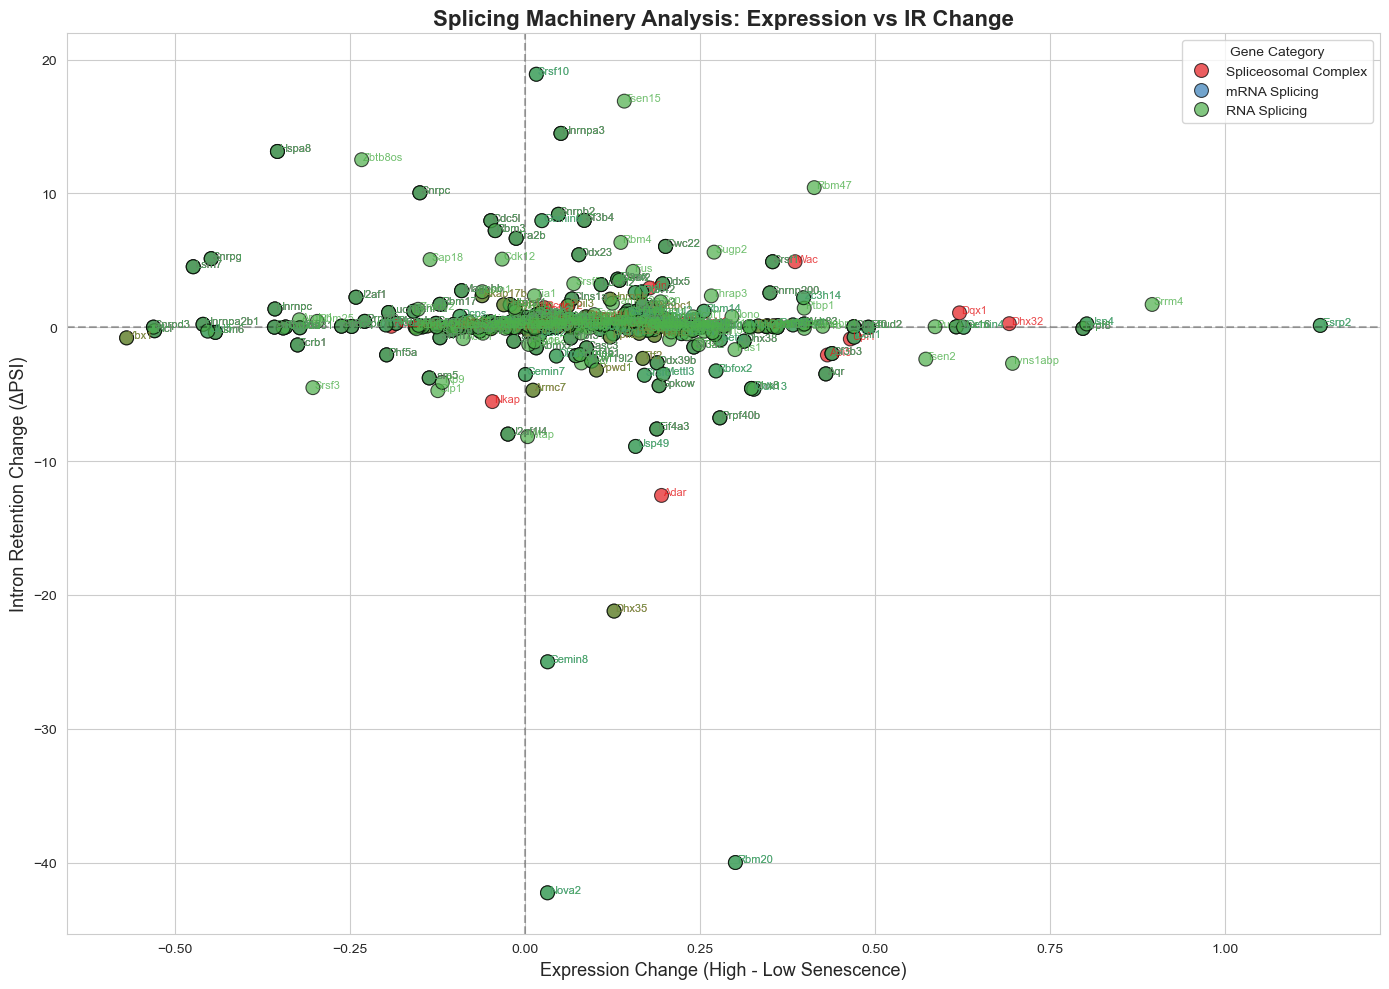


Summary of matched genes:
- Spliceosomal Complex: 181 genes
- mRNA Splicing: 182 genes
- RNA Splicing: 295 genes


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD DATA
print("Loading datasets...")
adata = sc.read_h5ad('Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad')
ir_df = pd.read_csv('INCLUSION_LEVELS_Full-mm10-2.tab', sep='\t')

# 2. LOAD GENES FROM THE THREE TEXT FILES
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

def load_gene_list(path):
    try:
        df = pd.read_csv(path, header=0, names=['gene_symbol'])
        return set(df['gene_symbol'].dropna().astype(str).str.strip().str.capitalize())
    except FileNotFoundError:
        print(f"Warning: File not found at {path}")
        return set()

gene_sets = {name: load_gene_list(path) for name, path in paths.items()}

# 3. CALCULATE EXPRESSION CHANGE
if 'mouse_gene_symbols' in adata.var.columns:
    adata.var_names = adata.var['mouse_gene_symbols'].str.capitalize()
else:
    adata.var_names = adata.var_names.str.capitalize()

high_cells = adata[adata.obs['senescence_group'] == 'High_Senescence']
low_cells = adata[adata.obs['senescence_group'] == 'Low_Senescence']

exp_high = np.array(high_cells.X.mean(axis=0)).flatten()
exp_low = np.array(low_cells.X.mean(axis=0)).flatten()

expression_df = pd.DataFrame({
    'Gene': adata.var_names,
    'Exp_Change': exp_high - exp_low
}).set_index('Gene')

# 4. CALCULATE IR CHANGE (VAST-TOOLS)
def get_mean_psi(value):
    if pd.isna(value) or value == 'NA': return np.nan
    try:
        nums = [float(x) for x in str(value).split(',') if x != 'NA']
        return np.mean(nums) if nums else np.nan
    except: return np.nan

ir_df['GENE'] = ir_df['GENE'].str.capitalize()
ir_df['PSI_High'] = ir_df['High_Senescence'].apply(get_mean_psi)
ir_df['PSI_Low'] = ir_df['Low_Senescence'].apply(get_mean_psi)

ir_summary = ir_df.groupby('GENE')[['PSI_High', 'PSI_Low']].mean()
ir_summary['IR_Change'] = ir_summary['PSI_High'] - ir_summary['PSI_Low']

# 5. MERGE AND TAG GENE TYPES
full_merged = expression_df.merge(ir_summary, left_index=True, right_index=True).dropna()

dfs_to_combine = []
for category, gene_list in gene_sets.items():
    subset = full_merged[full_merged.index.isin(gene_list)].copy()
    subset['Category'] = category
    dfs_to_combine.append(subset)

combined_df = pd.concat(dfs_to_combine)

# 6. VISUALIZATION
if len(combined_df) == 0:
    print("Error: No genes matched the dataset.")
else:
    plt.figure(figsize=(14, 10))
    sns.set_style("whitegrid")

    palette = {
        'Spliceosomal Complex': '#e41a1c', # Red
        'mRNA Splicing': '#377eb8',        # Blue
        'RNA Splicing': '#4daf4a'          # Green
    }
    
    sns.scatterplot(
        data=combined_df, x='Exp_Change', y='IR_Change', 
        hue='Category', palette=palette,
        s=100, edgecolor='black', alpha=0.7
    )

    # Label genes with category-matched colors
    for i in range(len(combined_df)):
        row = combined_df.iloc[i]
        gene_name = combined_df.index[i]
        plt.text(
            x=row['Exp_Change'] + 0.002, 
            y=row['IR_Change'] + 0.002, 
            s=gene_name, 
            fontsize=8, 
            color=palette[row['Category']], 
            alpha=0.8
        )

    plt.axhline(0, color='black', linestyle='--', alpha=0.3)
    plt.axvline(0, color='black', linestyle='--', alpha=0.3)
    
    plt.title("Splicing Machinery Analysis: Expression vs IR Change", fontweight='bold', fontsize=16)
    plt.xlabel("Expression Change (High - Low Senescence)", fontsize=13)
    plt.ylabel("Intron Retention Change (ΔPSI)", fontsize=13)
    plt.legend(title="Gene Category", frameon=True, loc='best')
    
    plt.tight_layout()
    plt.show()

    # Final summary output
    print("\nSummary of matched genes:")
    for cat in paths.keys():
        count = len(combined_df[combined_df['Category'] == cat])
        print(f"- {cat}: {count} genes")

---

NOW FOR SPLICING FACTORS AGAIN, but based on the median

Loading datasets...
Calculating expression changes based on Median...
Processing VAST-TOOLS IR data...


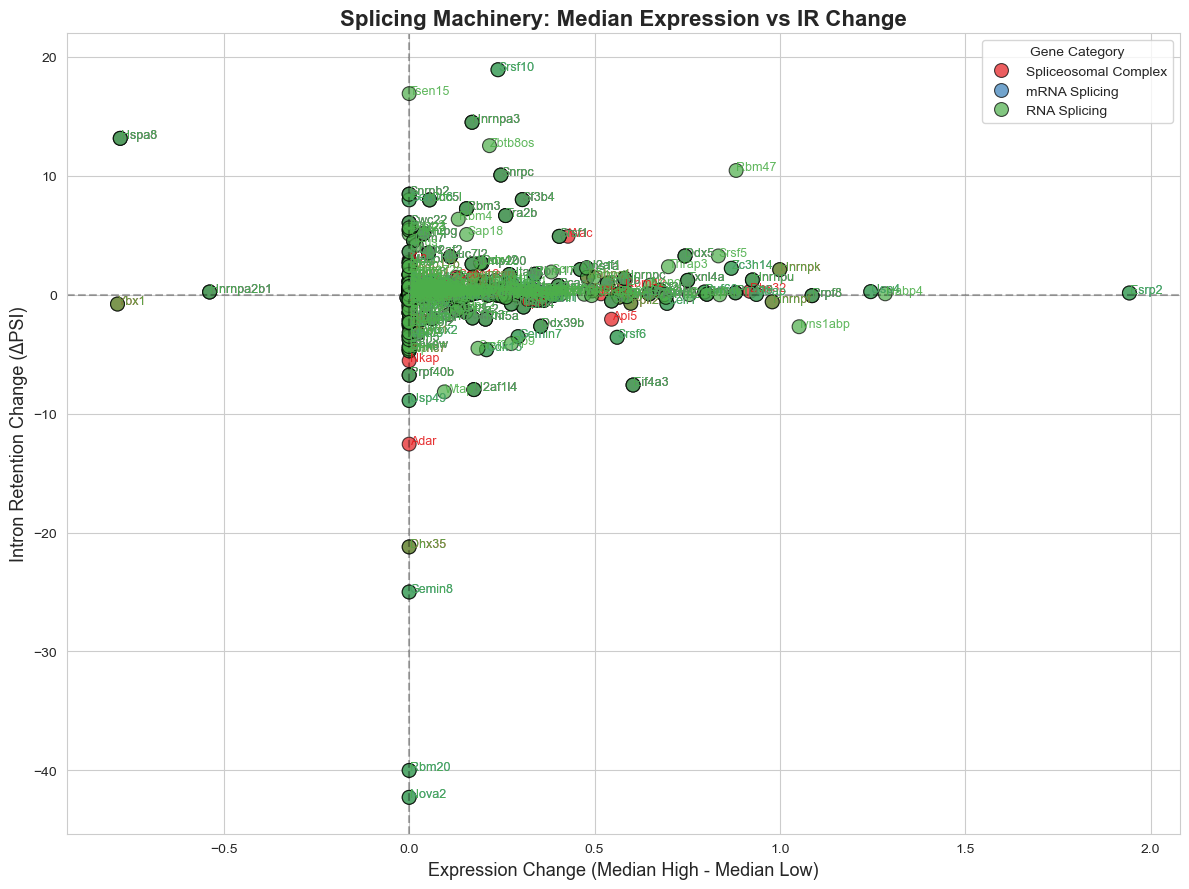


Summary of matched genes:
- Spliceosomal Complex: 181 genes
- mRNA Splicing: 182 genes
- RNA Splicing: 295 genes

Genes with Median Downregulation: 11
['Hnrnpa2b1', 'Hspa8', 'Ncl', 'Ybx1', 'Hnrnpa2b1', 'Hspa8', 'Ncl', 'Hnrnpa2b1', 'Hspa8', 'Ncl', 'Ybx1']


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp

# ==========================================
# 1. LOAD DATA
# ==========================================
print("Loading datasets...")
# Load the AnnData object
adata = sc.read_h5ad('Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad')
# Load the VAST-TOOLS inclusion table
ir_df = pd.read_csv('INCLUSION_LEVELS_Full-mm10-2.tab', sep='\t')

# ==========================================
# 2. LOAD GENE LISTS
# ==========================================
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

def load_gene_list(path):
    try:
        # Assumes gene symbols are in the first column
        df = pd.read_csv(path, header=0, names=['gene_symbol'])
        return set(df['gene_symbol'].dropna().astype(str).str.strip().str.capitalize())
    except FileNotFoundError:
        print(f"Warning: File not found at {path}")
        return set()

gene_sets = {name: load_gene_list(path) for name, path in paths.items()}

# ==========================================
# 3. CALCULATE EXPRESSION CHANGE (MEDIAN)
# ==========================================
print("Calculating expression changes based on Median...")

# Standardize gene names in AnnData
if 'mouse_gene_symbols' in adata.var.columns:
    adata.var_names = adata.var['mouse_gene_symbols'].str.capitalize()
else:
    adata.var_names = adata.var_names.str.capitalize()

# Split groups
high_cells = adata[adata.obs['senescence_group'] == 'High_Senescence']
low_cells = adata[adata.obs['senescence_group'] == 'Low_Senescence']

def get_median_expression(adata_subset):
    """
    Calculates median across cells for each gene.
    Handles sparse matrices by converting to dense arrays.
    """
    if sp.issparse(adata_subset.X):
        # Convert to dense for median calculation (safe for ~500 cells)
        return np.median(adata_subset.X.toarray(), axis=0)
    else:
        return np.median(adata_subset.X, axis=0)

exp_high = get_median_expression(high_cells)
exp_low = get_median_expression(low_cells)

expression_df = pd.DataFrame({
    'Gene': adata.var_names,
    'Exp_Change': exp_high - exp_low
}).set_index('Gene')

# ==========================================
# 4. CALCULATE IR CHANGE (VAST-TOOLS)
# ==========================================
print("Processing VAST-TOOLS IR data...")

def get_mean_psi(value):
    """Parses VAST-TOOLS PSI values which may be comma-separated strings."""
    if pd.isna(value) or value == 'NA': return np.nan
    try:
        # Split by comma if multiple replicates are present in one column
        nums = [float(x) for x in str(value).split(',') if x != 'NA']
        return np.mean(nums) if nums else np.nan
    except: return np.nan

# Clean up VAST-TOOLS table
ir_df['GENE'] = ir_df['GENE'].str.capitalize()

# Note: Using 'High_Senescence' and 'Low_Senescence' columns 
# Ensure these match the column headers in your .tab file
ir_df['PSI_High'] = ir_df['High_Senescence'].apply(get_mean_psi)
ir_df['PSI_Low'] = ir_df['Low_Senescence'].apply(get_mean_psi)

# Group by Gene (averaging IR across multiple events for the same gene)
ir_summary = ir_df.groupby('GENE')[['PSI_High', 'PSI_Low']].mean()
ir_summary['IR_Change'] = ir_summary['PSI_High'] - ir_summary['PSI_Low']

# ==========================================
# 5. MERGE AND FILTER
# ==========================================
# Combine Expression and Splicing data
full_merged = expression_df.merge(ir_summary, left_index=True, right_index=True).dropna()

dfs_to_combine = []
for category, gene_list in gene_sets.items():
    subset = full_merged[full_merged.index.isin(gene_list)].copy()
    subset['Category'] = category
    dfs_to_combine.append(subset)

combined_df = pd.concat(dfs_to_combine)

# ==========================================
# 6. VISUALIZATION
# ==========================================
if len(combined_df) == 0:
    print("Error: No genes matched between the lists, AnnData, and VAST-TOOLS table.")
else:
    plt.figure(figsize=(12, 9))
    sns.set_style("whitegrid")

    palette = {
        'Spliceosomal Complex': '#e41a1c', # Red
        'mRNA Splicing': '#377eb8',        # Blue
        'RNA Splicing': '#4daf4a'          # Green
    }
    
    # Scatterplot
    sns.scatterplot(
        data=combined_df, x='Exp_Change', y='IR_Change', 
        hue='Category', palette=palette,
        s=100, edgecolor='black', alpha=0.7
    )

    # Label genes
    for i in range(len(combined_df)):
        row = combined_df.iloc[i]
        gene_name = combined_df.index[i]
        plt.text(
            x=row['Exp_Change'] + 0.001, 
            y=row['IR_Change'] + 0.001, 
            s=gene_name, 
            fontsize=9, 
            color=palette[row['Category']], 
            alpha=0.9
        )

    # Reference lines
    plt.axhline(0, color='black', linestyle='--', alpha=0.3)
    plt.axvline(0, color='black', linestyle='--', alpha=0.3)
    
    plt.title("Splicing Machinery: Median Expression vs IR Change", fontweight='bold', fontsize=16)
    plt.xlabel("Expression Change (Median High - Median Low)", fontsize=13)
    plt.ylabel("Intron Retention Change (ΔPSI)", fontsize=13)
    plt.legend(title="Gene Category", frameon=True, loc='best')
    
    plt.tight_layout()
    plt.show()

    # Final summary output
    print("\nSummary of matched genes:")
    for cat in paths.keys():
        count = len(combined_df[combined_df['Category'] == cat])
        print(f"- {cat}: {count} genes")
    
    # Print the genes showing downregulation to verify against literature
    downregulated = combined_df[combined_df['Exp_Change'] < 0]
    print(f"\nGenes with Median Downregulation: {len(downregulated)}")
    if len(downregulated) > 0:
        print(downregulated.index.tolist())

---

Loading datasets...


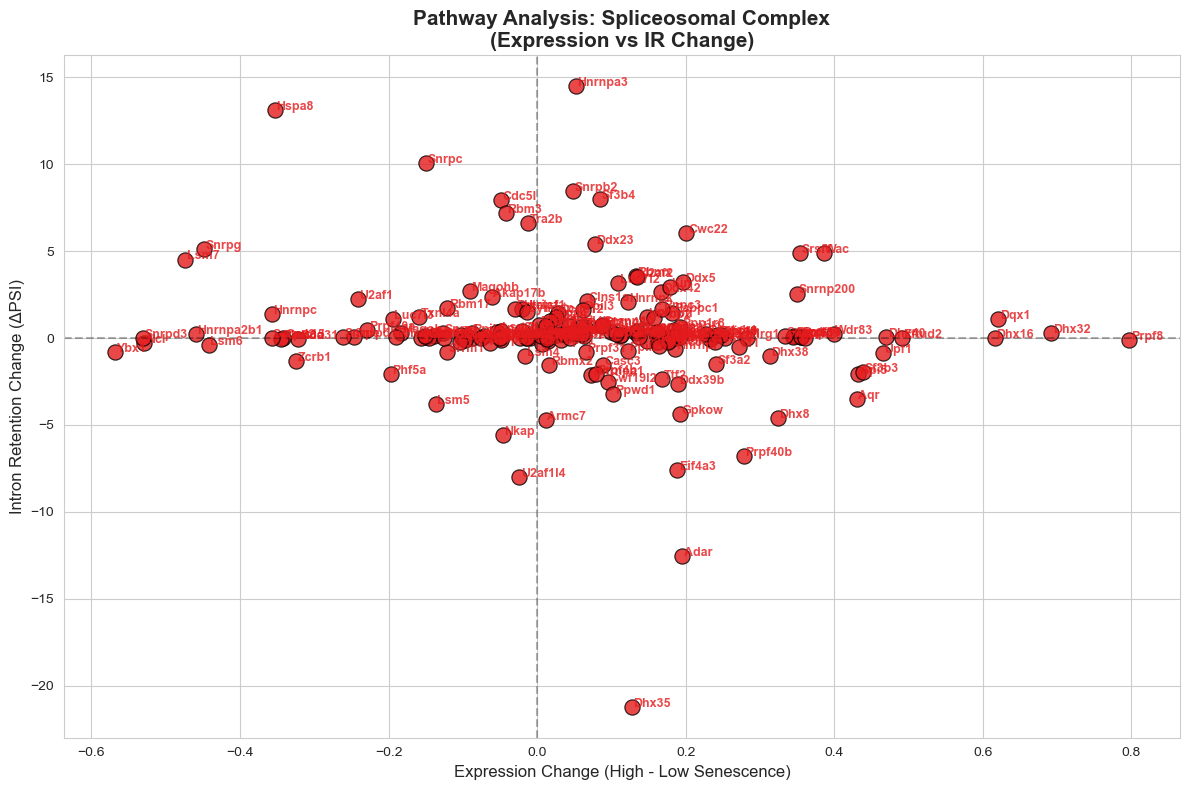

Plotted 181 genes for Spliceosomal Complex.


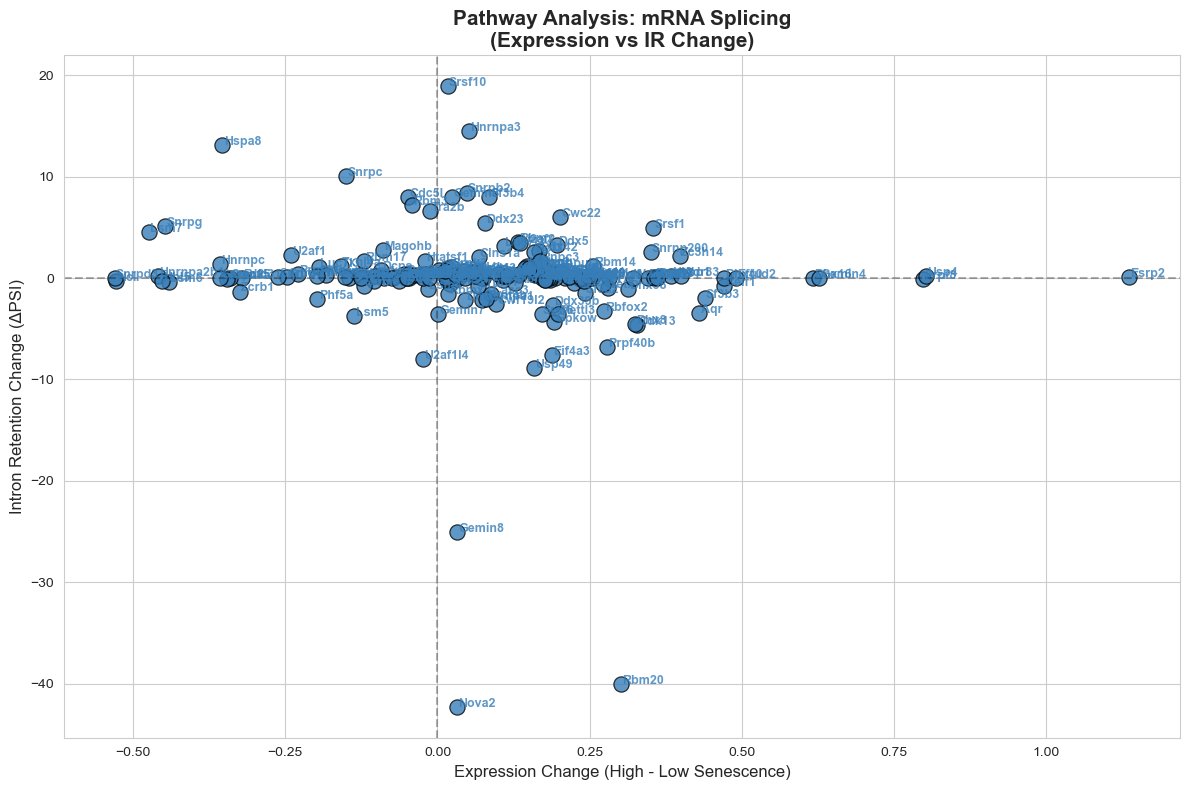

Plotted 182 genes for mRNA Splicing.


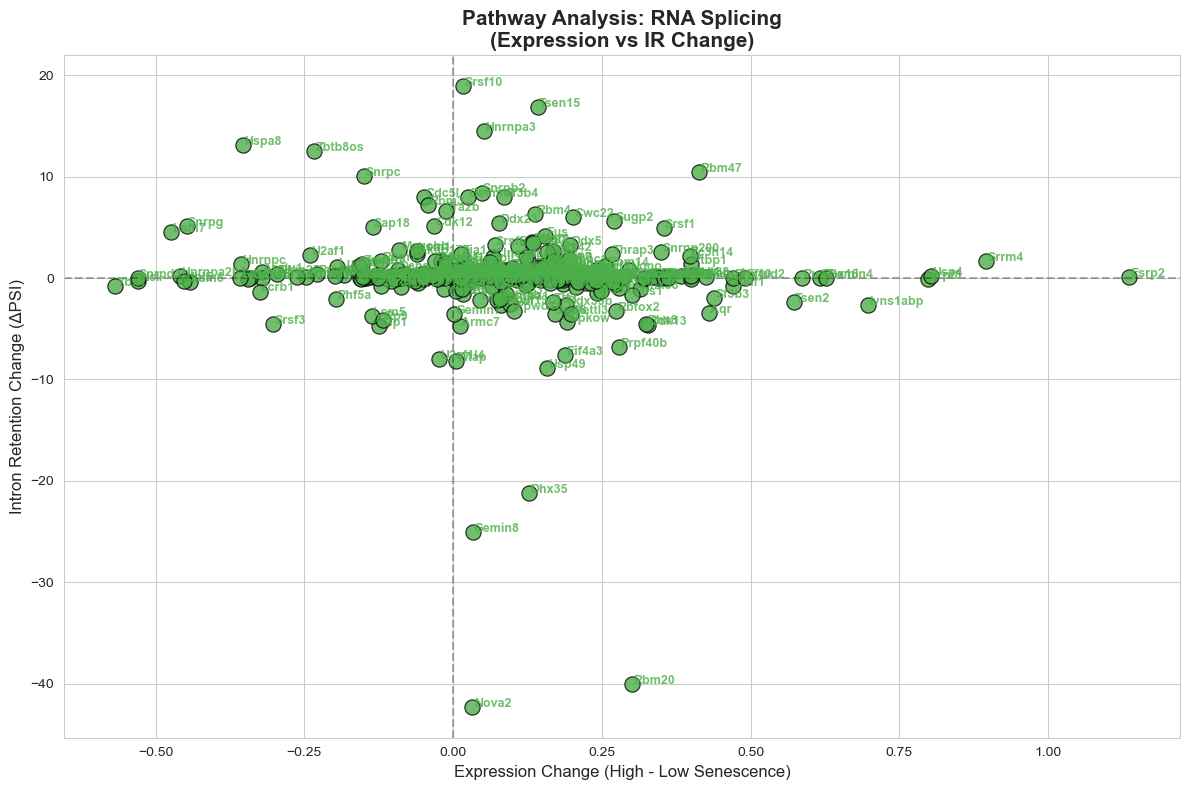

Plotted 295 genes for RNA Splicing.


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD DATA
print("Loading datasets...")
adata = sc.read_h5ad('Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad')
ir_df = pd.read_csv('INCLUSION_LEVELS_Full-mm10-2.tab', sep='\t')

# 2. LOAD GENES FROM THE THREE TEXT FILES
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

def load_gene_list(path):
    try:
        df = pd.read_csv(path, header=0, names=['gene_symbol'])
        return set(df['gene_symbol'].dropna().astype(str).str.strip().str.capitalize())
    except FileNotFoundError:
        print(f"Warning: File not found at {path}")
        return set()

gene_sets = {name: load_gene_list(path) for name, path in paths.items()}

# 3. CALCULATE EXPRESSION CHANGE
if 'mouse_gene_symbols' in adata.var.columns:
    adata.var_names = adata.var['mouse_gene_symbols'].str.capitalize()
else:
    adata.var_names = adata.var_names.str.capitalize()

high_cells = adata[adata.obs['senescence_group'] == 'High_Senescence']
low_cells = adata[adata.obs['senescence_group'] == 'Low_Senescence']

exp_high = np.array(high_cells.X.mean(axis=0)).flatten()
exp_low = np.array(low_cells.X.mean(axis=0)).flatten()

expression_df = pd.DataFrame({
    'Gene': adata.var_names,
    'Exp_Change': exp_high - exp_low
}).set_index('Gene')

# 4. CALCULATE IR CHANGE (VAST-TOOLS)
def get_mean_psi(value):
    if pd.isna(value) or value == 'NA': return np.nan
    try:
        nums = [float(x) for x in str(value).split(',') if x != 'NA']
        return np.mean(nums) if nums else np.nan
    except: return np.nan

ir_df['GENE'] = ir_df['GENE'].str.capitalize()
ir_df['PSI_High'] = ir_df['High_Senescence'].apply(get_mean_psi)
ir_df['PSI_Low'] = ir_df['Low_Senescence'].apply(get_mean_psi)

ir_summary = ir_df.groupby('GENE')[['PSI_High', 'PSI_Low']].mean()
ir_summary['IR_Change'] = ir_summary['PSI_High'] - ir_summary['PSI_Low']

# 5. MERGE DATA
full_merged = expression_df.merge(ir_summary, left_index=True, right_index=True).dropna()

# 6. VISUALIZATION LOOP (One plot per file)
palette = {
    'Spliceosomal Complex': '#e41a1c', # Red
    'mRNA Splicing': '#377eb8',        # Blue
    'RNA Splicing': '#4daf4a'          # Green
}

for category, gene_list in gene_sets.items():
    # Filter for the specific category
    subset = full_merged[full_merged.index.isin(gene_list)].copy()
    
    if len(subset) == 0:
        print(f"Skipping {category}: No matching genes found.")
        continue

    plt.figure(figsize=(12, 8))
    sns.set_style("whitegrid")

    # Plot
    sns.scatterplot(
        data=subset, x='Exp_Change', y='IR_Change', 
        color=palette[category], s=120, edgecolor='black', alpha=0.8
    )

    # Label genes
    for gene, row in subset.iterrows():
        plt.text(
            x=row['Exp_Change'] + 0.002, 
            y=row['IR_Change'] + 0.002, 
            s=gene, 
            fontsize=9, 
            color=palette[category], 
            fontweight='bold',
            alpha=0.8
        )

    # Add reference lines
    plt.axhline(0, color='black', linestyle='--', alpha=0.3)
    plt.axvline(0, color='black', linestyle='--', alpha=0.3)
    
    # Custom Labels for individual plot
    plt.title(f"Pathway Analysis: {category}\n(Expression vs IR Change)", fontweight='bold', fontsize=15)
    plt.xlabel("Expression Change (High - Low Senescence)", fontsize=12)
    plt.ylabel("Intron Retention Change (ΔPSI)", fontsize=12)
    
    plt.tight_layout()
    plt.show()

    print(f"Plotted {len(subset)} genes for {category}.")

---

1ST QUADRANT RIBOSOME GENES

Loading datasets...

Found 55 genes in the 2nd Quadrant starting with 'R'.
        Exp_Change  IR_Change
Rpsa     -0.025067  29.167500
Rpl27    -0.591909  26.790000
Rps16    -0.378097  26.669333
Rplp2    -0.539691  25.825000
Rps7     -0.307886  22.235556
Rpl12    -0.307845  20.044667
Rpl6     -0.229572  19.977167
Rpl23a   -0.284253  17.942206
Rpl5     -0.129778  16.673333
Rps10    -0.230667  16.667500


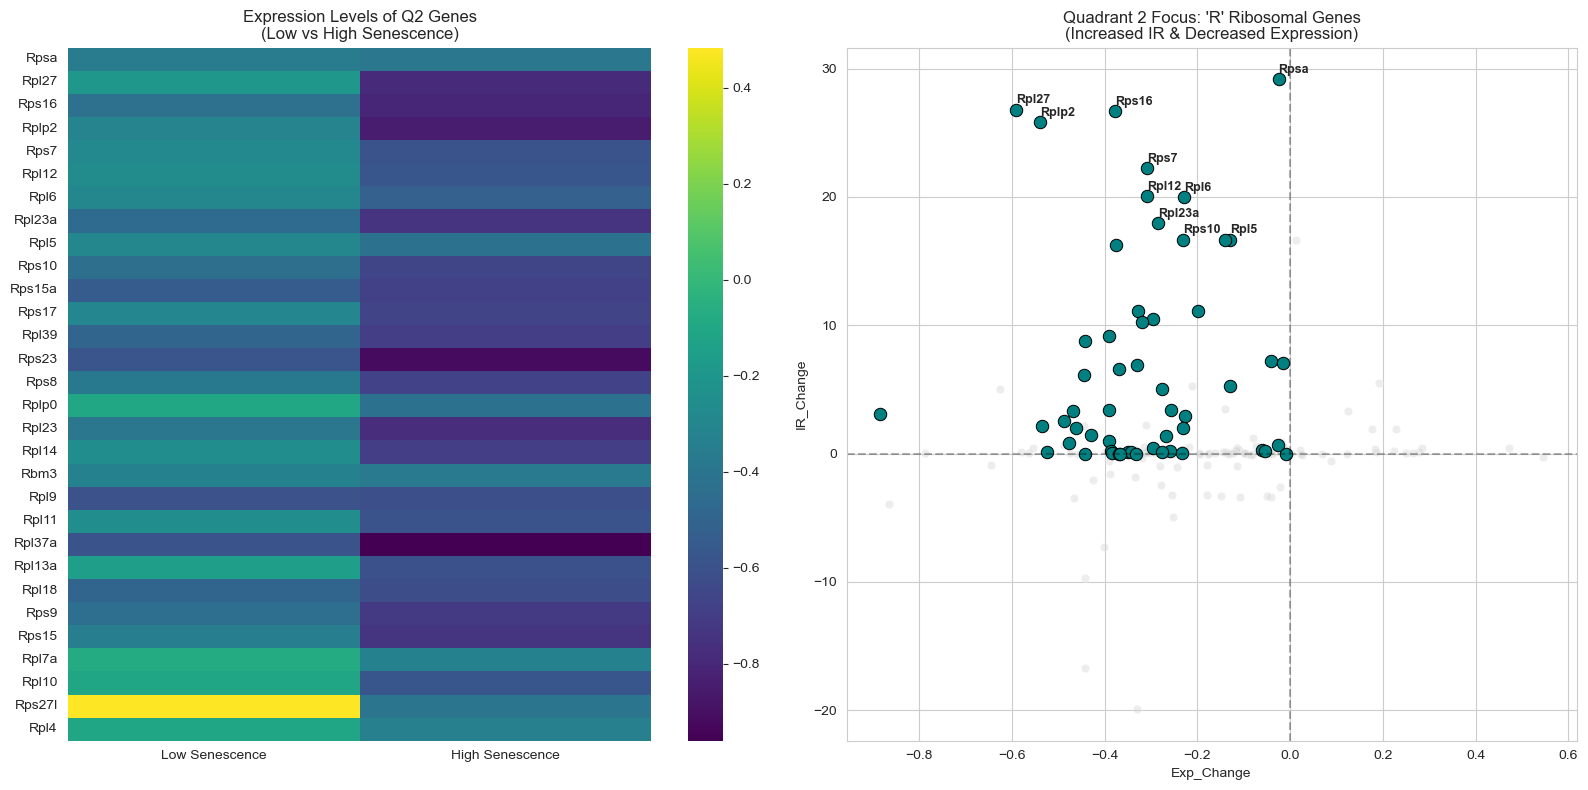

Full list saved to Investigation_Q2_Ribosomal_Genes.csv


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD DATA
print("Loading datasets...")
adata = sc.read_h5ad('Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad')
ir_df = pd.read_csv('INCLUSION_LEVELS_Full-mm10-2.tab', sep='\t')

def load_gene_list(path):
    try:
        df = pd.read_csv(path, header=0, names=['gene_symbol'])
        return set(df['gene_symbol'].dropna().astype(str).str.strip().str.capitalize())
    except FileNotFoundError:
        print(f"Warning: File not found at {path}")
        return set()

cytoplasmic_genes = load_gene_list('Ribosomal subunits.txt')
mitochondrial_genes = load_gene_list('MT Ribosomal subunits.txt')

# 2. CALCULATE EXPRESSION CHANGE
if 'mouse_gene_symbols' in adata.var.columns:
    adata.var_names = adata.var['mouse_gene_symbols'].str.capitalize()
else:
    adata.var_names = adata.var_names.str.capitalize()

# Calculate means for the two groups
high_cells = adata[adata.obs['senescence_group'] == 'High_Senescence']
low_cells = adata[adata.obs['senescence_group'] == 'Low_Senescence']

exp_high = np.array(high_cells.X.mean(axis=0)).flatten()
exp_low = np.array(low_cells.X.mean(axis=0)).flatten()

expression_df = pd.DataFrame({
    'Gene': adata.var_names,
    'Mean_Exp_Low': exp_low,
    'Mean_Exp_High': exp_high,
    'Exp_Change': exp_high - exp_low
}).set_index('Gene')

# 3. CALCULATE IR CHANGE (VAST-TOOLS)
def get_mean_psi(value):
    if pd.isna(value) or value == 'NA': return np.nan
    try:
        nums = [float(x) for x in str(value).split(',') if x != 'NA']
        return np.mean(nums) if nums else np.nan
    except: return np.nan

ir_df['GENE'] = ir_df['GENE'].str.capitalize()
# Use your column indices (6 and 8) for PSI values
col_high = ir_df.columns[6]
col_low = ir_df.columns[8]

ir_df['PSI_High'] = ir_df[col_high].apply(get_mean_psi)
ir_df['PSI_Low'] = ir_df[col_low].apply(get_mean_psi)

ir_summary = ir_df.groupby('GENE')[['PSI_High', 'PSI_Low']].mean()
ir_summary['IR_Change'] = ir_summary['PSI_High'] - ir_summary['PSI_Low']

# 4. MERGE AND TAG
full_merged = expression_df.merge(ir_summary, left_index=True, right_index=True).dropna()

full_merged['Subunit_Type'] = 'Other'
full_merged.loc[full_merged.index.isin(cytoplasmic_genes), 'Subunit_Type'] = 'Cytoplasmic'
full_merged.loc[full_merged.index.isin(mitochondrial_genes), 'Subunit_Type'] = 'Mitochondrial'
combined_rp_df = full_merged[full_merged['Subunit_Type'] != 'Other'].copy()

# 5. ISOLATE 2ND QUADRANT GENES STARTING WITH 'R'
# Quadrant 2: Exp_Change < 0 (Decrease) AND IR_Change > 0 (Increase)
q2_r_genes = combined_rp_df[
    (combined_rp_df['Exp_Change'] < 0) & 
    (combined_rp_df['IR_Change'] > 0) & 
    (combined_rp_df.index.str.startswith('R'))
].copy()

# Sort by most significant IR change
q2_r_genes = q2_r_genes.sort_values('IR_Change', ascending=False)

print(f"\nFound {len(q2_r_genes)} genes in the 2nd Quadrant starting with 'R'.")
print(q2_r_genes[['Exp_Change', 'IR_Change']].head(10))

# 6. INVESTIGATION VISUALIZATION
if not q2_r_genes.empty:
    fig, ax = plt.subplots(1, 2, figsize=(16, 8))

    # --- Plot 1: Heatmap of Expression ---
    # Top 30 genes if the list is long
    plot_data = q2_r_genes[['Mean_Exp_Low', 'Mean_Exp_High']].head(30)
    sns.heatmap(plot_data, cmap='viridis', annot=False, ax=ax[0])
    ax[0].set_title("Expression Levels of Q2 Genes\n(Low vs High Senescence)")
    ax[0].set_xticklabels(['Low Senescence', 'High Senescence'])

    # --- Plot 2: Scatter plot highlighting just these genes ---
    sns.scatterplot(data=combined_rp_df, x='Exp_Change', y='IR_Change', color='lightgrey', alpha=0.4, ax=ax[1])
    sns.scatterplot(data=q2_r_genes, x='Exp_Change', y='IR_Change', color='teal', edgecolor='black', s=80, ax=ax[1])
    
    # Label top 10 genes by IR change
    for i, (gene, row) in enumerate(q2_r_genes.head(10).iterrows()):
        ax[1].text(row['Exp_Change'], row['IR_Change']+0.5, gene, fontsize=9, fontweight='bold')

    ax[1].axhline(0, color='black', linestyle='--', alpha=0.3)
    ax[1].axvline(0, color='black', linestyle='--', alpha=0.3)
    ax[1].set_title("Quadrant 2 Focus: 'R' Ribosomal Genes\n(Increased IR & Decreased Expression)")

    plt.tight_layout()
    plt.show()

    # 7. EXPORT
    q2_r_genes.to_csv("Investigation_Q2_Ribosomal_Genes.csv")
    print("Full list saved to Investigation_Q2_Ribosomal_Genes.csv")
else:
    print("No genes found matching the criteria.")

---

GSEA ANALYSIS - Standard 3-way

In [ ]:
import scanpy as sc
h5ad_path="Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad"
adata = sc.read_h5ad(h5ad_path)
adata

AnnData object with n_obs × n_vars = 519 × 19559
    obs: 'FACS.selection', 'age', 'cell', 'cell_ontology_class', 'cell_ontology_id', 'free_annotation', 'method', 'mouse.id', 'sex', 'subtissue', 'tissue', 'n_genes', 'n_counts', 'louvain', 'leiden', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'age_sex', 'doublet_score', 'predicted_doublet', 'leiden_0.5', 'leiden_0.75', 'leiden_1.0', 'cell_type', 'celltypist_predicted_labels', 'SenMayo_score', 'CellAge_up_score', 'HernandezSegura_enriched_score', 'HernandezSegura_depleted_score', 'senescence_group'
    var: 'n_cells', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mean', 'std

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import gseapy as gp
import requests
import re

# 1. LOAD DATA
print("Loading AnnData...")
adata = sc.read_h5ad('Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad')

# 2. PREPARE GENE NAMES (UPPERCASE)
adata.var_names = adata.var['mouse_gene_symbols'].astype(str).str.upper()
adata = adata[:, ~adata.var_names.duplicated()].copy()

# 3. RUN DIFFERENTIAL EXPRESSION
print("Running Differential Expression...")
sc.tl.rank_genes_groups(adata, groupby='senescence_group', groups=['High_Senescence'], 
                        reference='Low_Senescence', method='wilcoxon')
results_df = sc.get.rank_genes_groups_df(adata, group="High_Senescence")

# 4. PREPARE RANKED LIST (WITH JITTER)
print("Preparing unique rankings...")
# Metric: logFC * -log10(adj p-val)
results_df['rank_metric'] = results_df['logfoldchanges'] * -np.log10(results_df['pvals_adj'] + 1e-300)

# Jitter to break ties (prevents the "duplicated values" warning)
np.random.seed(42)
results_df['rank_metric'] += np.random.normal(0, 1e-9, len(results_df))

ranked_list = results_df.set_index('names')['rank_metric'].sort_values(ascending=False)
ranked_list = ranked_list.replace([np.inf, -np.inf], np.nan).dropna()

# 5. MANUAL DOWNLOADER (FIXES TYPEERROR)
def fetch_enrichr_gmt(library_name):
    print(f"  Downloading {library_name} via direct API...")
    url = f"https://maayanlab.cloud/Enrichr/geneSetLibrary?mode=text&libraryName={library_name}"
    response = requests.get(url)
    if response.status_code != 200:
        raise Exception(f"Could not fetch {library_name}")
    
    gmt_dict = {}
    for line in response.text.strip().split('\n'):
        parts = line.split('\t')
        pathway_name = parts[0]
        genes = [g.split(',')[0].upper() for g in parts[2:] if g]
        gmt_dict[pathway_name] = genes
    return gmt_dict

# 6. FETCH LIBRARIES (GO 3-WAY ONLY)
libraries = ["GO_Biological_Process_2023", "GO_Molecular_Function_2023", "GO_Cellular_Component_2023"]
combined_gmt = {}

for lib in libraries:
    try:
        lib_data = fetch_enrichr_gmt(lib)
        # Use prefix to keep track of which GO branch is which
        prefix = "BP" if "Biological" in lib else "MF" if "Molecular" in lib else "CC"
        combined_gmt.update({f"[{prefix}] {k}": v for k, v in lib_data.items()})
        print(f"    Loaded {len(lib_data)} pathways from {lib}")
    except Exception as e:
        print(f"    Failed to load {lib}: {e}")

# 7. RUN GSEA
print(f"--- Running GSEA Analysis with {len(combined_gmt)} pathways ---")
pre_res = gp.prerank(
    rnk=ranked_list,
    gene_sets=combined_gmt,
    outdir=None, 
    min_size=10, # Capture smaller, specific complexes
    max_size=500,
    seed=42
)

# 8. RESULTS - MORE PERMISSIVE FILTERING
res = pre_res.res2d

# Loosened NES to 1.0 and kept FDR at 0.25 to show more results
sig_res = res[(abs(res['NES']) >= 1.0) & (res['FDR q-val'] < 0.25)]

print("\n" + "="*90)
print(f"{'SIGNIFICANT 3-WAY GO PATHWAYS (FDR < 0.25)':^90}")
print("="*90)

if sig_res.empty:
    print("No pathways met the threshold even with loosened parameters.")
else:
    # Sort by NES so the strongest results are at the top
    sig_res = sig_res.sort_values('NES', ascending=False)
    for index, row in sig_res.iterrows():
        nes = row['NES']
        direction = "[UP IN HIGH]" if nes > 0 else "[DOWN IN HIGH]"
        term = row['Term']
        
        # The term already has the [BP], [MF], or [CC] prefix from Step 6
        clean_name = re.sub(r' \(GO:\d+\)', '', term)
        
        print(f"{direction} {clean_name[:75].ljust(75)} (NES: {nes:.2f})")

# 9. TARGETED SPLICING / RIBOSOME CHECK
print("\n" + "="*90)
print(f"{'TARGETED CHECK: SPLICING & RIBONUCLEOPROTEIN':^90}")
print("="*90)
targets = res[res['Term'].str.contains('SPLICING|SPLICEOSOME|RNA_BINDING|RIBONUCLEOPROTEIN', case=False)]
if not targets.empty:
    print(targets.sort_values('NES', ascending=False)[['Term', 'NES', 'FDR q-val']].head(15).to_string(index=False))

print("\n--- Analysis Complete ---")

Loading AnnData...
Running Differential Expression...
Preparing unique rankings...


c:\Users\lukas\miniconda3\envs\sc_env\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:479: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
c:\Users\lukas\miniconda3\envs\sc_env\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:480: RuntimeWarning: overflow encountered in expm1
  self.expm1_func(mean_rest) + 1e-9
c:\Users\lukas\miniconda3\envs\sc_env\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:479: RuntimeWarning: invalid value encountered in divide
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
c:\Users\lukas\miniconda3\envs\sc_env\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:482: RuntimeWarning: divide by zero encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(


    Loaded 5407 pathways from GO_Biological_Process_2023
    Loaded 1147 pathways from GO_Molecular_Function_2023
    Loaded 474 pathways from GO_Cellular_Component_2023
--- Running GSEA Analysis with 7028 pathways ---

                        SIGNIFICANT 3-WAY GO PATHWAYS (FDR < 0.25)                        
[UP IN HIGH] [BP] Positive Regulation Of Synapse Assembly                                (NES: 1.33)
[UP IN HIGH] [MF] Wide Pore Channel Activity                                             (NES: 1.32)
[UP IN HIGH] [MF] Gap Junction Channel Activity                                          (NES: 1.31)
[UP IN HIGH] [MF] Excitatory Extracellular Ligand-Gated Monoatomic Ion Channel Activity  (NES: 1.31)
[UP IN HIGH] [CC] Connexin Complex                                                       (NES: 1.31)
[DOWN IN HIGH] [CC] Mitochondrial Ribosome                                                 (NES: -1.72)

                       TARGETED CHECK: SPLICING & RIBONUCLEOPROTEIN            

What is ORA?
ORA is a statistical method (usually based on the Hypergeometric Test or Fisher’s Exact Test) that asks a simple question:
"Is the proportion of 'High IR' genes in Pathway X significantly higher than the proportion of 'High IR' genes in the entire genome?"
How it works in your script:
The Hit List: You take a "hit list" of genes that pass a specific threshold (e.g., dPSI > 5).
The Universe (Background): You define a "background" of all genes where Intron Retention (IR) was actually detectable.
The Overlap: The code counts how many genes from your "Hit List" are in "Pathway A" and compares that to how many genes from the "Universe" are in "Pathway A."
The Result: If 10% of your Hit List is in the "RNA Splicing" pathway, but only 1% of the Universe is in that pathway, you get a significant p-value.


GSEA would ignore your 5% threshold and try to rank every gene from the highest ΔPSI to the lowest. While that is also a valid analysis, it wouldn't tell you what is unique about the genes that passed your specific 5% "failure" mark.

In [ ]:
import scanpy as sc
import gseapy as gp
import pandas as pd
import numpy as np
import requests
import re

# --- HELPER: MANUAL GMT DOWNLOAD (Prevents TypeError and KeyError) ---
def fetch_enrichr_gmt(library_name):
    print(f"  Downloading {library_name}...")
    url = f"https://maayanlab.cloud/Enrichr/geneSetLibrary?mode=text&libraryName={library_name}"
    response = requests.get(url)
    if response.status_code != 200: raise Exception(f"Could not fetch {library_name}")
    gmt_dict = {}
    for line in response.text.strip().split('\n'):
        parts = line.split('\t')
        # Pathway Name: [Genes]
        gmt_dict[parts[0]] = [g.split(',')[0].upper() for g in parts[2:] if g]
    return gmt_dict

# 1. LOAD DATA
vast_file = "INCLUSION_LEVELS_FULL-mm10-2.tab"
print(f"Loading VAST-TOOLS file: {vast_file}...")
df_full = pd.read_csv(vast_file, sep='\t')
df_full['GENE'] = df_full['GENE'].str.upper()

# 2. FILTER FOR INTRON RETENTION (INT)
df_ir = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()

# 3. CALCULATE PSI DIFFERENCE
def get_mean_psi(value):
    if pd.isna(value) or value == 'NA': return np.nan
    try:
        nums = [float(x) for x in str(value).split(',') if x != 'NA']
        return np.mean(nums) if nums else np.nan
    except: return np.nan

df_ir['PSI_High'] = df_ir['High_Senescence'].apply(get_mean_psi)
df_ir['PSI_Low'] = df_ir['Low_Senescence'].apply(get_mean_psi)
df_ir = df_ir.dropna(subset=['PSI_High', 'PSI_Low'])
df_ir['dPSI'] = df_ir['PSI_High'] - df_ir['PSI_Low']

# One event per gene (the most increased one)
df_best = df_ir.sort_values('dPSI', ascending=False).drop_duplicates('GENE')

# 4. DEFINE UNIVERSE AND SUBSETS
background_genes = df_best['GENE'].unique().tolist()
high_ir_genes = df_best[df_best['dPSI'] > 5]['GENE'].tolist()
low_ir_genes = df_best[df_best['dPSI'] <= 5]['GENE'].tolist()

print(f"Universe: {len(background_genes)} | High IR (>5%): {len(high_ir_genes)} | Stable (<=5%): {len(low_ir_genes)}")

# 5. FETCH 3-WAY GO LIBRARIES
libraries = ["GO_Biological_Process_2023", "GO_Molecular_Function_2023", "GO_Cellular_Component_2023"]
combined_gmt = {}
for lib in libraries:
    try:
        data = fetch_enrichr_gmt(lib)
        # Prefix the term with the library type for clarity
        prefix = "BP" if "Biological" in lib else "MF" if "Molecular" in lib else "CC"
        combined_gmt.update({f"[{prefix}] {k}": v for k, v in data.items()})
    except:
        print(f"  Warning: Failed to load {lib}")

# 6. RUN LOCAL ORA (gp.enrich is more stable than gp.enrichr)
def run_ora_local(gene_list, label, background, gmt):
    if len(gene_list) < 5: return None
    print(f"Running Enrichment for {label}...")
    # Use the local enrich function
    enr = gp.enrich(gene_list=gene_list,
                    gene_sets=gmt,
                    background=background,
                    outdir=None,
                    verbose=False)
    res = enr.results
    # Filter for significance
    return res[res['Adjusted P-value'] < 0.05].copy()

res_high = run_ora_local(high_ir_genes, "High IR Increase (>5%)", background_genes, combined_gmt)
res_low = run_ora_local(low_ir_genes, "Low/Stable IR (<=5%)", background_genes, combined_gmt)

# 7. SAFE PRINTING FUNCTION (Fixes KeyError)
def print_top_terms(df, title):
    print("\n" + "="*100)
    print(f"{title:^100}")
    print("="*100)
    
    if df is not None and not df.empty:
        # Sort by significance
        df = df.sort_values('Adjusted P-value')
        
        # Check which columns actually exist to avoid KeyError
        cols_to_show = ['Term', 'Adjusted P-value']
        if 'Overlap' in df.columns:
            cols_to_show.append('Overlap')
        elif 'Hits' in df.columns: # Sometimes named Hits in local mode
            cols_to_show.append('Hits')
            
        print(df.head(15)[cols_to_show].to_string(index=False))
    else:
        print("No significant pathways found (Adj. P < 0.05).")

print_top_terms(res_high, "PATHWAYS AFFECTED BY INCREASED INTRON RETENTION (>5% dPSI)")
print_top_terms(res_low, "PATHWAYS WITH STABLE SPLICING (<=5% dPSI)")

# 8. SAVE
df_best.to_csv("Whole_Genome_IR_Subsets_with_ORA.csv", index=False)
print(f"\nResults saved to Whole_Genome_IR_Subsets_with_ORA.csv")


Loading VAST-TOOLS file: INCLUSION_LEVELS_FULL-mm10-2.tab...
Universe: 11740 | High IR (>5%): 3016 | Stable (<=5%): 8724
Running Enrichment for High IR Increase (>5%)...
Running Enrichment for Low/Stable IR (<=5%)...

                     PATHWAYS AFFECTED BY INCREASED INTRON RETENTION (>5% dPSI)                     
                                                                                             Term  Adjusted P-value   Overlap
                               [BP] Regulation Of Transcription By RNA Polymerase II (GO:0006357)      6.302391e-17   381/989
                                      [BP] Regulation Of DNA-templated Transcription (GO:0006355)      7.241324e-17   371/961
                                                                        [CC] Nucleus (GO:0005634)      3.050063e-15  904/2821
                                       [CC] Intracellular Membrane-Bounded Organelle (GO:0043231)      1.126546e-13 1012/3249
                             [BP] Negative Regulati

---

THIS PART IS FOR THE OLD HEPATOCYTES SCORED BY CELLAGE

In [ ]:
import pandas as pd
import numpy as np
import glob

# 1. LOAD DATA
full_file = "INCLUSION_LEVELS_FULL-mm10-2_cellage.tab"
diff_files = glob.glob("DiffAS-mm10-2*.tab")
diff_file = diff_files[0]

df_full = pd.read_csv(full_file, sep='\t')
df_diff = pd.read_csv(diff_file, sep='\t')

# 2. FILTER FOR INTRONS (Using MmuINT and IR labels)
# We look for 'INT' in the EVENT ID which matches your data
ir_full = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()
ir_diff = df_diff[df_diff['EVENT'].str.contains('INT', na=False)].copy()

samples = ['High_CellAge', 'Low_CellAge']

# 3. CLEAN & CALCULATE
for s in samples:
    ir_full[s] = pd.to_numeric(ir_full[s], errors='coerce')
    ir_diff[s] = pd.to_numeric(ir_diff[s], errors='coerce')

ir_full = ir_full.dropna(subset=samples)
ir_diff = ir_diff.dropna(subset=samples)
ir_diff['dPSI'] = ir_diff['High_CellAge'] - ir_diff['Low_CellAge']

# 4. FINAL REPORT
print("="*65)
print(f"{'FINAL SENESCENCE INTRON RETENTION REPORT':^65}")
print("="*65)

print(f"\n[GLOBAL IR BURDEN]")
print(f"  Total Introns Measured:          {len(ir_full)}")
print(f"  High Senescence Avg Retention:   {ir_full['High_CellAge'].mean():.2f}%")
print(f"  Low Senescence Avg Retention:    {ir_full['Low_CellAge'].mean():.2f}%")
print(f"  GLOBAL IR SHIFT (H - L):         {ir_full['High_CellAge'].mean() - ir_full['Low_CellAge'].mean():+.2f}%")

print(f"\n[SIGNIFICANT IR EVENTS (|dPSI| > 15)]")
inc = (ir_diff['dPSI'] > 0).sum()
dec = (ir_diff['dPSI'] < 0).sum()
print(f"  Total Sig. Changes:              {len(ir_diff)}")
print(f"  Increased in High Senescence:    {inc}")
print(f"  Decreased in High Senescence:    {dec}")

print(f"\n[TOP 10 GENES WITH INCREASED INTRON RETENTION]")
top_10 = ir_diff.sort_values(by='dPSI', ascending=False).head(10)
print(f"{'GENE':<15} | {'PSI High':<10} | {'PSI Low':<10} | {'dPSI (%)'}")
print("-" * 65)
for _, row in top_10.iterrows():
    print(f"{row['GENE']:<15} | {row['High_CellAge']:>8.1f}% | {row['Low_CellAge']:>8.1f}% | {row['dPSI']:>+8.1f}%")

            FINAL SENESCENCE INTRON RETENTION REPORT             

[GLOBAL IR BURDEN]
  Total Introns Measured:          96678
  High Senescence Avg Retention:   3.92%
  Low Senescence Avg Retention:    4.57%
  GLOBAL IR SHIFT (H - L):         -0.65%

[SIGNIFICANT IR EVENTS (|dPSI| > 15)]
  Total Sig. Changes:              1589
  Increased in High Senescence:    727
  Decreased in High Senescence:    862

[TOP 10 GENES WITH INCREASED INTRON RETENTION]
GENE            | PSI High   | PSI Low    | dPSI (%)
-----------------------------------------------------------------
Kif20a          |    100.0% |      0.0% |   +100.0%
Abcc4           |    100.0% |      0.0% |   +100.0%
Emilin2         |    100.0% |      0.0% |   +100.0%
Ska3            |    100.0% |      0.0% |   +100.0%
Kif20a          |    100.0% |      0.0% |   +100.0%
Gm6297          |     98.4% |      0.0% |    +98.4%
Tmem132a        |     98.2% |      0.0% |    +98.2%
Vps8            |     97.4% |      0.0% |    +97.4%
Usp32    

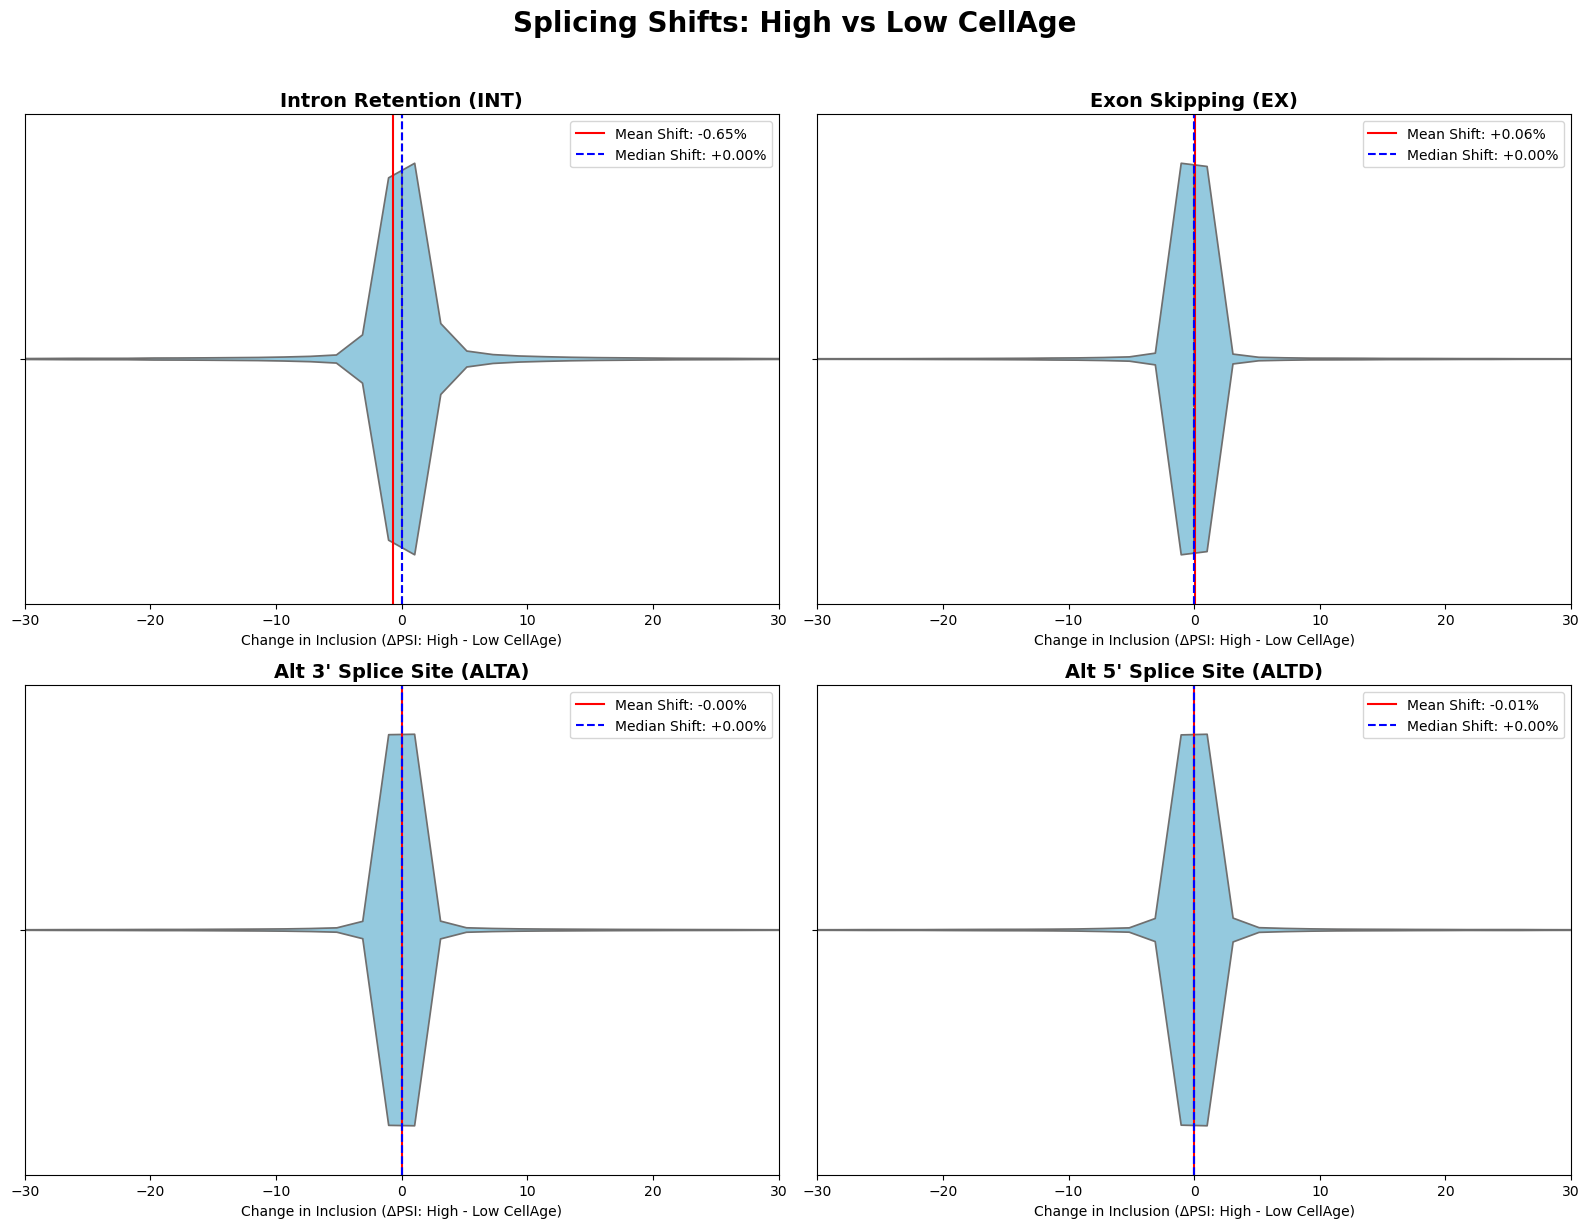

Event Type           | Total    | Mean       | Median    
---------------------------------------------------------------------------
Intron Retention     | 96678    |     -0.65% |     +0.00%
Exon Skipping        | 100167   |     +0.06% |     +0.00%
Alt 3' Splice Site   | 87167    |     -0.00% |     +0.00%
Alt 5' Splice Site   | 63373    |     -0.01% |     +0.00%


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD AND CLEAN DATA
file_path = "INCLUSION_LEVELS_FULL-mm10-2_cellage.tab"
df_full = pd.read_csv(file_path, sep='\t')

# Ensure columns are numeric
cols = ['High_CellAge', 'Low_CellAge']
df_full[cols] = df_full[cols].apply(pd.to_numeric, errors='coerce')
df_full = df_full.dropna(subset=cols)

# Calculate dPSI (Delta Percent Spliced In)
df_full['dPSI'] = df_full['High_CellAge'] - df_full['Low_CellAge']

# 2. DEFINE EVENT TYPES
event_map = {
    'INT': 'Intron Retention',
    'EX': 'Exon Skipping',
    'ALTA': 'Alt 3\' Splice Site',
    'ALTD': 'Alt 5\' Splice Site'
}

# 3. LOOP AND PLOT
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (code, label) in enumerate(event_map.items()):
    # Filter for the specific event type
    subset = df_full[df_full['EVENT'].str.contains(code, na=False)].copy()
    
    if len(subset) == 0: 
        axes[i].set_title(f'{label} ({code})\nNo Data Found', fontsize=14)
        continue
        
    # CALCULATIONS
    mean_shift = subset['dPSI'].mean()
    median_shift = subset['dPSI'].median()  # <--- Added Median Calculation
    
    up = (subset['dPSI'] > 0).sum()
    down = (subset['dPSI'] < 0).sum()
    ratio = up/down if down > 0 else np.inf
    
    # Plotting
    sns.violinplot(x=subset['dPSI'], ax=axes[i], color="skyblue", inner="quartile")
    
    # Vertical Lines
    axes[i].axvline(0, color='black', linestyle='--', alpha=0.6)
    axes[i].axvline(mean_shift, color='red', linestyle='-', label=f'Mean Shift: {mean_shift:+.2f}%')
    axes[i].axvline(median_shift, color='blue', linestyle='--', label=f'Median Shift: {median_shift:+.2f}%') # <--- Added Line
    
    axes[i].set_title(f'{label} ({code})', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Change in Inclusion (ΔPSI: High - Low CellAge)')
    axes[i].set_xlim(-30, 30) 
    axes[i].legend()

plt.suptitle('Splicing Shifts: High vs Low CellAge', fontsize=20, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 4. PRINT COMPARISON SUMMARY
print(f"{'Event Type':<20} | {'Total':<8} | {'Mean':<10} | {'Median':<10}")
print("-" * 75)
for code, label in event_map.items():
    subset = df_full[df_full['EVENT'].str.contains(code, na=False)]
    if len(subset) == 0: continue
    
    mean_s = subset['dPSI'].mean()
    median_s = subset['dPSI'].median() # <--- Added for table
    
    up = (subset['dPSI'] > 0).sum()
    down = (subset['dPSI'] < 0).sum()
    
    print(f"{label:<20} | {len(subset):<8} | {mean_s:>+9.2f}% | {median_s:>+9.2f}%")

NOW INSTEAD OF DELTA PSI, WE USE THE ODS RATIO ESTIMATE

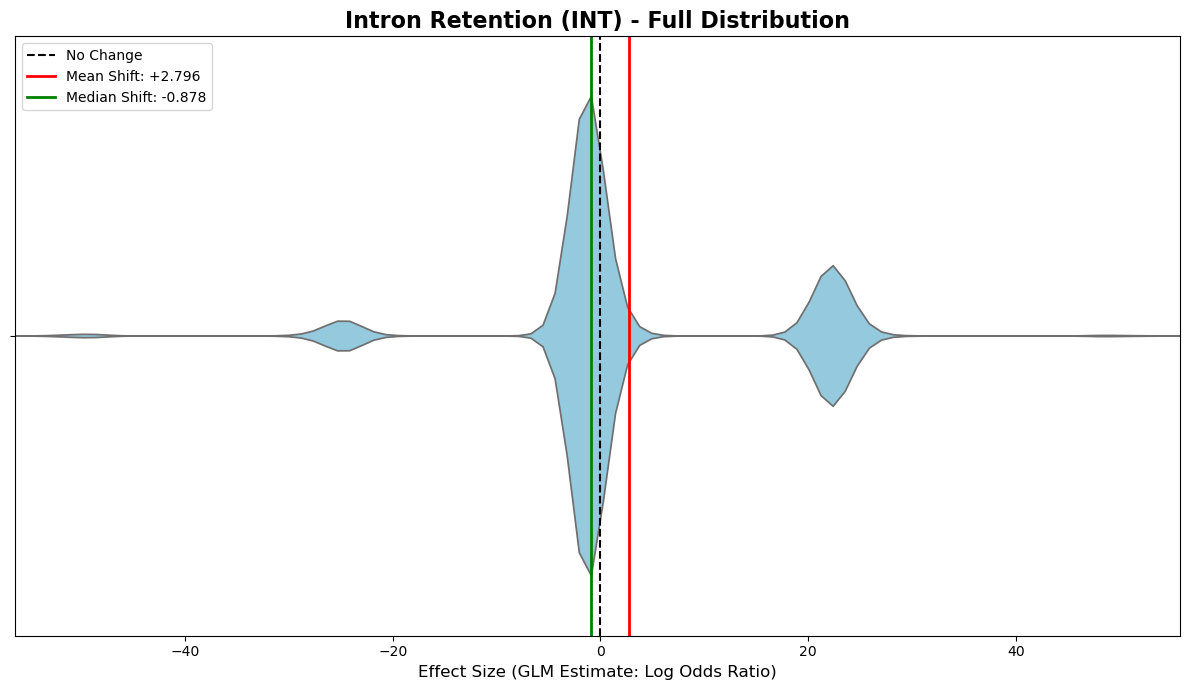

--- Data Range ---
Minimum LogOR: -55.403
Maximum LogOR: 54.824
Mean: 2.796
Median: -0.878


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
df_results = pd.read_csv("INCLUSION_LEVELS_FULL-mm10-2_cellage_GLM_RESULTS.csv")

# 2. Filter for Intron Retention only
subset = df_results[df_results['Event'].str.contains('INT')].copy()

# Handle potential infinite values
subset = subset[np.isfinite(subset['Estimate_LogOdds'])]

# 3. Calculate Statistics
mean_shift = subset['Estimate_LogOdds'].mean()
median_shift = subset['Estimate_LogOdds'].median()
min_val = subset['Estimate_LogOdds'].min()
max_val = subset['Estimate_LogOdds'].max()

# 4. Plotting
plt.figure(figsize=(12, 7))

# CHANGE: inner=None removes the internal quartile lines
sns.violinplot(x=subset['Estimate_LogOdds'], color="skyblue", inner=None)

# Add Vertical Lines
plt.axvline(0, color='black', linestyle='--', label='No Change')
plt.axvline(mean_shift, color='red', linestyle='-', linewidth=2, 
            label=f'Mean Shift: {mean_shift:+.3f}')
plt.axvline(median_shift, color='green', linestyle='-', linewidth=2, 
            label=f'Median Shift: {median_shift:+.3f}')

# Formatting
# UPDATED: Title simplified (ratio removed)
plt.title('Intron Retention (INT) - Full Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Effect Size (GLM Estimate: Log Odds Ratio)', fontsize=12)

# Shows full extent with a slight buffer
plt.xlim(min_val - 1, max_val + 1)

plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

# Print Summary to Console
print(f"--- Data Range ---")
print(f"Minimum LogOR: {min_val:.3f}")
print(f"Maximum LogOR: {max_val:.3f}")
print(f"Mean: {mean_shift:.3f}")
print(f"Median: {median_shift:.3f}")

In [ ]:
import pandas as pd
import numpy as np

# ==============================================================================
# 1. LOAD DATA
# ==============================================================================
# Updated filename to the CellAge dataset
full_file = "INCLUSION_LEVELS_FULL-mm10-2_cellage.tab"
print(f"Reading {full_file}...")
df_full = pd.read_csv(full_file, sep='\t')

# ==============================================================================
# 2. FILTER FOR INTRONS
# ==============================================================================
# Focus only on Intron Retention events
df_ir = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()

# ==============================================================================
# 3. CONVERT SAMPLES TO NUMERIC
# ==============================================================================
# Updated column names to match your new data
samples = ['High_CellAge', 'Low_CellAge']
for s in samples:
    df_ir[s] = pd.to_numeric(df_ir[s], errors='coerce')

# ==============================================================================
# 4. APPLY "PLATINUM" CONFIDENCE FILTERS
# ==============================================================================

# Filter A: Must have valid numeric measurements (drops rows with "N")
df_ir = df_ir.dropna(subset=samples)

# Filter B: Significant Threshold (|Delta PSI| > 5)
df_ir['dPSI'] = df_ir['High_CellAge'] - df_ir['Low_CellAge']
df_robust = df_ir[df_ir['dPSI'].abs() > 5].copy()

# Filter C: Quality Score Check (High Coverage Requirement)
def is_platinum_quality(q_string):
    """
    Ensures the measurement is backed by sufficient read coverage ('OK' or 'SOK').
    """
    if pd.isna(q_string): 
        return False
    q_str = str(q_string).upper()
    return q_str.startswith('OK') or q_str.startswith('SOK')

# Mapping quality checks to the new column names
mask_high = df_robust['High_CellAge-Q'].apply(is_platinum_quality)
mask_low = df_robust['Low_CellAge-Q'].apply(is_platinum_quality)

df_platinum = df_robust[mask_high & mask_low].copy()

# ==============================================================================
# 5. SORT AND REPORT
# ==============================================================================
# Sort by dPSI (highest increases in High_CellAge first)
df_platinum = df_platinum.sort_values(by='dPSI', ascending=False)

print("\n" + "="*75)
print(f"{'PLATINUM CONFIDENCE IR ANALYSIS (CELLAGE THRESHOLD > 5%)':^75}")
print("="*75)
print(f"Total Introns in Table:             {len(df_ir):,}")
print(f"Platinum Quality IR Events (>5%):   {len(df_platinum)}")
print(f"  - Significant Increases in High:  {len(df_platinum[df_platinum['dPSI'] > 0])}")
print(f"  - Significant Decreases in High:  {len(df_platinum[df_platinum['dPSI'] < 0])}")

print(f"\n[TOP 5 HIGH-CONFIDENCE HITS]")
print(f"{'GENE':<15} | {'dPSI':<10} | {'PSI (H/L)':<12} | {'QUALITY (H/L)'}")
print("-" * 75)

for _, row in df_platinum.head(5).iterrows():
    # Clean up quality string for display (takes just the first part before the comma)
    q_h = str(row['High_CellAge-Q']).split(',')[0]
    q_l = str(row['Low_CellAge-Q']).split(',')[0]
    psi_h = f"{row['High_CellAge']:.1f}"
    psi_l = f"{row['Low_CellAge']:.1f}"
    
    print(f"{row['GENE']:<15} | {row['dPSI']:>+7.1f}%   | {psi_h:>5}/{psi_l:<5} | {q_h}/{q_l}")

# Save results to a CSV for downstream analysis
output_name = "Platinum_Confidence_CellAge_IR_5pct.csv"
df_platinum.to_csv(output_name, index=False)
print(f"\nResults saved to: {output_name}")

Reading INCLUSION_LEVELS_FULL-mm10-2_cellage.tab...

         PLATINUM CONFIDENCE IR ANALYSIS (CELLAGE THRESHOLD > 5%)          
Total Introns in Table:             96,678
Platinum Quality IR Events (>5%):   2890
  - Significant Increases in High:  1507
  - Significant Decreases in High:  1383

[TOP 5 HIGH-CONFIDENCE HITS]
GENE            | dPSI       | PSI (H/L)    | QUALITY (H/L)
---------------------------------------------------------------------------
Ska3            |  +100.0%   | 100.0/0.0   | OK/OK
Emilin2         |  +100.0%   | 100.0/0.0   | OK/OK
Kif20a          |  +100.0%   | 100.0/0.0   | OK/SOK
Gm6297          |   +98.4%   |  98.4/0.0   | SOK/SOK
Tmem132a        |   +98.2%   |  98.2/0.0   | SOK/SOK

Results saved to: Platinum_Confidence_CellAge_IR_5pct.csv


C:\Users\lukas\AppData\Local\Temp\ipykernel_23348\3259654498.py:87: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


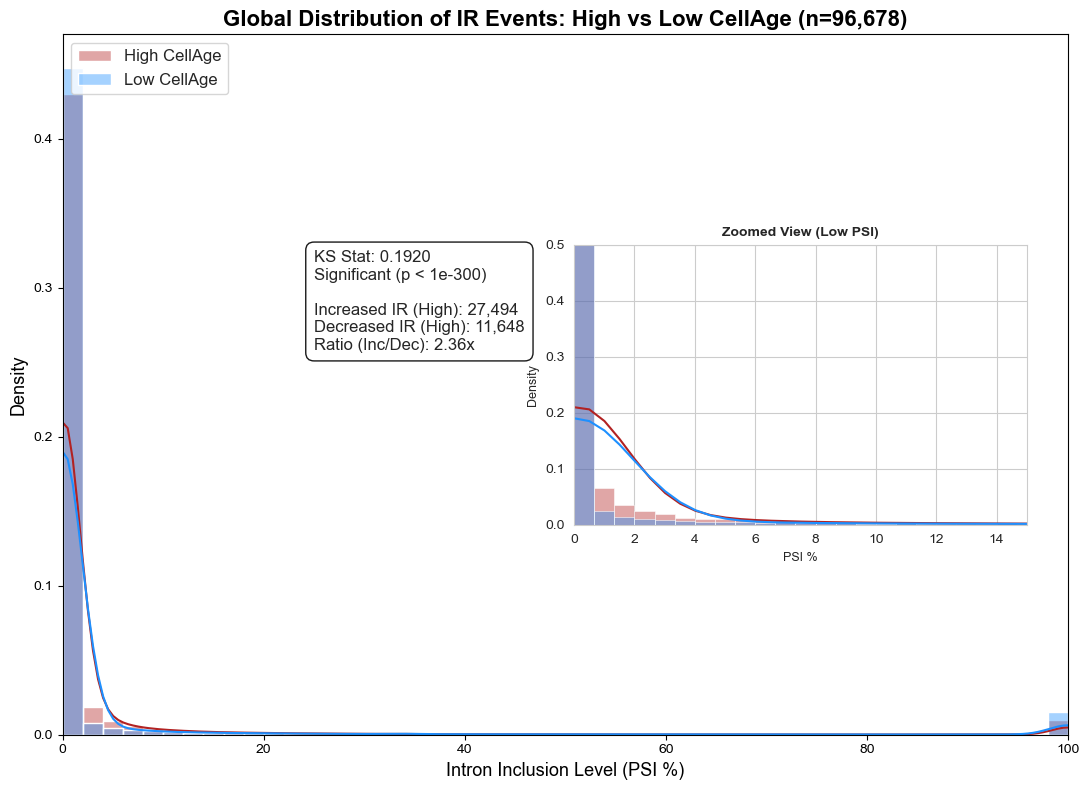

Analysis complete. KS p-value for CellAge shift: 0.0


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# 1. LOAD AND PREPARE
# Updated filename to the CellAge version
full_file = "INCLUSION_LEVELS_FULL-mm10-2_cellage.tab"
df_full = pd.read_csv(full_file, sep='\t')

# Filter for Intron Retention events
df_ir = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()

# Updated column names
samples = ['High_CellAge', 'Low_CellAge']
for s in samples:
    df_ir[s] = pd.to_numeric(df_ir[s], errors='coerce')

# Clean and calculate Delta
df_ir = df_ir.dropna(subset=samples)
df_ir['dPSI'] = df_ir['High_CellAge'] - df_ir['Low_CellAge']

# 2. STATISTICAL TEST (KS Test)
# Tests if the two distributions are drawn from the same population
ks_stat, p_value = ks_2samp(df_ir['High_CellAge'], df_ir['Low_CellAge'])

# Handle Underflow for the legend display
if p_value == 0 or p_value < 1e-300:
    p_val_display = "Significant (p < 1e-300)"
else:
    p_val_display = f"p = {p_value:.2e}"

# 3. VISUALIZATION
fig, ax = plt.subplots(figsize=(11, 8))
sns.set_style("whitegrid")

# Main plot distributions
sns.histplot(df_ir['High_CellAge'], color="firebrick", label="High CellAge", 
             kde=True, stat="density", alpha=0.4, bins=50, ax=ax)
sns.histplot(df_ir['Low_CellAge'], color="dodgerblue", label="Low CellAge", 
             kde=True, stat="density", alpha=0.4, bins=50, ax=ax)

# --- INSET START (Zooming into the 0-15% range) ---
# Most IR shifts in aging happen at low PSI levels
ax_ins = inset_axes(ax, width="45%", height="40%", loc='center right', borderpad=3)

sns.histplot(df_ir['High_CellAge'], color="firebrick", kde=True, 
             stat="density", alpha=0.4, bins=150, ax=ax_ins, label='_nolegend_')
sns.histplot(df_ir['Low_CellAge'], color="dodgerblue", kde=True, 
             stat="density", alpha=0.4, bins=150, ax=ax_ins, label='_nolegend_')

# Zoom constraints
ax_ins.set_xlim(0, 15)      
ax_ins.set_ylim(0, 0.5)     
ax_ins.set_title('Zoomed View (Low PSI)', fontsize=10, fontweight='bold')
ax_ins.set_xlabel('PSI %', fontsize=9)
ax_ins.set_ylabel('Density', fontsize=9)
# --- INSET END ---

# 4. ADD ANNOTATION & LABELS
ax.set_title(f'Global Distribution of IR Events: High vs Low CellAge (n={len(df_ir):,})', 
             fontsize=16, fontweight='bold')
ax.set_xlabel('Intron Inclusion Level (PSI %)', fontsize=13)
ax.set_ylabel('Density', fontsize=13)
ax.set_xlim(0, 100)

# Calculate stats for the text box
inc = (df_ir['dPSI'] > 0).sum()
dec = (df_ir['dPSI'] < 0).sum()
ratio = inc/dec if dec > 0 else np.inf

stats_text = (
    f"KS Stat: {ks_stat:.4f}\n"
    f"{p_val_display}\n\n"
    f"Increased IR (High): {inc:,}\n"
    f"Decreased IR (High): {dec:,}\n"
    f"Ratio (Inc/Dec): {ratio:.2f}x"
)

# Place stats box in a clear area
ax.text(25, ax.get_ylim()[1]*0.55, stats_text, fontsize=12, 
         bbox=dict(facecolor='white', alpha=0.9, edgecolor='black', boxstyle='round,pad=0.5'))

ax.legend(loc='upper left', fontsize=12)
plt.tight_layout()
plt.show()

print(f"Analysis complete. KS p-value for CellAge shift: {p_value}")

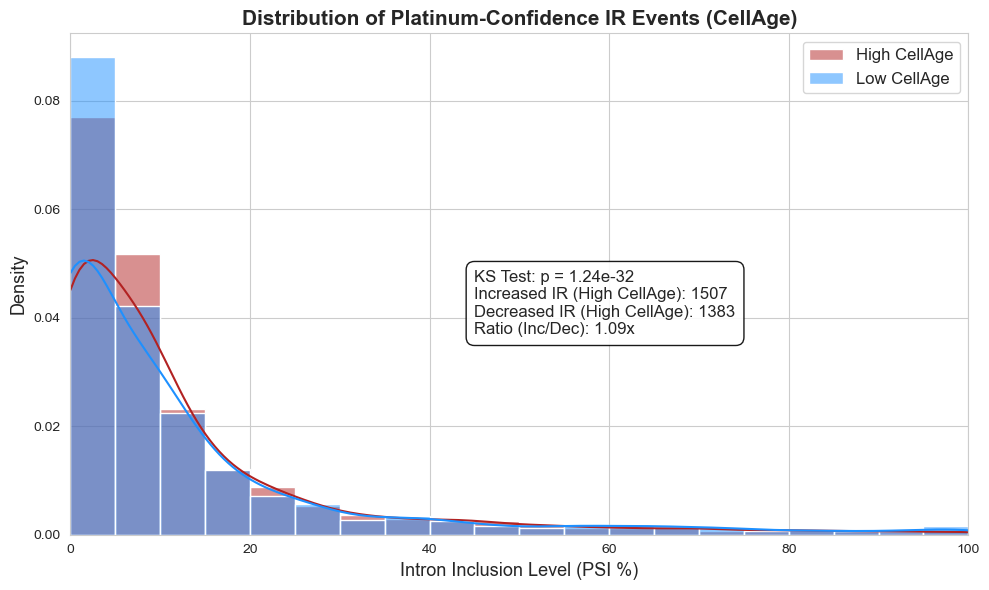

Analysis of Platinum Events (High-Confidence Subset):
The distribution shift is p = 1.24e-32.
52.1% of platinum IR events are INCREASING in High CellAge.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

# 1. LOAD THE FILTERED PLATINUM DATA
# This file was generated by the "Platinum Confidence" script
input_file = "Platinum_Confidence_CellAge_IR_5pct.csv"
try:
    df_platinum = pd.read_csv(input_file)
except FileNotFoundError:
    print(f"Error: {input_file} not found. Please run the Platinum Confidence script first.")
    exit()

# 2. STATISTICAL TEST
# Perform KS test specifically on the high-confidence subset
ks_stat, p_value = ks_2samp(df_platinum['High_CellAge'], df_platinum['Low_CellAge'])

# Handle Underflow for the display logic
if p_value == 0 or p_value < 1e-300:
    p_val_display = "Significant (p < 1e-300)"
else:
    p_val_display = f"p = {p_value:.2e}"

# 3. VISUALIZATION
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# Create the distributions for the Platinum subset
sns.histplot(df_platinum['High_CellAge'], color="firebrick", label="High CellAge", 
             kde=True, stat="density", alpha=0.5, bins=20)
sns.histplot(df_platinum['Low_CellAge'], color="dodgerblue", label="Low CellAge", 
             kde=True, stat="density", alpha=0.5, bins=20)

# 4. ADD ANNOTATION & LABELS
plt.title('Distribution of Platinum-Confidence IR Events (CellAge)', fontsize=15, fontweight='bold')
plt.xlabel('Intron Inclusion Level (PSI %)', fontsize=13)
plt.ylabel('Density', fontsize=13)
plt.xlim(0, 100)

# Calculate stats for the text box
inc = (df_platinum['dPSI'] > 0).sum()
dec = (df_platinum['dPSI'] < 0).sum()
ratio = inc/dec if dec > 0 else np.inf

stats_text = (
    f"KS Test: {p_val_display}\n"
    f"Increased IR (High CellAge): {inc}\n"
    f"Decreased IR (High CellAge): {dec}\n"
    f"Ratio (Inc/Dec): {ratio:.2f}x"
)

# Positioned in the middle-right area to avoid overlapping bars
plt.text(45, plt.gca().get_ylim()[1]*0.4, stats_text, fontsize=12, 
         bbox=dict(facecolor='white', alpha=0.9, edgecolor='black', boxstyle='round,pad=0.5'))

plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# 5. SUMMARY PRINT
print(f"Analysis of Platinum Events (High-Confidence Subset):")
print(f"The distribution shift is {p_val_display}.")
print(f"{ (inc/len(df_platinum))*100:.1f}% of platinum IR events are INCREASING in High CellAge.")
if ratio > 1.5:
    print("CONCLUSION: Strong evidence of an Intron Retention burden in High CellAge samples.")

---

FOR THE WHOLE TRANSCRIPTOME

Cells analyzed: 317 High, 173 Low


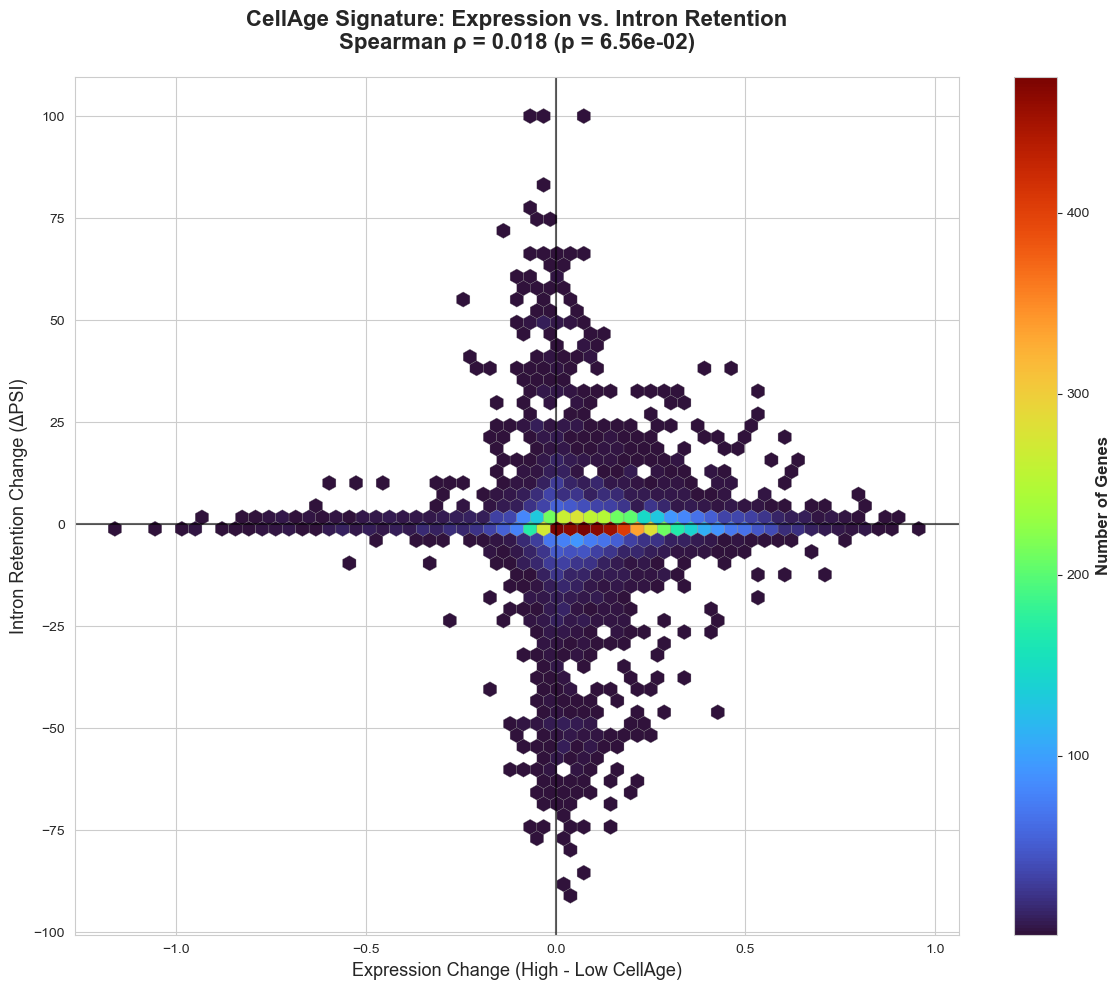

Analysis complete. Matched 10674 genes.


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# 1. LOAD DATA
adata = sc.read_h5ad('Old_Hepatocytes_CellAge_Groups_for_VastTools.h5ad')
ir_df = pd.read_csv('INCLUSION_LEVELS_FULL-mm10-2_cellage.tab', sep='\t')

# 2. GLOBAL EXPRESSION CHANGE
# Use 'mouse_gene_symbols' from var and capitalize
adata.var_names = adata.var['mouse_gene_symbols'].str.capitalize()

# Use the correct metadata column found in your previous step
group_col = 'cellage_signature_group'
high_cells = adata[adata.obs[group_col].isin(['High_CellAge', 'High'])]
low_cells = adata[adata.obs[group_col].isin(['Low_CellAge', 'Low'])]

print(f"Cells analyzed: {high_cells.n_obs} High, {low_cells.n_obs} Low")

exp_high = np.array(high_cells.X.mean(axis=0)).flatten()
exp_low = np.array(low_cells.X.mean(axis=0)).flatten()

expression_df = pd.DataFrame({
    'Gene': adata.var_names,
    'Exp_Change': exp_high - exp_low
}).set_index('Gene')

# 3. GLOBAL IR CHANGE
def get_mean_psi(value):
    if pd.isna(value) or value == 'NA': return np.nan
    try:
        nums = [float(x) for x in str(value).split(',') if x != 'NA']
        return np.mean(nums) if nums else np.nan
    except: return np.nan

ir_df['GENE'] = ir_df['GENE'].str.capitalize()
ir_df['PSI_High'] = ir_df['High_CellAge'].apply(get_mean_psi)
ir_df['PSI_Low'] = ir_df['Low_CellAge'].apply(get_mean_psi)

ir_summary = ir_df.groupby('GENE')[['PSI_High', 'PSI_Low']].mean()
ir_summary['IR_Change'] = ir_summary['PSI_High'] - ir_summary['PSI_Low']

# 4. MERGE TRANSCRIPTOME-WIDE
full_transcriptome = expression_df.merge(ir_summary, left_index=True, right_index=True).dropna()

# 5. CALCULATE SPEARMAN
rho, pval = spearmanr(full_transcriptome['Exp_Change'], full_transcriptome['IR_Change'])

# 6. VISUALIZATION (FULL EXTENT & REGULAR HEXAGONS)
plt.figure(figsize=(12, 10))
sns.set_style("whitegrid") # Adds the requested grid lines

# When gridsize is a single integer (e.g., 60), Matplotlib automatically 
# adjusts the number of Y-bins to keep hexagons regular (same length sides).
hb = plt.hexbin(
    full_transcriptome['Exp_Change'], 
    full_transcriptome['IR_Change'], 
    gridsize=60,         
    cmap='turbo',        
    mincnt=1,
    edgecolors='gray',   # Light border makes hexagons distinct
    linewidths=0.2
)

cb = plt.colorbar(hb)
cb.set_label('Number of Genes', fontsize=12, fontweight='bold')

# Add heavy crosshairs at 0,0
plt.axhline(0, color='black', linestyle='-', linewidth=1.5, alpha=0.6)
plt.axvline(0, color='black', linestyle='-', linewidth=1.5, alpha=0.6)

# Labels and Title
plt.title(f"CellAge Signature: Expression vs. Intron Retention\nSpearman ρ = {rho:.3f} (p = {pval:.2e})", 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Expression Change (High - Low CellAge)", fontsize=13)
plt.ylabel("Intron Retention Change (ΔPSI)", fontsize=13)

# Automatically adjust limits to show the full extent of outliers
plt.autoscale(enable=True, axis='both', tight=False)

plt.tight_layout()
plt.show()

print(f"Analysis complete. Matched {len(full_transcriptome)} genes.")

---

FIRST RIBOSOME GENES AND MITOCHONDRIA RIBOSOME GENES THAT SHOWED AN INTERESTING SIGNAL

Loading CellAge datasets...
Loaded 105 cytoplasmic and 77 mitochondrial genes.
Expression data: 317 High cells, 173 Low cells


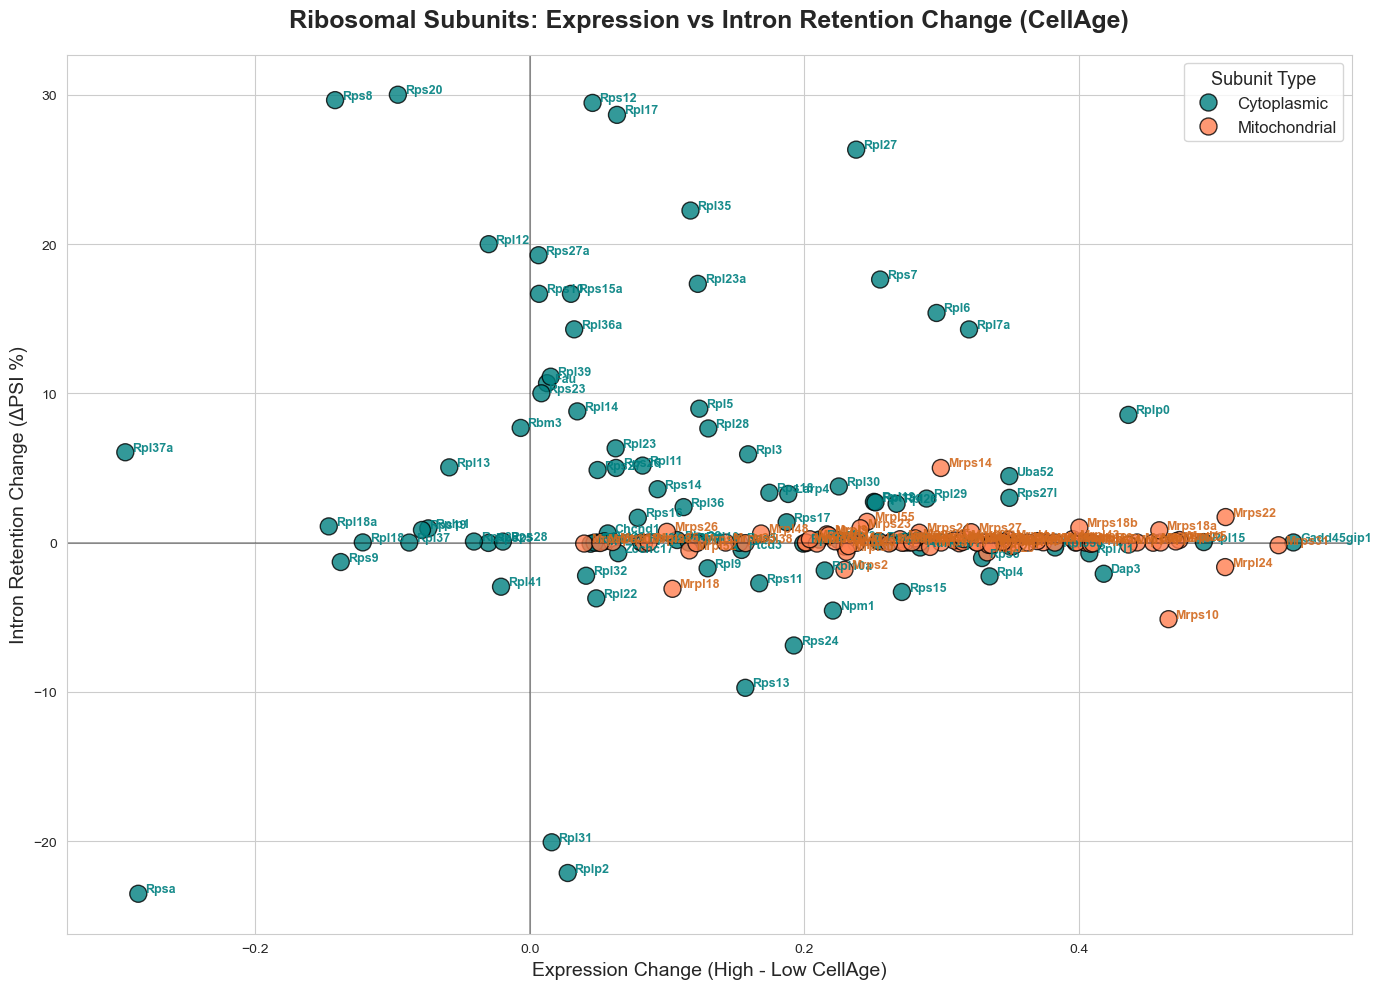

Matched 91 Cytoplasmic genes and 75 Mitochondrial genes.


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD DATA
print("Loading CellAge datasets...")
adata = sc.read_h5ad('Old_Hepatocytes_CellAge_Groups_for_VastTools.h5ad')
ir_df = pd.read_csv('INCLUSION_LEVELS_FULL-mm10-2_cellage.tab', sep='\t')

# 2. LOAD GENE LISTS FROM TEXT FILES
path_cytoplasmic = 'Ribosomal subunits.txt'
path_mitochondrial = 'MT Ribosomal subunits.txt'

def load_gene_list(path):
    try:
        # Assumes gene symbols are in the first column
        df = pd.read_csv(path, header=0, names=['gene_symbol'])
        return set(df['gene_symbol'].dropna().astype(str).str.strip().str.capitalize())
    except FileNotFoundError:
        print(f"Warning: File not found at {path}")
        return set()

cytoplasmic_genes = load_gene_list(path_cytoplasmic)
mitochondrial_genes = load_gene_list(path_mitochondrial)

print(f"Loaded {len(cytoplasmic_genes)} cytoplasmic and {len(mitochondrial_genes)} mitochondrial genes.")

# 3. CALCULATE EXPRESSION CHANGE
# Standardize gene names using 'mouse_gene_symbols'
adata.var_names = adata.var['mouse_gene_symbols'].str.capitalize()

# Use the correct metadata column and labels found in previous steps
group_col = 'cellage_signature_group'
high_cells = adata[adata.obs[group_col] == 'High_CellAge']
low_cells = adata[adata.obs[group_col] == 'Low_CellAge']

print(f"Expression data: {high_cells.n_obs} High cells, {low_cells.n_obs} Low cells")

# Handle sparse matrix means and flatten to 1D
exp_high = np.array(high_cells.X.mean(axis=0)).flatten()
exp_low = np.array(low_cells.X.mean(axis=0)).flatten()

expression_df = pd.DataFrame({
    'Gene': adata.var_names,
    'Exp_Change': exp_high - exp_low
}).set_index('Gene')

# 4. CALCULATE IR CHANGE (VAST-TOOLS CellAge Columns)
def get_mean_psi(value):
    if pd.isna(value) or value == 'NA': return np.nan
    try:
        nums = [float(x) for x in str(value).split(',') if x != 'NA']
        return np.mean(nums) if nums else np.nan
    except: return np.nan

ir_df['GENE'] = ir_df['GENE'].str.capitalize()
# Targeted CellAge columns
ir_df['PSI_High'] = ir_df['High_CellAge'].apply(get_mean_psi)
ir_df['PSI_Low'] = ir_df['Low_CellAge'].apply(get_mean_psi)

ir_summary = ir_df.groupby('GENE')[['PSI_High', 'PSI_Low']].mean()
ir_summary['IR_Change'] = ir_summary['PSI_High'] - ir_summary['PSI_Low']

# 5. MERGE AND TAG GENE TYPES
full_merged = expression_df.merge(ir_summary, left_index=True, right_index=True).dropna()

# Filter for the ribosomal genes provided in the text files
cyto_df = full_merged[full_merged.index.isin(cytoplasmic_genes)].copy()
cyto_df['Subunit_Type'] = 'Cytoplasmic'

mito_df = full_merged[full_merged.index.isin(mitochondrial_genes)].copy()
mito_df['Subunit_Type'] = 'Mitochondrial'

combined_rp_df = pd.concat([cyto_df, mito_df])

# 6. VISUALIZATION
if len(combined_rp_df) == 0:
    print("Error: No ribosomal genes from your lists were found in the combined Expression/IR dataset.")
else:
    plt.figure(figsize=(14, 10))
    sns.set_style("whitegrid") # Using whitegrid for clear coordinate tracking

    palette = {'Cytoplasmic': '#008080', 'Mitochondrial': '#FF7F50'} # Teal and Coral
    
    # Scatter plot with large points for visibility
    sns.scatterplot(
        data=combined_rp_df, x='Exp_Change', y='IR_Change', 
        hue='Subunit_Type', palette=palette,
        s=150, edgecolor='black', alpha=0.8
    )

    # Label every ribosomal gene found
    for gene, row in combined_rp_df.iterrows():
        label_color = 'teal' if row['Subunit_Type'] == 'Cytoplasmic' else 'chocolate'
        plt.text(x=row['Exp_Change'] + 0.005, y=row['IR_Change'] + 0.1, 
                 s=gene, fontsize=9, color=label_color, fontweight='bold', alpha=0.9)

    # Axis formatting
    plt.axhline(0, color='black', linestyle='-', linewidth=1.2, alpha=0.4)
    plt.axvline(0, color='black', linestyle='-', linewidth=1.2, alpha=0.4)
    
    plt.title("Ribosomal Subunits: Expression vs Intron Retention Change (CellAge)", 
              fontweight='bold', fontsize=18, pad=20)
    plt.xlabel("Expression Change (High - Low CellAge)", fontsize=14)
    plt.ylabel("Intron Retention Change (ΔPSI %)", fontsize=14)
    plt.legend(title="Subunit Type", fontsize=12, title_fontsize=13, frameon=True)
    
    # Show full extent automatically
    plt.autoscale(enable=True, axis='both')
    
    plt.tight_layout()
    plt.show()

    print(f"Matched {len(cyto_df)} Cytoplasmic genes and {len(mito_df)} Mitochondrial genes.")

NOW FOR SPLICING FACTORS, based on the mean expression

Loading CellAge datasets...
Expression data: 317 High, 173 Low cells found.


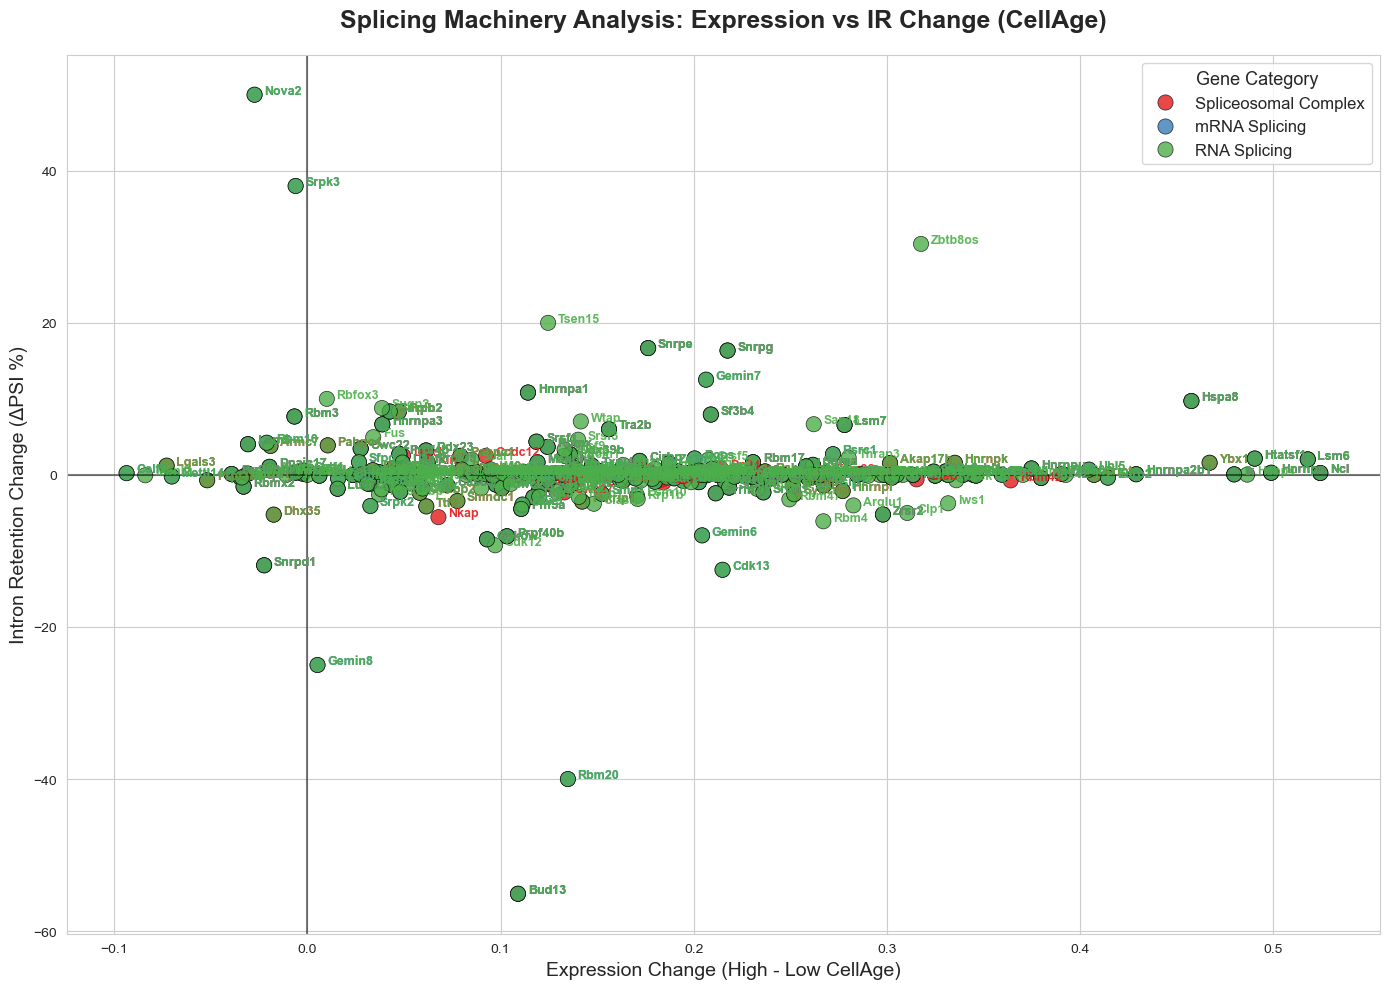


Summary of matched Splicing Machinery genes:
---------------------------------------------
Spliceosomal Complex     : 181 genes
mRNA Splicing            : 180 genes
RNA Splicing             : 295 genes


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# 1. LOAD DATA
print("Loading CellAge datasets...")
adata = sc.read_h5ad('Old_Hepatocytes_CellAge_Groups_for_VastTools.h5ad')
ir_df = pd.read_csv('INCLUSION_LEVELS_FULL-mm10-2_cellage.tab', sep='\t')

# 2. LOAD GENES FROM THE THREE TEXT FILES
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

def load_gene_list(path):
    try:
        # Assumes gene symbols are in the first column
        df = pd.read_csv(path, header=0, names=['gene_symbol'])
        return set(df['gene_symbol'].dropna().astype(str).str.strip().str.capitalize())
    except FileNotFoundError:
        print(f"Warning: File not found at {path}")
        return set()

gene_sets = {name: load_gene_list(path) for name, path in paths.items()}

# 3. CALCULATE EXPRESSION CHANGE
# Target the 'mouse_gene_symbols' column for indexing
adata.var_names = adata.var['mouse_gene_symbols'].str.capitalize()

# Use the CellAge metadata column
group_col = 'cellage_signature_group'
high_cells = adata[adata.obs[group_col] == 'High_CellAge']
low_cells = adata[adata.obs[group_col] == 'Low_CellAge']

print(f"Expression data: {high_cells.n_obs} High, {low_cells.n_obs} Low cells found.")

# Calculate mean expression (flatten for 1D array)
exp_high = np.array(high_cells.X.mean(axis=0)).flatten()
exp_low = np.array(low_cells.X.mean(axis=0)).flatten()

expression_df = pd.DataFrame({
    'Exp_Change': exp_high - exp_low
}, index=adata.var_names)

# 4. CALCULATE IR CHANGE (VAST-TOOLS CellAge Columns)
def get_mean_psi(value):
    if pd.isna(value) or value == 'NA': return np.nan
    try:
        nums = [float(x) for x in str(value).split(',') if x != 'NA']
        return np.mean(nums) if nums else np.nan
    except: return np.nan

ir_df['GENE'] = ir_df['GENE'].str.capitalize()
ir_df['PSI_High'] = ir_df['High_CellAge'].apply(get_mean_psi)
ir_df['PSI_Low'] = ir_df['Low_CellAge'].apply(get_mean_psi)

ir_summary = ir_df.groupby('GENE')[['PSI_High', 'PSI_Low']].mean()
ir_summary['IR_Change'] = ir_summary['PSI_High'] - ir_summary['PSI_Low']

# 5. MERGE AND TAG GENE TYPES
full_merged = expression_df.merge(ir_summary, left_index=True, right_index=True).dropna()

dfs_to_combine = []
for category, gene_list in gene_sets.items():
    subset = full_merged[full_merged.index.isin(gene_list)].copy()
    subset['Category'] = category
    dfs_to_combine.append(subset)

combined_df = pd.concat(dfs_to_combine)

# 6. VISUALIZATION
if len(combined_df) == 0:
    print("Error: No genes matched the dataset from your provided lists.")
else:
    plt.figure(figsize=(14, 10))
    sns.set_style("whitegrid") # Using requested whitegrid style

    # Specific color palette for the machinery categories
    palette = {
        'Spliceosomal Complex': '#e41a1c', # Bold Red
        'mRNA Splicing': '#377eb8',        # Bold Blue
        'RNA Splicing': '#4daf4a'          # Bold Green
    }
    
    # Scatter plot
    sns.scatterplot(
        data=combined_df, x='Exp_Change', y='IR_Change', 
        hue='Category', palette=palette,
        s=120, edgecolor='black', alpha=0.8, linewidth=0.5
    )

    # Label genes with category-matched colors
    # Added a small offset to prevent text overlapping with points
    for i in range(len(combined_df)):
        row = combined_df.iloc[i]
        gene_name = combined_df.index[i]
        plt.text(
            x=row['Exp_Change'] + 0.005, 
            y=row['IR_Change'] + 0.1, 
            s=gene_name, 
            fontsize=9, 
            fontweight='semibold',
            color=palette[row['Category']], 
            alpha=0.9
        )

    # Add reference lines
    plt.axhline(0, color='black', linestyle='-', linewidth=1.5, alpha=0.5)
    plt.axvline(0, color='black', linestyle='-', linewidth=1.5, alpha=0.5)
    
    # Show FULL EXTENT of the data
    plt.autoscale(enable=True, axis='both')

    plt.title("Splicing Machinery Analysis: Expression vs IR Change (CellAge)", 
              fontweight='bold', fontsize=18, pad=20)
    plt.xlabel("Expression Change (High - Low CellAge)", fontsize=14)
    plt.ylabel("Intron Retention Change (ΔPSI %)", fontsize=14)
    plt.legend(title="Gene Category", fontsize=12, title_fontsize=13, frameon=True, loc='best')
    
    plt.tight_layout()
    plt.show()

    # Summary table
    print("\nSummary of matched Splicing Machinery genes:")
    print("-" * 45)
    for cat in paths.keys():
        count = len(combined_df[combined_df['Category'] == cat])
        print(f"{cat:<25}: {count} genes")

Loading CellAge datasets...
Expression data: 317 High cells, 173 Low cells found.


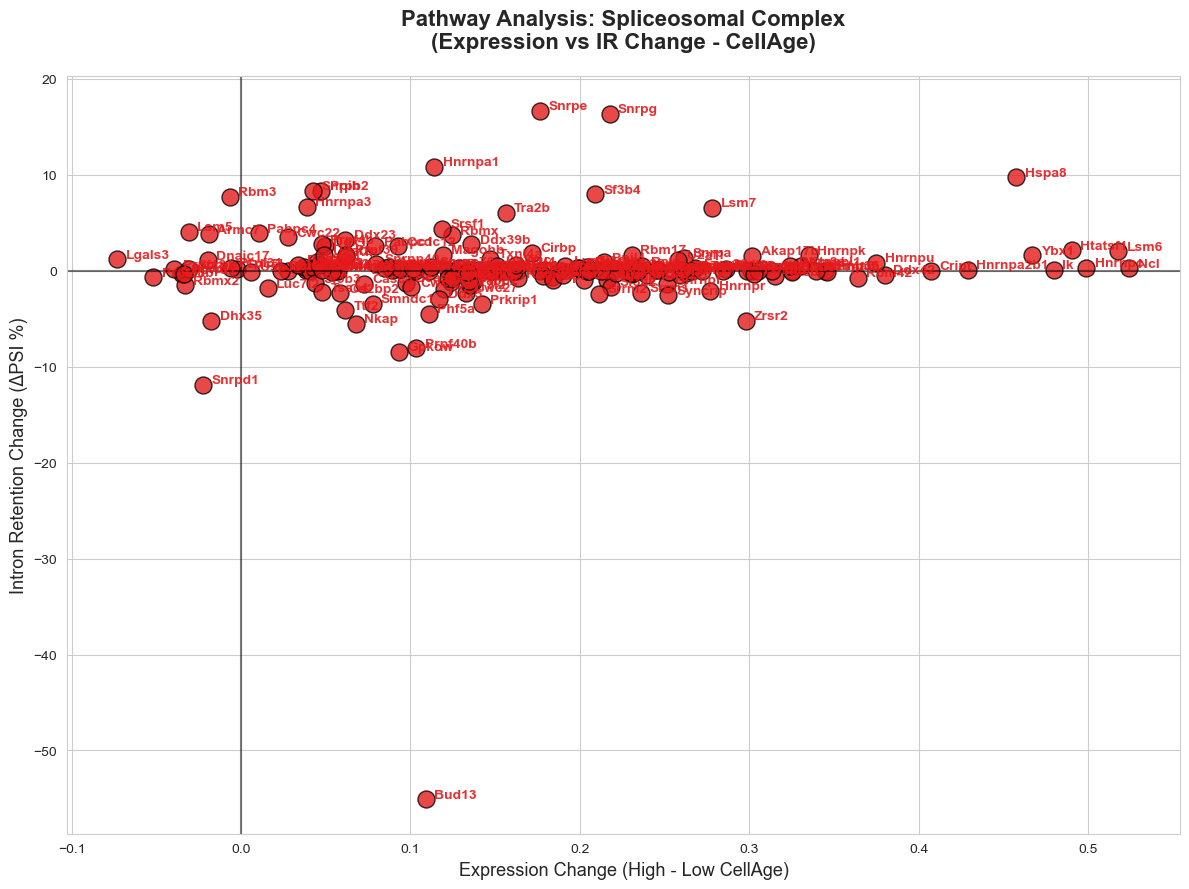

Plotted 181 genes for category: Spliceosomal Complex.


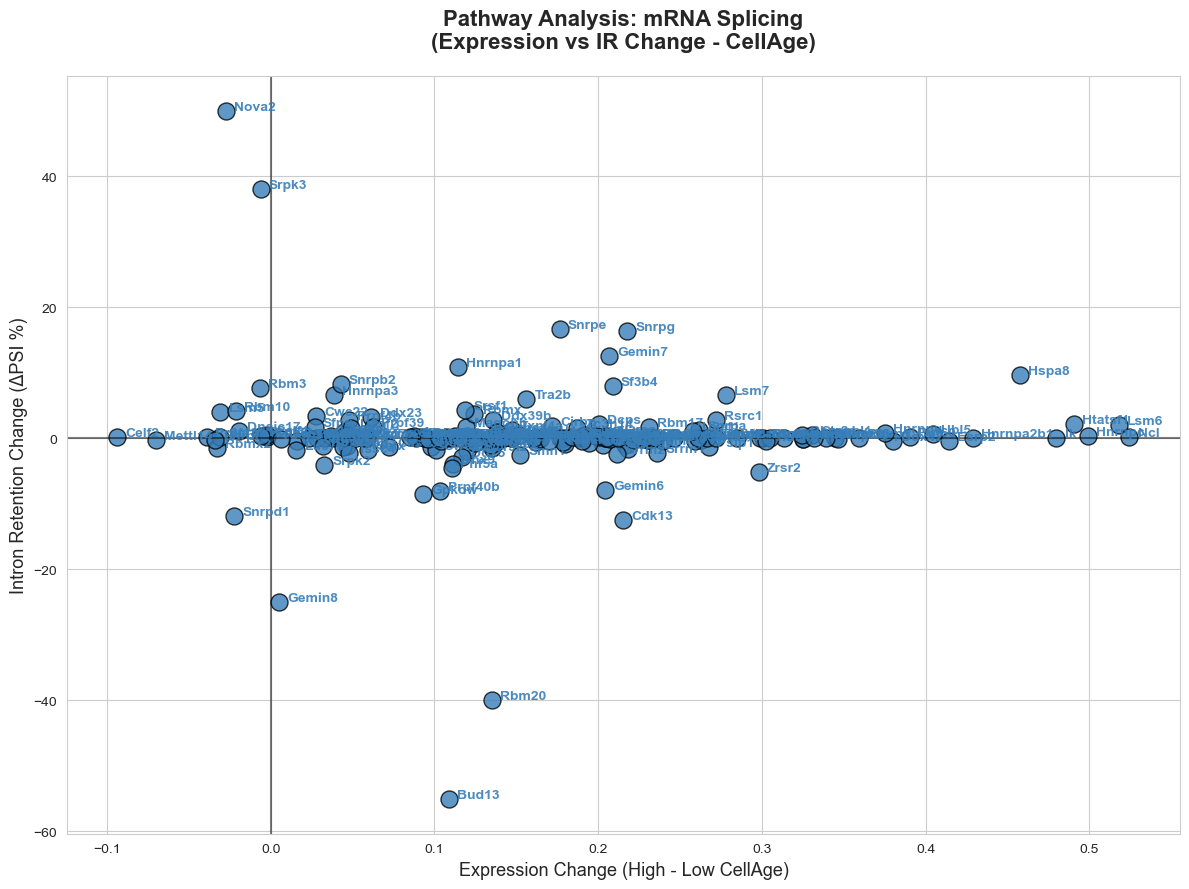

Plotted 180 genes for category: mRNA Splicing.


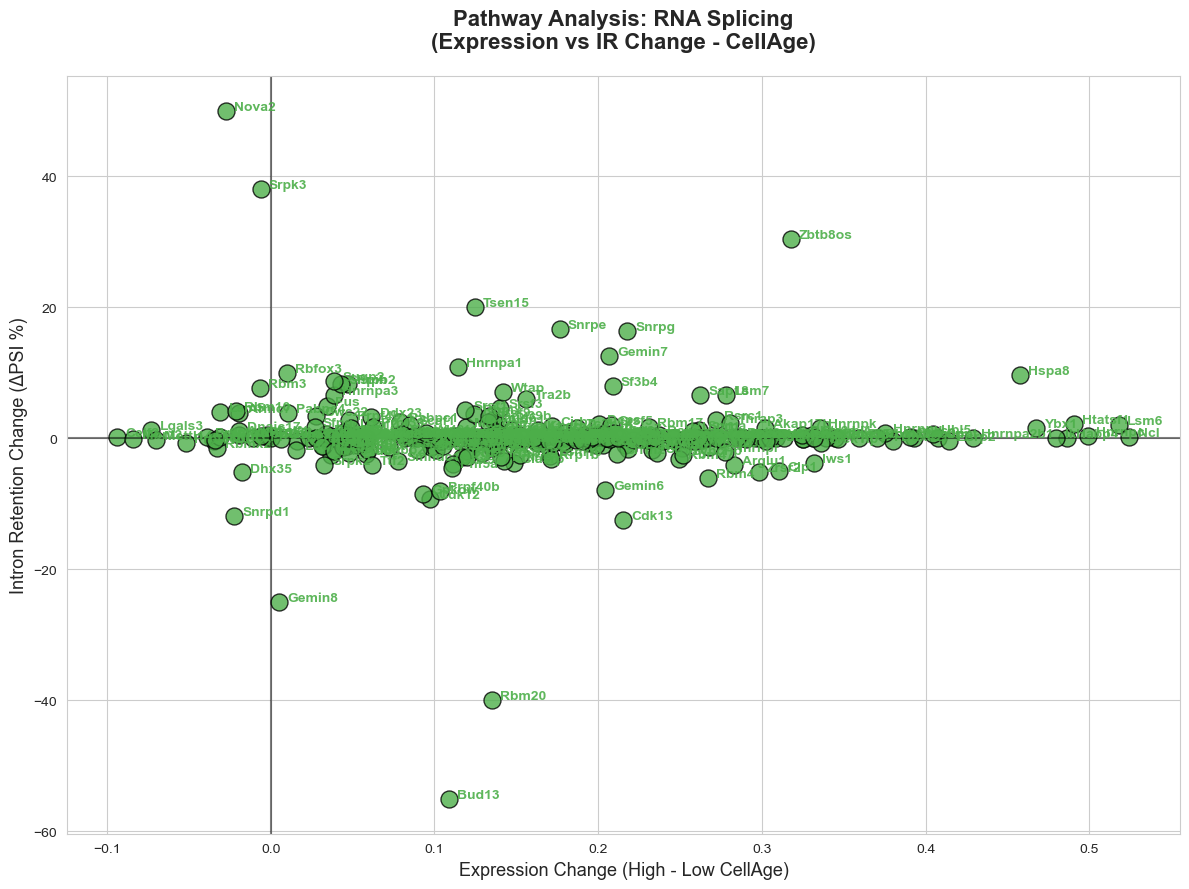

Plotted 295 genes for category: RNA Splicing.


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD DATA
print("Loading CellAge datasets...")
adata = sc.read_h5ad('Old_Hepatocytes_CellAge_Groups_for_VastTools.h5ad')
ir_df = pd.read_csv('INCLUSION_LEVELS_FULL-mm10-2_cellage.tab', sep='\t')

# 2. LOAD GENES FROM THE THREE TEXT FILES
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

def load_gene_list(path):
    try:
        df = pd.read_csv(path, header=0, names=['gene_symbol'])
        return set(df['gene_symbol'].dropna().astype(str).str.strip().str.capitalize())
    except FileNotFoundError:
        print(f"Warning: File not found at {path}")
        return set()

gene_sets = {name: load_gene_list(path) for name, path in paths.items()}

# 3. CALCULATE EXPRESSION CHANGE
# Use 'mouse_gene_symbols' from var and capitalize to match VAST-TOOLS
adata.var_names = adata.var['mouse_gene_symbols'].str.capitalize()

# Updated metadata column and group labels
group_col = 'cellage_signature_group'
high_cells = adata[adata.obs[group_col] == 'High_CellAge']
low_cells = adata[adata.obs[group_col] == 'Low_CellAge']

print(f"Expression data: {high_cells.n_obs} High cells, {low_cells.n_obs} Low cells found.")

exp_high = np.array(high_cells.X.mean(axis=0)).flatten()
exp_low = np.array(low_cells.X.mean(axis=0)).flatten()

expression_df = pd.DataFrame({
    'Gene': adata.var_names,
    'Exp_Change': exp_high - exp_low
}).set_index('Gene')

# 4. CALCULATE IR CHANGE (VAST-TOOLS CellAge Columns)
def get_mean_psi(value):
    if pd.isna(value) or value == 'NA': return np.nan
    try:
        nums = [float(x) for x in str(value).split(',') if x != 'NA']
        return np.mean(nums) if nums else np.nan
    except: return np.nan

ir_df['GENE'] = ir_df['GENE'].str.capitalize()
# Targeted CellAge columns
ir_df['PSI_High'] = ir_df['High_CellAge'].apply(get_mean_psi)
ir_df['PSI_Low'] = ir_df['Low_CellAge'].apply(get_mean_psi)

ir_summary = ir_df.groupby('GENE')[['PSI_High', 'PSI_Low']].mean()
ir_summary['IR_Change'] = ir_summary['PSI_High'] - ir_summary['PSI_Low']

# 5. MERGE DATA
full_merged = expression_df.merge(ir_summary, left_index=True, right_index=True).dropna()

# 6. VISUALIZATION LOOP (One plot per file)
palette = {
    'Spliceosomal Complex': '#e41a1c', # Bold Red
    'mRNA Splicing': '#377eb8',        # Bold Blue
    'RNA Splicing': '#4daf4a'          # Bold Green
}

for category, gene_list in gene_sets.items():
    # Filter for the specific category
    subset = full_merged[full_merged.index.isin(gene_list)].copy()
    
    if len(subset) == 0:
        print(f"Skipping {category}: No matching genes found in the combined dataset.")
        continue

    plt.figure(figsize=(12, 9))
    sns.set_style("whitegrid") # Using requested grid style

    # Scatter Plot
    sns.scatterplot(
        data=subset, x='Exp_Change', y='IR_Change', 
        color=palette[category], s=150, edgecolor='black', alpha=0.8
    )

    # Label genes with offset to prevent overlap
    for gene, row in subset.iterrows():
        plt.text(
            x=row['Exp_Change'] + 0.005, 
            y=row['IR_Change'] + 0.15, 
            s=gene, 
            fontsize=10, 
            color=palette[category], 
            fontweight='bold',
            alpha=0.9
        )

    # Reference lines
    plt.axhline(0, color='black', linestyle='-', linewidth=1.5, alpha=0.5)
    plt.axvline(0, color='black', linestyle='-', linewidth=1.5, alpha=0.5)
    
    # Titles and Labels
    plt.title(f"Pathway Analysis: {category}\n(Expression vs IR Change - CellAge)", 
              fontweight='bold', fontsize=16, pad=20)
    plt.xlabel("Expression Change (High - Low CellAge)", fontsize=13)
    plt.ylabel("Intron Retention Change (ΔPSI %)", fontsize=13)
    
    # Auto-scale ensures FULL EXTENT is visible
    plt.autoscale(enable=True, axis='both')
    
    plt.tight_layout()
    plt.show()

    print(f"Plotted {len(subset)} genes for category: {category}.")

---

SOK,SOK,149=147=6,OK,S@290.07,11.93
a seguir ao arroba são as inclusion e depois as exclusion read
odd ratio test por condição, ou seja por high or low senescence. comparando uma a outra para criar o rácio.
criar uma tabela proprietaria com os valores de inclusion e exlcusion reads
glm function no R, dar o input definindo cada condição
a (exponencial se a visualização estiver muito colapsada) do estimate é a métrica substituta para o delta PSI

    glm(cbind(Inclusion, Exclusion) ~ Group, data = event_data, family = binomial(link = "logit"))

In [ ]:
import csv
import os

# Files to process
input_files = ["INCLUSION_LEVELS_FULL-mm10-2.tab", "INCLUSION_LEVELS_FULL-mm10-2_cellage.tab"]

def extract_reads(q_string):
    if not q_string or "@" not in q_string or q_string == "NA":
        return "NA", "NA"
    try:
        reads_part = q_string.split("@")[1]
        inc, exc = reads_part.split(",")
        return inc.strip(), exc.strip()
    except (IndexError, ValueError):
        return "NA", "NA"

header = [
    "Gene", "Event", "Coord", 
    "High_Inclusion_Reads", "High_Exclusion_Reads",
    "Low_Inclusion_Reads", "Low_Exclusion_Reads"
]

for file_name in input_files:
    if not os.path.exists(file_name):
        print(f"Skipping {file_name}: File not found.")
        continue
    
    output_name = file_name.replace(".tab", "") + "_INT_ONLY.csv"
    print(f"Processing {file_name}...")
    
    with open(file_name, 'r') as f_in, open(output_name, mode='w', newline='') as f_out:
        reader = csv.DictReader(f_in, delimiter='\t')
        writer = csv.writer(f_out)
        writer.writerow(header)
        
        count = 0
        for row in reader:
            if row["EVENT"].startswith("MmuINT"):
                
                # --- FLEXIBLE COLUMN LOOKUP ---
                # This checks for 'High_Senescence-Q' OR 'High_CellAge-Q'
                high_q_value = row.get("High_Senescence-Q") or row.get("High_CellAge-Q", "")
                low_q_value = row.get("Low_Senescence-Q") or row.get("Low_CellAge-Q", "")
                
                high_inc, high_exc = extract_reads(high_q_value)
                low_inc, low_exc = extract_reads(low_q_value)
                
                # Only write if we actually found data (not both NA)
                if high_inc != "NA" or low_inc != "NA":
                    writer.writerow([
                        row["GENE"], row["EVENT"], row["COORD"],
                        high_inc, high_exc, low_inc, low_exc
                    ])
                    count += 1
        
        print(f"Done. Found {count} valid Intron Retention events for {file_name}.")

print("\nSuccess! Now rerun your R GLM script using these new CSV files.")

Processing INCLUSION_LEVELS_FULL-mm10-2.tab...
Done. Found 189134 valid Intron Retention events for INCLUSION_LEVELS_FULL-mm10-2.tab.
Processing INCLUSION_LEVELS_FULL-mm10-2_cellage.tab...
Done. Found 189134 valid Intron Retention events for INCLUSION_LEVELS_FULL-mm10-2_cellage.tab.

Success! Now rerun your R GLM script using these new CSV files.


gtf com rpl27 converter para bed. 
com a ionformação deste infromação selecionar reads com apenas essa posiçã
sam tools view selecionar reads da posição especifica que queres 
criar ium bam novo  

In [ ]:
import scanpy as sc
adata = sc.read_h5ad('Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad')
adata

AnnData object with n_obs × n_vars = 519 × 19559
    obs: 'FACS.selection', 'age', 'cell', 'cell_ontology_class', 'cell_ontology_id', 'free_annotation', 'method', 'mouse.id', 'sex', 'subtissue', 'tissue', 'n_genes', 'n_counts', 'louvain', 'leiden', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'age_sex', 'doublet_score', 'predicted_doublet', 'leiden_0.5', 'leiden_0.75', 'leiden_1.0', 'cell_type', 'celltypist_predicted_labels', 'SenMayo_score', 'CellAge_up_score', 'HernandezSegura_enriched_score', 'HernandezSegura_depleted_score', 'senescence_group'
    var: 'n_cells', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mean', 'std

In [ ]:
import scanpy as sc

# Load the file
adata = sc.read_h5ad("Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad")

print("--- Gene Names (Index) ---")
print(adata.var_names[:10])

print("\n--- Column 'mouse_gene_symbols' (First 10) ---")
if 'mouse_gene_symbols' in adata.var.columns:
    print(adata.var['mouse_gene_symbols'].head(10))
else:
    print("Column 'mouse_gene_symbols' not found in .var")

print(f"\nTotal genes: {adata.n_vars}")
print(f"Total cells: {adata.n_obs}")

--- Gene Names (Index) ---
Index(['0610005C13RIK', '0610007C21RIK', '0610007L01RIK', '0610007N19RIK',
       '0610007P08RIK', '0610007P14RIK', '0610007P22RIK', '0610008F07RIK',
       '0610009B22RIK', '0610009D07RIK'],
      dtype='object', name='index')

--- Column 'mouse_gene_symbols' (First 10) ---
index
0610005C13RIK    0610005C13Rik
0610007C21RIK    0610007C21Rik
0610007L01RIK    0610007L01Rik
0610007N19RIK    0610007N19Rik
0610007P08RIK    0610007P08Rik
0610007P14RIK    0610007P14Rik
0610007P22RIK    0610007P22Rik
0610008F07RIK    0610008F07Rik
0610009B22RIK    0610009B22Rik
0610009D07RIK    0610009D07Rik
Name: mouse_gene_symbols, dtype: object

Total genes: 19559
Total cells: 519


---

CORRELATION ANALYSIS AT THE CELL LEVEL BETWEEN SENESCENT SCORE AND EXPRESSION OF SPLICING RELATED GENES

FOR SENMAYO SCORED HEPATOCYTES

C:\Users\lukas\AppData\Local\Temp\ipykernel_20304\1116879974.py:55: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, _ = spearmanr(exp, sen_scores)


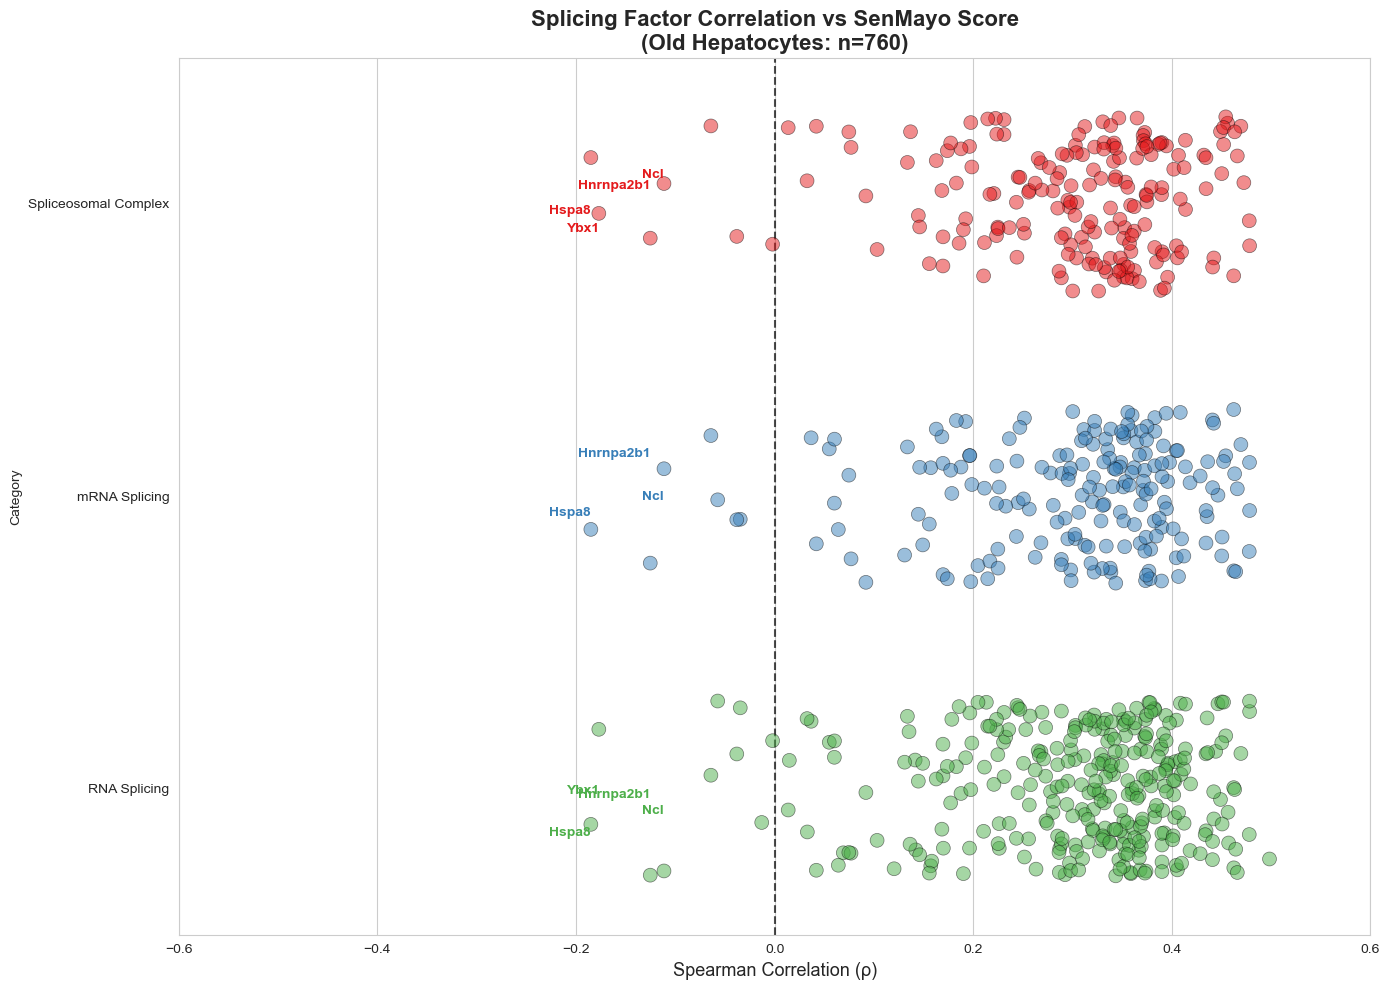


SPLICING GENES LOST AS SENESCENCE INTENSIFIES
     Gene       Rho             Category
    HSPA8 -0.185094 Spliceosomal Complex
    HSPA8 -0.185094        mRNA Splicing
    HSPA8 -0.185094         RNA Splicing
     YBX1 -0.177069 Spliceosomal Complex
     YBX1 -0.177069         RNA Splicing
HNRNPA2B1 -0.125277         RNA Splicing
HNRNPA2B1 -0.125277        mRNA Splicing
HNRNPA2B1 -0.125277 Spliceosomal Complex
      NCL -0.111437        mRNA Splicing
      NCL -0.111437         RNA Splicing
      NCL -0.111437 Spliceosomal Complex
   HNRNPC -0.064192 Spliceosomal Complex
   HNRNPC -0.064192         RNA Splicing
   HNRNPC -0.064192        mRNA Splicing
   SRSF12 -0.057327        mRNA Splicing
   SRSF12 -0.057327         RNA Splicing
   SNRPD3 -0.038116 Spliceosomal Complex
   SNRPD3 -0.038116         RNA Splicing
   SNRPD3 -0.038116        mRNA Splicing
     UBL5 -0.034618        mRNA Splicing
     UBL5 -0.034618         RNA Splicing
     AFF2 -0.012988         RNA Splicing
   LGALS3 

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
import os

# 1. LOAD AND FILTER (Old Hepatocytes Only)
file_path = "Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad"
adata = sc.read_h5ad(file_path)

# Isolate the ~760 old hepatocytes
adata_old = adata[
    (adata.obs['cell_ontology_class'] == 'hepatocyte') & 
    (adata.obs['age'].isin(['18m', '24m']))
].copy()

# Align symbols
if 'mouse_gene_symbols' in adata_old.var.columns:
    adata_old.var_names = adata_old.var['mouse_gene_symbols'].astype(str)
    adata_old.var_names_make_unique()
adata_old.var_names = adata_old.var_names.str.upper()

# 2. DEFINE CATEGORIES
category_colors = {
    'Spliceosomal Complex': '#e41a1c', 
    'mRNA Splicing': '#377eb8',        
    'RNA Splicing': '#4daf4a'          
}

paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

# 3. CALCULATE GENE-TO-SCORE CORRELATION
results = []
sen_scores = adata_old.obs['SenMayo_score'].values

for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            genes = [line.strip().upper() for line in f if line.strip()]
            matched = [g for g in genes if g in adata_old.var_names]
            
            for gene in matched:
                exp = adata_old[:, gene].X
                exp = exp.toarray().flatten() if hasattr(exp, "toarray") else exp.flatten()
                
                if np.std(exp) == 0: continue
                
                # CORRELATION: Single gene expression vs collective SenMayo score
                rho, _ = spearmanr(exp, sen_scores)
                results.append({'Gene': gene, 'Category': label, 'Rho': rho})

df_corr = pd.DataFrame(results).drop_duplicates(subset=['Gene', 'Category'])

# 4. VISUALIZATION
plt.figure(figsize=(14, 10))
sns.set_style("whitegrid")

ax = sns.stripplot(
    data=df_corr, x='Rho', y='Category', hue='Category',
    palette=category_colors, size=10, alpha=0.5, edgecolor='black', linewidth=0.5, jitter=0.3, legend=False
)

plt.axvline(0, color='black', linestyle='--', alpha=0.7, lw=1.5)

# Label the most significant negative correlates (The Victims)
neg_hits = df_corr[df_corr['Rho'] < -0.1].sort_values('Rho')
for i, cat in enumerate(df_corr['Category'].unique()):
    cat_neg = neg_hits[neg_hits['Category'] == cat].head(7)
    for _, row in cat_neg.iterrows():
        plt.text(row['Rho'], i + np.random.uniform(-0.2, 0.2), row['Gene'].capitalize(),
                 color=category_colors[cat], fontsize=10, fontweight='bold', ha='right')

plt.title(f'Splicing Factor Correlation vs SenMayo Score\n(Old Hepatocytes: n={len(adata_old)})', fontsize=16, fontweight='bold')
plt.xlabel('Spearman Correlation (ρ)', fontsize=13)
plt.xlim(-0.6, 0.6)
plt.tight_layout()
plt.show()

# 5. LIST OF NEGATIVELY CORRELATED GENES
print("\n" + "="*50)
print("SPLICING GENES LOST AS SENESCENCE INTENSIFIES")
print("="*50)
print(df_corr[df_corr['Rho'] < 0].sort_values('Rho')[['Gene', 'Rho', 'Category']].to_string(index=False))

Loading Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad...
Splicing Machinery: Matched 340 genes.
SenMayo Signature: Matched 110 genes.


C:\Users\lukas\AppData\Local\Temp\ipykernel_11860\2188961420.py:79: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pval = spearmanr(exp, spl_total_score)


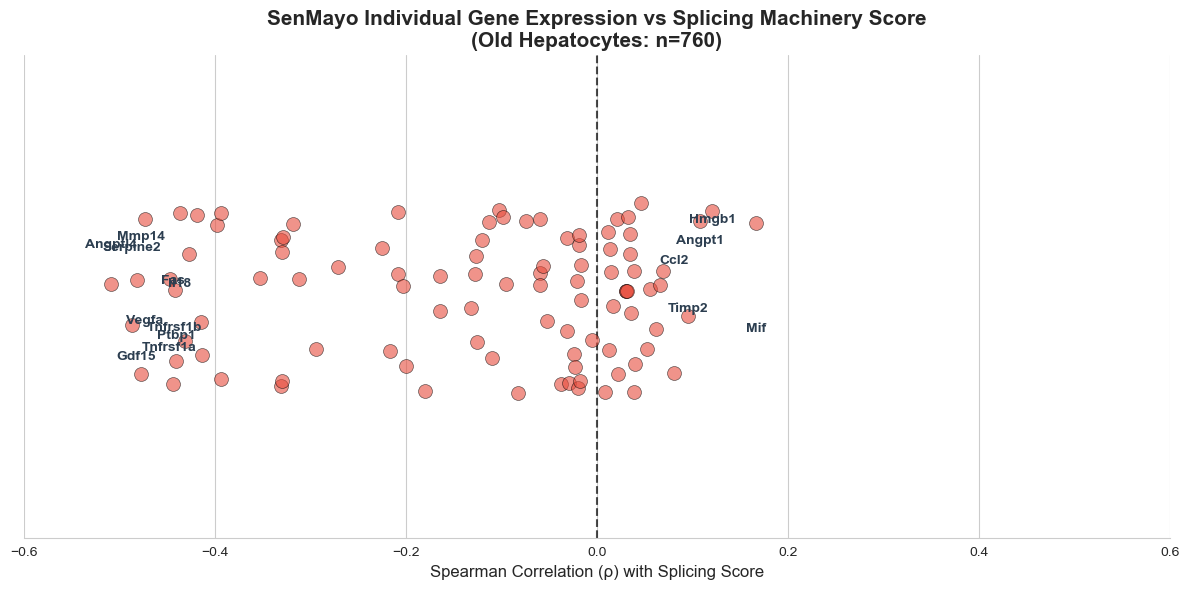


SENMAYO GENES MOST STRONGLY ASSOCIATED WITH SPLICING COLLAPSE
    Gene       Rho        p_val
 Angptl4 -0.509020 2.467296e-51
Serpine2 -0.486789 1.809178e-46
   Gdf15 -0.481982 1.833404e-45
   Mmp14 -0.477709 1.393256e-44
   Vegfa -0.473046 1.233097e-43
Tnfrsf1a -0.447404 1.109198e-38
     Fas -0.443912 4.872486e-38
Tnfrsf1b -0.441803 1.180809e-37
   Ptbp1 -0.440415 2.107521e-37
    Il18 -0.436943 8.873482e-37
  Scamp4 -0.431352 8.674780e-36
    Pigf -0.427214 4.562418e-35
    Egfr -0.418159 1.594235e-33
    Fgf1 -0.414108 7.547634e-33
    Lcp1 -0.413334 1.013787e-32
 Tubgcp2 -0.398217 2.750598e-30
     Cd9 -0.393790 1.344388e-29
   Il6st -0.393461 1.511450e-29
  Nap1l4 -0.352834 1.064483e-23
     Jun -0.331040 6.801199e-21


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gseapy as gp
from scipy.stats import spearmanr
import os

# =============================================================================
# 1. LOAD AND ALIGN DATA
# =============================================================================
file_path = "Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad"
print(f"Loading {file_path}...")
adata = sc.read_h5ad(file_path)

# Isolate Old Hepatocytes
target_adata = adata[
    (adata.obs['cell_ontology_class'] == 'hepatocyte') & 
    (adata.obs['age'].isin(['18m', '24m']))
].copy()

# CRITICAL: Align index to symbols and create a Case-Insensitive Lookup
if 'mouse_gene_symbols' in target_adata.var.columns:
    target_adata.var_names = target_adata.var['mouse_gene_symbols'].astype(str)
    target_adata.var_names_make_unique()

# Create a lookup map: {UPPERCASE_NAME: ORIGINAL_NAME_IN_ADATA}
data_lookup = {g.upper(): g for g in target_adata.var_names}

def get_matched_list(raw_list):
    """Bridge function to match any list to the adata index."""
    return [data_lookup[str(g).upper()] for g in raw_list if str(g).upper() in data_lookup]

# =============================================================================
# 2. MATCH AND CALCULATE SPLICING MACHINERY SCORE
# =============================================================================
spl_paths = ['Spliceosomal Complex.txt', 'mRNA Splicing via spliceosome.txt', 'RNA Splicing.txt']
spl_raw = []
for p in spl_paths:
    if os.path.exists(p):
        with open(p, 'r') as f:
            # Skip header, strip whitespace and quotes
            spl_raw.extend([l.strip().replace('"', '') for l in f.readlines()[1:] if l.strip()])

list_splicing = get_matched_list(list(set(spl_raw)))

print(f"Splicing Machinery: Matched {len(list_splicing)} genes.")

if len(list_splicing) == 0:
    # Diagnostic print if it still fails
    print("DEBUG: First 10 genes in data:", list(target_adata.var_names[:10]))
    print("DEBUG: First 10 genes in files:", spl_raw[:10])
    raise ValueError("Zero splicing genes matched. Check gene symbol formatting.")

# Calculate the machinery score
sc.tl.score_genes(target_adata, list_splicing, score_name='splicing_score')

# =============================================================================
# 3. CORRELATE INDIVIDUAL SENMAYO GENES VS SPLICING SCORE
# =============================================================================
# Load SenMayo from GMT
sen_gmt = gp.read_gmt("SAUL_SEN_MAYO.v2025.1.Mm.gmt")
list_senmayo = get_matched_list(list(sen_gmt["SAUL_SEN_MAYO"]))

print(f"SenMayo Signature: Matched {len(list_senmayo)} genes.")

spl_total_score = target_adata.obs['splicing_score'].values.astype(float)
sen_gene_results = []

for gene in list_senmayo:
    # Extract single-cell expression (handles sparse/dense)
    exp = target_adata[:, gene].X
    exp = exp.toarray().flatten() if hasattr(exp, "toarray") else exp.flatten()
    
    if np.std(exp) == 0: continue
    
    # Spearman Correlation
    rho, pval = spearmanr(exp, spl_total_score)
    sen_gene_results.append({'Gene': gene, 'Rho': float(np.atleast_1d(rho)[0]), 'p_val': pval})

df_sen_corr = pd.DataFrame(sen_gene_results).sort_values('Rho')

# =============================================================================
# 4. VISUALIZATION
# =============================================================================
plt.figure(figsize=(12, 6))
sns.set_style("whitegrid")

# Strip plot of all SenMayo genes
ax = sns.stripplot(
    data=df_sen_corr, x='Rho', color='#e74c3c', size=10, 
    alpha=0.6, edgecolor='black', linewidth=0.5, jitter=0.2
)

plt.axvline(0, color='black', linestyle='--', alpha=0.7)

# Label the "Antagonists" (Left side: High Marker = Low Splicing)
# and the "Early Markers" (Right side: High Marker = High Splicing)
top_neg = df_sen_corr.nsmallest(10, 'Rho')
top_pos = df_sen_corr.nlargest(5, 'Rho')

for _, row in pd.concat([top_neg, top_pos]).iterrows():
    plt.text(
        row['Rho'], np.random.uniform(-0.15, 0.15), row['Gene'],
        fontsize=10, fontweight='bold', ha='center', va='bottom', color='#2c3e50'
    )

plt.title('SenMayo Individual Gene Expression vs Splicing Machinery Score\n(Old Hepatocytes: n=760)', 
          fontsize=15, fontweight='bold')
plt.xlabel('Spearman Correlation (ρ) with Splicing Score', fontsize=12)
plt.yticks([]) 
plt.xlim(-0.6, 0.6)
sns.despine(left=True)
plt.tight_layout()
plt.show()

# =============================================================================
# 5. SUMMARY TABLE
# =============================================================================
print("\n" + "="*65)
print("SENMAYO GENES MOST STRONGLY ASSOCIATED WITH SPLICING COLLAPSE")
print("="*65)
print(df_sen_corr.head(20).to_string(index=False))

POSITIVE: The more senescent a cell becomes the more it expresses that gene

NEGATIVE: The more senescent a cell becomes the less it expresses that gene

---

DEFINING NEW GROUPS OF THE HEPATOCYTES BASED ON EXPRESSION OF SPLICING RELATED GENES

With the 519 hepatocytes identified and utilized in the previous pseudo-bulk, I created two new groups based on the expression of splicing associated genes found in the text docs provided by Joel (Splicing proteins csv file).

Like for the senescent sigantures, i used scanpy to score the cells based on the expression of these genes. And then based on the score, I divided between high and low cells based on the median, supported by the distribution of these scores. This is continuous with the previous pseudo-bulk given that the senmayo score that defines a cell as high or low was also computed using the same scanpy function.

Setting index to mouse_gene_symbols to match scoring logic...
Spliceosomal Complex: Found 191 valid genes.
mRNA Splicing: Found 199 valid genes.
RNA Splicing: Found 324 valid genes.

Total unique genes for sc.tl.score_genes: 339

Running sc.tl.score_genes...
Splicing score successfully added.

MEDIAN SPLICING SCORE: -21.1889

Breakdown by Age/Sex (Sorted by lowest splicing machinery):
splicing_group  High_Splicing  Low_Splicing  %_Low_Splicing
age_sex                                                    
24m_male                   76           169       68.979592
18m_female                 15            22       59.459459
18m_male                  168            69       29.113924

Saving updated data to: Old_Hepatocytes_Splicing_Groups_for_VastTools.h5ad...
File saved successfully.


C:\Users\lukas\AppData\Local\Temp\ipykernel_31616\2677732233.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=adata.obs, x='age_sex', y='splicing_score', palette='viridis')


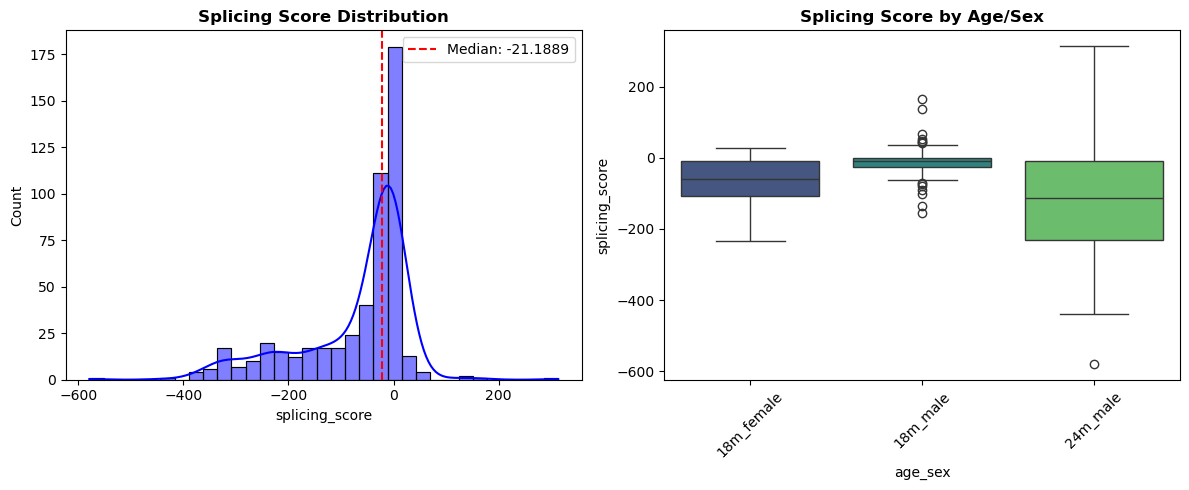

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- STEP 1: LOAD DATA ---
adata = sc.read_h5ad("Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad")

# --- STEP 2: ALIGN INDEX ---
if 'mouse_gene_symbols' in adata.var.columns:
    print("Setting index to mouse_gene_symbols to match scoring logic...")
    adata.var_names = adata.var['mouse_gene_symbols'].astype(str)
    adata.var_names_make_unique()

# --- STEP 3: LOAD SPLICING GENES ---
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

all_splicing_genes = []
for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            # Skip first line (header)
            genes_in_file = [line.strip() for line in lines[1:] if line.strip()]
            valid = [g for g in genes_in_file if g in adata.var_names]
            all_splicing_genes.extend(valid)
            print(f"{label}: Found {len(valid)} valid genes.")

all_splicing_genes = list(set(all_splicing_genes))
print(f"\nTotal unique genes for sc.tl.score_genes: {len(all_splicing_genes)}")

# --- STEP 4: CALCULATE SCORE ---
print("\nRunning sc.tl.score_genes...")
sc.tl.score_genes(adata, all_splicing_genes, score_name='splicing_score')
print("Splicing score successfully added.")

# --- STEP 5: STATS AND DIVISION ---
median_score = adata.obs['splicing_score'].median()
adata.obs['splicing_group'] = np.where(
    adata.obs['splicing_score'] > median_score, "High_Splicing", "Low_Splicing"
)

print("\n" + "="*60)
print(f"MEDIAN SPLICING SCORE: {median_score:.4f}")
print("="*60)

# Age/Sex Breakdown Table
stats = pd.crosstab(adata.obs['age_sex'], adata.obs['splicing_group'])
stats['%_Low_Splicing'] = (stats['Low_Splicing'] / stats.sum(axis=1)) * 100
print("\nBreakdown by Age/Sex (Sorted by lowest splicing machinery):")
print(stats.sort_values('%_Low_Splicing', ascending=False))

# --- STEP 6: SAVE THE NEW H5AD FILE ---
output_file = "Old_Hepatocytes_Splicing_Groups_for_VastTools.h5ad"
print(f"\nSaving updated data to: {output_file}...")
adata.write_h5ad(output_file)
print("File saved successfully.")

# --- STEP 7: PLOTTING ---
plt.figure(figsize=(12, 5))

# Plot Distribution
plt.subplot(1, 2, 1)
sns.histplot(adata.obs['splicing_score'], kde=True, color='blue')
plt.axvline(median_score, color='red', linestyle='--', label=f'Median: {median_score:.4f}')
plt.title('Splicing Score Distribution', fontweight='bold')
plt.legend()

# Plot by Age/Sex
plt.subplot(1, 2, 2)
sns.boxplot(data=adata.obs, x='age_sex', y='splicing_score', palette='viridis')
plt.xticks(rotation=45)
plt.title('Splicing Score by Age/Sex', fontweight='bold')

plt.tight_layout()
plt.show()

Setting index to mouse_gene_symbols...
Spliceosomal Complex: Found 191 valid genes.
mRNA Splicing: Found 199 valid genes.
RNA Splicing: Found 324 valid genes.

Total unique genes for scoring: 339

Running sc.tl.score_genes...

FINAL PSEUDOBULK COMPOSITION
splicing_group
Healthy_Splicing     304
Impaired_Splicing    118
Intermediate          97
Name: count, dtype: int64

Saving updated data to: Old_Hepatocytes_Extreme_Splicing_Tails.h5ad...
File saved successfully. You are ready for FASTQ export.


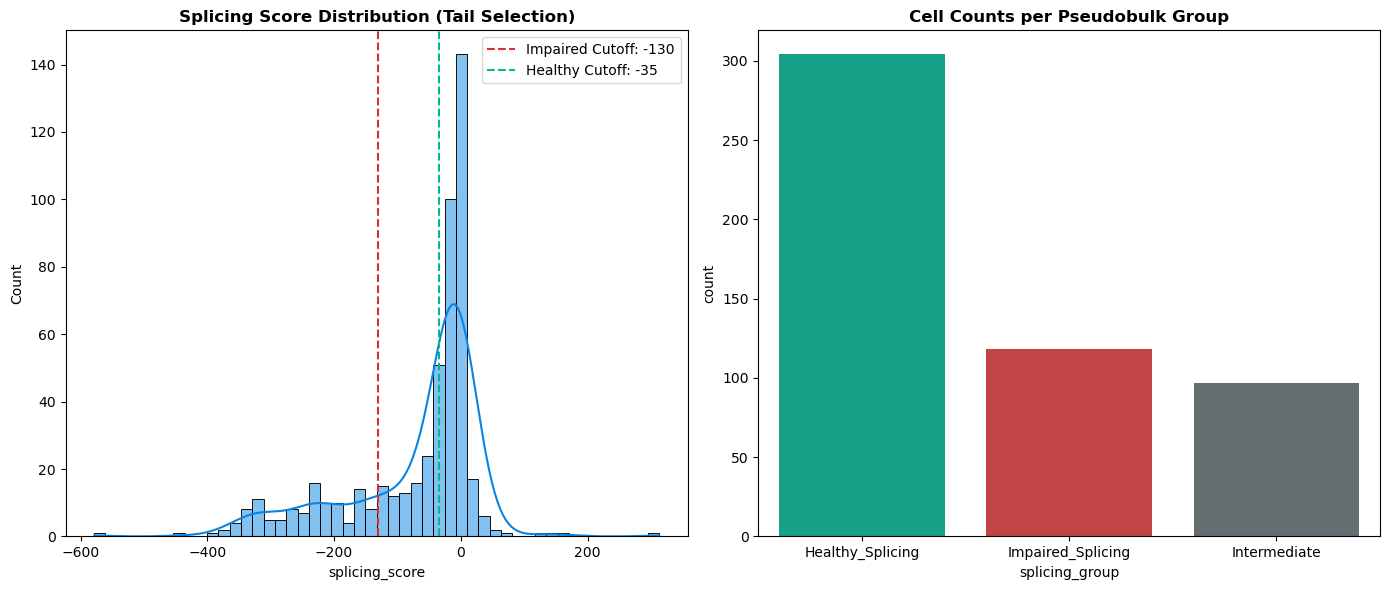

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- STEP 1: LOAD DATA ---
adata = sc.read_h5ad("Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad")

# --- STEP 2: ALIGN INDEX ---
if 'mouse_gene_symbols' in adata.var.columns:
    print("Setting index to mouse_gene_symbols...")
    adata.var_names = adata.var['mouse_gene_symbols'].astype(str)
    adata.var_names_make_unique()

# --- STEP 3: LOAD SPLICING GENES ---
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

all_splicing_genes = []
for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            # Assumes 1st line is header
            genes_in_file = [line.strip() for line in lines[1:] if line.strip()]
            valid = [g for g in genes_in_file if g in adata.var_names]
            all_splicing_genes.extend(valid)
            print(f"{label}: Found {len(valid)} valid genes.")

all_splicing_genes = list(set(all_splicing_genes))
print(f"\nTotal unique genes for scoring: {len(all_splicing_genes)}")

# --- STEP 4: CALCULATE SPLICING MACHINERY SCORE ---
print("\nRunning sc.tl.score_genes...")
sc.tl.score_genes(adata, all_splicing_genes, score_name='splicing_score')

# --- STEP 5: DEFINE EXTREME TAIL GROUPS ---
low_threshold = -130  
high_threshold = -35   

def assign_group(score):
    if score <= low_threshold:
        return "Impaired_Splicing"
    elif score >= high_threshold:
        return "Healthy_Splicing"
    else:
        return "Intermediate"

adata.obs['splicing_group'] = adata.obs['splicing_score'].apply(assign_group)

# --- STEP 6: EVALUATE RESOLUTION ---
print("\n" + "="*60)
print("FINAL PSEUDOBULK COMPOSITION")
print("="*60)
counts = adata.obs['splicing_group'].value_counts()
print(counts)
print("="*60)

# --- STEP 7: SAVE THE FINAL H5AD FILE ---
output_file = "Old_Hepatocytes_Extreme_Splicing_Tails.h5ad"
print(f"\nSaving updated data to: {output_file}...")
adata.write_h5ad(output_file)
print("File saved successfully. You are ready for FASTQ export.")

# --- STEP 8: PLOTTING FOR VERIFICATION ---
plt.figure(figsize=(14, 6))

# Plot Distribution
plt.subplot(1, 2, 1)
sns.histplot(adata.obs['splicing_score'], kde=True, color='#0984e3', bins=50)
plt.axvline(low_threshold, color='#d63031', linestyle='--', label=f'Impaired Cutoff: {low_threshold}')
plt.axvline(high_threshold, color='#00b894', linestyle='--', label=f'Healthy Cutoff: {high_threshold}')
plt.title('Splicing Score Distribution (Tail Selection)', fontweight='bold')
plt.legend()

# Plot Counts
plt.subplot(1, 2, 2)
sns.countplot(
    data=adata.obs, 
    x='splicing_group', 
    hue='splicing_group', 
    legend=False,
    palette={'Impaired_Splicing': '#d63031', 'Healthy_Splicing': '#00b894', 'Intermediate': '#636e72'}
)
plt.title('Cell Counts per Pseudobulk Group', fontweight='bold')

plt.tight_layout()
plt.show()

Loading AnnData...
Setting index to mouse_gene_symbols...
Total unique genes for scoring: 339
Running sc.tl.score_genes...

CELL COUNT SUMMARY
Total cells: 18 months = 274, 24 months = 245
Total valid cells analyzed: 519

Splicing Group Breakdown by Age:
age                18m  24m
splicing_group             
Healthy_Splicing   216   88
Impaired_Splicing    6  112
Intermediate        52   45


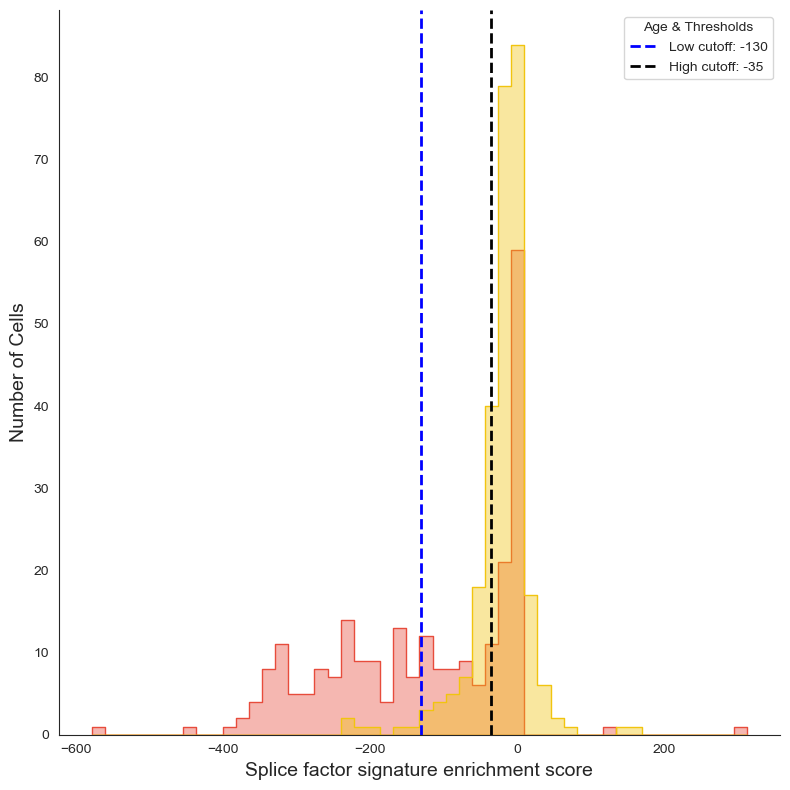

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# =============================================================================
# --- STEP 1: LOAD DATA ---
# =============================================================================
print("Loading AnnData...")
adata = sc.read_h5ad("Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad")

# =============================================================================
# --- STEP 2: ALIGN INDEX TO GENE SYMBOLS ---
# =============================================================================
if 'mouse_gene_symbols' in adata.var.columns:
    print("Setting index to mouse_gene_symbols...")
    adata.var_names = adata.var['mouse_gene_symbols'].astype(str)
    adata.var_names_make_unique()

# =============================================================================
# --- STEP 3: LOAD SPLICING MACHINERY GENES ---
# =============================================================================
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

all_splicing_genes = []
for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            genes_in_file = [line.strip() for line in lines[1:] if line.strip()]
            valid = [g for g in genes_in_file if g in adata.var_names]
            all_splicing_genes.extend(valid)

all_splicing_genes = list(set(all_splicing_genes))
print(f"Total unique genes for scoring: {len(all_splicing_genes)}")

# =============================================================================
# --- STEP 4: CALCULATE SPLICING MACHINERY SCORE ---
# =============================================================================
print("Running sc.tl.score_genes...")
sc.tl.score_genes(adata, all_splicing_genes, score_name='splicing_score')

# =============================================================================
# --- STEP 5: DEFINE EXTREME TAIL GROUPS ---
# =============================================================================
low_threshold = -130  
high_threshold = -35   

def assign_group(score):
    if score <= low_threshold:
        return "Impaired_Splicing"
    elif score >= high_threshold:
        return "Healthy_Splicing"
    else:
        return "Intermediate"

adata.obs['splicing_group'] = adata.obs['splicing_score'].apply(assign_group)

# =============================================================================
# --- STEP 6: PRODUCE SUMMARY STRING OUTPUT ---
# =============================================================================
n_18m = adata.obs[adata.obs['age'] == '18m'].shape[0]
n_24m = adata.obs[adata.obs['age'] == '24m'].shape[0]

summary_stats = (
    f"\n" + "="*50 + "\n"
    f"CELL COUNT SUMMARY\n"
    f"Total cells: 18 months = {n_18m}, 24 months = {n_24m}\n"
    f"Total valid cells analyzed: {len(adata)}\n"
    + "="*50
)
print(summary_stats)

# Detailed breakdown by group and age
breakdown = pd.crosstab(adata.obs['splicing_group'], adata.obs['age'])
print("\nSplicing Group Breakdown by Age:")
print(breakdown)

# =============================================================================
# --- STEP 7: SAVE AND PLOT ---
# =============================================================================
output_file = "Old_Hepatocytes_Extreme_Splicing_Tails.h5ad"
adata.write_h5ad(output_file)

plt.figure(figsize=(8, 8)) 
sns.set_style("white")

# Palette: 18m is Yellow, 24m is Red
age_palette = {'18m': '#f1c40f', '24m': '#e74c3c'} 
age_order = ['18m', '24m']

# Plotting the histogram (Square, despined, matched colors)
sns.histplot(
    data=adata.obs,
    x='splicing_score',
    hue='age',
    hue_order=age_order,
    palette=age_palette,
    bins=50,
    element="step",
    fill=True,
    alpha=0.4,
    common_norm=False
)

# Dashed Threshold Lines (Matched logic: Low=Blue, High=Black)
plt.axvline(low_threshold, color='blue', linestyle='--', linewidth=2, label=f'Low cutoff: {low_threshold}')
plt.axvline(high_threshold, color='black', linestyle='--', linewidth=2, label=f'High cutoff: {high_threshold}')

# Formatting
plt.xlabel("Splice factor signature enrichment score", fontsize=14)
plt.ylabel("Number of Cells", fontsize=14)
plt.legend(title="Age & Thresholds", loc='upper right', frameon=True, framealpha=0.8)

sns.despine() # Remove the top and right box lines
plt.tight_layout()
plt.savefig("Splicing_Score_Histogram_Hepatocytes.png", dpi=300)
plt.show()

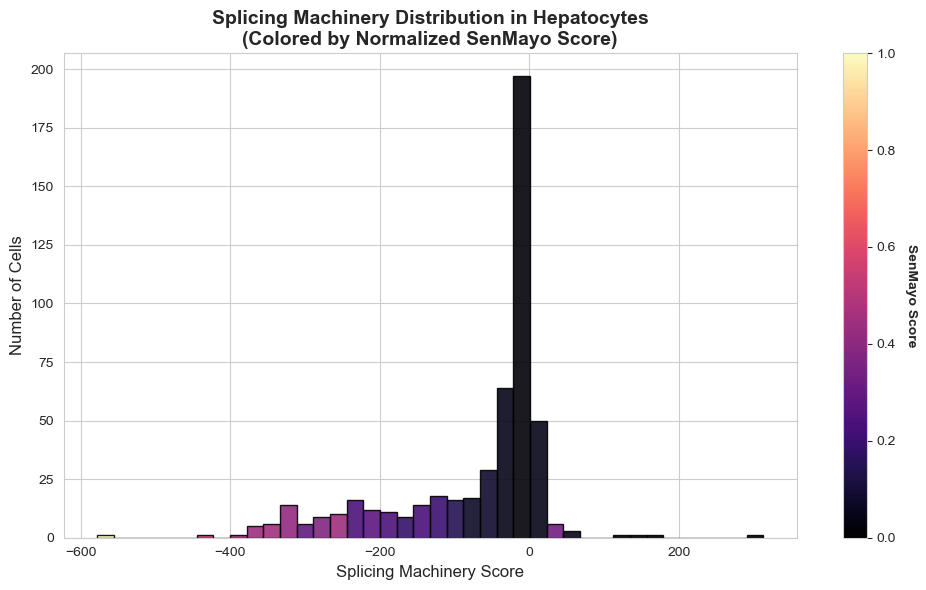

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import os

# --- STEP 1: LOAD AND SUBSET ---
adata = sc.read_h5ad("Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad")
adata_hep = adata[adata.obs['cell_ontology_class'] == 'hepatocyte'].copy()

# --- STEP 2: ALIGN GENE NAMES ---
# Critical to prevent the "No valid genes found" error
if 'mouse_gene_symbols' in adata_hep.var.columns:
    adata_hep.var_names = adata_hep.var['mouse_gene_symbols'].astype(str)
    adata_hep.var_names_make_unique()

# --- STEP 3: APPLY SPECIFIC SENMAYO NORMALIZATION ---
data_sen = adata_hep.obs['SenMayo_score'].values
vmin_val = np.percentile(data_sen, 50) 
vmax_val = np.percentile(data_sen, 99) 

if vmax_val <= vmin_val:
    vmax_val = data_sen.max()

clipped = np.clip(data_sen, vmin_val, vmax_val)
adata_hep.obs['SenMayo_norm'] = (clipped - vmin_val) / (vmax_val - vmin_val)

# --- STEP 4: LOAD SPLICING GENES AND SCORE ---
paths = ['Spliceosomal Complex.txt', 'mRNA Splicing via spliceosome.txt', 'RNA Splicing.txt']
all_splicing_genes = []

for path in paths:
    if os.path.exists(path):
        with open(path, 'r') as f:
            # Assumes 1st line is header
            genes = [line.strip() for line in f.readlines()[1:] if line.strip()]
            valid = [g for g in genes if g in adata_hep.var_names]
            all_splicing_genes.extend(valid)

all_splicing_genes = list(set(all_splicing_genes))

# Score the cells
sc.tl.score_genes(adata_hep, all_splicing_genes, score_name='splicing_score')

# --- STEP 5: PLOT COLOR-GRADED HISTOGRAM ---
plt.figure(figsize=(10, 6))

n_bins = 40
df_plot = adata_hep.obs[['splicing_score', 'SenMayo_norm']].copy()

# Calculate histogram coordinates
counts, bin_edges = np.histogram(df_plot['splicing_score'], bins=n_bins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Calculate color intensity (mean SenMayo_norm per splicing bin)
bin_colors_data = []
for i in range(len(bin_edges)-1):
    mask = (df_plot['splicing_score'] >= bin_edges[i]) & (df_plot['splicing_score'] < bin_edges[i+1])
    if mask.any():
        avg_sen_norm = df_plot.loc[mask, 'SenMayo_norm'].mean()
    else:
        avg_sen_norm = 0
    bin_colors_data.append(avg_sen_norm)

# Create color mapping
norm = colors.Normalize(vmin=0, vmax=1)
mapper = cm.ScalarMappable(norm=norm, cmap='magma')

# Plot bars
plt.bar(bin_centers, counts, width=np.diff(bin_edges), 
        color=[mapper.to_rgba(v) for v in bin_colors_data], 
        edgecolor='black', alpha=0.9)

# Formatting - (axvline and legend calls removed)
plt.title('Splicing Machinery Distribution in Hepatocytes\n(Colored by Normalized SenMayo Score)', fontsize=14, fontweight='bold')
plt.xlabel('Splicing Machinery Score', fontsize=12)
plt.ylabel('Number of Cells', fontsize=12)

# Add Colorbar to explain the grading
cbar = plt.colorbar(mapper, ax=plt.gca())
cbar.set_label('SenMayo Score', rotation=270, labelpad=15, fontweight='bold')

plt.tight_layout()
plt.show()

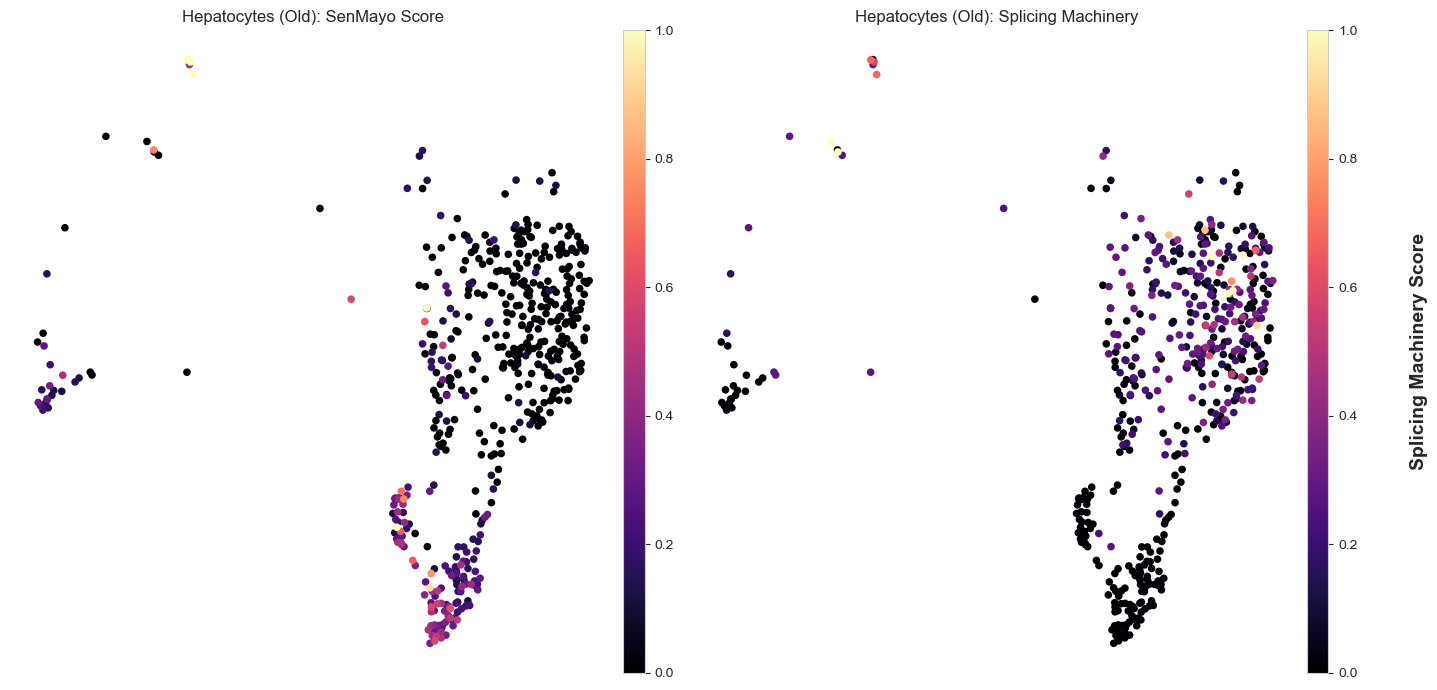

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# --- STEP 1: DATA LOADING & SUBSETTING ---
adata = sc.read_h5ad("Old_Hepatocytes_Senescence_Groups_for_VastTools.h5ad")
# Isolate Hepatocytes
adata_hep = adata[adata.obs['cell_ontology_class'] == 'hepatocyte'].copy()

# --- STEP 2: GENE NAME ALIGNMENT ---
if 'mouse_gene_symbols' in adata_hep.var.columns:
    adata_hep.var_names = adata_hep.var['mouse_gene_symbols'].astype(str)
    adata_hep.var_names_make_unique()

# --- STEP 3: SCORE SPLICING MACHINERY ---
paths = ['Spliceosomal Complex.txt', 'mRNA Splicing via spliceosome.txt', 'RNA Splicing.txt']
all_splicing_genes = []
for path in paths:
    if os.path.exists(path):
        with open(path, 'r') as f:
            genes = [line.strip() for line in f.readlines()[1:] if line.strip()]
            valid = [g for g in genes if g in adata_hep.var_names]
            all_splicing_genes.extend(valid)

all_splicing_genes = list(set(all_splicing_genes))
sc.tl.score_genes(adata_hep, all_splicing_genes, score_name='splicing_score')

# --- STEP 4: APPLY 50-99% NORMALIZATION ---
def normalize_score(adata_obj, column_name, new_name):
    data = adata_obj.obs[column_name].values
    vmin = np.percentile(data, 50)
    vmax = np.percentile(data, 99)
    if vmax <= vmin: vmax = data.max()
    clipped = np.clip(data, vmin, vmax)
    adata_obj.obs[new_name] = (clipped - vmin) / (vmax - vmin)

normalize_score(adata_hep, 'SenMayo_score', 'SenMayo_norm')
normalize_score(adata_hep, 'splicing_score', 'splicing_norm')

# --- STEP 5: FILTER FOR OLD CELLS ---
# Only taking cells from 18m and 24m
adata_old = adata_hep[adata_hep.obs['age'].isin(['18m', '24m'])].copy()

# --- STEP 6: SIDE-BY-SIDE PLOTTING ---
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
dot_size = 120

# Plot 1: SenMayo Score (Left)
sc.pl.umap(
    adata_old, 
    color='SenMayo_norm', 
    ax=axes[0], 
    show=False, 
    cmap='magma', 
    size=dot_size, 
    vmin=0, 
    vmax=1, 
    frameon=False, 
    title='Hepatocytes (Old): SenMayo Score'
)

# Plot 2: Splicing Machinery Score (Right)
sc.pl.umap(
    adata_old, 
    color='splicing_norm', 
    ax=axes[1], 
    show=False, 
    cmap='magma', 
    size=dot_size, 
    vmin=0, 
    vmax=1, 
    frameon=False, 
    title='Hepatocytes (Old): Splicing Machinery'
)

# --- STEP 7: VERTICAL LABEL FOR SPLICING ON THE FAR RIGHT ---
axes[1].text(
    1.18, 0.5, 'Splicing Machinery Score', 
    rotation=90, 
    va='center', 
    ha='left', 
    transform=axes[1].transAxes, 
    fontsize=14, 
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

---

GSEA for connections between the important points: 

The "Splicing-Driven" GSEA
You can do the same thing but rank all genes by their correlation with your Splicing Score.
The Goal: Does the health of the splicing machinery dictate the health of the entire hepatocyte?

Regardless of splicing fidelity, which biological pathways in the cell live or die based on the status of the splicing machinery?"

Unlike standard GSEA (which calculates a signal-to-noise ratio from expression data), Preranked GSEA trusts your ranking completely.
The algorithm crawls down your list (from highest ΔΨ to lowest).
It asks: "Are the genes belonging to 'Fatty Acid Metabolism' appearing randomly throughout the list, or are they all crowded at the very top?"
If the "Metabolism" genes are all clustered at the top (the "Most Broken" end), the pathway receives a high Enrichment Score (ES).

Loading AnnData with Splicing Scores...
Calculating Spearman correlations for 19559 genes vs Splicing Score...


C:\Users\lukas\AppData\Local\Temp\ipykernel_31616\3785094560.py:51: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, _ = spearmanr(expr, splicing_score)


Ranking Complete. Top Gene: FTH1 (Strongly coupled with Splicing)
Bottom Gene: GPLD1 (Strongly anti-correlated)


2026-06-05 17:54:48,010 [WARNING] Duplicated values found in preranked stats: 6.87% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Running Splicing-Driven GSEA Prerank...

                 PATHWAYS TIED TO SPLICING MACHINERY INTEGRITY                  


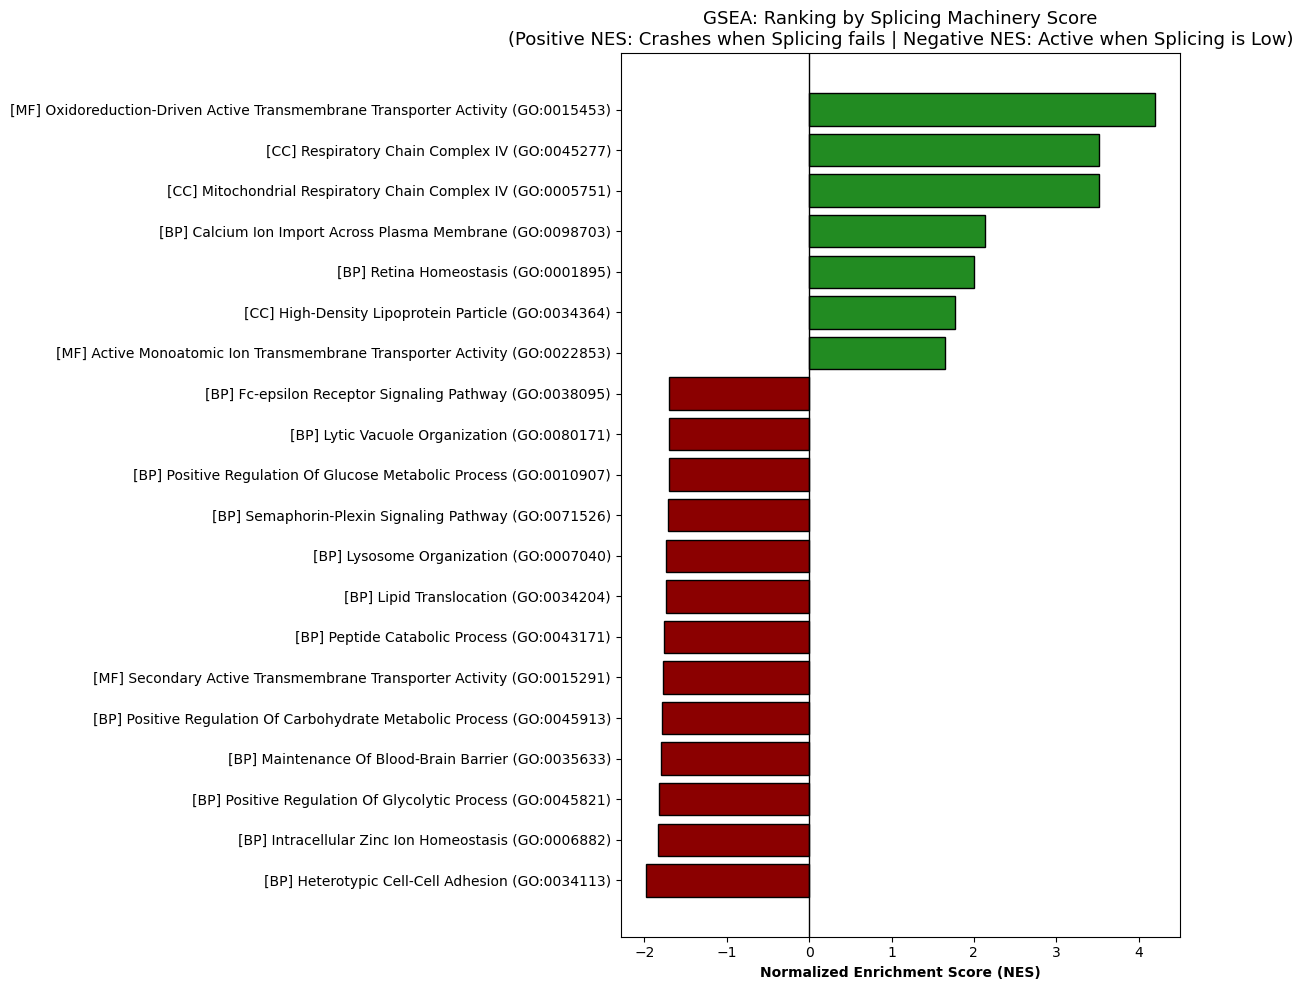


Significant Functional Shifts Found:
                                                                   term       nes fdr_q_val
     [BP] Positive Regulation Of Glucose Metabolic Process (GO:0010907) -1.702671  0.041686
[BP] Positive Regulation Of Carbohydrate Metabolic Process (GO:0045913) -1.786856  0.017561


In [ ]:
import scanpy as sc
import gseapy as gp
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# =============================================================================
# 1. HELPERS: GMT DOWNLOAD
# =============================================================================
def fetch_enrichr_gmt(library_name):
    print(f"  Downloading {library_name}...")
    url = f"https://maayanlab.cloud/Enrichr/geneSetLibrary?mode=text&libraryName={library_name}"
    response = requests.get(url)
    if response.status_code != 200: raise Exception(f"Could not fetch {library_name}")
    gmt_dict = {}
    for line in response.text.strip().split('\n'):
        parts = line.split('\t')
        gmt_dict[parts[0]] = [g.split(',')[0].upper() for g in parts[2:] if g]
    return gmt_dict

# =============================================================================
# 2. LOAD DATA (Use the file with the Splicing Score already added)
# =============================================================================
print("Loading AnnData with Splicing Scores...")
# This is the file we saved in the previous step
adata = sc.read_h5ad("Old_Hepatocytes_Splicing_Groups_for_VastTools.h5ad")

# Ensure index is Gene Symbols and Uppercase
if 'mouse_gene_symbols' in adata.var.columns:
    adata.var_names = adata.var['mouse_gene_symbols'].astype(str)
    adata.var_names_make_unique()
adata.var_names = adata.var_names.str.upper()

# =============================================================================
# 3. RANK GENES BY SPLICING SCORE CORRELATION
# =============================================================================
# We are correlating all genes against the 'splicing_score' column
print(f"Calculating Spearman correlations for {adata.n_vars} genes vs Splicing Score...")
splicing_score = adata.obs['splicing_score'].values
genes = adata.var_names.tolist()
correlations = []

for gene in genes:
    expr = adata[:, gene].X
    expr = expr.toarray().flatten() if hasattr(expr, "toarray") else expr.flatten()
    
    # Rho > 0: Gene is expressed when Splicing is High
    # Rho < 0: Gene is expressed when Splicing is Low (Stress Response)
    rho, _ = spearmanr(expr, splicing_score)
    correlations.append(rho)

ranking = pd.DataFrame({'gene': genes, 'rho': correlations})
ranking = ranking.dropna().sort_values('rho', ascending=False)
rank_list = ranking[['gene', 'rho']]

print(f"Ranking Complete. Top Gene: {ranking.iloc[0]['gene']} (Strongly coupled with Splicing)")
print(f"Bottom Gene: {ranking.iloc[-1]['gene']} (Strongly anti-correlated)")

# =============================================================================
# 4. DOWNLOAD GO LIBRARIES
# =============================================================================
libraries = ["GO_Biological_Process_2023", "GO_Molecular_Function_2023", "GO_Cellular_Component_2023"]
combined_gmt = {}
for lib in libraries:
    try:
        data = fetch_enrichr_gmt(lib)
        prefix = "BP" if "Biological" in lib else "MF" if "Molecular" in lib else "CC"
        combined_gmt.update({f"[{prefix}] {k}": v for k, v in data.items()})
    except Exception as e:
        print(f"  Warning: Failed to load {lib}: {e}")

# =============================================================================
# 5. RUN GSEA PRERANK
# =============================================================================
print(f"Running Splicing-Driven GSEA Prerank...")
pre_res = gp.prerank(rnk=rank_list,
                     gene_sets=combined_gmt,
                     threads=4,
                     min_size=15,
                     max_size=500,
                     permutation_num=200, 
                     outdir=None,
                     seed=42)

# =============================================================================
# 6. PROCESS RESULTS (Column Normalization to fix KeyErrors)
# =============================================================================
res = pre_res.res2d
res.columns = [c.replace(" ", "_").replace("-", "_").lower() for c in res.columns]

# Significance filter
res_sig = res[res['fdr_q_val'] < 0.05].sort_values('nes', ascending=False)

# =============================================================================
# 7. VISUALIZATION
# =============================================================================
print("\n" + "="*80)
print(f"{'PATHWAYS TIED TO SPLICING MACHINERY INTEGRITY':^80}")
print("="*80)

if not res_sig.empty:
    # Plot top 10 and bottom 10
    top_bottom = pd.concat([res_sig.head(10), res_sig.tail(10)])
    colors = ['#228b22' if x > 0 else '#8b0000' for x in top_bottom['nes']] # Green for positive, Maroon for negative
    
    plt.figure(figsize=(12, 10))
    plt.barh(top_bottom['term'], top_bottom['nes'], color=colors, edgecolor='black')
    plt.axvline(0, color='black', linewidth=1)
    plt.xlabel('Normalized Enrichment Score (NES)', fontweight='bold')
    plt.title('GSEA: Ranking by Splicing Machinery Score\n(Positive NES: Crashes when Splicing fails | Negative NES: Active when Splicing is Low)', fontsize=13)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

    # Look for Metabolic or Stress terms
    interesting_terms = res_sig[res_sig['term'].str.contains('METABOLIC|STRESS|FOLDING|OXIDATIVE', case=False)]
    if not interesting_terms.empty:
        print("\nSignificant Functional Shifts Found:")
        print(interesting_terms[['term', 'nes', 'fdr_q_val']].head(10).to_string(index=False))
else:
    print("\nNo significant pathways found. Try 1000 permutations.")

# =============================================================================
# 8. SAVE
# =============================================================================
#ranking.to_csv("SplicingScore_Spearman_Rankings.csv", index=False)
#res.to_csv("GSEA_SplicingScore_Spectrum_Results.csv", index=False)
#print("\nSplicing-driven GSEA results saved.")

---

FOR HIGH VS LOW EXPRESSION OF GENES ASSOCIATED WITH SPLICING BASED ON THE MEDIAN

instead of HIGH VS LOW senmayo senescent score

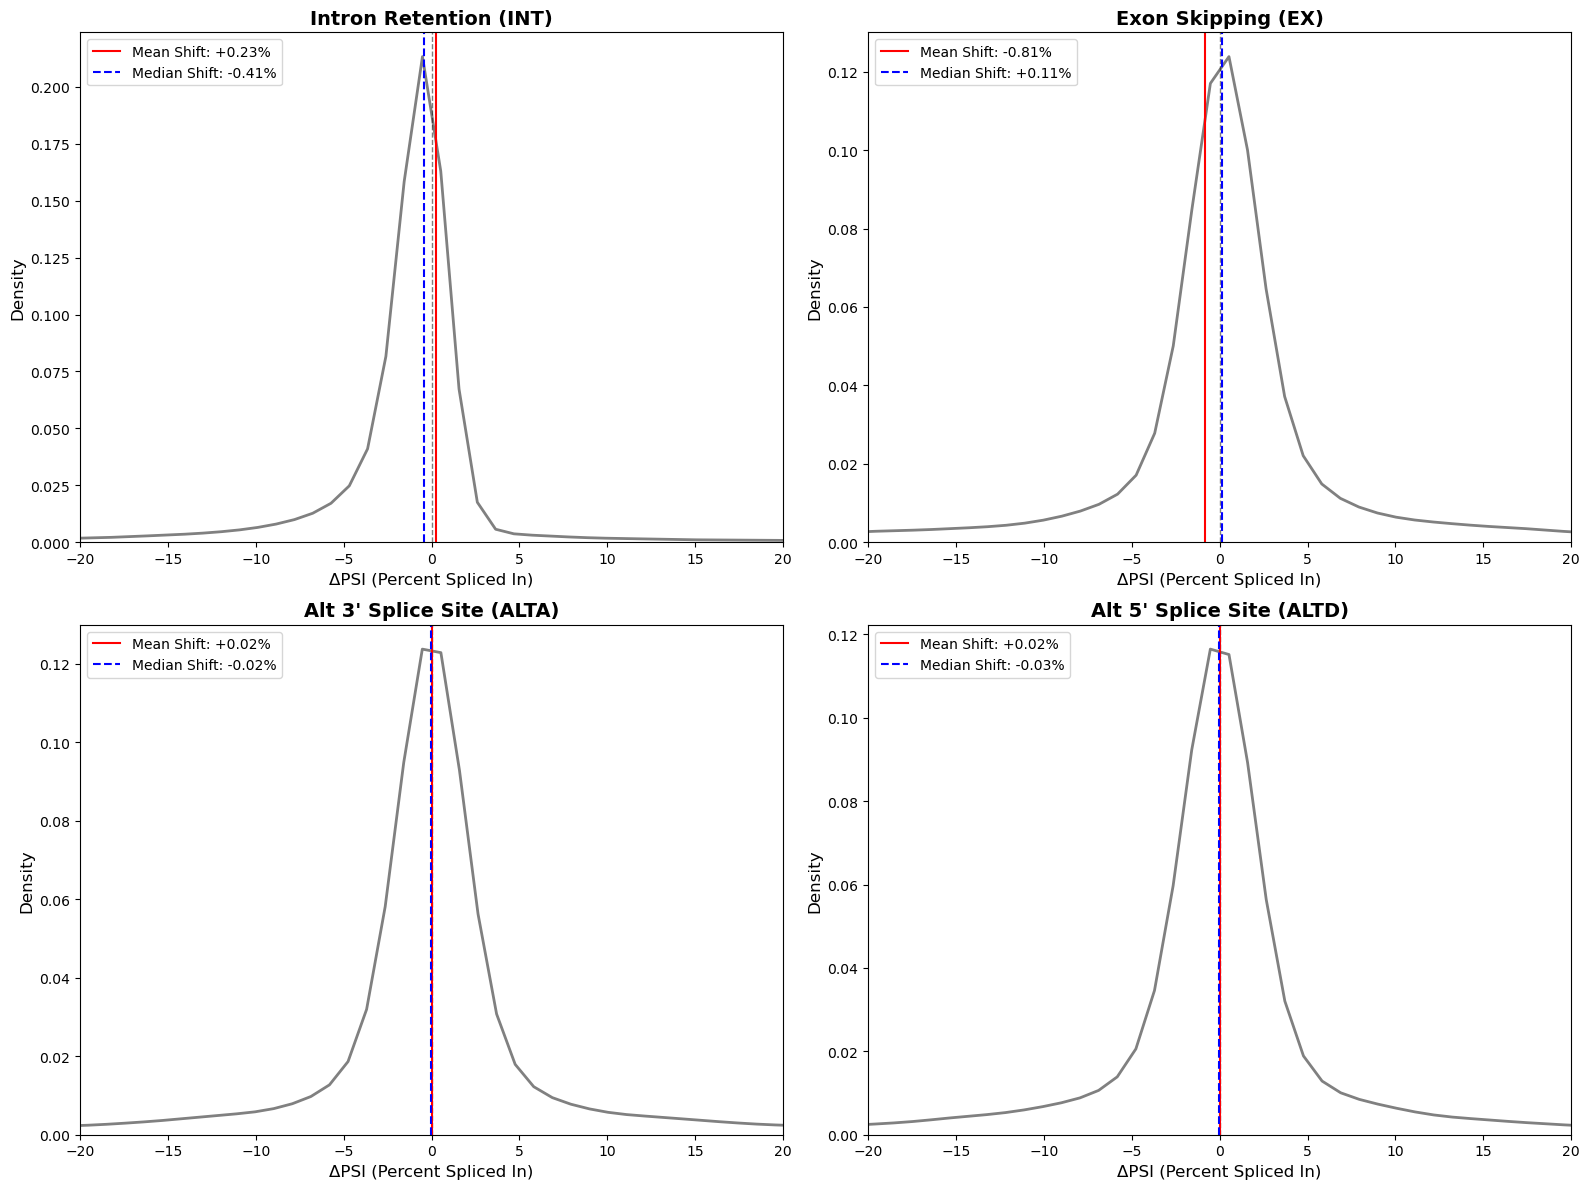


Summary for: INCLUSION_LEVELS_FULL-mm10-2_splicing.tab (ΔPSI ≠ 0)
Event Type           | Count    | Mean       | Median     | Ratio
---------------------------------------------------------------------------
Intron Retention     | 38915    |     +0.23% |     -0.41% | 0.14x
Exon Skipping        | 16506    |     -0.81% |     +0.11% | 1.58x
Alt 3' Splice Site   | 16063    |     +0.02% |     -0.02% | 0.92x
Alt 5' Splice Site   | 11846    |     +0.02% |     -0.03% | 0.89x


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD AND CLEAN DATA
filename = "INCLUSION_LEVELS_FULL-mm10-2_splicing.tab"
df_full = pd.read_csv(filename, sep='\t')

# Columns: High_Splicing (Healthy), Low_Splicing (Impaired)
cols_to_use = ['High_Splicing', 'Low_Splicing']

for col in cols_to_use:
    df_full[col] = pd.to_numeric(df_full[col], errors='coerce')

# Remove rows where splicing values are NA
df_full = df_full.dropna(subset=cols_to_use)

# Calculate dPSI (Delta Percent Spliced In)
# High - Low results in positive values if machinery causes less inclusion
# Note: Usually we do Low - High to see "increased failure" as positive. 
# I will keep High - Low as per your snippet, but the median will now be non-zero.
df_full['dPSI'] = df_full['High_Splicing'] - df_full['Low_Splicing']

# FILTER: Remove exact 0s to calculate a realistic median for events that actually shifted
df_active = df_full[df_full['dPSI'] != 0].copy()

# 2. DEFINE EVENT TYPES
event_map = {
    'INT': 'Intron Retention',
    'EX': 'Exon Skipping',
    'ALTA': 'Alt 3\' Splice Site',
    'ALTD': 'Alt 5\' Splice Site'
}

# 3. LOOP AND PLOT
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

if df_active.empty:
    print("Error: No non-zero numeric data available to plot.")
else:
    for i, (code, label) in enumerate(event_map.items()):
        # Filter for the specific event type from the ACTIVE (non-zero) data
        subset = df_active[df_active['EVENT'].str.contains(code, na=False)].copy()
        
        if len(subset) == 0:
            axes[i].set_title(f'{label} ({code})\n[No Change Events Found]', fontsize=14)
            continue
            
        mean_shift = subset['dPSI'].mean()
        median_shift = subset['dPSI'].median()
        
        # Continuous distribution: Grey line only (KDE)
        sns.kdeplot(subset['dPSI'], ax=axes[i], color="grey", linewidth=2, bw_adjust=0.5)
        
        # Zero Reference Line (Black dashed)
        axes[i].axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)
        
        # Mean Line (Red solid)
        axes[i].axvline(mean_shift, color='red', linestyle='-', 
                        label=f'Mean Shift: {mean_shift:+.2f}%')
        
        # Median Line (Blue dashed)
        axes[i].axvline(median_shift, color='blue', linestyle='--', 
                        label=f'Median Shift: {median_shift:+.2f}%')
        
        # Titles and Axis Labels
        axes[i].set_title(f'{label} ({code})', fontsize=14, fontweight='bold')
        axes[i].set_xlabel('ΔPSI (Percent Spliced In)', fontsize=12)
        axes[i].set_ylabel('Density', fontsize=12)
        
        # X-Axis Limit: Focused on -20 to +20
        axes[i].set_xlim(-20, 20) 
        axes[i].legend(loc='upper left')

    plt.tight_layout()
    plt.show()

    # 4. PRINT SUMMARY (of filtered events)
    print(f"\nSummary for: {filename} (ΔPSI ≠ 0)")
    print(f"{'Event Type':<20} | {'Count':<8} | {'Mean':<10} | {'Median':<10} | {'Ratio'}")
    print("-" * 75)
    for code, label in event_map.items():
        subset = df_active[df_active['EVENT'].str.contains(code, na=False)]
        if len(subset) == 0: continue
        
        mean_s = subset['dPSI'].mean()
        med_s = subset['dPSI'].median()
        
        up = (subset['dPSI'] > 0).sum()
        down = (subset['dPSI'] < 0).sum()
        r = up/down if down > 0 else np.inf
        
        print(f"{label:<20} | {len(subset):<8} | {mean_s:>+9.2f}% | {med_s:>+9.2f}% | {r:.2f}x")

C:\Users\lukas\AppData\Local\Temp\ipykernel_24908\2645756604.py:89: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


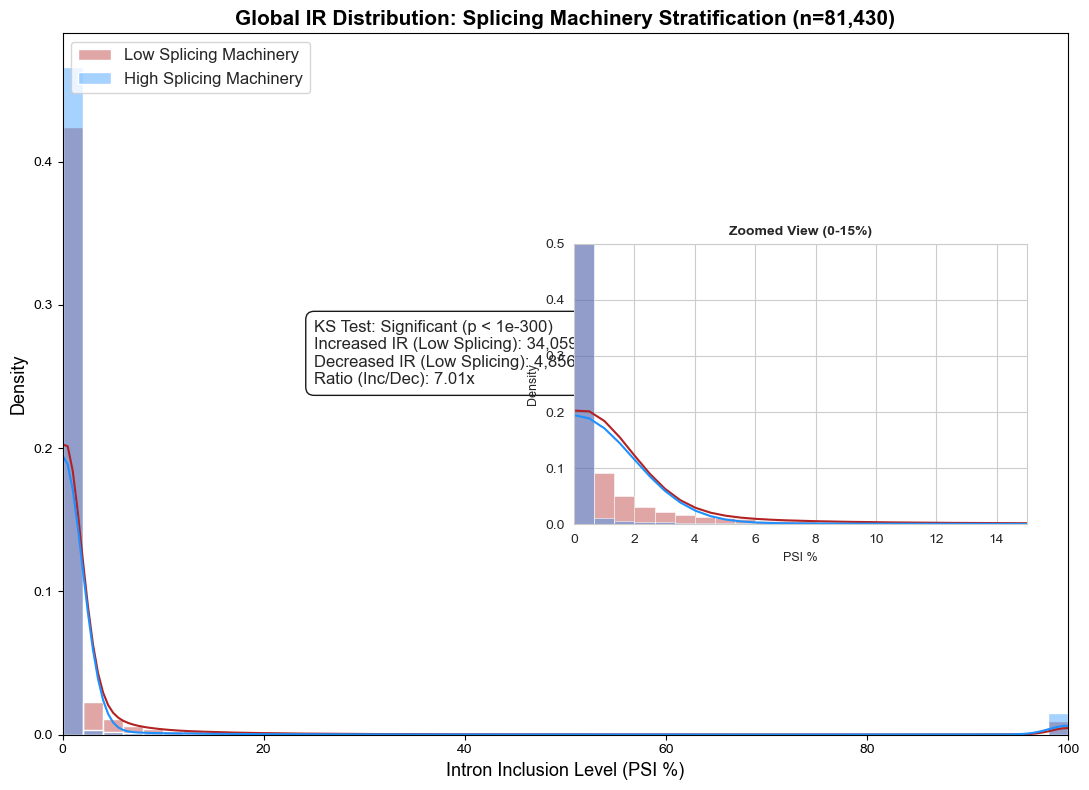

Analysis complete.
KS p-value: 0.0
Hepatocytes with low splicing machinery show 7.01x more increased retention than decreased.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# 1. LOAD AND PREPARE
# Using your splicing-specific pseudo-bulk file
full_file = "INCLUSION_LEVELS_FULL-mm10-2_splicing.tab"
df_full = pd.read_csv(full_file, sep='\t')

# Filter strictly for Intron Retention
df_ir = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()

# Identify the groups from your file structure
# High_Splicing = Healthy Machinery | Low_Splicing = Depleted Machinery
samples = ['High_Splicing', 'Low_Splicing']

for s in samples:
    df_ir[s] = pd.to_numeric(df_ir[s], errors='coerce')

# Drop rows where data is missing in either group
df_ir = df_ir.dropna(subset=samples)

# Directional dPSI: Positive means MORE retention when splicing genes are LOW
df_ir['dPSI'] = df_ir['Low_Splicing'] - df_ir['High_Splicing']

# 2. STATISTICAL TEST (Comparing the two distributions)
ks_stat, p_value = ks_2samp(df_ir['Low_Splicing'], df_ir['High_Splicing'])

# Handle Underflow for the legend
if p_value == 0 or p_value < 1e-300:
    p_val_display = "Significant (p < 1e-300)"
else:
    p_val_display = f"p = {p_value:.2e}"

# 3. VISUALIZATION
fig, ax = plt.subplots(figsize=(11, 8))
sns.set_style("whitegrid")

# Main plot distributions
# High Splicing = Blue (Healthy), Low Splicing = Red (Aged-like)
sns.histplot(df_ir['Low_Splicing'], color="firebrick", label="Low Splicing Machinery", 
             kde=True, stat="density", alpha=0.4, bins=50, ax=ax)
sns.histplot(df_ir['High_Splicing'], color="dodgerblue", label="High Splicing Machinery", 
             kde=True, stat="density", alpha=0.4, bins=50, ax=ax)

# --- INSET START (Zooming in on the 0-15% PSI range where most changes occur) ---
ax_ins = inset_axes(ax, width="45%", height="40%", loc='center right', borderpad=3)

sns.histplot(df_ir['Low_Splicing'], color="firebrick", kde=True, 
             stat="density", alpha=0.4, bins=150, ax=ax_ins, label='_nolegend_')
sns.histplot(df_ir['High_Splicing'], color="dodgerblue", kde=True, 
             stat="density", alpha=0.4, bins=150, ax=ax_ins, label='_nolegend_')

# Zoomed constraints
ax_ins.set_xlim(0, 15)      
ax_ins.set_ylim(0, 0.5)     
ax_ins.set_title('Zoomed View (0-15%)', fontsize=10, fontweight='bold')
ax_ins.set_xlabel('PSI %', fontsize=9)
ax_ins.set_ylabel('Density', fontsize=9)
# --- INSET END ---

# 4. ADD ANNOTATION & LABELS
ax.set_title(f'Global IR Distribution: Splicing Machinery Stratification (n={len(df_ir):,})', 
             fontsize=15, fontweight='bold')
ax.set_xlabel('Intron Inclusion Level (PSI %)', fontsize=13)
ax.set_ylabel('Density', fontsize=13)
ax.set_xlim(0, 100)

# Calculate stats
inc = (df_ir['dPSI'] > 0).sum()
dec = (df_ir['dPSI'] < 0).sum()
ratio = inc/dec if dec > 0 else np.inf

# Text box logic
stats_text = (
    f"KS Test: {p_val_display}\n"
    f"Increased IR (Low Splicing): {inc:,}\n"
    f"Decreased IR (Low Splicing): {dec:,}\n"
    f"Ratio (Inc/Dec): {ratio:.2f}x"
)

ax.text(25, ax.get_ylim()[1]*0.5, stats_text, fontsize=12, 
         bbox=dict(facecolor='white', alpha=0.9, edgecolor='black', boxstyle='round,pad=0.5'))

ax.legend(loc='upper left', fontsize=12)
plt.tight_layout()
plt.show()

print(f"Analysis complete.")
print(f"KS p-value: {p_value}")
print(f"Hepatocytes with low splicing machinery show {ratio:.2f}x more increased retention than decreased.")

---

I compared intron retention events between the two pseudo-bulk analysis. In order to check if the intron retention profile of high senescent hepatocytes was similar to the one of low expressed splicing associated genes hepatocytes. Knowing that senescent cells express downregulated splicing genes.

-The Hypergeometric Test is the gold standard in bioinformatics for determining if an "overlap" between two groups is statistically significant or if it just happened by pure chance.

top right quadrant events are introns retained by high senescent and lowly expressed hepatocytes.

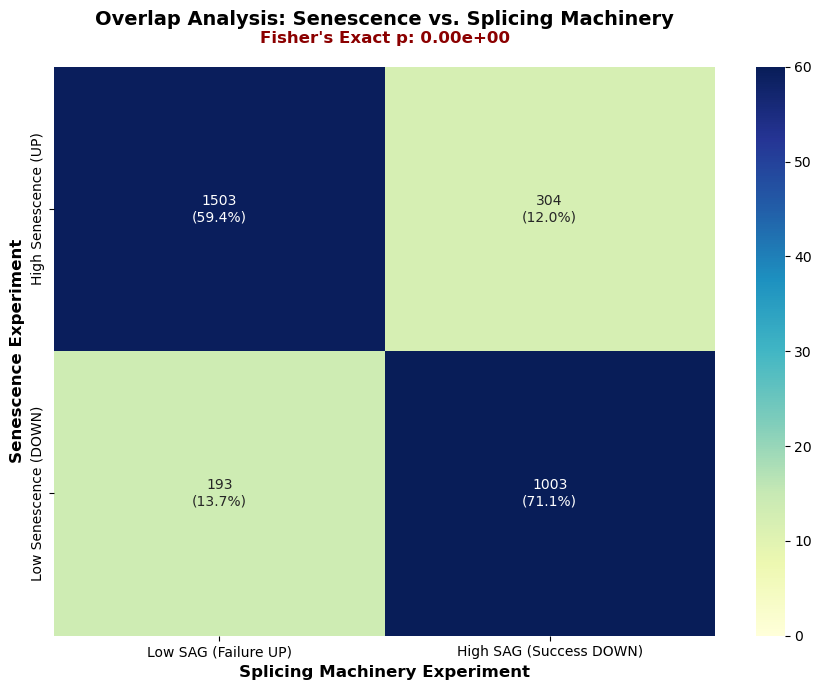

--- Fisher's Exact Test Results ---
Universe Size: 76,418 introns
Shared Failure (Top-Left): 1503 events
P-value: 0.00e+00
Interpretation: The overlap is highly significant. Senescence mirrors machinery loss.
Total Introns in Senescence file: 84266
Total Introns in Splicing file: 81430
Number of shared Intron events (Universe): 76418


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import fisher_exact

# 1. LOAD AND PREPROCESS
file_sen = 'INCLUSION_LEVELS_FULL-mm10-2.tab'
file_spl = 'INCLUSION_LEVELS_FULL-mm10-2_splicing.tab'

def load_and_clean(path, col1, col2, suffix):
    df = pd.read_csv(path, sep='\t')
    df = df[df['EVENT'].str.contains('INT', na=False)].copy()
    df[col1] = pd.to_numeric(df[col1], errors='coerce')
    df[col2] = pd.to_numeric(df[col2], errors='coerce')
    df = df.dropna(subset=[col1, col2])
    if 'Sen' in suffix:
        df['dPSI'] = (df[col1] - df[col2]) / 100
    else:
        df['dPSI'] = (df[col2] - df[col1]) / 100
    return df[['EVENT', 'dPSI']]

df_sen = load_and_clean(file_sen, 'High_Senescence', 'Low_Senescence', 'Sen')
df_spl = load_and_clean(file_spl, 'High_Splicing', 'Low_Splicing', 'Spl')

# Define Universe: Introns quantified in BOTH datasets
universe = set(df_sen['EVENT']).intersection(set(df_spl['EVENT']))
universe_size = len(universe)

# 2. DEFINE THE CORE SETS
threshold = 0.1
sen_up = set(df_sen[df_sen['dPSI'] > threshold]['EVENT']).intersection(universe)
sen_down = set(df_sen[df_sen['dPSI'] < -threshold]['EVENT']).intersection(universe)

spl_up = set(df_spl[df_spl['dPSI'] > threshold]['EVENT']).intersection(universe)
spl_down = set(df_spl[df_spl['dPSI'] < -threshold]['EVENT']).intersection(universe)

sen_sets = {"High Senescence (UP)": sen_up, "Low Senescence (DOWN)": sen_down}
spl_sets = {"Low SAG (Failure UP)": spl_up, "High SAG (Success DOWN)": spl_down}

# 3. CALCULATE THE 2x2 OVERLAP & FISHER TEST
rows = list(sen_sets.keys())
cols = list(spl_sets.keys())

matrix_pct = np.zeros((2, 2))
matrix_counts = np.zeros((2, 2), dtype=int)

for i, r_name in enumerate(rows):
    for j, c_name in enumerate(cols):
        intersection = len(sen_sets[r_name].intersection(spl_sets[c_name]))
        matrix_counts[i, j] = intersection
        matrix_pct[i, j] = (intersection / len(sen_sets[r_name])) * 100

# Perform Fisher's Exact Test for the "Mirror" (Top-Left Box)
# Table: [[Both Failed, Only Sen Failed], [Only Spl Failed, Neither Failed]]
a = matrix_counts[0, 0]
b = len(sen_up) - a
c = len(spl_up) - a
d = universe_size - (a + b + c)

odds_ratio, p_value = fisher_exact([[a, b], [c, d]], alternative='greater')

# 4. PLOTTING
plt.figure(figsize=(9, 7))

annot_matrix = []
for i in range(2):
    row_annot = []
    for j in range(2):
        row_annot.append(f"{matrix_counts[i,j]}\n({matrix_pct[i,j]:.1f}%)")
    annot_matrix.append(row_annot)

sns.heatmap(matrix_pct, annot=annot_matrix, fmt="", cmap="YlGnBu", 
            xticklabels=cols, yticklabels=rows, vmin=0, vmax=60)

# Add p-value annotation to the plot
plt.text(1, -0.1, f"Fisher's Exact p: {p_value:.2e}", 
         ha='center', va='center', fontsize=12, fontweight='bold', color='darkred')

plt.title("Overlap Analysis: Senescence vs. Splicing Machinery", fontsize=14, fontweight='bold', pad=30)
plt.xlabel("Splicing Machinery Experiment", fontsize=12, fontweight='bold')
plt.ylabel("Senescence Experiment", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# 5. THESIS SUMMARY OUTPUT
print(f"--- Fisher's Exact Test Results ---")
print(f"Universe Size: {universe_size:,} introns")
print(f"Shared Failure (Top-Left): {matrix_counts[0,0]} events")
print(f"P-value: {p_value:.2e}")
if p_value < 0.05:
    print("Interpretation: The overlap is highly significant. Senescence mirrors machinery loss.")

print(f"Total Introns in Senescence file: {len(df_sen)}")
print(f"Total Introns in Splicing file: {len(df_spl)}")
print(f"Number of shared Intron events (Universe): {universe_size}")

---

GSEA ranked by the delta PSI. 

Of the genes that are both lowly expressed and expressed in high senescent cells, which biological functions do they belong to, and which functions are the most 'shattered'? 

Basically where is the splicing machinery physically failing?

Pathways ranked at the top of the GSEA represent functional domains of the transcriptome that are most vulnerable to splicing failure. A high enrichment score indicates that genes within these pathways (e.g., cell cycle regulation or structural integrity) undergo a coordinated increase in Intron Retention. This suggest a 'functional collapse' where, despite being transcribed, the resulting mRNA is structurally defective, likely leading to a loss of protein synthesis for those critical cellular processes.

In [ ]:
import pandas as pd
import gseapy as gp
import matplotlib.pyplot as plt
import requests
import numpy as np

# =============================================================================
# 1. HELPERS: GMT DOWNLOAD
# =============================================================================
def fetch_enrichr_gmt(library_name):
    print(f"  Downloading {library_name}...")
    url = f"https://maayanlab.cloud/Enrichr/geneSetLibrary?mode=text&libraryName={library_name}"
    response = requests.get(url)
    if response.status_code != 200: raise Exception(f"Could not fetch {library_name}")
    gmt_dict = {}
    for line in response.text.strip().split('\n'):
        parts = line.split('\t')
        if len(parts) > 2:
            gmt_dict[parts[0]] = [g.split(',')[0].upper() for g in parts[2:] if g]
    return gmt_dict

# =============================================================================
# 2. LOAD FULL DATA & CALCULATE dPSI
# =============================================================================
file_full = 'INCLUSION_LEVELS_FULL-mm10-2.tab'
print(f"Loading full inclusion data from {file_full}...")

# Read the tab-separated file
df = pd.read_csv(file_full, sep='\t')

# A. Filter for Intron Retention events only (MmuINT)
# This ignores exons (MmuEX) and focuses on splicing failures
df_introns = df[df['EVENT'].str.contains('INT', na=False)].copy()

# B. Convert levels to numeric (handling 'NA' values)
df_introns['High_Senescence'] = pd.to_numeric(df_introns['High_Senescence'], errors='coerce')
df_introns['Low_Senescence'] = pd.to_numeric(df_introns['Low_Senescence'], errors='coerce')

# C. Calculate dPSI (Change in Intron Retention)
# Positive = More IR in High Senescence
df_introns['dPSI'] = df_introns['High_Senescence'] - df_introns['Low_Senescence']

# D. Clean up: Drop rows where we couldn't calculate a difference
df_clean = df_introns.dropna(subset=['dPSI', 'GENE'])

# E. Aggregate to Gene Level
# We take the MAX dPSI per gene (the most severe "shattering" event for that gene)
print("Ranking all genes by Intron Retention severity...")
df_clean['GENE'] = df_clean['GENE'].astype(str).str.upper()
gene_ranking = df_clean.groupby('GENE')['dPSI'].max().reset_index()

# Sort descending: Highest IR increase at the top
gene_ranking = gene_ranking.sort_values('dPSI', ascending=False)
rank_list = gene_ranking[['GENE', 'dPSI']]

print(f"Ranking Complete: {len(rank_list)} genes identified with IR measurements.")

# =============================================================================
# 3. DOWNLOAD LIBRARIES
# =============================================================================
libraries = [
    "GO_Biological_Process_2023", 
    "GO_Molecular_Function_2023", 
    "GO_Cellular_Component_2023"
]

combined_gmt = {}
for lib in libraries:
    try:
        data = fetch_enrichr_gmt(lib)
        combined_gmt.update(data)
    except Exception as e:
        print(f"  Failed to load {lib}: {e}")

# =============================================================================
# 4. RUN GSEA PRERANK
# =============================================================================
print(f"Running Global GSEA (Metric: dPSI)...")
pre_res = gp.prerank(rnk=rank_list,
                     gene_sets=combined_gmt,
                     threads=4,
                     min_size=15, # Increased min size for global robustness
                     max_size=500,
                     permutation_num=1000, 
                     outdir=None,
                     seed=42)

# =============================================================================
# 5. PROCESS RESULTS
# =============================================================================
res = pre_res.res2d
res.columns = [c.replace(" ", "_").replace("-", "_").lower() for c in res.columns]

if 'fdr_q_value' in res.columns:
    res = res.rename(columns={'fdr_q_value': 'fdr_q_val'})

# Significant pathways where IR is significantly high
res_sig = res[res['fdr_q_val'] < 0.05].sort_values('nes', ascending=False)

# =============================================================================
# 6. VISUALIZATION
# =============================================================================
print("\n" + "="*80)
print(f"{'GLOBAL PATHWAYS IMPACTED BY INTRON RETENTION':^80}")
print("="*80)

if not res_sig.empty:
    plot_data = res_sig.head(15)
    plt.figure(figsize=(12, 8))
    plt.barh(plot_data['term'], plot_data['nes'], color='salmon', edgecolor='black')
    plt.xlabel('Normalized Enrichment Score (NES)')
    plt.title('Global GSEA: Pathways with Highest Intron Retention\n(High Senescence vs Low Senescence)')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    print(res_sig[['term', 'nes', 'fdr_q_val']].head(15).to_string(index=False))
else:
    print("No significant GO terms (FDR < 0.05) found.")
    print("Top trends (Non-significant):")
    print(res.sort_values('nes', ascending=False)[['term', 'nes', 'fdr_q_val']].head(15))

Loading full inclusion data from INCLUSION_LEVELS_FULL-mm10-2.tab...
Ranking all genes by Intron Retention severity...
Ranking Complete: 11740 genes identified with IR measurements.


C:\Users\lukas\AppData\Local\Temp\ipykernel_22580\3078236834.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['GENE'] = df_clean['GENE'].astype(str).str.upper()


2026-06-21 17:36:25,064 [WARNING] Duplicated values found in preranked stats: 76.59% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Running Global GSEA (Metric: dPSI)...

                  GLOBAL PATHWAYS IMPACTED BY INTRON RETENTION                  
No significant GO terms (FDR < 0.05) found.
Top trends (Non-significant):
                                                 term       nes fdr_q_val
18  Mitotic Sister Chromatid Segregation (GO:0000070)  1.423458  0.213289
21  Negative Regulation Of Blood Coagulation (GO:0...   1.38343  0.774854
22  Phosphatidylinositol-3,4-Bisphosphate Binding ...  1.380718  0.584783
25      Extracellular Matrix Disassembly (GO:0022617)  1.372446  0.608642
26        Cellular Component Disassembly (GO:0022411)  1.368026  0.581068
29                   Spindle Microtubule (GO:0005876)  1.357967  0.729858
31                           Microtubule (GO:0005874)  1.340663       1.0
35          Sister Chromatid Segregation (GO:0000819)  1.336744       1.0
37      Regulation Of Cell Morphogenesis (GO:0022604)   1.32783       1.0
39                    Nuclear Chromosome (GO:0000228)  1.322069   

Polyploid hepatocytes are very common in old liver.

Fatty acid metabolic process correlates with steatosis.

cell morphogenesis correlates with alteration of morphology with inflammation and senescence in old liver.

ORA INSTEAD OF GSEA DUE TO BETTER CONCEPTUAL HYPOTHESIS. WHICH IS COMPARING GENES THAT SHOW EVENTS MAPPING TO RETAINED INTRONS AGAINST THE BACKGROUG, INSTEAD OF RANKING ARBITRARALY BY DELTA PSI

C:\Users\lukas\AppData\Local\Temp\ipykernel_22552\3851066699.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['GENE'] = df_clean['GENE'].str.upper()


Background Universe: 12543 genes
Study List (10% Threshold): 2229 genes
Study List (50% Threshold): 436 genes

Running ORA for Moderate Failures (>10%)...

Running ORA for Severe Failures (>50%)...


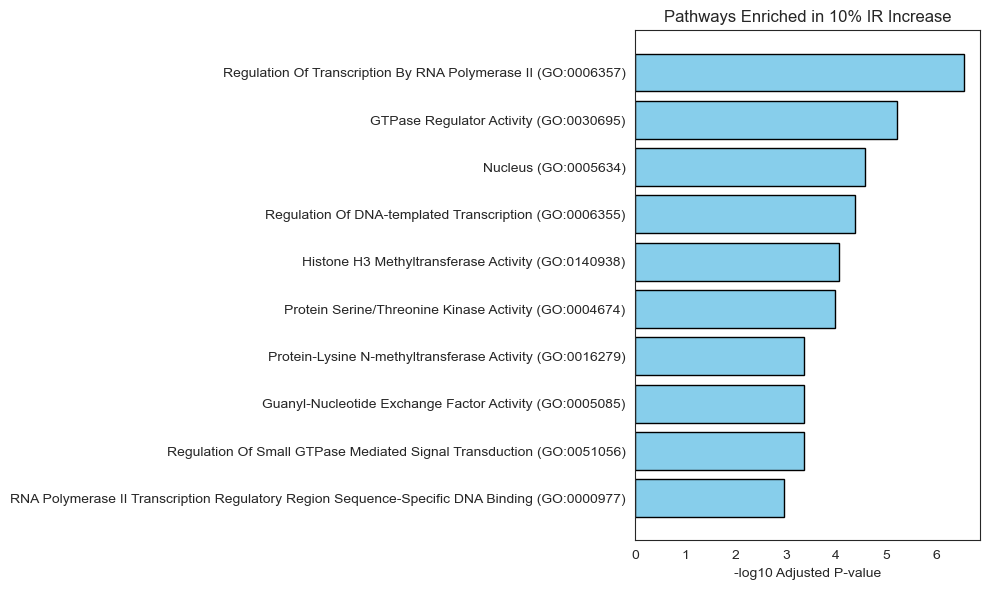


TOP TERMS FOR: Pathways Enriched in 10% IR Increase
                                                                                        Term  Overlap  Adjusted P-value
                               Regulation Of Transcription By RNA Polymerase II (GO:0006357) 269/1060      2.907815e-07
                                                      GTPase Regulator Activity (GO:0030695)   97/308      6.096118e-06
                                                                        Nucleus (GO:0005634) 621/2919      2.692752e-05
                                      Regulation Of DNA-templated Transcription (GO:0006355) 249/1028      4.257153e-05
                                          Histone H3 Methyltransferase Activity (GO:0140938)    19/31      8.632634e-05
                                       Protein Serine/Threonine Kinase Activity (GO:0004674)   80/258      1.078798e-04
                                    Protein-Lysine N-methyltransferase Activity (GO:0016279)    22/43      

In [32]:
import pandas as pd
import numpy as np
import gseapy as gp
import matplotlib.pyplot as plt
import requests

# =============================================================================
# 1. HELPERS: GMT DOWNLOAD
# =============================================================================
def fetch_enrichr_gmt(library_name):
    print(f"  Downloading {library_name}...")
    url = f"https://maayanlab.cloud/Enrichr/geneSetLibrary?mode=text&libraryName={library_name}"
    response = requests.get(url)
    if response.status_code != 200: raise Exception(f"Could not fetch {library_name}")
    gmt_dict = {}
    for line in response.text.strip().split('\n'):
        parts = line.split('\t')
        if len(parts) > 2:
            gmt_dict[parts[0]] = [g.split(',')[0].upper() for g in parts[2:] if g]
    return gmt_dict

# =============================================================================
# 2. LOAD DATA & PREPARE GENE RANKING
# =============================================================================
file_full = 'INCLUSION_LEVELS_FULL-mm10-2_95th_split.tab'
df = pd.read_csv(file_full, sep='\t')

# Filter for Introns and calculate dPSI (High - Low)
df_ir = df[df['EVENT'].str.contains('INT', na=False)].copy()
df_ir['High_Senescence'] = pd.to_numeric(df_ir['High_Senescence'], errors='coerce')
df_ir['Low_Senescence'] = pd.to_numeric(df_ir['Low_Senescence'], errors='coerce')
df_ir['dPSI'] = (df_ir['High_Senescence'] - df_ir['Low_Senescence']) / 100  # Convert to 0-1 scale

df_clean = df_ir.dropna(subset=['dPSI', 'GENE'])
df_clean['GENE'] = df_clean['GENE'].str.upper()

# Aggregate to Gene Level: Take the maximum failure (increase in retention)
gene_max_ir = df_clean.groupby('GENE')['dPSI'].max().reset_index()

# =============================================================================
# 3. DEFINE STUDY LISTS AND BACKGROUND
# =============================================================================
# Background (The Universe): Every gene successfully measured for IR
background = gene_max_ir['GENE'].unique().tolist()

# List 1: Moderate Failures (> 10%)
list_10pct = gene_max_ir[gene_max_ir['dPSI'] > 0.10]['GENE'].unique().tolist()

# List 2: Severe Failures (> 50%)
list_50pct = gene_max_ir[gene_max_ir['dPSI'] > 0.50]['GENE'].unique().tolist()

print(f"Background Universe: {len(background)} genes")
print(f"Study List (10% Threshold): {len(list_10pct)} genes")
print(f"Study List (50% Threshold): {len(list_50pct)} genes")

# =============================================================================
# 4. FETCH LIBRARIES
# =============================================================================
libraries = ["GO_Biological_Process_2023", "GO_Molecular_Function_2023", "GO_Cellular_Component_2023"]
combined_gmt = {}
for lib in libraries:
    combined_gmt.update(fetch_enrichr_gmt(lib))

# =============================================================================
# 5. RUN ORA FUNCTION
# =============================================================================
def run_ora(gene_list, label, universe, gmt):
    if len(gene_list) < 5:
        print(f"\n[SKIP] {label} has too few genes.")
        return None
    
    print(f"\nRunning ORA for {label}...")
    enr = gp.enrich(gene_list=gene_list,
                    gene_sets=gmt,
                    background=universe,
                    outdir=None,
                    verbose=False)
    
    res = enr.results
    return res[res['Adjusted P-value'] < 0.05].sort_values('Adjusted P-value')

# Execute for both
res_10 = run_ora(list_10pct, "Moderate Failures (>10%)", background, combined_gmt)
res_50 = run_ora(list_50pct, "Severe Failures (>50%)", background, combined_gmt)

# =============================================================================
# 6. RESULTS & VISUALIZATION
# =============================================================================
def plot_ora(df, title):
    if df is None or df.empty:
        print(f"No significant results for {title}")
        return
    
    top_plot = df.head(10).copy()
    top_plot['-log10_AdjP'] = -np.log10(top_plot['Adjusted P-value'])
    
    plt.figure(figsize=(10, 6))
    plt.barh(top_plot['Term'], top_plot['-log10_AdjP'], color='skyblue', edgecolor='black')
    plt.xlabel('-log10 Adjusted P-value')
    plt.title(title)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    
    print(f"\nTOP TERMS FOR: {title}")
    print(df[['Term', 'Overlap', 'Adjusted P-value']].head(10).to_string(index=False))

plot_ora(res_10, "Pathways Enriched in 10% IR Increase")
plot_ora(res_50, "Pathways Enriched in 50% IR Increase")

---

SPEARMAN CORRELATION BETWEEN SPLCIING SCORE AND AGEING

Selecting ALL hepatocytes from the dataset...

Cell counts per age group in Hepatocytes:
age
3m     401
18m    383
24m    377
Name: count, dtype: int64

Calculating GLOBAL splicing score using 345 unique genes...

=== Splice factor score per age ===
      n  Q1 (lower quartile)  median  Q3 (upper quartile)  IQR
age                                                           
3m  401                -35.3   -21.3                   -8 27.3
18m 383                -33.9   -16.1                -3.48 30.5
24m 377                  -70   -20.8                -2.85 67.2

Low-tail threshold (5th percentile of 3m): -73.70
3m: 20/401 cells below threshold (5.0%)
18m: 19/383 cells below threshold (5.0%)  vs 3m: odds ratio = 0.99, Fisher p = 1.00e+00
24m: 89/377 cells below threshold (23.6%)  vs 3m: odds ratio = 5.89, Fisher p = 2.93e-14


C:\Users\lukas\AppData\Local\Temp\ipykernel_18652\2314512721.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
C:\Users\lukas\AppData\Local\Temp\ipykernel_18652\2314512721.py:153: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['3 Months', '18 Months', '24 Months'], fontweight='bold')


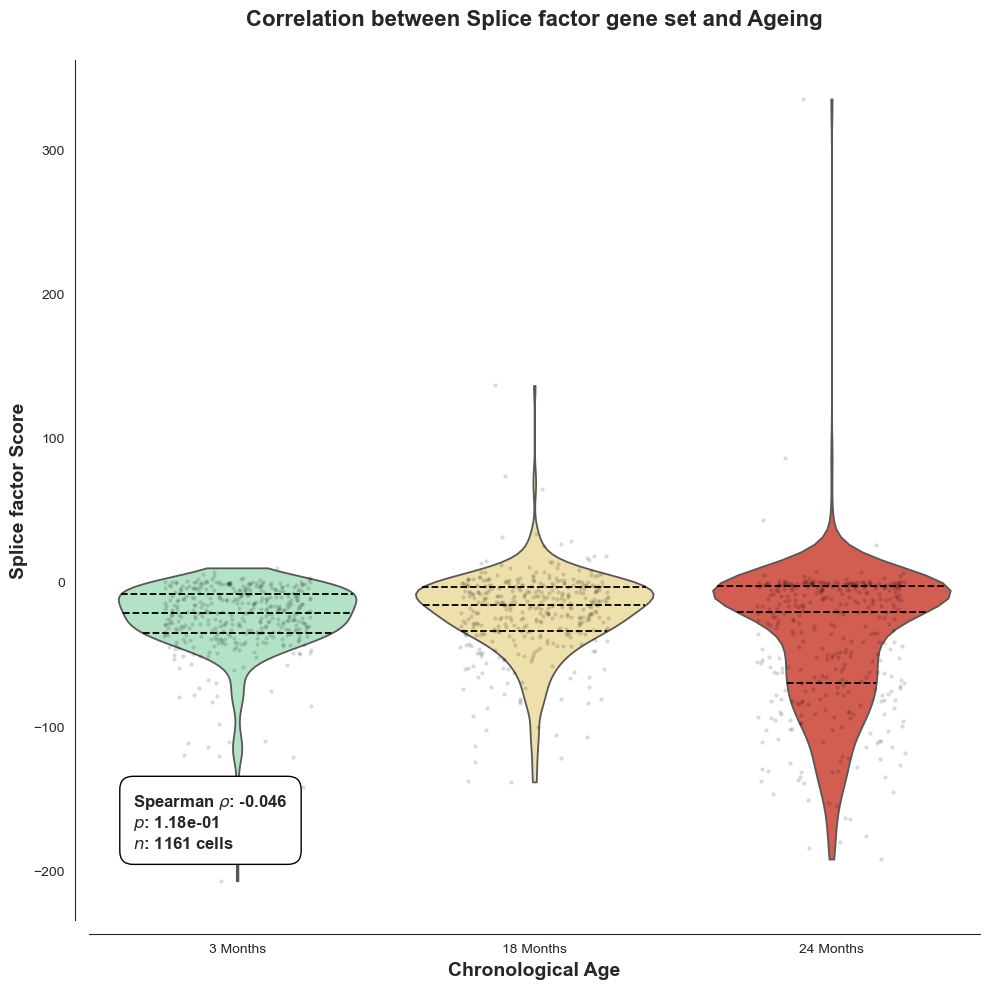

In [4]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy.stats import spearmanr

# =============================================================================
# 1. ENSURE ALL HEPATOCYTES ARE SELECTED
# =============================================================================
# We go back to the original 'adata' to make sure we haven't lost the 3m cells
print("Selecting ALL hepatocytes from the dataset...")
adata_heps = adata[adata.obs['cell_ontology_class'] == 'hepatocyte'].copy()

# --- SANITY CHECK ---
print("\nCell counts per age group in Hepatocytes:")
print(adata_heps.obs['age'].value_counts())

# =============================================================================
# 2. LOAD SPLICING GENES & CALCULATE GLOBAL SCORE
# =============================================================================
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

all_splicing_genes = []
for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            # Check main var_names
            valid = [g for g in [l.strip() for l in lines[1:]] if g in adata_heps.var_names]
            # Fallback to .raw for HVG-reduced data
            if len(valid) < 5 and adata_heps.raw is not None:
                valid = [g for g in [l.strip() for l in lines[1:]] if g in adata_heps.raw.var_names]
            all_splicing_genes.extend(valid)

all_splicing_genes = list(set(all_splicing_genes))

print(f"\nCalculating GLOBAL splicing score using {len(all_splicing_genes)} unique genes...")

# Scoring the entire hepatocyte population (including 3m)
sc.tl.score_genes(adata_heps, all_splicing_genes, score_name='splicing_score')

# =============================================================================
# 3. PREPARE PLOT DATA
# =============================================================================
df_plot = adata_heps.obs[['age', 'splicing_score']].copy()

# Ensure 3m, 18m, 24m are treated as numbers for the Spearman calculation
age_map = {'3m': 3, '18m': 18, '24m': 24}
df_plot['age_num'] = df_plot['age'].map(age_map).astype(float)

# IMPORTANT: Remove ONLY rows that have no score (NaNs)
df_plot = df_plot.dropna(subset=['splicing_score'])

# Calculate Spearman Correlation
rho, p_val = spearmanr(df_plot['age_num'], df_plot['splicing_score'])

# =============================================================================
# 3b. SUMMARY STATISTICS PER AGE (for the text)
# =============================================================================
summary = (df_plot.groupby('age', observed=True)['splicing_score']
           .describe(percentiles=[0.25, 0.5, 0.75])
           .reindex(age_order)[['count', '25%', '50%', '75%']]
           .rename(columns={'count': 'n', '25%': 'Q1 (lower quartile)',
                            '50%': 'median', '75%': 'Q3 (upper quartile)'}))
summary['IQR'] = summary['Q3 (upper quartile)'] - summary['Q1 (lower quartile)']
print("\n=== Splice factor score per age ===")
print(summary.round(2).to_string())

# Optional: share of cells in the low tail, defined like the SenMayo threshold
# (below the 5th percentile of 3-month-old cells), with Fisher's exact test vs 3m
from scipy.stats import fisher_exact
p5_young = df_plot.loc[df_plot['age'] == '3m', 'splicing_score'].quantile(0.05)
low = df_plot['splicing_score'] < p5_young
print(f"\nLow-tail threshold (5th percentile of 3m): {p5_young:.2f}")
for age in age_order:
    n_low = int(low[df_plot['age'] == age].sum()); n = int((df_plot['age'] == age).sum())
    line = f"{age}: {n_low}/{n} cells below threshold ({100 * n_low / n:.1f}%)"
    if age != '3m':
        n_low_y = int(low[df_plot['age'] == '3m'].sum()); n_y = int((df_plot['age'] == '3m').sum())
        odds, p = fisher_exact([[n_low, n - n_low], [n_low_y, n_y - n_low_y]])
        line += f"  vs 3m: odds ratio = {odds:.2f}, Fisher p = {p:.2e}"
    print(line)

# =============================================================================
# 4. VISUALIZATION (Pastel Style + All 3 Ages)
# =============================================================================
plt.figure(figsize=(10, 10))
sns.set_style("white")

# Color palette: Green, Yellow, Red (Pastels)
# We use '3m' here to ensure the color is assigned
pastel_palette = {'3m': '#abebc6', '18m': '#f9e79f', '24m': '#e74c3c'}
age_order = ['3m', '18m', '24m']

# Create Violin Plot
ax = sns.violinplot(
    data=df_plot, 
    x='age', 
    y='splicing_score', 
    order=age_order,
    palette=pastel_palette,
    inner="quartile",
    linewidth=1.3,
    cut=0
)

# Style quartile lines
for line in ax.lines:
    line.set_linestyle('--')
    line.set_color('black')

# Overlay individual dots
sns.stripplot(
    data=df_plot, 
    x='age', 
    y='splicing_score', 
    order=age_order,
    color='black', 
    size=3, 
    alpha=0.15, 
    jitter=0.25,
    ax=ax
)

# Stats Box
stats_text = (
    f"Spearman $\\rho$: {rho:.3f}\n"
    f"$p$: {p_val:.2e}\n"
    f"$n$: {len(df_plot)} cells"
)
ax.text(
    0.05, 0.08, 
    stats_text,
    transform=ax.transAxes,
    verticalalignment='bottom', 
    horizontalalignment='left',
    fontsize=12, 
    fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.8', facecolor='white', alpha=1, edgecolor='black')
)

# Formatting
ax.set_title('Correlation between Splice factor gene set and Ageing', 
             fontsize=16, fontweight='bold', pad=25)
ax.set_ylabel('Splice factor Score', fontsize=14, fontweight='bold')
ax.set_xlabel('Chronological Age', fontsize=14, fontweight='bold')
ax.set_xticklabels(['3 Months', '18 Months', '24 Months'], fontweight='bold')

sns.despine(offset=10) 
plt.tight_layout()
plt.show()

TO CHECK IF THE 24 MONTH OLD CELLS THAT HAVE HIGH SENMAYO SCORES ARE THE SAME CELLS THAT HAVE LOW SPLICE FACTOR GENE SET SCORES

In [6]:
# =============================================================================
# 3c. ARE THE LOW-SPLICE-FACTOR CELLS THE SAME AS THE SENMAYO-HIGH CELLS?
# =============================================================================
from scipy.stats import fisher_exact

df_ov = adata_heps.obs[['age', 'SenMayo_score', 'splicing_score']].dropna().copy()
young = df_ov['age'] == '3m'

sen_thr = df_ov.loc[young, 'SenMayo_score'].quantile(0.95)    # SenMayo-high threshold
sf_thr = df_ov.loc[young, 'splicing_score'].quantile(0.05)     # Splice factor-low threshold
df_ov['SenMayo_high'] = df_ov['SenMayo_score'] > sen_thr
df_ov['SF_low'] = df_ov['splicing_score'] < sf_thr

for age in ['18m', '24m']:
    sub = df_ov[df_ov['age'] == age]
    table = pd.crosstab(sub['SF_low'], sub['SenMayo_high']).reindex(
        index=[True, False], columns=[True, False], fill_value=0)
    odds, p = fisher_exact(table.values)
    n_both = table.loc[True, True]
    n_sf_low = table.loc[True].sum()
    n_sen_high = table[True].sum()
    expected = n_sf_low * n_sen_high / len(sub)    # overlap expected if unrelated
    print(f"\n=== {age} hepatocytes (n = {len(sub)}) ===")
    print(table.rename(index={True: 'SF-low', False: 'not SF-low'},
                       columns={True: 'SenMayo-high', False: 'not SenMayo-high'}))
    print(f"SF-low cells that are also SenMayo-high: {n_both}/{n_sf_low} "
          f"({100 * n_both / max(n_sf_low, 1):.1f}%)")
    print(f"Overlap expected by chance: {expected:.1f} cells; observed: {n_both}")
    print(f"Odds ratio = {odds:.2f}, Fisher's exact p = {p:.2e}")

    hep24 = df_all[df_all['age'] == '24m'].copy()
thr = df_all.loc[df_all['age'] == '3m', 'global_splicing_score'].quantile(0.05)
hep24['SF_low'] = hep24['global_splicing_score'] < thr
hep24['mouse'] = adata_heps.obs.loc[hep24.index, 'mouse.id']
print(pd.crosstab(hep24['mouse'], hep24['SF_low'], margins=True))


=== 18m hepatocytes (n = 383) ===
SenMayo_high  SenMayo-high  not SenMayo-high
SF_low                                      
SF-low                   1                18
not SF-low              42               322
SF-low cells that are also SenMayo-high: 1/19 (5.3%)
Overlap expected by chance: 2.1 cells; observed: 1
Odds ratio = 0.43, Fisher's exact p = 7.09e-01

=== 24m hepatocytes (n = 377) ===
SenMayo_high  SenMayo-high  not SenMayo-high
SF_low                                      
SF-low                  82                 7
not SF-low              70               218
SF-low cells that are also SenMayo-high: 82/89 (92.1%)
Overlap expected by chance: 35.9 cells; observed: 82
Odds ratio = 36.48, Fisher's exact p = 8.55e-32
SF_low   False  True  All
mouse                    
24_58_M    188    70  258
24_59_M    101    18  119
All        289    88  377


SPEARMAN CORRELATION BETWEEN SPLICING SCORE AND SENMAYO SCORE

FIRST FOR THE ENTIRE SENMAYO SCORED LIVER DATASET (ALL CELL-TYPES)

THEN ONLY FOR THE TESTED HEPATOCYTES

Loading Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad...
Isolating old hepatocytes (18m & 24m)...
Scoring using 339 unique splicing genes...


<Figure size 1000x1000 with 0 Axes>

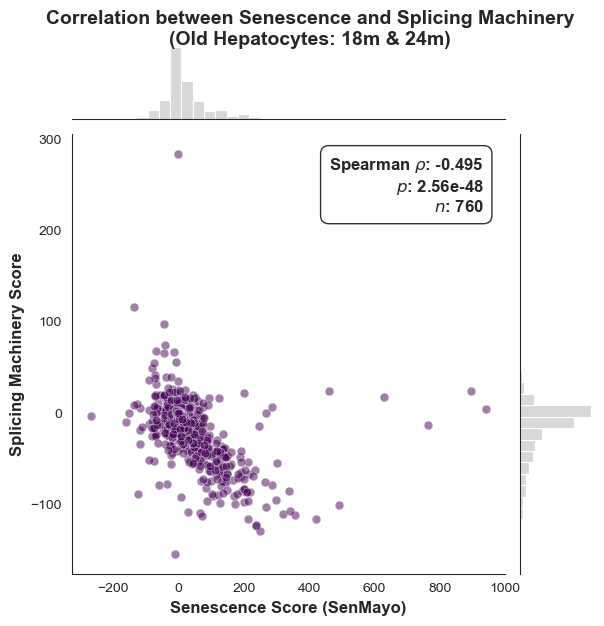

Analysis Complete. Spearman Rho: -0.4954


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy.stats import spearmanr

# =============================================================================
# --- STEP 1: LOAD AND SUBSET DATA ---
# =============================================================================
file_path = "Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad"
print(f"Loading {file_path}...")
adata = sc.read_h5ad(file_path)

# Isolate all 18m and 24m hepatocytes
print("Isolating old hepatocytes (18m & 24m)...")
adata_old = adata[
    (adata.obs['cell_ontology_class'] == 'hepatocyte') & 
    (adata.obs['age'].isin(['18m', '24m']))
].copy()

# =============================================================================
# --- STEP 2: CALCULATE SPLICING MACHINERY SCORE ---
# =============================================================================
# Align index to gene symbols
if 'mouse_gene_symbols' in adata_old.var.columns:
    adata_old.var_names = adata_old.var['mouse_gene_symbols'].astype(str)
    adata_old.var_names_make_unique()

# Load gene lists
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

all_splicing_genes = []
for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            genes_in_file = [line.strip() for line in lines[1:] if line.strip()]
            valid = [g for g in genes_in_file if g in adata_old.var_names]
            all_splicing_genes.extend(valid)

all_splicing_genes = list(set(all_splicing_genes))
print(f"Scoring using {len(all_splicing_genes)} unique splicing genes...")

# Compute the score
sc.tl.score_genes(adata_old, all_splicing_genes, score_name='splicing_score')

# =============================================================================
# --- STEP 3: CORRELATION AND PLOTTING ---
# =============================================================================
# Prepare dataframe
df_plot = adata_old.obs[['SenMayo_score', 'splicing_score']].copy()
df_plot = df_plot.apply(pd.to_numeric, errors='coerce').dropna()

# Calculate Spearman Correlation
rho, p_val = spearmanr(df_plot['SenMayo_score'], df_plot['splicing_score'])

# Visualization
sns.set_style("white")
plt.figure(figsize=(10, 10))

# kind='scatter' ensures NO linear regression line is drawn
g = sns.jointplot(
    data=df_plot, 
    x='SenMayo_score', 
    y='splicing_score',
    kind='scatter', 
    marginal_kws=dict(bins=35, fill=True, color='grey', alpha=0.3),
    joint_kws=dict(alpha=0.5, s=40, color='#440154', edgecolor='white', linewidth=0.5)
)

# Statistics Annotation
stats_text = (
    f'Spearman $\\rho$: {rho:.3f}\n'
    f'$p$: {p_val:.2e}\n'
    f'$n$: {len(df_plot)}'
)

g.ax_joint.text(
    0.95, 0.95, 
    stats_text,
    transform=g.ax_joint.transAxes,
    verticalalignment='top', 
    horizontalalignment='right',
    fontsize=12, 
    fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='black')
)

# Labeling
g.set_axis_labels('Senescence Score (SenMayo)', 'Splicing Machinery Score', fontsize=12, fontweight='bold')
plt.suptitle('Correlation between Senescence and Splicing Machinery\n(Old Hepatocytes: 18m & 24m)', 
             y=1.03, fontsize=14, fontweight='bold')

plt.show()

print(f"Analysis Complete. Spearman Rho: {rho:.4f}")

C:\Users\lukas\AppData\Local\Temp\ipykernel_22552\1841290581.py:47: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df_all = df_all.apply(pd.to_numeric, errors='ignore').dropna()


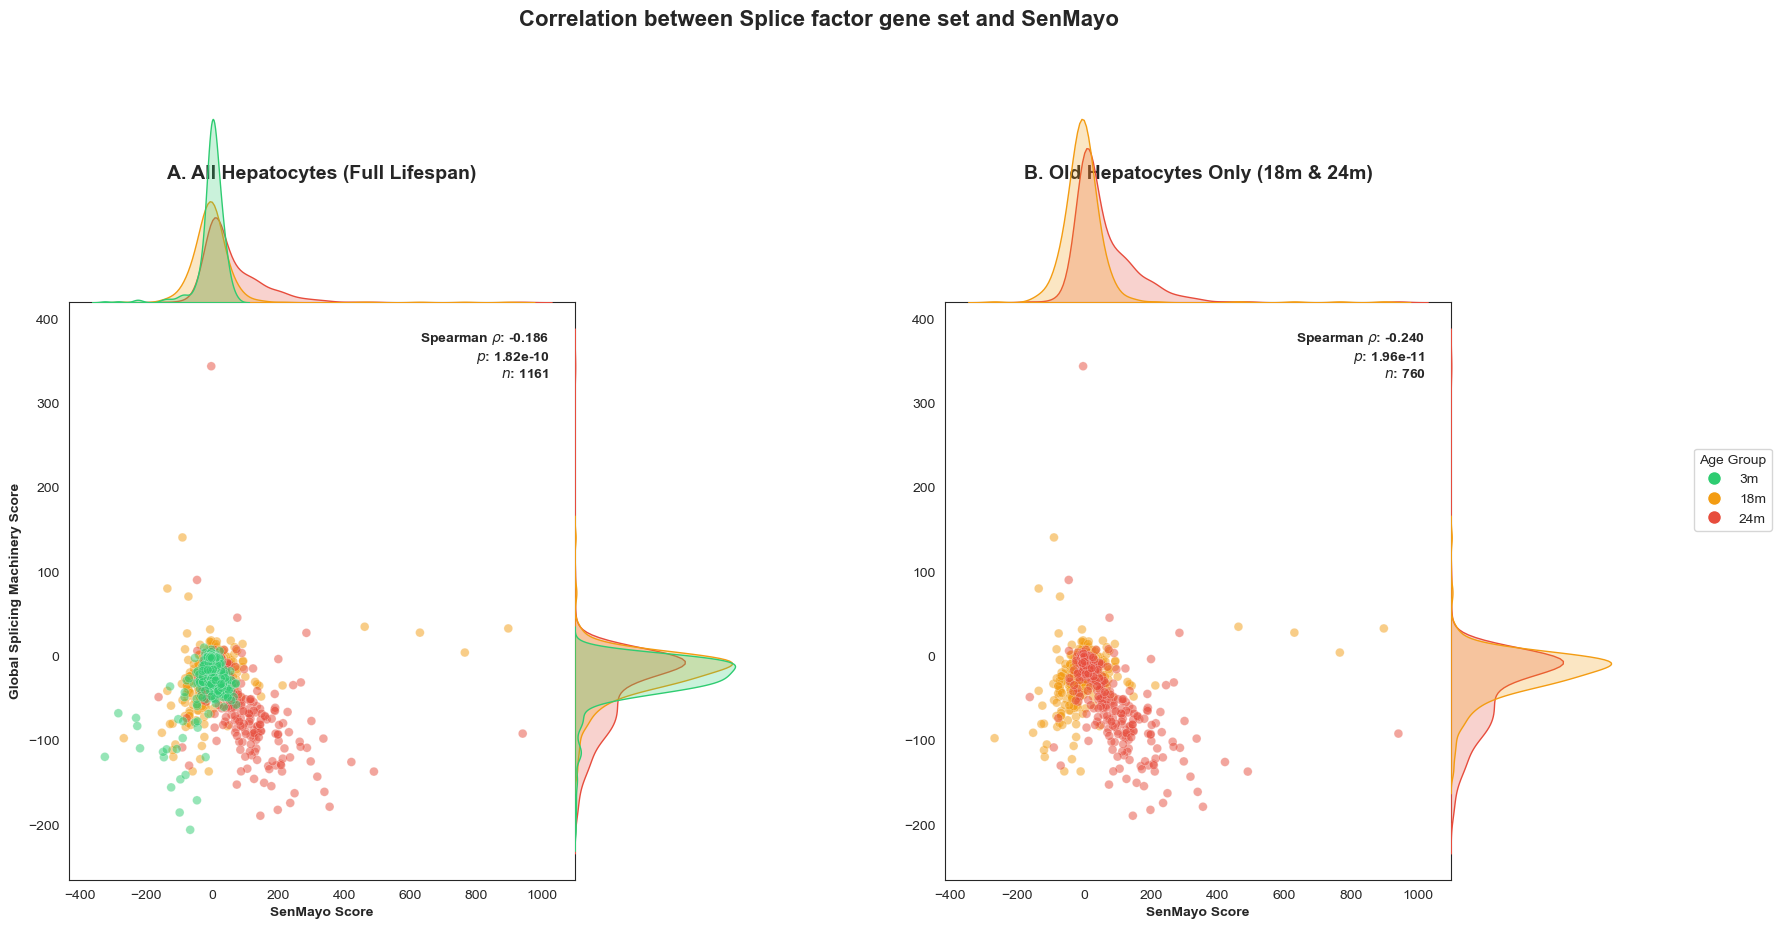

Rho (All Hepatocytes): -0.1857
Rho (Old Hepatocytes): -0.2402


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy.stats import spearmanr

# =============================================================================
# --- STEP 1: LOAD AND PREPARE DATA ---
# =============================================================================
file_path = "Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad"
adata = sc.read_h5ad(file_path)

# Isolate ALL hepatocytes first (n=1161)
adata_heps = adata[adata.obs['cell_ontology_class'] == 'hepatocyte'].copy()

if 'mouse_gene_symbols' in adata_heps.var.columns:
    adata_heps.var_names = adata_heps.var['mouse_gene_symbols'].astype(str)
    adata_heps.var_names_make_unique()

# =============================================================================
# --- STEP 2: CALCULATE GLOBAL SPLICING SCORE (n=1161) ---
# =============================================================================
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

all_splicing_genes = []
for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            valid = [g for g in [l.strip() for l in lines[1:]] if g in adata_heps.var_names]
            all_splicing_genes.extend(valid)

all_splicing_genes = list(set(all_splicing_genes))
sc.tl.score_genes(adata_heps, all_splicing_genes, score_name='global_splicing_score')

# =============================================================================
# --- STEP 3: PREPARE DATASETS ---
# =============================================================================
# Full dataset
df_all = adata_heps.obs[['SenMayo_score', 'global_splicing_score', 'age']].copy()
df_all = df_all.apply(pd.to_numeric, errors='ignore').dropna()

# Old only dataset
df_old = df_all[df_all['age'].isin(['18m', '24m'])].copy()

# Color palette for age
age_palette = {'3m': '#2ecc71', '18m': '#f39c12', '24m': '#e74c3c'}
age_order = ['3m', '18m', '24m']

# =============================================================================
# --- STEP 4: VISUALIZATION (Side-by-Side) ---
# =============================================================================
sns.set_style("white")

# We create two JointGrids side-by-side
fig = plt.figure(figsize=(20, 10))
gs = plt.GridSpec(1, 2, wspace=0.3)

def plot_joint_subset(df, grid_spec, title):
    # Create a sub-grid for the joint plot logic
    inner_gs = grid_spec.subgridspec(4, 4, wspace=0, hspace=0)
    
    # Define axes
    ax_main = fig.add_subplot(inner_gs[1:, :-1])
    ax_marg_x = fig.add_subplot(inner_gs[0, :-1], sharex=ax_main)
    ax_marg_y = fig.add_subplot(inner_gs[1:, -1], sharey=ax_main)

    # Calculate Stats
    rho, p_val = spearmanr(df['SenMayo_score'], df['global_splicing_score'])

    # Main Scatter Plot
    sns.scatterplot(
        data=df, x='SenMayo_score', y='global_splicing_score', 
        hue='age', palette=age_palette, hue_order=age_order,
        alpha=0.5, s=40, ax=ax_main, edgecolor='white', linewidth=0.3, legend=False
    )

    # Marginals
    sns.kdeplot(data=df, x='SenMayo_score', hue='age', palette=age_palette, 
                fill=True, ax=ax_marg_x, legend=False, common_norm=False)
    sns.kdeplot(data=df, y='global_splicing_score', hue='age', palette=age_palette, 
                fill=True, ax=ax_marg_y, legend=False, common_norm=False)

    # Cleanup marginals
    ax_marg_x.axis('off')
    ax_marg_y.axis('off')

    # Stats Annotation
    stats_text = f'Spearman $\\rho$: {rho:.3f}\n$p$: {p_val:.2e}\n$n$: {len(df)}'
    ax_main.text(0.95, 0.95, stats_text, transform=ax_main.transAxes, 
                 va='top', ha='right', fontweight='bold', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    ax_main.set_title(title, fontsize=14, fontweight='bold', y=1.2)
    ax_main.set_xlabel('SenMayo Score', fontweight='bold')
    return ax_main

# Plot A: All Cells
ax_a = plot_joint_subset(df_all, gs[0], "A. All Hepatocytes (Full Lifespan)")
ax_a.set_ylabel('Global Splicing Machinery Score', fontweight='bold')

# Plot B: Old Cells Only
ax_b = plot_joint_subset(df_old, gs[1], "B. Old Hepatocytes Only (18m & 24m)")
ax_b.set_ylabel('')

# Add a single legend for the whole figure
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=v, label=k, markersize=10) 
           for k, v in age_palette.items()]
fig.legend(handles=handles, title="Age Group", loc='center right', bbox_to_anchor=(0.98, 0.5))

plt.suptitle("Correlation between Splice factor gene set and SenMayo", 
             fontsize=16, fontweight='bold', y=0.98)

plt.show()

# Print results
rho_all, _ = spearmanr(df_all['SenMayo_score'], df_all['global_splicing_score'])
rho_old, _ = spearmanr(df_old['SenMayo_score'], df_old['global_splicing_score'])
print(f"Rho (All Hepatocytes): {rho_all:.4f}")
print(f"Rho (Old Hepatocytes): {rho_old:.4f}")

Splice factor gene set: 339 unique genes found in the data

=== Spearman correlation: SenMayo vs Splice factor score ===
                      subset    n    rho        p
    All hepatocytes (pooled) 1161 -0.186 1.82e-10
Old only (18m + 24m, pooled)  760  -0.24 1.96e-11
                     3m only  401 -0.149  0.00273
                    18m only  383  0.379 1.62e-14
                    24m only  377 -0.718 6.33e-61
           All, age-adjusted 1161  -0.16 4.52e-08
           Old, age-adjusted  760 -0.165 4.73e-06

=== Technical check: correlation with sequencing depth, per age ===
age    depth measure  rho SenMayo~depth  rho SpliceFactor~depth  rho SenMayo~SF  rho SenMayo~SF | depth  p (partial)
 3m n_genes_detected              0.438                  -0.612          -0.149                   0.167     0.000794
 3m     total_counts              0.373                   -0.58          -0.149                  0.0886       0.0762
18m n_genes_detected             -0.363                  -0

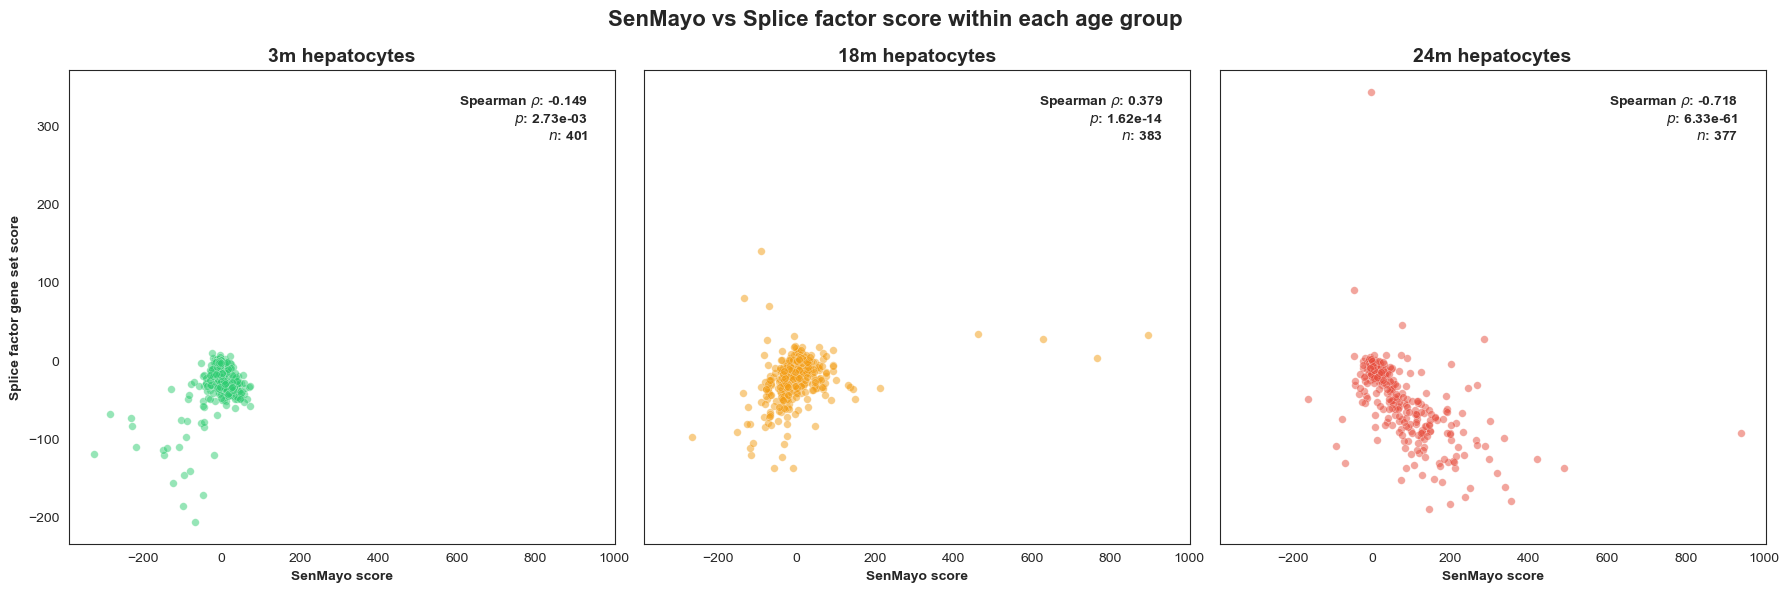

In [3]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy.stats import spearmanr, pearsonr, rankdata

# =============================================================================
# --- STEP 1: LOAD AND PREPARE DATA (unchanged) ---
# =============================================================================
file_path = "Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad"
adata = sc.read_h5ad(file_path)

adata_heps = adata[adata.obs['cell_ontology_class'] == 'hepatocyte'].copy()

if 'mouse_gene_symbols' in adata_heps.var.columns:
    adata_heps.var_names = adata_heps.var['mouse_gene_symbols'].astype(str)
    adata_heps.var_names_make_unique()

# =============================================================================
# --- STEP 2: CALCULATE GLOBAL SPLICING SCORE (unchanged) ---
# =============================================================================
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

all_splicing_genes = []
for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            valid = [g for g in [l.strip() for l in lines[1:]] if g in adata_heps.var_names]
            all_splicing_genes.extend(valid)

all_splicing_genes = list(set(all_splicing_genes))
print(f"Splice factor gene set: {len(all_splicing_genes)} unique genes found in the data")
sc.tl.score_genes(adata_heps, all_splicing_genes, score_name='global_splicing_score')

# =============================================================================
# --- STEP 3: PREPARE DATA ---
# =============================================================================
age_order = ['3m', '18m', '24m']
age_palette = {'3m': '#2ecc71', '18m': '#f39c12', '24m': '#e74c3c'}

df_all = adata_heps.obs[['SenMayo_score', 'global_splicing_score', 'age']].copy()
df_all['age'] = df_all['age'].astype(str)
df_all = df_all.dropna()
df_old = df_all[df_all['age'].isin(['18m', '24m'])].copy()

X, Y = 'SenMayo_score', 'global_splicing_score'


def age_adjusted_spearman(df):
    """Spearman correlation after removing age: ranks are computed WITHIN each age
    group and centred, so between-age differences in either score cannot contribute."""
    rx = df.groupby('age')[X].transform(lambda s: (rankdata(s) - 0.5) / len(s) - 0.5)
    ry = df.groupby('age')[Y].transform(lambda s: (rankdata(s) - 0.5) / len(s) - 0.5)
    return pearsonr(rx, ry)


# =============================================================================
# --- STEP 4: THE TEST — correlation within each age group ---
# =============================================================================
rows = []
for label, sub in [('All hepatocytes (pooled)', df_all), ('Old only (18m + 24m, pooled)', df_old)] + \
                  [(f'{a} only', df_all[df_all['age'] == a]) for a in age_order]:
    rho, p = spearmanr(sub[X], sub[Y])
    rows.append({'subset': label, 'n': len(sub), 'rho': rho, 'p': p})

for label, sub in [('All, age-adjusted', df_all), ('Old, age-adjusted', df_old)]:
    rho, p = age_adjusted_spearman(sub)
    rows.append({'subset': label, 'n': len(sub), 'rho': rho, 'p': p})

results = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:.3g}')
print("\n=== Spearman correlation: SenMayo vs Splice factor score ===")
print(results.to_string(index=False))

# =============================================================================
# --- STEP 4b: TECHNICAL CHECK — is any within-age correlation driven by depth? ---
#     If both scores rise with the number of detected genes (or total counts),
#     they can correlate positively for purely technical reasons.
# =============================================================================
# Number of detected genes per cell: unaffected by library-size normalisation,
# because a zero stays zero.
Xmat = adata_heps.X
n_detected = np.asarray((Xmat > 0).sum(axis=1)).ravel()
df_all['n_genes_detected'] = pd.Series(n_detected, index=adata_heps.obs_names).loc[df_all.index]
depth_cols = ['n_genes_detected']

# Total counts, if the original QC column is present (computing it from a
# normalised .X would give the same value for every cell, so it is not used then).
for c in ['total_counts', 'n_counts']:
    if c in adata_heps.obs.columns:
        df_all[c] = adata_heps.obs.loc[df_all.index, c].astype(float)
        depth_cols.append(c)
        break


def partial_spearman(df, x, y, z):
    """Spearman correlation between x and y after removing the (rank) effect of z."""
    rx, ry, rz = rankdata(df[x]), rankdata(df[y]), rankdata(df[z])
    res_x = rx - np.polyval(np.polyfit(rz, rx, 1), rz)
    res_y = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    return pearsonr(res_x, res_y)


drows = []
for age in age_order:
    sub = df_all[df_all['age'] == age]
    for z in depth_cols:
        r_x, _ = spearmanr(sub[X], sub[z])
        r_y, _ = spearmanr(sub[Y], sub[z])
        rho_raw, _ = spearmanr(sub[X], sub[Y])
        rho_part, p_part = partial_spearman(sub, X, Y, z)
        drows.append({'age': age, 'depth measure': z,
                      'rho SenMayo~depth': r_x, 'rho SpliceFactor~depth': r_y,
                      'rho SenMayo~SF': rho_raw, 'rho SenMayo~SF | depth': rho_part,
                      'p (partial)': p_part})

depth_results = pd.DataFrame(drows)
print("\n=== Technical check: correlation with sequencing depth, per age ===")
print(depth_results.to_string(index=False))
print("\nHow to read: if at 18m both scores correlate positively with depth AND the\n"
      "SenMayo~SF correlation shrinks towards 0 after controlling for depth, the\n"
      "positive 18m correlation is largely technical. If it stays clearly positive,\n"
      "it is not explained by depth.")

# =============================================================================
# --- STEP 5: FIGURE — one scatter per age group, same axes ---
# =============================================================================
sns.set_style("white")
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, age in zip(axes, age_order):
    sub = df_all[df_all['age'] == age]
    sns.scatterplot(data=sub, x=X, y=Y, color=age_palette[age], alpha=0.5, s=30,
                    edgecolor='white', linewidth=0.3, ax=ax)
    r = results.loc[results['subset'] == f'{age} only'].iloc[0]
    ax.text(0.95, 0.95,
            f"Spearman $\\rho$: {r['rho']:.3f}\n$p$: {r['p']:.2e}\n$n$: {int(r['n'])}",
            transform=ax.transAxes, va='top', ha='right', fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    ax.set_title(f'{age} hepatocytes', fontsize=14, fontweight='bold')
    ax.set_xlabel('SenMayo score', fontweight='bold')
axes[0].set_ylabel('Splice factor gene set score', fontweight='bold')
for ax in axes[1:]:
    ax.set_ylabel('')

plt.suptitle('SenMayo vs Splice factor score within each age group', fontsize=16, fontweight='bold')
plt.tight_layout()
fig.savefig('SenMayo_vs_SpliceFactor_by_age.png', dpi=300, bbox_inches='tight')
plt.show()

ANOTHER CORRELATION PLOT AFTER REMOVING THE LIST OG SPLICE FACTOR GENES THAT NEGATIVELY CORRELATE WITH SENMAYO

Isolating all hepatocytes for scoring context...
Recalculating Splicing Scores (using SenMayo_score from file as reference)...


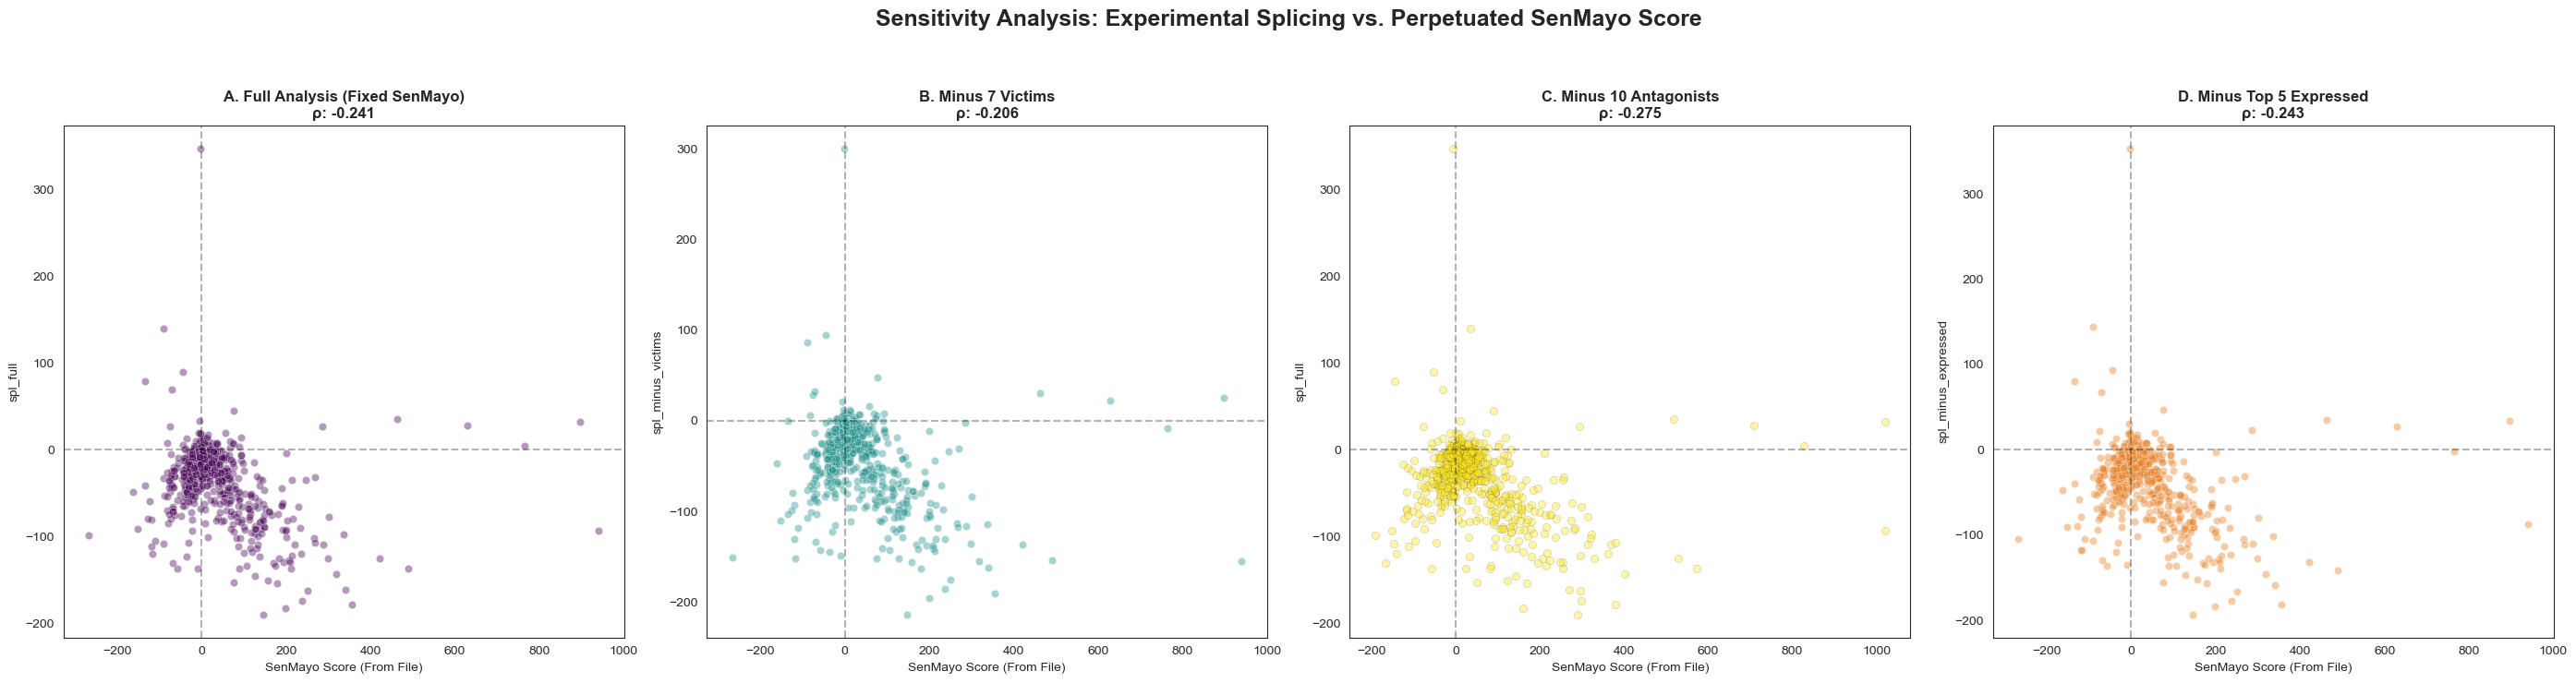

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gseapy as gp
from scipy.stats import spearmanr
import os

# =============================================================================
# --- STEP 1: LOAD DATA AND ISOLATE ALL AGES ---
# =============================================================================
file_path = "Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad"
adata = sc.read_h5ad(file_path)

print("Isolating all hepatocytes for scoring context...")
adata_heps = adata[adata.obs['cell_ontology_class'] == 'hepatocyte'].copy()

# Ensure the perpetuated SenMayo score is treated as numeric
adata_heps.obs['SenMayo_score'] = pd.to_numeric(adata_heps.obs['SenMayo_score'], errors='coerce')

if 'mouse_gene_symbols' in adata_heps.var.columns:
    adata_heps.var_names = adata_heps.var['mouse_gene_symbols'].astype(str)
    adata_heps.var_names_make_unique()

data_lookup = {g.upper(): g for g in adata_heps.var_names}

# =============================================================================
# --- STEP 2: PARSE SPLICING GENE SETS ---
# =============================================================================
paths = {'Spliceosomal Complex': 'Spliceosomal Complex.txt',
         'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
         'RNA Splicing': 'RNA Splicing.txt'}

list_splicing = []
for path in paths.values():
    if os.path.exists(path):
        with open(path, 'r') as f:
            raw = [l.strip().replace('"', '') for l in f.readlines()[1:] if l.strip()]
            list_splicing.extend([data_lookup[g.upper()] for g in raw if g.upper() in data_lookup])
list_splicing = list(set(list_splicing))

# We still need the list for the "Minus Antagonists" senescence check (Panel C)
sen_gmt = gp.read_gmt("SAUL_SEN_MAYO.v2025.1.Mm.gmt")
list_senmayo = [data_lookup[g.upper()] for g in sen_gmt["SAUL_SEN_MAYO"] if g.upper() in data_lookup]

# =============================================================================
# --- STEP 3: IDENTIFY TOP 5 MOST EXPRESSED SPLICING GENES ---
# =============================================================================
mean_expr = adata_heps[:, list_splicing].X.mean(axis=0)
if hasattr(mean_expr, "A1"): mean_expr = mean_expr.A1 

abundance_df = pd.DataFrame({'gene': list_splicing, 'mean': mean_expr}).sort_values('mean', ascending=False)
top_5_expressed = abundance_df.head(5)['gene'].tolist()

# =============================================================================
# --- STEP 4: DEFINE EXPERIMENTAL REMOVAL GROUPS ---
# =============================================================================
# Splicing Victims
victim_names = ['Hspa8', 'Ybx1', 'Hnrnpa2b1', 'Ncl', 'Lgals3', 'Srsf12', 'Aff2']
matched_victims = [data_lookup[v.upper()] for v in victim_names if v.upper() in data_lookup]

# SenMayo Antagonists (to verify Senescence score robustness)
antagonist_names = ['Angptl4', 'Serpine2', 'Gdf15', 'Mmp14', 'Vegfa', 'Tnfrsf1a', 'Fas', 'Tnfrsf1b', 'Ptbp1', 'Il18']
matched_antagonists = [data_lookup[a.upper()] for a in antagonist_names if a.upper() in data_lookup]

splicing_minus_victims = [g for g in list_splicing if g not in matched_victims]
splicing_minus_expressed = [g for g in list_splicing if g not in top_5_expressed]
senmayo_restricted = [g for g in list_senmayo if g not in matched_antagonists]

# =============================================================================
# --- STEP 5: RECALCULATE SPLICING VARIATIONS ONLY ---
# =============================================================================
print("Recalculating Splicing Scores (using SenMayo_score from file as reference)...")

# Calculate the experimental splicing scores
sc.tl.score_genes(adata_heps, list_splicing, score_name='spl_full')
sc.tl.score_genes(adata_heps, splicing_minus_victims, score_name='spl_minus_victims')
sc.tl.score_genes(adata_heps, splicing_minus_expressed, score_name='spl_minus_expressed')

# Only recalculate Senescence for the restricted version (Panel C)
sc.tl.score_genes(adata_heps, senmayo_restricted, score_name='sen_minus_antagonists')

# =============================================================================
# --- STEP 6: SUBSET FOR OLD CELL CORRELATION ---
# =============================================================================
df_old = adata_heps.obs[adata_heps.obs['age'].isin(['18m', '24m'])].copy()
# Note: We use 'SenMayo_score' (from file) for A, B, and D
cols = ['SenMayo_score', 'sen_minus_antagonists', 'spl_full', 'spl_minus_victims', 'spl_minus_expressed']
df_old = df_old[cols].apply(pd.to_numeric, errors='coerce').dropna()

# =============================================================================
# --- STEP 7: CORRELATION AND PLOTTING ---
# =============================================================================
# We correlate the saved SenMayo_score against our experimental Splicing scores
r_A, _ = spearmanr(df_old['SenMayo_score'], df_old['spl_full'])
r_B, _ = spearmanr(df_old['SenMayo_score'], df_old['spl_minus_victims'])
r_C, _ = spearmanr(df_old['sen_minus_antagonists'], df_old['spl_full']) # Recalculated Sen reference
r_D, _ = spearmanr(df_old['SenMayo_score'], df_old['spl_minus_expressed'])

fig, axes = plt.subplots(1, 4, figsize=(28, 7), sharey=False)
sns.set_style("white")

# Plot using fixed SenMayo_score from file
sns.scatterplot(data=df_old, x='SenMayo_score', y='spl_full', ax=axes[0], color='#440154', alpha=0.4, edgecolor='white')
axes[0].set_title(f"A. Full Analysis (Fixed SenMayo)\nρ: {r_A:.3f}", fontweight='bold')

sns.scatterplot(data=df_old, x='SenMayo_score', y='spl_minus_victims', ax=axes[1], color='#21918c', alpha=0.4, edgecolor='white')
axes[1].set_title(f"B. Minus 7 Victims\nρ: {r_B:.3f}", fontweight='bold')

sns.scatterplot(data=df_old, x='sen_minus_antagonists', y='spl_full', ax=axes[2], color='#fde725', alpha=0.4, edgecolor='black', linewidth=0.2)
axes[2].set_title(f"C. Minus 10 Antagonists\nρ: {r_C:.3f}", fontweight='bold')

sns.scatterplot(data=df_old, x='SenMayo_score', y='spl_minus_expressed', ax=axes[3], color='#e67e22', alpha=0.4, edgecolor='white')
axes[3].set_title(f"D. Minus Top 5 Expressed\nρ: {r_D:.3f}", fontweight='bold')

for ax in axes:
    ax.axhline(0, color='black', linestyle='--', alpha=0.3); ax.axvline(0, color='black', linestyle='--', alpha=0.3)
    ax.set_xlabel("SenMayo Score (From File)")

plt.suptitle("Sensitivity Analysis: Experimental Splicing vs. Perpetuated SenMayo Score", fontsize=18, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

THE SCORES ARE BEING RECALCULATED EACH TIME FOR EACH CORRELATION

---

FOR HIGH VS LOW EXPRESSION OF GENES ASSOCIATED WITH SPLICING, BY THRESHOLDING INSTEAD OF THE MEDIAN


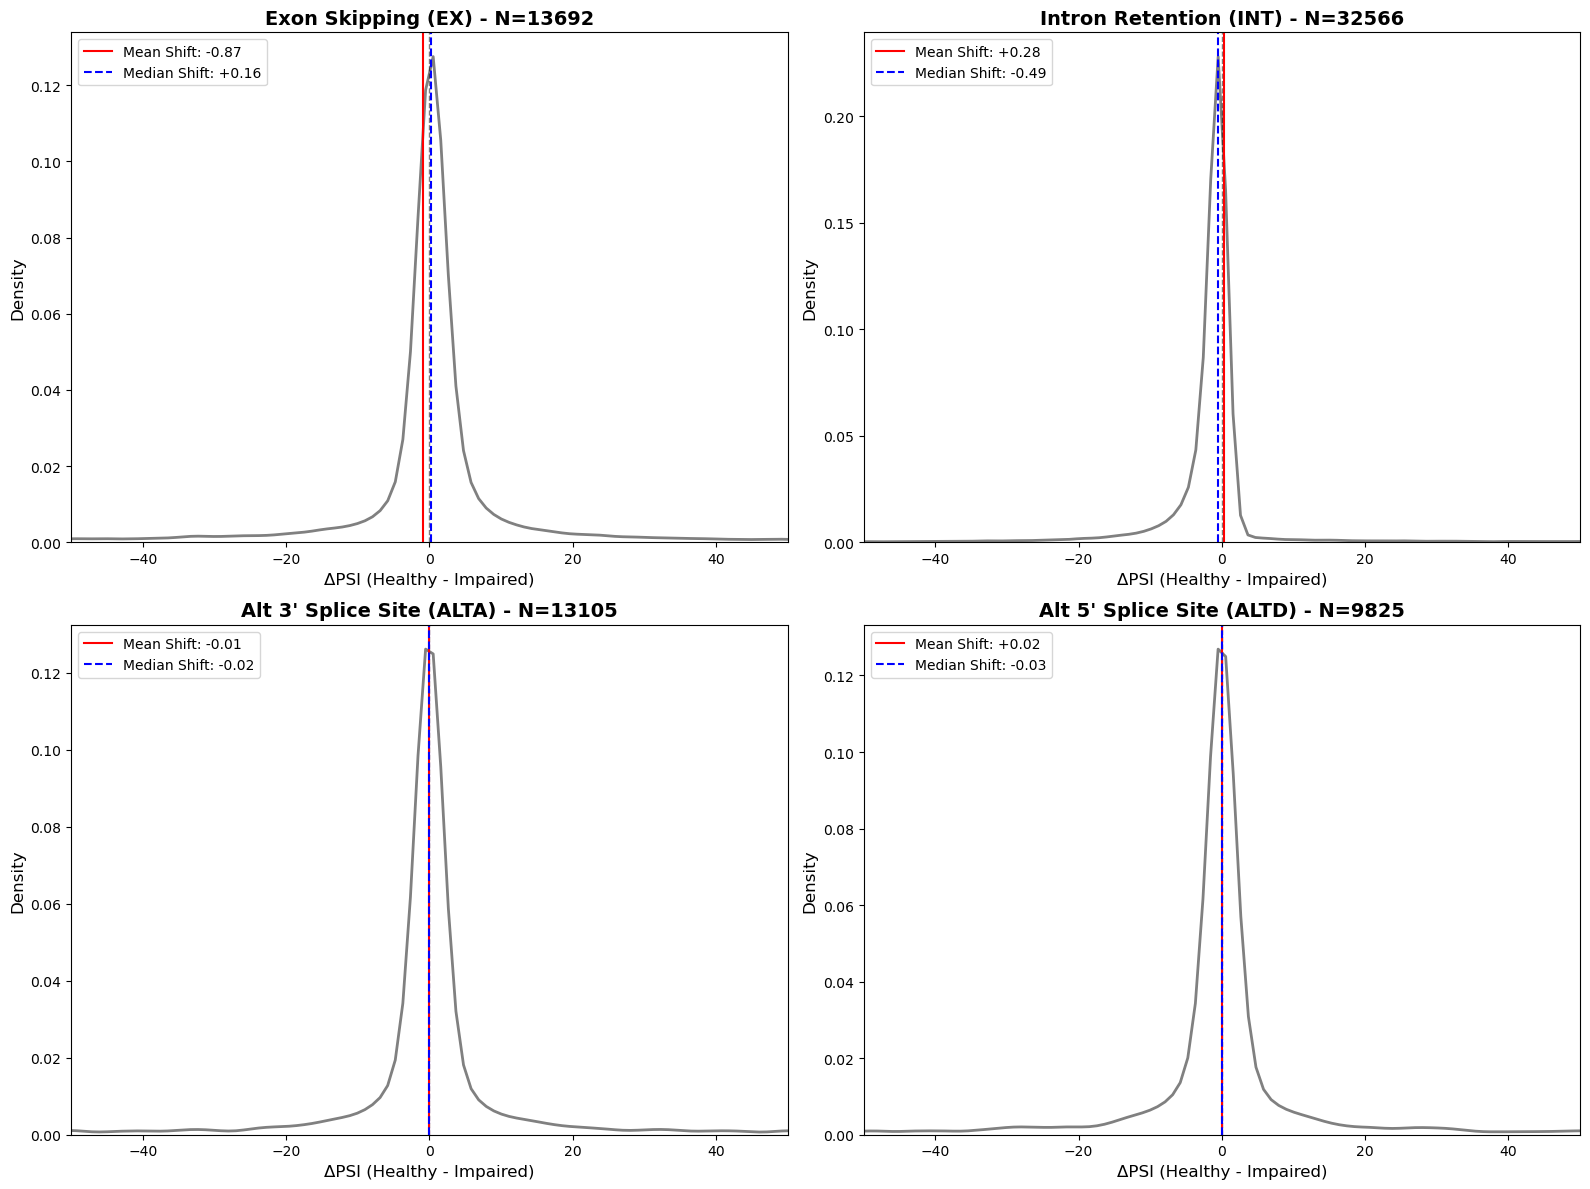


Summary for: INCLUSION_LEVELS_FULL-mm10-2_splicetails.tab (ΔPSI ≠ 0)
Event Type           | Count    | Mean       | Median     | Ratio (Up/Dn)
--------------------------------------------------------------------------------
Exon Skipping        | 13692    |     -0.87 |     +0.16 | 1.84x
Intron Retention     | 32566    |     +0.28 |     -0.49 | 0.09x
Alt 3' Splice Site   | 13105    |     -0.01 |     -0.02 | 0.90x
Alt 5' Splice Site   | 9825     |     +0.02 |     -0.03 | 0.86x


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD AND CLEAN DATA
# Updated filename to match your new file
filename = "INCLUSION_LEVELS_FULL-mm10-2_splicetails.tab"
try:
    df_full = pd.read_csv(filename, sep='\t')
except FileNotFoundError:
    print(f"Error: File '{filename}' not found.")
    exit()

# Updated column names based on your file structure:
# Healthy_Splicing (High/Control), Impaired_Splicing (Low/Test)
cols_to_use = ['Healthy_Splicing', 'Impaired_Splicing']

for col in cols_to_use:
    # Converting to numeric is crucial as 'NA' strings will become NaN
    df_full[col] = pd.to_numeric(df_full[col], errors='coerce')

# Remove rows where splicing values are NA (like the example row you provided)
df_full = df_full.dropna(subset=cols_to_use)

# Calculate dPSI (Delta Percent Spliced In)
# Healthy - Impaired: Positive value means inclusion decreased in the impaired condition
df_full['dPSI'] = df_full['Healthy_Splicing'] - df_full['Impaired_Splicing']

# FILTER: Remove exact 0s to focus on events that actually changed
df_active = df_full[df_full['dPSI'] != 0].copy()

# 2. DEFINE EVENT TYPES
# Adjusted keys to match typical abbreviations found in EVENT strings (e.g., 'EX' in 'MmuEX...')
event_map = {
    'EX': 'Exon Skipping',
    'INT': 'Intron Retention',
    'ALTA': 'Alt 3\' Splice Site',
    'ALTD': 'Alt 5\' Splice Site'
}

# 3. LOOP AND PLOT
if df_active.empty:
    print("Error: No numeric data available after filtering NAs and zeros.")
else:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.flatten()

    for i, (code, label) in enumerate(event_map.items()):
        # Filter for the specific event type code in the EVENT string
        subset = df_active[df_active['EVENT'].str.contains(code, na=False)].copy()
        
        if len(subset) < 2:  # KDE needs at least 2 points
            axes[i].set_title(f'{label} ({code})\n[Insufficient Data]', fontsize=14)
            axes[i].text(0.5, 0.5, 'No Data', ha='center')
            continue
            
        mean_shift = subset['dPSI'].mean()
        median_shift = subset['dPSI'].median()
        
        # Plot distribution
        sns.kdeplot(subset['dPSI'], ax=axes[i], color="grey", linewidth=2, bw_adjust=0.5)
        
        # Reference Lines
        axes[i].axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)
        axes[i].axvline(mean_shift, color='red', linestyle='-', 
                        label=f'Mean Shift: {mean_shift:+.2f}')
        axes[i].axvline(median_shift, color='blue', linestyle='--', 
                        label=f'Median Shift: {median_shift:+.2f}')
        
        # Formatting
        axes[i].set_title(f'{label} ({code}) - N={len(subset)}', fontsize=14, fontweight='bold')
        axes[i].set_xlabel('ΔPSI (Healthy - Impaired)', fontsize=12)
        axes[i].set_ylabel('Density', fontsize=12)
        axes[i].set_xlim(-50, 50) # Expanded range slightly for better visibility
        axes[i].legend(loc='upper left')

    plt.tight_layout()
    plt.show()

    # 4. PRINT SUMMARY
    print(f"\nSummary for: {filename} (ΔPSI ≠ 0)")
    print(f"{'Event Type':<20} | {'Count':<8} | {'Mean':<10} | {'Median':<10} | {'Ratio (Up/Dn)'}")
    print("-" * 80)
    for code, label in event_map.items():
        subset = df_active[df_active['EVENT'].str.contains(code, na=False)]
        if len(subset) == 0: continue
        
        mean_s = subset['dPSI'].mean()
        med_s = subset['dPSI'].median()
        
        up = (subset['dPSI'] > 0).sum()
        down = (subset['dPSI'] < 0).sum()
        ratio = up/down if down > 0 else np.inf
        
        print(f"{label:<20} | {len(subset):<8} | {mean_s:>+9.2f} | {med_s:>+9.2f} | {ratio:.2f}x")

NOW WITH THE NEW THRESHOLD, THAT ADDS MORE CELLS TO EITHER SIDE

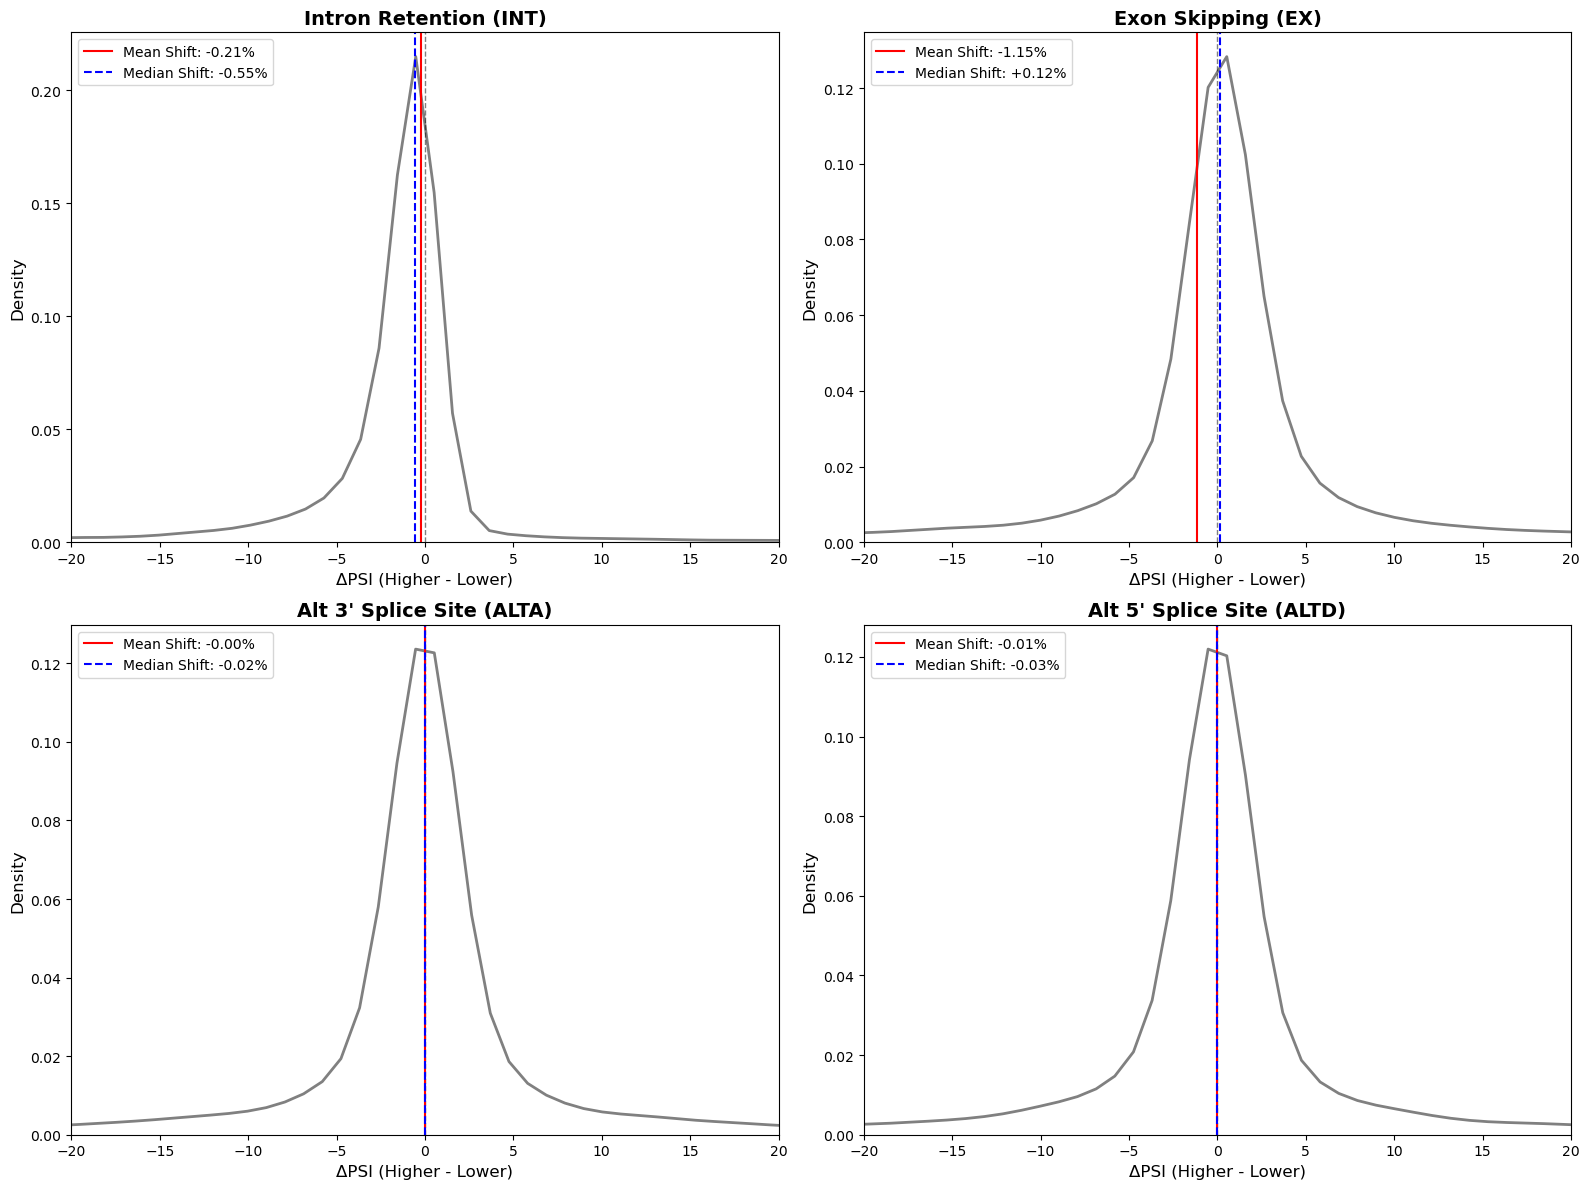


Summary for: INCLUSION_LEVELS_FULL-mm10-2_splicetails_2.tab (ΔPSI ≠ 0)
Event Type           | Count    | Mean       | Median     | Ratio
---------------------------------------------------------------------------
Intron Retention     | 42920    |     -0.21% |     -0.55% | 0.13x
Exon Skipping        | 17733    |     -1.15% |     +0.12% | 1.54x
Alt 3' Splice Site   | 17156    |     -0.00% |     -0.02% | 0.93x
Alt 5' Splice Site   | 12687    |     -0.01% |     -0.03% | 0.89x


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD AND CLEAN DATA
filename = "INCLUSION_LEVELS_FULL-mm10-2_splicetails_2.tab"
try:
    df_full = pd.read_csv(filename, sep='\t')
except FileNotFoundError:
    print(f"Error: File '{filename}' not found.")
    exit()

# Columns: Healthy_Splicing (Control), Impaired_Splicing (Test)
cols_to_use = ['Healthy_Splicing', 'Impaired_Splicing']

for col in cols_to_use:
    df_full[col] = pd.to_numeric(df_full[col], errors='coerce')

# Remove rows where splicing values are NA
df_full = df_full.dropna(subset=cols_to_use)

# Calculate dPSI (Delta Percent Spliced In)
# Healthy - Impaired
df_full['dPSI'] = df_full['Healthy_Splicing'] - df_full['Impaired_Splicing']

# FILTER: Remove exact 0s to focus on active events
df_active = df_full[df_full['dPSI'] != 0].copy()

# 2. DEFINE EVENT TYPES
event_map = {
    'INT': 'Intron Retention',
    'EX': 'Exon Skipping',
    'ALTA': 'Alt 3\' Splice Site',
    'ALTD': 'Alt 5\' Splice Site'
}

# 3. LOOP AND PLOT
if df_active.empty:
    print("Error: No numeric data available after filtering NAs and zeros.")
else:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.flatten()

    for i, (code, label) in enumerate(event_map.items()):
        # Filter for the specific event type code
        subset = df_active[df_active['EVENT'].str.contains(code, na=False)].copy()
        
        if len(subset) < 2:
            axes[i].set_title(f'{label} ({code})\n[Insufficient Data]', fontsize=14)
            continue
            
        mean_shift = subset['dPSI'].mean()
        median_shift = subset['dPSI'].median()
        
        # Plot distribution (Continuous grey line)
        sns.kdeplot(subset['dPSI'], ax=axes[i], color="grey", linewidth=2, bw_adjust=0.5)
        
        # Reference Lines
        axes[i].axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)
        axes[i].axvline(mean_shift, color='red', linestyle='-', 
                        label=f'Mean Shift: {mean_shift:+.2f}%')
        axes[i].axvline(median_shift, color='blue', linestyle='--', 
                        label=f'Median Shift: {median_shift:+.2f}%')
        
        # Formatting
        axes[i].set_title(f'{label} ({code})', fontsize=14, fontweight='bold')
        axes[i].set_xlabel('ΔPSI (Higher - Lower)', fontsize=12)
        axes[i].set_ylabel('Density', fontsize=12)
        
        # UPDATED: X-Axis Limit set to -20 to 20
        axes[i].set_xlim(-20, 20) 
        
        axes[i].legend(loc='upper left')

    plt.tight_layout()
    plt.show()

    # 4. PRINT SUMMARY
    print(f"\nSummary for: {filename} (ΔPSI ≠ 0)")
    print(f"{'Event Type':<20} | {'Count':<8} | {'Mean':<10} | {'Median':<10} | {'Ratio'}")
    print("-" * 75)
    for code, label in event_map.items():
        subset = df_active[df_active['EVENT'].str.contains(code, na=False)]
        if len(subset) == 0: continue
        
        mean_s = subset['dPSI'].mean()
        med_s = subset['dPSI'].median()
        
        up = (subset['dPSI'] > 0).sum()
        down = (subset['dPSI'] < 0).sum()
        ratio = up/down if down > 0 else np.inf
        
        print(f"{label:<20} | {len(subset):<8} | {mean_s:>+9.2f}% | {med_s:>+9.2f}% | {ratio:.2f}x")

median is higher, more events, but mean is lower, more events that smooth the mean value

---

DETERMINING A THIRD INTERMEDIATE CONDITION FOR A NEW VAST TOOLS BASED ON THE SENMAYO ENRICHMENT SCORE

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np

# 1. LOAD DATA
print("Loading Liver Atlas...")
adata = sc.read_h5ad("Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad")

# 2. CONFIGURATION
target_col = 'cell_ontology_class'
target_val = 'hepatocyte'
young_age = '3m'
old_ages = ['18m', '24m']

# 3. CALCULATE THRESHOLDS (Based on Young Hepatocytes)
young_scores = adata.obs.loc[
    (adata.obs[target_col] == target_val) & (adata.obs['age'] == young_age), 
    'SenMayo_score'
]

t_95 = young_scores.quantile(0.95)   # High Threshold
t_low = young_scores.median()        # Low Threshold

# 4. PREPARE MASKS FOR OLD HEPATOCYTES
old_hep_mask = (adata.obs[target_col] == target_val) & (adata.obs['age'].isin(old_ages))

# 5. APPLY THREE-WAY LABELS
# We initialize everything as 'Exclude' and then fill in our 3 groups
adata.obs['senescence_group'] = 'Exclude'

# Logic for the three groups:
is_high  = old_hep_mask & (adata.obs['SenMayo_score'] > t_95)
is_low   = old_hep_mask & (adata.obs['SenMayo_score'] <= t_low)
# Intermediate: Everything in between
is_inter = old_hep_mask & (adata.obs['SenMayo_score'] > t_low) & (adata.obs['SenMayo_score'] <= t_95)

adata.obs.loc[is_high, 'senescence_group'] = 'High_Senescence'
adata.obs.loc[is_low, 'senescence_group'] = 'Low_Senescence'
adata.obs.loc[is_inter, 'senescence_group'] = 'Intermediate_Senescence'

# 6. CREATE SUBSET AND REPORT
# Include 'Intermediate_Senescence' in the final export
final_groups = ['High_Senescence', 'Intermediate_Senescence', 'Low_Senescence']
final_subset = adata[adata.obs['senescence_group'].isin(final_groups)].copy()

print("="*70)
print(f"SPLICING ANALYSIS GROUPING SUMMARY")
print("="*70)
print(f"High Threshold (> 3m 95th):      {t_95:.4f}")
print(f"Low Threshold (<= 3m Median):    {t_low:.4f}")
print(f"Intermediate: Values between {t_low:.2f} and {t_95:.2f}")
print("-" * 70)
print(f"Total cells assigned for VAST-TOOLS: {final_subset.n_obs}")

print("\nBreakdown by Group:")
print(final_subset.obs['senescence_group'].value_counts())

print("\nBreakdown by Age and Group:")
summary_table = pd.crosstab(final_subset.obs['age'], final_subset.obs['senescence_group'])
print(summary_table)
print("="*70)

# 7. SAVE
output_name = "Old_Hepatocytes_3Groups_for_VastTools.h5ad"
final_subset.write(output_name)

print(f"\n[DONE] File saved as: {output_name}")

Loading Liver Atlas...
SPLICING ANALYSIS GROUPING SUMMARY
High Threshold (> 3m 95th):      44.3379
Low Threshold (<= 3m Median):    2.1614
Intermediate: Values between 2.16 and 44.34
----------------------------------------------------------------------
Total cells assigned for VAST-TOOLS: 760

Breakdown by Group:
senescence_group
Low_Senescence             324
Intermediate_Senescence    241
High_Senescence            195
Name: count, dtype: int64

Breakdown by Age and Group:
senescence_group  High_Senescence  Intermediate_Senescence  Low_Senescence
age                                                                       
18m                            43                      109             231
24m                           152                      132              93

[DONE] File saved as: Old_Hepatocytes_3Groups_for_VastTools.h5ad


HISTOGRAM DISTRIBUTION TO VISUALIZE THE CONDITIONS

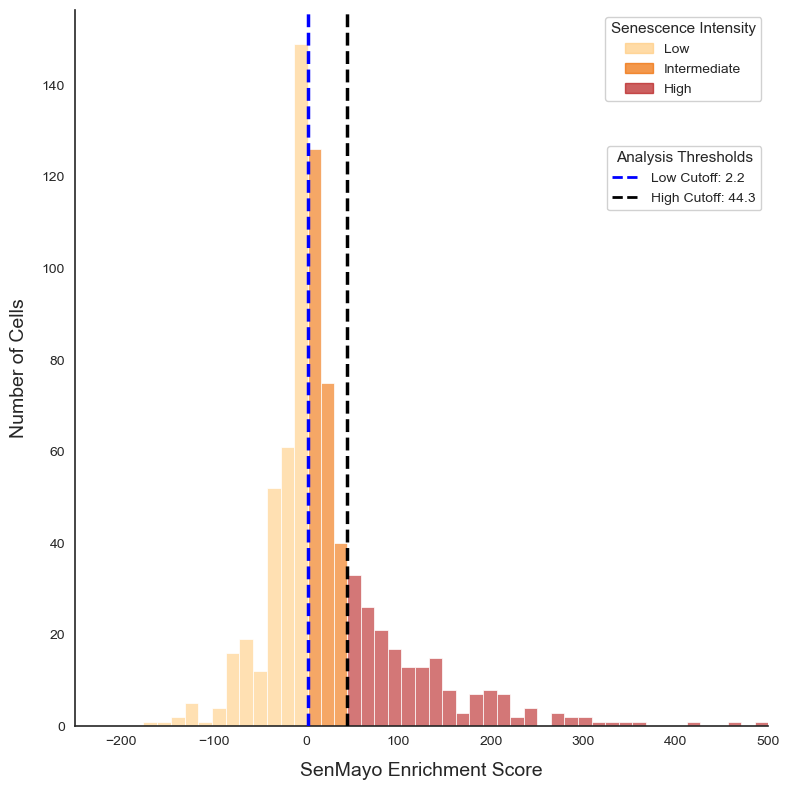

In [ ]:
import scanpy as sc
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

# 1. LOAD DATA
adata = sc.read_h5ad("Old_Hepatocytes_3Groups_for_VastTools.h5ad")

# 2. CONFIGURATION
target_score = 'SenMayo_score'
group_order = ['Low_Senescence', 'Intermediate_Senescence', 'High_Senescence']

# UPDATED PALETTE: Light Orange, Dark Orange, Red for Senescence Conditions
palette = {
    'Low_Senescence': '#ffcc80',        # Light Orange
    'Intermediate_Senescence': '#ef6c00', # Dark Orange
    'High_Senescence': '#b71c1c'         # Red
}

# PRESERVED AGE PALETTE: (For reference if you switch hue to 'age')
age_palette = {
    '3m': '#2ecc71',   # Green
    '18m': '#f1c40f',  # Yellow/Orange
    '24m': '#e74c3c'   # Red
}

t_low = 2.2
t_high = 44.3

# 3. DATA PREPARATION
df_plot = adata.obs.copy()
df_plot[target_score] = pd.to_numeric(df_plot[target_score], errors='coerce')
df_plot = df_plot.dropna(subset=[target_score])

# 4. UNIFORM BIN WIDTH LOGIC
x_min, x_max = -250, 500
bin_width = 15 

def generate_aligned_bins(start, end, width):
    num_bins = max(1, int(np.ceil((end - start) / width)))
    return np.linspace(start, end, num_bins + 1)

bins_low = generate_aligned_bins(x_min, t_low, bin_width)
bins_inter = generate_aligned_bins(t_low, t_high, bin_width)
bins_high = generate_aligned_bins(t_high, x_max, bin_width)

custom_bins = np.unique(np.concatenate([bins_low, bins_inter, bins_high]))

# 5. CREATE THE PLOT
fig, ax = plt.subplots(figsize=(8, 8))
sns.set_style("white")

sns.histplot(
    data=df_plot, 
    x=target_score, 
    hue='senescence_group', 
    hue_order=group_order,
    palette=palette,
    element="bars", 
    fill=True,
    alpha=0.6,         # Increased alpha slightly to make the orange gradient pop
    bins=custom_bins, 
    common_norm=False,
    ax=ax,
    legend=False,
    linewidth=0.5,
    edgecolor="white"
)

# 6. ADD DEFINITIVE THRESHOLD LINES
ax.axvline(t_low, color='blue', linestyle='--', linewidth=2.5, alpha=1, zorder=5)
ax.axvline(t_high, color='black', linestyle='--', linewidth=2.5, alpha=1, zorder=5)

# 7. MANUALLY BUILD CLEAN DUAL LEGENDS
cond_handles = [
    mpatches.Patch(color=palette['Low_Senescence'], alpha=0.7, label='Low'),
    mpatches.Patch(color=palette['Intermediate_Senescence'], alpha=0.7, label='Intermediate'),
    mpatches.Patch(color=palette['High_Senescence'], alpha=0.7, label='High')
]

line_handles = [
    Line2D([0], [0], color='blue', linestyle='--', lw=2, label=f'Low Cutoff: {t_low}'),
    Line2D([0], [0], color='black', linestyle='--', lw=2, label=f'High Cutoff: {t_high}')
]

leg1 = ax.legend(handles=cond_handles, title="Senescence Intensity", loc='upper right', 
                  frameon=True, framealpha=0.9, fontsize=10, title_fontsize=11)
ax.add_artist(leg1)

ax.legend(handles=line_handles, title="Analysis Thresholds", loc='upper right', 
          bbox_to_anchor=(1, 0.82), frameon=True, framealpha=0.9, fontsize=10, title_fontsize=11)

# 8. FINAL AXIS CLEANUP
ax.set_xlabel("SenMayo Enrichment Score", fontsize=14, labelpad=10)
ax.set_ylabel("Number of Cells", fontsize=14, labelpad=10)
ax.set_xlim(x_min, x_max)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

sns.despine()
plt.tight_layout()
plt.show()

INTRON RETENTION COMPARISON BETWEEN CONDITIONS

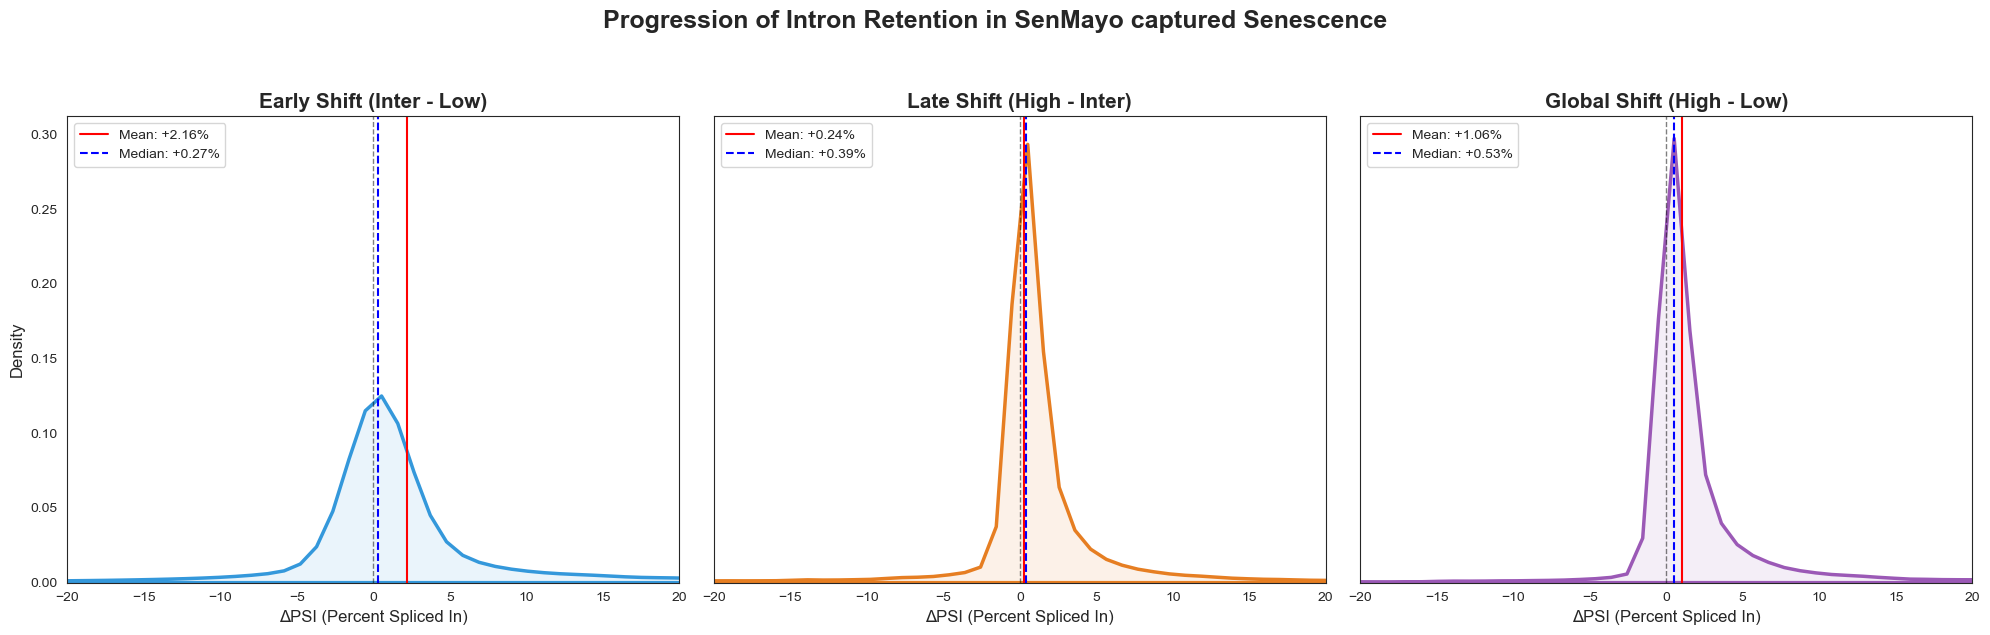

Intron Retention Summary (Events with ΔPSI ≠ 0):
Comparison                     | Count    | Mean Shift   | Median Shift
---------------------------------------------------------------------------
Early Shift (Inter - Low)      | 16026    |       +2.16% |       +0.27%
Late Shift (High - Inter)      | 43690    |       +0.24% |       +0.39%
Global Shift (High - Low)      | 42690    |       +1.06% |       +0.53%


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD AND CLEAN DATA
file_name = "INCLUSION_LEVELS_FULL-mm10-3_3groups.tab"
df_full = pd.read_csv(file_name, sep='\t')

# Filter strictly for Intron Retention (INT)
df_ir = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()

# Convert conditions to numeric
conditions = ['High_Senescence', 'Intermediate_Senescence', 'Low_Senescence']
for col in conditions:
    df_ir[col] = pd.to_numeric(df_ir[col], errors='coerce')

# Drop rows where any of the three measurements are missing to ensure a balanced comparison
df_ir = df_ir.dropna(subset=conditions)

# 2. CALCULATE THE THREE DELTAS
# Positive values always mean "Increased Retention" in the more senescent group
df_ir['dPSI_Global'] = df_ir['High_Senescence'] - df_ir['Low_Senescence']
df_ir['dPSI_Late']   = df_ir['High_Senescence'] - df_ir['Intermediate_Senescence']
df_ir['dPSI_Early']  = df_ir['Intermediate_Senescence'] - df_ir['Low_Senescence']

# Define the comparisons for the loop
comparisons = [
    ('dPSI_Early',  'Early Shift (Inter - Low)',  '#3498db'), # Blue
    ('dPSI_Late',   'Late Shift (High - Inter)',  '#e67e22'), # Orange
    ('dPSI_Global', 'Global Shift (High - Low)',  '#9b59b6')  # Purple
]

# 3. PLOTTING
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

for i, (col, label, color) in enumerate(comparisons):
    # Filter for active events in this specific comparison (dPSI != 0)
    subset = df_ir[df_ir[col] != 0][col]
    
    if len(subset) == 0: continue
    
    mean_val = subset.mean()
    med_val = subset.median()
    
    # Plot Distribution
    sns.kdeplot(subset, ax=axes[i], color=color, linewidth=2.5, bw_adjust=0.5, fill=True, alpha=0.1)
    
    # Reference Lines
    axes[i].axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    axes[i].axvline(mean_val, color='red', linestyle='-', label=f'Mean: {mean_val:+.2f}%')
    axes[i].axvline(med_val, color='blue', linestyle='--', label=f'Median: {med_val:+.2f}%')
    
    # Labels and Style
    axes[i].set_title(label, fontsize=15, fontweight='bold')
    axes[i].set_xlabel('ΔPSI (Percent Spliced In)', fontsize=12)
    axes[i].set_ylabel('Density' if i == 0 else '', fontsize=12)
    axes[i].set_xlim(-20, 20)
    axes[i].legend(loc='upper left')

plt.suptitle("Progression of Intron Retention in SenMayo captured Senescence", fontsize=18, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# 4. STATISTICAL SUMMARY
print(f"Intron Retention Summary (Events with ΔPSI ≠ 0):")
print(f"{'Comparison':<30} | {'Count':<8} | {'Mean Shift':<12} | {'Median Shift'}")
print("-" * 75)
for col, label, _ in comparisons:
    subset = df_ir[df_ir[col] != 0][col]
    print(f"{label:<30} | {len(subset):<8} | {subset.mean():>+11.2f}% | {subset.median():>+11.2f}%")

---

NOW FOR A NEW DIVISION BETWEEN THE GROUPS, INSTEAD OF TWO THRESHOLDS ONLY SEPARATING HIGH AND LOW BETWEEN THE 95TH PERCENTILE OF THE YOUNG HEPATOCYTES

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np

# 1. LOAD DATA
print("Loading Liver Atlas...")
adata = sc.read_h5ad("Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad")

# 2. CONFIGURATION
target_col = 'cell_ontology_class'
target_val = 'hepatocyte'
young_age = '3m'
old_ages = ['18m', '24m']

# 3. CALCULATE THRESHOLD (Based on Young Hepatocytes)
# We use the 95th percentile of young cells as the single dividing line
young_scores = adata.obs.loc[
    (adata.obs[target_col] == target_val) & (adata.obs['age'] == young_age), 
    'SenMayo_score'
]

t_95 = young_scores.quantile(0.95)

# 4. PREPARE MASK FOR OLD HEPATOCYTES
old_hep_mask = (adata.obs[target_col] == target_val) & (adata.obs['age'].isin(old_ages))

# 5. APPLY TWO-WAY LABELS
# Initialize all as 'Exclude' to ensure we only capture our targeted old hepatocytes
adata.obs['senescence_group'] = 'Exclude'

# Logic: High (> t_95), Low (<= t_95)
is_high = old_hep_mask & (adata.obs['SenMayo_score'] > t_95)
is_low  = old_hep_mask & (adata.obs['SenMayo_score'] <= t_95)

adata.obs.loc[is_high, 'senescence_group'] = 'High_Senescence'
adata.obs.loc[is_low, 'senescence_group'] = 'Low_Senescence'

# 6. CREATE SUBSET AND REPORT
final_groups = ['High_Senescence', 'Low_Senescence']
final_subset = adata[adata.obs['senescence_group'].isin(final_groups)].copy()

print("="*70)
print(f"SPLICING ANALYSIS SUMMARY (Binary Split at 95th Pctl)")
print("="*70)
print(f"Dividing Threshold: {t_95:.4f}")
print("-" * 70)
print(f"Total cells assigned for VAST-TOOLS: {final_subset.n_obs}")

print("\nBreakdown by Group:")
print(final_subset.obs['senescence_group'].value_counts())

print("\nBreakdown by Age and Group:")
summary_table = pd.crosstab(final_subset.obs['age'], final_subset.obs['senescence_group'])
print(summary_table)
print("="*70)

# 7. SAVE WITH NEW FILENAME
output_name = "Old_Hepatocytes_95th_Senescence_Groups_for_VastTools.h5ad"
final_subset.write(output_name)

print(f"\n[DONE] File saved as: {output_name}")

Loading Liver Atlas...
SPLICING ANALYSIS SUMMARY (Binary Split at 95th Pctl)
Dividing Threshold: 44.3379
----------------------------------------------------------------------
Total cells assigned for VAST-TOOLS: 760

Breakdown by Group:
senescence_group
Low_Senescence     565
High_Senescence    195
Name: count, dtype: int64

Breakdown by Age and Group:
senescence_group  High_Senescence  Low_Senescence
age                                              
18m                            43             340
24m                           152             225

[DONE] File saved as: Old_Hepatocytes_95th_Senescence_Groups_for_VastTools.h5ad


HISTOGRAM DISTRIBUTION TO VISUALIZE THE CONDITIONS

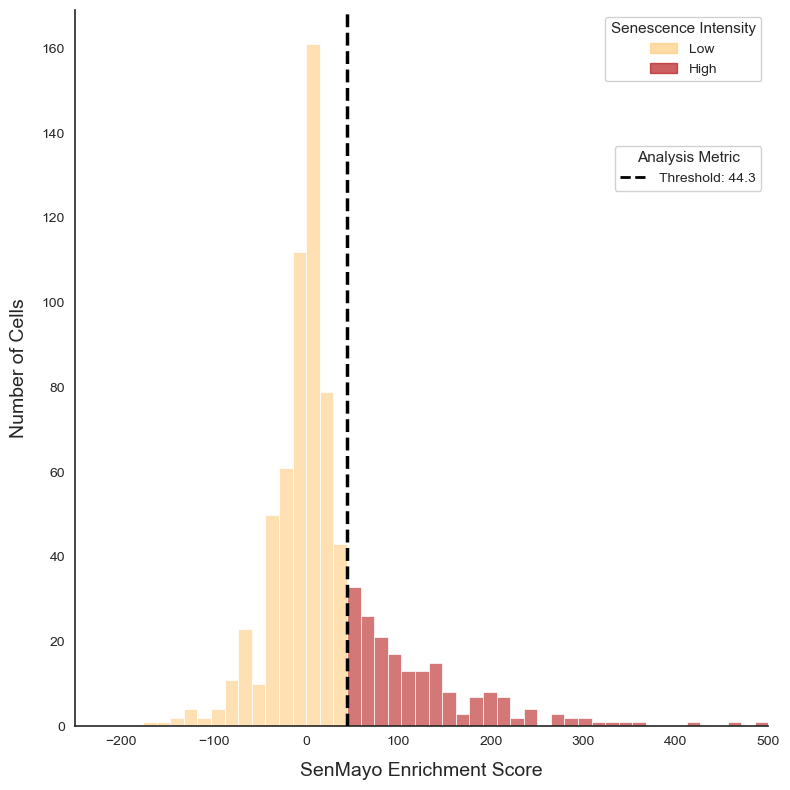

In [ ]:
import scanpy as sc
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

# 1. LOAD DATA
adata = sc.read_h5ad("Old_Hepatocytes_95th_Senescence_Groups_for_VastTools.h5ad")

# 2. CONFIGURATION
target_score = 'SenMayo_score'
group_order = ['Low_Senescence', 'High_Senescence']

# UPDATED PALETTE: Light Orange for Low, Red for High
palette = {
    'Low_Senescence': '#ffcc80',  # Light Orange
    'High_Senescence': '#b71c1c'   # Red
}

t_cutoff = 44.3

# 3. DATA PREPARATION
df_plot = adata.obs.copy()
df_plot[target_score] = pd.to_numeric(df_plot[target_score], errors='coerce')
df_plot = df_plot.dropna(subset=[target_score])

# 4. UNIFORM BIN WIDTH LOGIC
x_min, x_max = -250, 500
bin_width = 15 

def generate_aligned_bins(start, end, width):
    num_bins = max(1, int(np.ceil((end - start) / width)))
    return np.linspace(start, end, num_bins + 1)

bins_low = generate_aligned_bins(x_min, t_cutoff, bin_width)
bins_high = generate_aligned_bins(t_cutoff, x_max, bin_width)
custom_bins = np.unique(np.concatenate([bins_low, bins_high]))

# 5. CREATE THE SQUARE PLOT
fig, ax = plt.subplots(figsize=(8, 8))
sns.set_style("white")

sns.histplot(
    data=df_plot, 
    x=target_score, 
    hue='senescence_group', 
    hue_order=group_order,
    palette=palette,
    element="bars", 
    fill=True,
    alpha=0.6,        # Increased alpha for the orange/red gradient visibility
    bins=custom_bins, 
    common_norm=False,
    ax=ax,
    legend=False,
    linewidth=0.5,
    edgecolor="white"
)

# 6. ADD THE SINGLE CUTOFF LINE
ax.axvline(t_cutoff, color='black', linestyle='--', linewidth=2.5, alpha=1, zorder=10)

# 7. MANUALLY BUILD CLEAN DUAL LEGENDS
cond_handles = [
    mpatches.Patch(color=palette['Low_Senescence'], alpha=0.7, label='Low'),
    mpatches.Patch(color=palette['High_Senescence'], alpha=0.7, label='High')
]

line_handles = [
    Line2D([0], [0], color='black', linestyle='--', lw=2, label=f'Threshold: {t_cutoff}')
]

# Legend 1: Groups
leg1 = ax.legend(handles=cond_handles, title="Senescence Intensity", loc='upper right', 
                  frameon=True, framealpha=0.9, fontsize=10, title_fontsize=11)
ax.add_artist(leg1)

# Legend 2: Metric
ax.legend(handles=line_handles, title="Analysis Metric", loc='upper right', 
          bbox_to_anchor=(1, 0.82), frameon=True, framealpha=0.9, fontsize=10, title_fontsize=11)

# 8. FINAL AXIS CLEANUP
ax.set_xlabel("SenMayo Enrichment Score", fontsize=14, labelpad=10)
ax.set_ylabel("Number of Cells", fontsize=14, labelpad=10)
ax.set_xlim(x_min, x_max)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

sns.despine()
plt.tight_layout()
plt.show()

INTRON RETENTION COMPARISON BETWEEN CONDITIONS

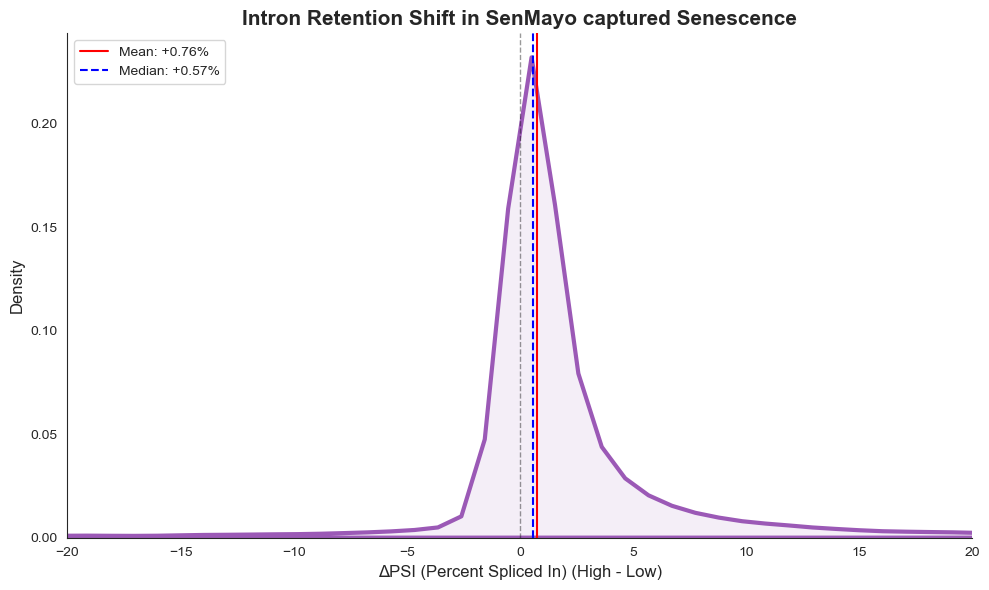

Summary for Intron Retention (INT):
Total Active Events: 50284
Mean Change:    +0.76%
Median Change:  +0.57%


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD AND CLEAN DATA
file_name = "INCLUSION_LEVELS_FULL-mm10-2_95th_split.tab"
df_full = pd.read_csv(file_name, sep='\t')

# Only focus on Intron Retention (INT)
df_int = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()

# Convert columns to numeric (Handles High and Low only)
target_cols = ['High_Senescence', 'Low_Senescence']
for col in target_cols:
    df_int[col] = pd.to_numeric(df_int[col], errors='coerce')

# Drop missing values
df_int = df_int.dropna(subset=target_cols)

# 2. CALCULATE DELTA PSI
# Calculation: High - Low
df_int['dPSI'] = df_int['High_Senescence'] - df_int['Low_Senescence']

# Remove exact 0s to focus on "active" splicing changes
df_active = df_int[df_int['dPSI'] != 0].copy()

# 3. PLOT (Using the "Global Shift" Purple Style)
plt.figure(figsize=(10, 6))

# KDE Plot with Fill (Purple theme from the progression plot)
sns.kdeplot(df_active['dPSI'], color='#9b59b6', linewidth=3, 
            fill=True, alpha=0.1, bw_adjust=0.5)

mean_val = df_active['dPSI'].mean()
median_val = df_active['dPSI'].median()

# Reference Lines
plt.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.4) # Zero baseline

# Mean Line (Solid Red) - Legend formatted without the word "Shift"
plt.axvline(mean_val, color='red', linestyle='-', 
            label=f'Mean: {mean_val:+.2f}%')

# Median Line (Dashed Blue) - Legend formatted without the word "Shift"
plt.axvline(median_val, color='blue', linestyle='--', 
            label=f'Median: {median_val:+.2f}%')

# 4. FORMATTING
plt.title("Intron Retention Shift in SenMayo captured Senescence", fontsize=15, fontweight='bold')
plt.xlabel('ΔPSI (Percent Spliced In) (High - Low)', fontsize=12)
plt.ylabel('Density', fontsize=12)

# X-Axis Limit: Focused on -20 to +20 range
plt.xlim(-20, 20) 
plt.legend(loc='upper left', frameon=True)

sns.despine() # Clean look
plt.tight_layout()
plt.show()

# 5. SUMMARY OUTPUT
print(f"Summary for Intron Retention (INT):")
print(f"Total Active Events: {len(df_active)}")
print(f"Mean Change:   {mean_val:>+6.2f}%")
print(f"Median Change: {median_val:>+6.2f}%")

---

BASED ON THE SPLICING FACTOR GENE SET SCORE LETS ADD THE INTERMEDIATE GROUP JUST AS BEFORE

FOR THE SPLICE FACTOR GENE SET THE DELTA PSI WAS CALCULATED AS LOW - HIGH, INSTEAD OF HIGH - LOW. THIS WAS DUE TO THE SENESCENT ASSOCIATED CONDITIONS CHANGING, IN THIS CASE THE DOWNREGULATION OF SPLICE FACTOR IS ASSOCIATED WITH SENESCENCE JUST AS THE HIGH SENESCENT SIGNATURE SCORE IS ALSO ASSOCIATED.

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import os

# =============================================================================
# 1. LOAD DATA & ISOLATE ALL HEPATOCYTES (Context for the score)
# =============================================================================
print("Loading Liver Atlas...")
adata = sc.read_h5ad("Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad")

# Isolate ALL ages of hepatocytes first to provide a healthy reference baseline
print("Isolating all hepatocytes (3m, 18m, 24m) for scoring context...")
adata_heps = adata[adata.obs['cell_ontology_class'] == 'hepatocyte'].copy()

# Align var index to gene symbols
if 'mouse_gene_symbols' in adata_heps.var.columns:
    adata_heps.var_names = adata_heps.var['mouse_gene_symbols'].astype(str)
    adata_heps.var_names_make_unique()

# =============================================================================
# 2. LOAD SPLICING GENES & CALCULATE GLOBAL SCORE
# =============================================================================
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

all_splicing_genes = []
for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            valid = [g for g in [l.strip() for l in lines[1:]] if g in adata_heps.var_names]
            all_splicing_genes.extend(valid)

all_splicing_genes = list(set(all_splicing_genes))

# SCORE THE ENTIRE LIFESPAN
# This ensures 3m cells are used to define the "healthy" background
print(f"Calculating GLOBAL splicing score for {len(adata_heps)} cells...")
sc.tl.score_genes(adata_heps, all_splicing_genes, score_name='splicing_score')

# =============================================================================
# 3. SUBSET FOR OLD HEPATOCYTES (18m & 24m)
# =============================================================================
print("Focusing on 18m and 24m cells for group assignment...")
adata_old = adata_heps[adata_heps.obs['age'].isin(['18m', '24m'])].copy()

# =============================================================================
# 4. DEFINE 20/80 GROUPS (Based on the Global Score)
# =============================================================================
t_low = adata_old.obs['splicing_score'].quantile(0.20)
t_high = adata_old.obs['splicing_score'].quantile(0.80)

adata_old.obs['splicing_group'] = 'Intermediate_Splicing'
adata_old.obs.loc[adata_old.obs['splicing_score'] <= t_low, 'splicing_group'] = 'Impaired_Splicing'
adata_old.obs.loc[adata_old.obs['splicing_score'] >= t_high, 'splicing_group'] = 'Healthy_Splicing'

# =============================================================================
# 5. FINAL REPORT & SAVE
# =============================================================================
print("\n" + "="*70)
print(f"SPLICING MACHINERY GROUPING SUMMARY (Global Baseline)")
print("="*70)
print(f"Low Threshold (Bottom 20% of Old):  {t_low:.4f}")
print(f"High Threshold (Top 20% of Old):    {t_high:.4f}")
print("-" * 70)
print(adata_old.obs['splicing_group'].value_counts())
print("-" * 70)
print("Breakdown by Age:")
print(pd.crosstab(adata_old.obs['age'], adata_old.obs['splicing_group']))
print("="*70)

Loading Liver Atlas...
Isolating all hepatocytes (3m, 18m, 24m) for scoring context...
Calculating GLOBAL splicing score for 1161 cells...
Focusing on 18m and 24m cells for group assignment...

SPLICING MACHINERY GROUPING SUMMARY (Global Baseline)
Low Threshold (Bottom 20% of Old):  -58.1500
High Threshold (Top 20% of Old):    -1.7650
----------------------------------------------------------------------
splicing_group
Intermediate_Splicing    456
Impaired_Splicing        152
Healthy_Splicing         152
Name: count, dtype: int64
----------------------------------------------------------------------
Breakdown by Age:
splicing_group  Healthy_Splicing  Impaired_Splicing  Intermediate_Splicing
age                                                                       
18m                           81                 35                    267
24m                           71                117                    189

[SUCCESS] File saved as: Old_Hepatocytes_Splicing_3groups.h5ad


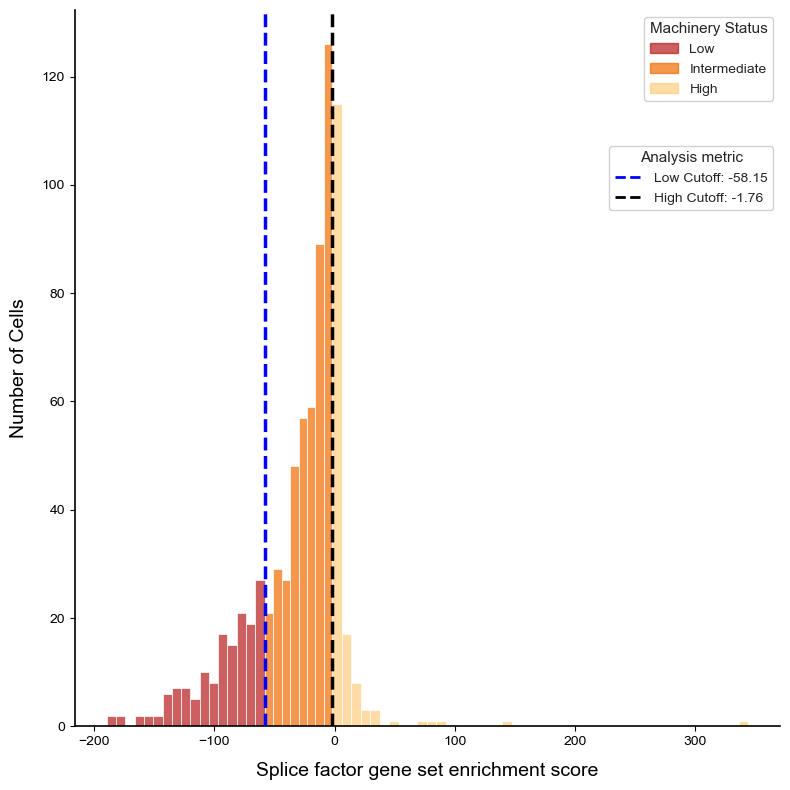

In [ ]:
import scanpy as sc
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

# 1. LOAD DATA
# Using the specific file created for the 20/60/20 splicing tails
adata = sc.read_h5ad("Old_Hepatocytes_Splicing_3groups.h5ad")

# 2. CONFIGURATION
target_score = 'splicing_score'
# Using the group names from the h5ad file
group_order = ['Impaired_Splicing', 'Intermediate_Splicing', 'Healthy_Splicing']

# PALETTE: Low Score = Red, Mid = Dark Orange, High Score = Light Orange
palette = {
    'Impaired_Splicing': '#b71c1c',      # Red (Impaired)
    'Intermediate_Splicing': '#ef6c00', # Dark Orange
    'Healthy_Splicing': '#ffcc80'       # Light Orange (Healthy)
}

# Retrieve thresholds (P20 and P80)
t_low = adata.obs[target_score].quantile(0.20)
t_high = adata.obs[target_score].quantile(0.80)

# 3. DATA PREPARATION
df_plot = adata.obs.copy()
df_plot[target_score] = pd.to_numeric(df_plot[target_score], errors='coerce')
df_plot = df_plot.dropna(subset=[target_score])

# 4. UNIFORM BIN WIDTH LOGIC (Aligned to thresholds)
x_min, x_max = df_plot[target_score].min(), df_plot[target_score].max()
bin_width = 8 

def generate_aligned_bins(start, end, width):
    num_bins = max(1, int(np.ceil(abs(end - start) / width)))
    return np.linspace(start, end, num_bins + 1)

bins_low = generate_aligned_bins(x_min, t_low, bin_width)
bins_inter = generate_aligned_bins(t_low, t_high, bin_width)
bins_high = generate_aligned_bins(t_high, x_max, bin_width)
custom_bins = np.unique(np.concatenate([bins_low, bins_inter, bins_high]))

# 5. CREATE THE PLOT
fig, ax = plt.subplots(figsize=(8, 8))
sns.set_style("white")

sns.histplot(
    data=df_plot, 
    x=target_score, 
    hue='splicing_group', 
    hue_order=group_order,
    palette=palette,
    element="bars", 
    fill=True,
    alpha=0.7,         # High opacity to distinguish the orange shades
    bins=custom_bins, 
    common_norm=False,
    ax=ax,
    legend=False,
    linewidth=0.5,
    edgecolor="white"
)

# 6. ADD DEFINITIVE THRESHOLD LINES
ax.axvline(t_low, color='blue', linestyle='--', linewidth=2.5, alpha=1, zorder=5)
ax.axvline(t_high, color='black', linestyle='--', linewidth=2.5, alpha=1, zorder=5)

# 7. MANUALLY BUILD CLEAN DUAL LEGENDS
# Legend 1: Machinery Conditions
cond_handles = [
    mpatches.Patch(color=palette['Impaired_Splicing'], alpha=0.7, label='Low'),
    mpatches.Patch(color=palette['Intermediate_Splicing'], alpha=0.7, label='Intermediate'),
    mpatches.Patch(color=palette['Healthy_Splicing'], alpha=0.7, label='High')
]

# Legend 2: Analysis Thresholds
line_handles = [
    Line2D([0], [0], color='blue', linestyle='--', lw=2, label=f'Low Cutoff: {t_low:.2f}'),
    Line2D([0], [0], color='black', linestyle='--', lw=2, label=f'High Cutoff: {t_high:.2f}')
]

leg1 = ax.legend(handles=cond_handles, title="Machinery Status", loc='upper right', 
                  frameon=True, framealpha=0.9, fontsize=10, title_fontsize=11)
ax.add_artist(leg1)

ax.legend(handles=line_handles, title="Analysis metric", loc='upper right', 
          bbox_to_anchor=(1, 0.82), frameon=True, framealpha=0.9, fontsize=10, title_fontsize=11)

# 8. FINAL AXIS CLEANUP
ax.set_xlabel("Splice factor gene set enrichment score", fontsize=14, labelpad=10)
ax.set_ylabel("Number of Cells", fontsize=14, labelpad=10)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

sns.despine()
plt.tight_layout()
plt.savefig("Splicing_Machinery_OrangeRed_Final.png", dpi=300)
plt.show()

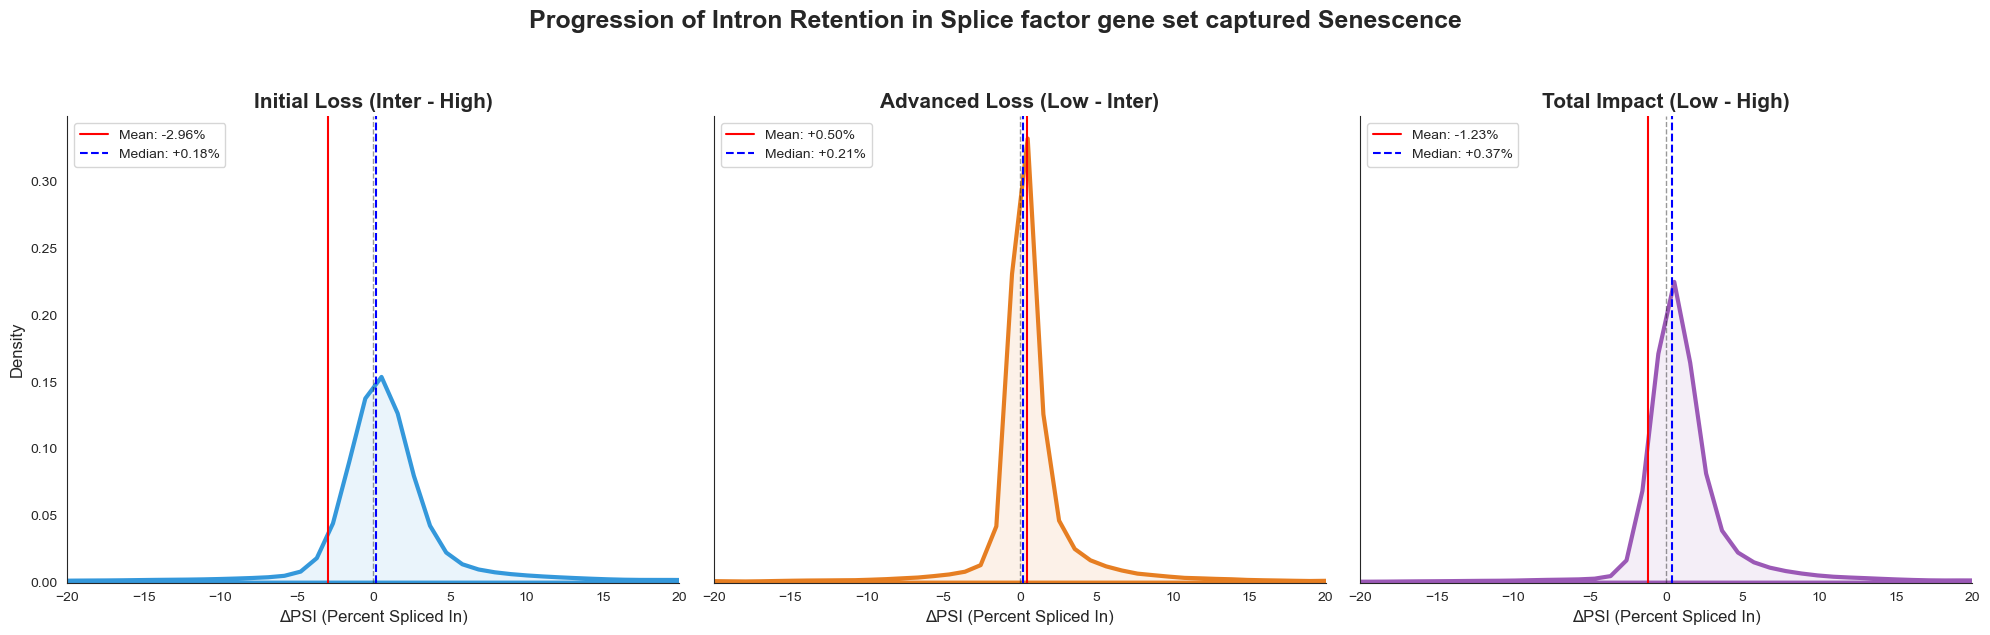

Summary of Splicing Failures (Events where ΔPSI ≠ 0):
Comparison Stage                    | Count    | Mean Shift   | Median Shift
--------------------------------------------------------------------------------
Initial Loss (Inter - High)         | 20973    |       -2.96% |       +0.18%
Advanced Loss (Low - Inter)         | 37441    |       +0.50% |       +0.21%
Total Impact (Low - High)           | 35455    |       -1.23% |       +0.37%


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. LOAD AND CLEAN DATA
file_name = "INCLUSION_LEVELS_FULL-mm10-3_splicing_3way.tab"
df_full = pd.read_csv(file_name, sep='\t')

# Filter strictly for Intron Retention (INT)
df_ir = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()

# Define machinery conditions
conditions = ['Healthy_Splicing', 'Intermediate_Splicing', 'Impaired_Splicing']

# Convert to numeric
for col in conditions:
    df_ir[col] = pd.to_numeric(df_ir[col], errors='coerce')

# Drop rows with missing measurements
df_ir = df_ir.dropna(subset=conditions)

# 2. CALCULATE THE THREE DELTAS
# Direction: Impaired - Healthy (Positive = Failure/Increased Retention)
df_ir['dPSI_Early']  = df_ir['Intermediate_Splicing'] - df_ir['Healthy_Splicing']
df_ir['dPSI_Late']   = df_ir['Impaired_Splicing'] - df_ir['Intermediate_Splicing']
df_ir['dPSI_Global'] = df_ir['Impaired_Splicing'] - df_ir['Healthy_Splicing']

# Define the comparisons using the coloring from the first code
comparisons = [
    ('dPSI_Early',  'Initial Loss (Inter - High)',  '#3498db'), # Blue
    ('dPSI_Late',   'Advanced Loss (Low - Inter)', '#e67e22'), # Orange
    ('dPSI_Global', 'Total Impact (Low - High)',  '#9b59b6')  # Purple
]

# 3. PLOTTING
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
sns.set_style("white")

for i, (col, label, color) in enumerate(comparisons):
    # Filter for active events (dPSI != 0)
    subset = df_ir[df_ir[col] != 0][col]
    
    if len(subset) == 0:
        axes[i].set_title(f"{label}\n(No Active Events)")
        continue
    
    mean_val = subset.mean()
    med_val = subset.median()
    
    # Continuous Distribution (KDE) with Shaded Fill
    sns.kdeplot(subset, ax=axes[i], color=color, linewidth=3, 
                bw_adjust=0.5, fill=True, alpha=0.1)
    
    # Reference and Statistical Lines
    axes[i].axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.4)
    
    # Legend formatted without the word "Shift"
    axes[i].axvline(mean_val, color='red', linestyle='-', 
                    label=f'Mean: {mean_val:+.2f}%')
    axes[i].axvline(med_val, color='blue', linestyle='--', 
                    label=f'Median: {med_val:+.2f}%')
    
    # Formatting
    axes[i].set_title(label, fontsize=15, fontweight='bold')
    # Added (Impaired - Healthy) to label
    axes[i].set_xlabel('ΔPSI (Percent Spliced In)', fontsize=12)
    axes[i].set_ylabel('Density' if i == 0 else '', fontsize=12)
    axes[i].set_xlim(-20, 20)
    axes[i].legend(loc='upper left', frameon=True, fontsize=10)

plt.suptitle("Progression of Intron Retention in Splice factor gene set captured Senescence", 
             fontsize=18, fontweight='bold', y=1.05)

sns.despine() # Clean look
plt.tight_layout()
plt.show()

# 4. STATISTICAL SUMMARY
print(f"Summary of Splicing Failures (Events where ΔPSI ≠ 0):")
print(f"{'Comparison Stage':<35} | {'Count':<8} | {'Mean Shift':<12} | {'Median Shift'}")
print("-" * 80)
for col, label, _ in comparisons:
    subset = df_ir[df_ir[col] != 0][col]
    print(f"{label:<35} | {len(subset):<8} | {subset.mean():>+11.2f}% | {subset.median():>+11.2f}%")

---

BASED ON THE SPLICING FACTOR GENE SET SCORE LETS MAKE IT SO THAT THERE IS ONLY ONE THRESHOLD, THEREBY CREATING TWO CONDITIONS WHILST UTILIZING ALL OLD HEPATOCYTES

In [29]:
import scanpy as sc
import pandas as pd
import numpy as np
import os

# =============================================================================
# 1. LOAD DATA & GLOBAL SCORING (Context)
# =============================================================================
print("Loading Liver Atlas...")
adata = sc.read_h5ad("Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad")

# 1a. Isolate all hepatocytes for a healthy baseline context
print("Isolating all hepatocytes (3m, 18m, 24m) for global scoring context...")
adata_heps = adata[adata.obs['cell_ontology_class'] == 'hepatocyte'].copy()

# 1b. Align var index to gene symbols
if 'mouse_gene_symbols' in adata_heps.var.columns:
    adata_heps.var_names = adata_heps.var['mouse_gene_symbols'].astype(str)
    adata_heps.var_names_make_unique()

# 2. LOAD SPLICING GENES & CALCULATE GLOBAL SCORE
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

all_splicing_genes = []
for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            valid = [g for g in [l.strip() for l in lines[1:]] if g in adata_heps.var_names]
            all_splicing_genes.extend(valid)

all_splicing_genes = list(set(all_splicing_genes))

# SCORE THE ENTIRE LIFESPAN
print(f"Calculating GLOBAL splicing score for {len(adata_heps)} cells...")
sc.tl.score_genes(adata_heps, all_splicing_genes, score_name='splicing_score')

# =============================================================================
# 3. SUBSET FOR OLD HEPATOCYTES (18m & 24m)
# =============================================================================
print("Isolating 18m and 24m hepatocytes for grouping...")
adata_old = adata_heps[adata_heps.obs['age'].isin(['18m', '24m'])].copy()

# =============================================================================
# 4. APPLY 80th PERCENTILE SPLIT
# =============================================================================
# Mathematically: Percentile 80 = Quantile 0.8
threshold_80 = adata_old.obs['splicing_score'].quantile(0.80)

# Assign groups: 
# High_Splicing = Top 20% of old cells
# Low_Splicing = Bottom 80% of old cells
adata_old.obs['splicing_group'] = np.where(
    adata_old.obs['splicing_score'] > threshold_80, 
    "High_Splicing", 
    "Low_Splicing"
)

# =============================================================================
# 5. FINAL REPORT & SAVE
# =============================================================================
print("\n" + "="*70)
print(f"SPLICING MACHINERY BINARY ANALYSIS (80th Percentile Split)")
print("="*70)
print(f"Threshold Value (80th Pctl): {threshold_80:.4f}")
print("-" * 70)
print("Breakdown by Group:")
print(adata_old.obs['splicing_group'].value_counts())
print("-" * 70)
print("Breakdown by Age:")
print(pd.crosstab(adata_old.obs['age'], adata_old.obs['splicing_group']))
print("="*70)

# Save the file
output_name = "Old_Hepatocytes_Splicing_80th_split.h5ad"
adata_old.write(output_name)

print(f"\n[DONE] Saved as: {output_name}")

Loading Liver Atlas...
Isolating all hepatocytes (3m, 18m, 24m) for global scoring context...
Calculating GLOBAL splicing score for 1161 cells...
Isolating 18m and 24m hepatocytes for grouping...

SPLICING MACHINERY BINARY ANALYSIS (80th Percentile Split)
Threshold Value (80th Pctl): -1.7650
----------------------------------------------------------------------
Breakdown by Group:
splicing_group
Low_Splicing     608
High_Splicing    152
Name: count, dtype: int64
----------------------------------------------------------------------
Breakdown by Age:
splicing_group  High_Splicing  Low_Splicing
age                                        
18m                        81           302
24m                        71           306

[DONE] Saved as: Old_Hepatocytes_Splicing_80th_split.h5ad


Loading Liver Atlas...
Calculating GLOBAL splicing score for 1161 cells...
Isolating 18m and 24m hepatocytes...


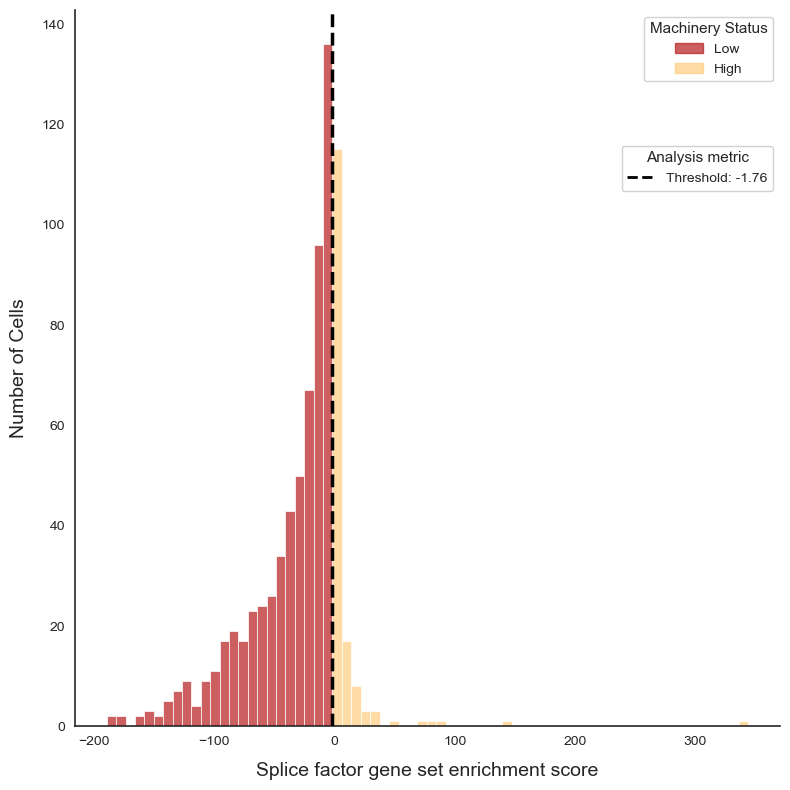

In [31]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

# =============================================================================
# 1. LOAD DATA & GLOBAL SCORING
# =============================================================================
print("Loading Liver Atlas...")
adata = sc.read_h5ad("Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad")

# Isolate ALL hepatocytes for global scoring context
adata_heps = adata[adata.obs['cell_ontology_class'] == 'hepatocyte'].copy()

if 'mouse_gene_symbols' in adata_heps.var.columns:
    adata_heps.var_names = adata_heps.var['mouse_gene_symbols'].astype(str)
    adata_heps.var_names_make_unique()

# Load Splicing Genes
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

all_splicing_genes = []
for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            valid = [g for g in [l.strip() for l in lines[1:]] if g in adata_heps.var_names]
            all_splicing_genes.extend(valid)
all_splicing_genes = list(set(all_splicing_genes))

print(f"Calculating GLOBAL splicing score for {len(adata_heps)} cells...")
sc.tl.score_genes(adata_heps, all_splicing_genes, score_name='splicing_score')

# =============================================================================
# 2. SUBSET FOR OLD HEPATOCYTES & DEFINE 80th PERCENTILE
# =============================================================================
print("Isolating 18m and 24m hepatocytes...")
adata_old = adata_heps[adata_heps.obs['age'].isin(['18m', '24m'])].copy()

# Calculate the 80th Percentile (Quantile 0.80)
t_80 = adata_old.obs['splicing_score'].quantile(0.80)

# Create two groups based on the 80th percentile
adata_old.obs['splicing_group'] = np.where(
    adata_old.obs['splicing_score'] > t_80, 
    "High_Splicing", 
    "Low_Splicing"
)

# =============================================================================
# 3. UNIFORM BIN WIDTH LOGIC (Visual consistency)
# =============================================================================
bin_width = 8 
x_min, x_max = adata_old.obs['splicing_score'].min(), adata_old.obs['splicing_score'].max()

def generate_aligned_bins(start, end, width):
    num_bins = max(1, int(np.ceil(abs(end - start) / width)))
    return np.linspace(start, end, num_bins + 1)

bins_low = generate_aligned_bins(x_min, t_80, bin_width)
bins_high = generate_aligned_bins(t_80, x_max, bin_width)
custom_bins = np.unique(np.concatenate([bins_low, bins_high]))

# =============================================================================
# 4. VISUALIZATION (Red/Orange Binary Plot)
# =============================================================================
fig, ax = plt.subplots(figsize=(8, 8))
sns.set_style("white")

# PALETTE: Low = Red (Impaired), High = Light Orange (Healthy)
palette = {
    'Low_Splicing': '#b71c1c',  # Deep Red
    'High_Splicing': '#ffcc80'  # Light Orange
}

sns.histplot(
    data=adata_old.obs, 
    x='splicing_score', 
    hue='splicing_group', 
    hue_order=['Low_Splicing', 'High_Splicing'],
    palette=palette,
    element="bars", 
    fill=True,
    alpha=0.7, 
    bins=custom_bins, 
    common_norm=False,
    edgecolor="white",
    linewidth=0.5,
    legend=False,
    ax=ax
)

# Add the 80th Percentile Cutoff Line
ax.axvline(t_80, color='black', linestyle='--', linewidth=2.5, alpha=1, zorder=10)

# --- MANUALLY BUILD CLEAN DUAL LEGENDS ---
# Legend 1: Machinery Conditions
cond_handles = [
    mpatches.Patch(color=palette['Low_Splicing'], alpha=0.7, label='Low'),
    mpatches.Patch(color=palette['High_Splicing'], alpha=0.7, label='High')
]

# Legend 2: Analysis Metric
line_handles = [
    Line2D([0], [0], color='black', linestyle='--', lw=2, label=f'Threshold: {t_80:.2f}')
]

# Add Legend 1 (Groups)
leg1 = ax.legend(handles=cond_handles, title="Machinery Status", loc='upper right', 
                  frameon=True, framealpha=0.9, fontsize=10, title_fontsize=11)
ax.add_artist(leg1)

# Add Legend 2 (Metric)
ax.legend(handles=line_handles, title="Analysis metric", loc='upper right', 
          bbox_to_anchor=(1, 0.82), frameon=True, framealpha=0.9, fontsize=10, title_fontsize=11)

# Final formatting
ax.set_xlabel("Splice factor gene set enrichment score", fontsize=14, labelpad=10)
ax.set_ylabel("Number of Cells", fontsize=14, labelpad=10)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

sns.despine()
plt.tight_layout()
plt.show()


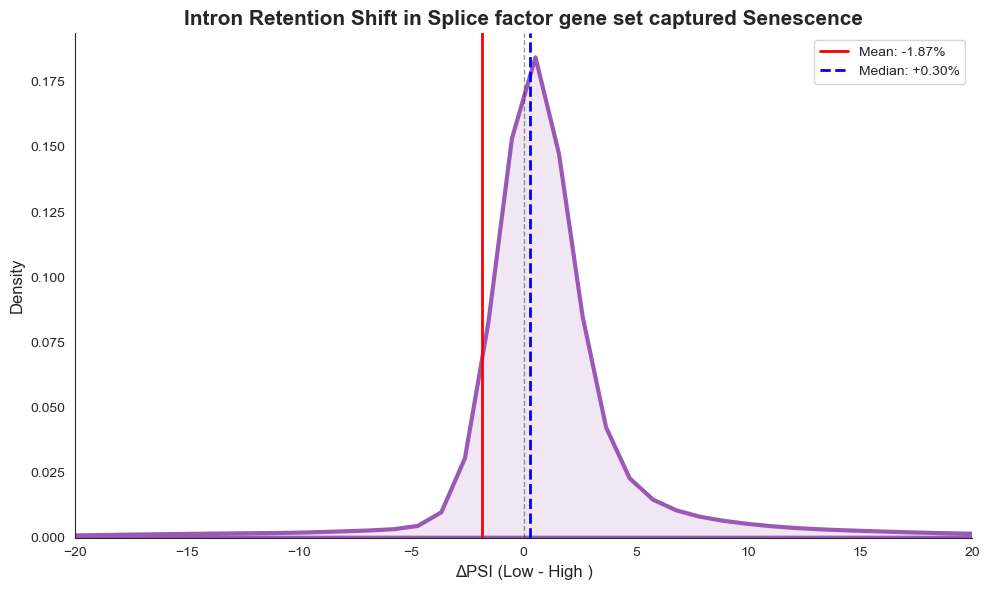

Summary for Intron Retention (INT):
Total Active Events: 29022
Mean Change:    -1.87%
Median Change:  +0.30%


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# =============================================================================
# 1. LOAD AND CLEAN DATA
# =============================================================================
file_name = "INCLUSION_LEVELS_FULL-mm10-2_splicing_80th.tab"
df_full = pd.read_csv(file_name, sep='\t')

# Only focus on Intron Retention (INT)
df_int = df_full[df_full['EVENT'].str.contains('INT', na=False)].copy()

# Column names from your 75th split file
target_cols = ['High_Splicing', 'Low_Splicing']

for col in target_cols:
    df_int[col] = pd.to_numeric(df_int[col], errors='coerce')

# Drop missing values
df_int = df_int.dropna(subset=target_cols)

# =============================================================================
# 2. CALCULATE DELTA PSI (Low - High)
# =============================================================================
# Calculation: Impaired (Low) - Healthy (High)
# Positive values = Increase in Intron Retention when machinery is low
df_int['dPSI'] = df_int['Low_Splicing'] - df_int['High_Splicing']

# Remove exact 0s to focus on "active" splicing changes
df_active = df_int[df_int['dPSI'] != 0].copy()

# =============================================================================
# 3. PLOT (Purple Global Shift Style)
# =============================================================================
plt.figure(figsize=(10, 6))

# KDE Plot with Purple Fill
sns.kdeplot(df_active['dPSI'], color='#9b59b6', linewidth=3, 
            fill=True, alpha=0.15, bw_adjust=0.5)

mean_val = df_active['dPSI'].mean()
median_val = df_active['dPSI'].median()

# Reference Lines
plt.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.4) # Zero baseline

# Mean Line (Solid Red)
plt.axvline(mean_val, color='red', linestyle='-', linewidth=2,
            label=f'Mean: {mean_val:+.2f}%')

# Median Line (Dashed Blue)
plt.axvline(median_val, color='blue', linestyle='--', linewidth=2,
            label=f'Median: {median_val:+.2f}%')

# =============================================================================
# 4. FORMATTING
# =============================================================================
plt.title("Intron Retention Shift in Splice factor gene set captured Senescence", fontsize=15, fontweight='bold')
plt.xlabel('ΔPSI (Low - High )', fontsize=12)
plt.ylabel('Density', fontsize=12)

# Standardized X-Axis Limit
plt.xlim(-20, 20) 
plt.legend(loc='upper right', frameon=True, fontsize=10)

sns.despine() # Clean look
plt.tight_layout()

# Save output
plt.savefig("Intron_Retention_75th_Shift_Purple.png", dpi=300)
plt.show()

# =============================================================================
# 5. SUMMARY OUTPUT
# =============================================================================
print(f"Summary for Intron Retention (INT):")
print(f"Total Active Events: {len(df_active)}")
print(f"Mean Change:   {mean_val:>+6.2f}%")
print(f"Median Change: {median_val:>+6.2f}%")

---

WORKFLOW FOR INTRON RETENTION ANALYSIS IN LSECs

HISTOGRAM DISTRIBUTION OF SENMAYO SCORED LSECs TO IDENTIFY THRESHOLDS FOR PSEUDOBULK CREATION

STRATEGY                            | LOW (Old) | INTER (Old) | HIGH (Old)
---------------------------------------------------------------------------
1. Original (Young Median/P95)      | 65         | 60          | 303       
2. Stricter High (Young Median/Max) | 65         | 95          | 268       
3. Population Balanced (Old Tertiles) | 141        | 141         | 146       
4. Distant Extremes (Old P25/P75)   | 107        | 214         | 107       


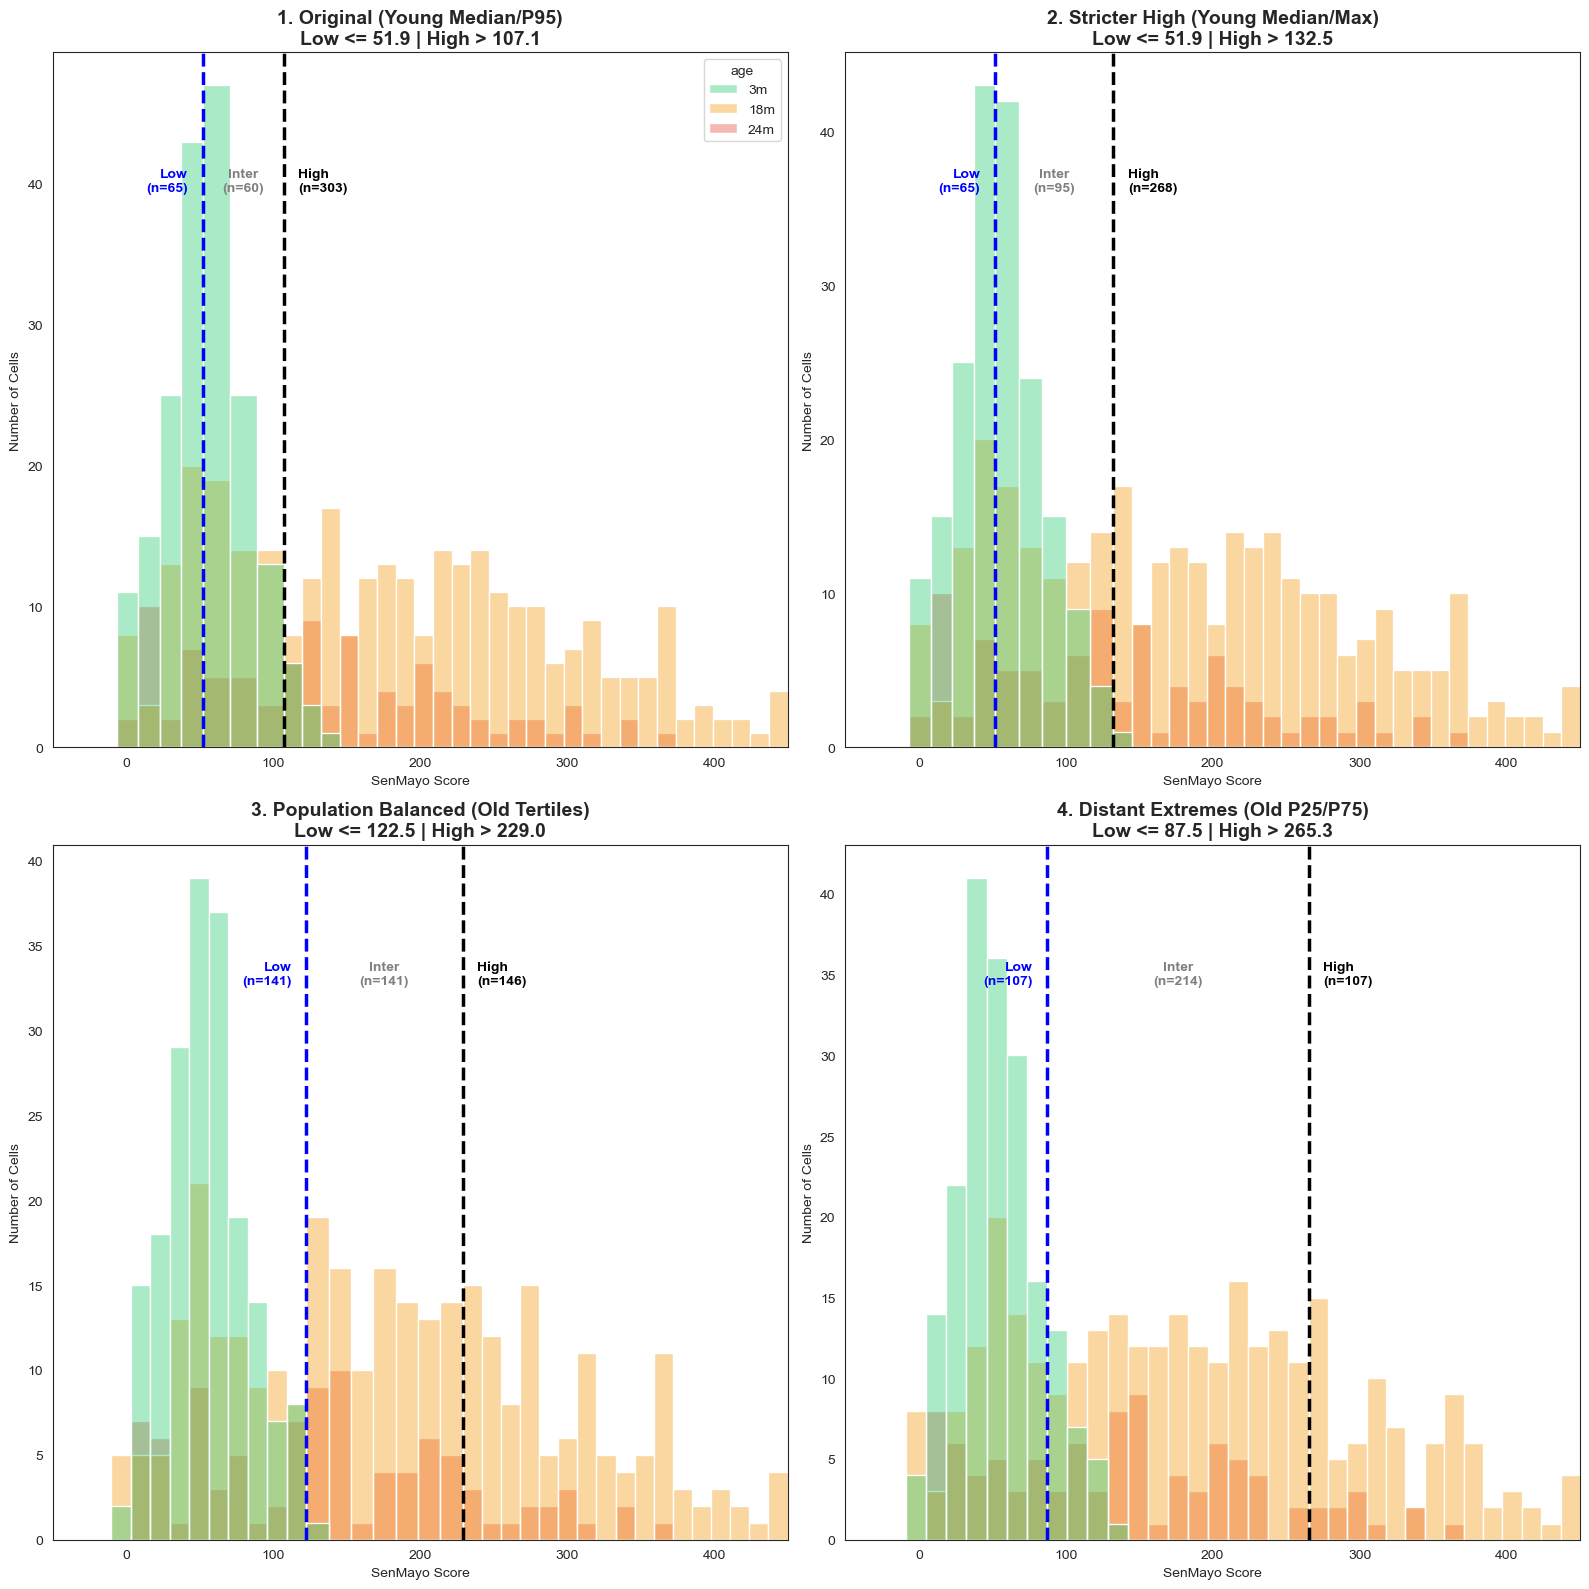

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches

# 1. LOAD DATA
adata = sc.read_h5ad("Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad")

# 2. CONFIGURATION
target_col = 'cell_ontology_class'
target_val = 'endothelial cell of hepatic sinusoid'
age_order = ['3m', '18m', '24m']
age_palette = {'3m': '#2ecc71', '18m': '#f39c12', '24m': '#e74c3c'}

# Subset the specific cell type for all ages
endo = adata[adata.obs[target_col] == target_val].copy()
endo.obs['SenMayo_score'] = pd.to_numeric(endo.obs['SenMayo_score'], errors='coerce')
endo = endo[~endo.obs['SenMayo_score'].isna()]

# Extract score vectors for threshold calculations
young_scores = endo.obs.loc[endo.obs['age'] == '3m', 'SenMayo_score']
old_scores = endo.obs.loc[endo.obs['age'].isin(['18m', '24m']), 'SenMayo_score']

# 3. DEFINE STRATEGIES
strategies = {
    "1. Original (Young Median/P95)": {
        'low': young_scores.median(),
        'high': young_scores.quantile(0.95)
    },
    "2. Stricter High (Young Median/Max)": {
        'low': young_scores.median(),
        'high': young_scores.max()
    },
    "3. Population Balanced (Old Tertiles)": {
        'low': old_scores.quantile(0.33),
        'high': old_scores.quantile(0.66)
    },
    "4. Distant Extremes (Old P25/P75)": {
        'low': old_scores.quantile(0.25),
        'high': old_scores.quantile(0.75)
    }
}

# 4. PLOTTING THE EXPLORATION GRID (Colored by Age)
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
axes = axes.flatten()
sns.set_style("white")

bin_width = 12
x_min, x_max = -50, 450 

def get_aligned_bins(start, t1, t2, end, width):
    b1 = np.linspace(start, t1, max(2, int((t1-start)/width)))
    b2 = np.linspace(t1, t2, max(2, int((t2-t1)/width)))
    b3 = np.linspace(t2, end, max(2, int((end-t2)/width)))
    return np.unique(np.concatenate([b1, b2, b3]))

print(f"{'STRATEGY':<35} | {'LOW (Old)':<6} | {'INTER (Old)':<10} | {'HIGH (Old)':<6}")
print("-" * 75)

for i, (name, thresh) in enumerate(strategies.items()):
    ax = axes[i]
    t_l, t_h = thresh['low'], thresh['high']
    
    # Statistics for the console (Old cells only for Vast-Tools groups)
    n_low = (old_scores <= t_l).sum()
    n_high = (old_scores > t_h).sum()
    n_inter = len(old_scores) - (n_low + n_high)
    print(f"{name:<35} | {n_low:<10} | {n_inter:<11} | {n_high:<10}")

    # Plot ALL AGES colored by age
    bins = get_aligned_bins(x_min, t_l, t_h, x_max, bin_width)
    sns.histplot(data=endo.obs, x='SenMayo_score', hue='age', hue_order=age_order,
                 palette=age_palette, bins=bins, element="bars", fill=True, alpha=0.4, 
                 common_norm=False, edgecolor="white", ax=ax, legend=(i==0))
    
    # Threshold Lines (Blue and Black)
    ax.axvline(t_l, color='blue', linestyle='--', lw=2.5, label='Low Cutoff', zorder=10)
    ax.axvline(t_h, color='black', linestyle='--', lw=2.5, label='High Cutoff', zorder=10)
    
    # Title and Labels
    ax.set_title(f"{name}\nLow <= {t_l:.1f} | High > {t_h:.1f}", fontsize=14, fontweight='bold')
    ax.set_xlabel("SenMayo Score")
    ax.set_ylabel("Number of Cells")
    ax.set_xlim(x_min, x_max)
    
    # Add count labels for Old cells in each zone for easy reference
    ax.text(t_l - 10, ax.get_ylim()[1]*0.8, f"Low\n(n={n_low})", color='blue', ha='right', fontweight='bold')
    ax.text((t_l+t_h)/2, ax.get_ylim()[1]*0.8, f"Inter\n(n={n_inter})", color='grey', ha='center', fontweight='bold')
    ax.text(t_h + 10, ax.get_ylim()[1]*0.8, f"High\n(n={n_high})", color='black', ha='left', fontweight='bold')

plt.tight_layout()
plt.show()


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np

# 1. LOAD DATA
adata = sc.read_h5ad("Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad")

# 2. CONFIGURATION
target_col = 'cell_ontology_class'
target_val = 'endothelial cell of hepatic sinusoid'
old_ages = ['18m', '24m']

# 3. SUBSET DATA FOR OLD ENDOTHELIAL CELLS
# We only use old cells to calculate these specific thresholds
mask_old_endo = (adata.obs[target_col] == target_val) & (adata.obs['age'].isin(old_ages))
df_old = adata.obs[mask_old_endo].copy()

# 4. CALCULATE TERTILES (33rd and 66th percentiles)
# Tertiles divide the population into 3 equal groups
t_low = df_old['SenMayo_score'].quantile(0.3333)
t_high = df_old['SenMayo_score'].quantile(0.6666)

print(f"Applying Strategy 3 (Old Tertiles) for {target_val}")
print(f"--- Low Threshold (33rd Pctl):  {t_low:.4f}")
print(f"--- High Threshold (66th Pctl): {t_high:.4f}")

# 5. APPLY LABELS TO THE ORIGINAL ADATA
adata.obs['senescence_group'] = 'Exclude'

# Condition masks
is_low = mask_old_endo & (adata.obs['SenMayo_score'] <= t_low)
is_high = mask_old_endo & (adata.obs['SenMayo_score'] > t_high)
is_inter = mask_old_endo & (adata.obs['SenMayo_score'] > t_low) & (adata.obs['SenMayo_score'] <= t_high)

adata.obs.loc[is_low, 'senescence_group'] = 'Low_Senescence'
adata.obs.loc[is_high, 'senescence_group'] = 'High_Senescence'
adata.obs.loc[is_inter, 'senescence_group'] = 'Intermediate_Senescence'

# 6. CREATE SUBSET AND SAVE
final_subset = adata[adata.obs['senescence_group'] != 'Exclude'].copy()

print("\nFinal Group Composition (Old Cells Only):")
print(final_subset.obs['senescence_group'].value_counts())

# Save
output_name = "Old_Endothelial_Tertile_Groups_for_VastTools.h5ad"
final_subset.write(output_name)

print(f"\n[DONE] File saved as: {output_name}")

Applying Strategy 3 (Old Tertiles) for endothelial cell of hepatic sinusoid
--- Low Threshold (33rd Pctl):  122.7117
--- High Threshold (66th Pctl): 231.8190

Final Group Composition (Old Cells Only):
senescence_group
Low_Senescence             143
High_Senescence            143
Intermediate_Senescence    142
Name: count, dtype: int64

[DONE] File saved as: Old_Endothelial_Tertile_Groups_for_VastTools.h5ad


TERTILES WERE DEFINED ONLY BY THE OLD CELLS, AND THIS STRATEGY WAS CHOSEN TO MAXIMIZE THE AMOUNT OF CELLS WITH WHICH WE ARE WORKING GIVEN THAT PSEUDOBULK REQUIRES A MINIMUM AMOUNT OF CELLS, AND BECAUSE THE DISTRIBUTION OF OLD CELLS IS FAIRLY EQUAL ACROSS THE SENMAYO SCORE

---

NOW IN LSECS BUT BASED ON THE SPLICING SCORE INSTEAD OF THE SENMAYO SCORE

Loading Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad...
Scoring using 339 splicing genes...
STRATEGY                            | IMPAIRED | INTER    | HEALTHY 
---------------------------------------------------------------------------
1. Young Baseline (Median/P05)      | 104      | 69       | 255     
2. Strict Healthy (Min/Median)      | 58       | 115      | 255     
3. Population Balanced (Old Tertiles) | 141      | 141      | 146     
4. Distant Extremes (Old P20/P80)   | 86       | 256      | 86      


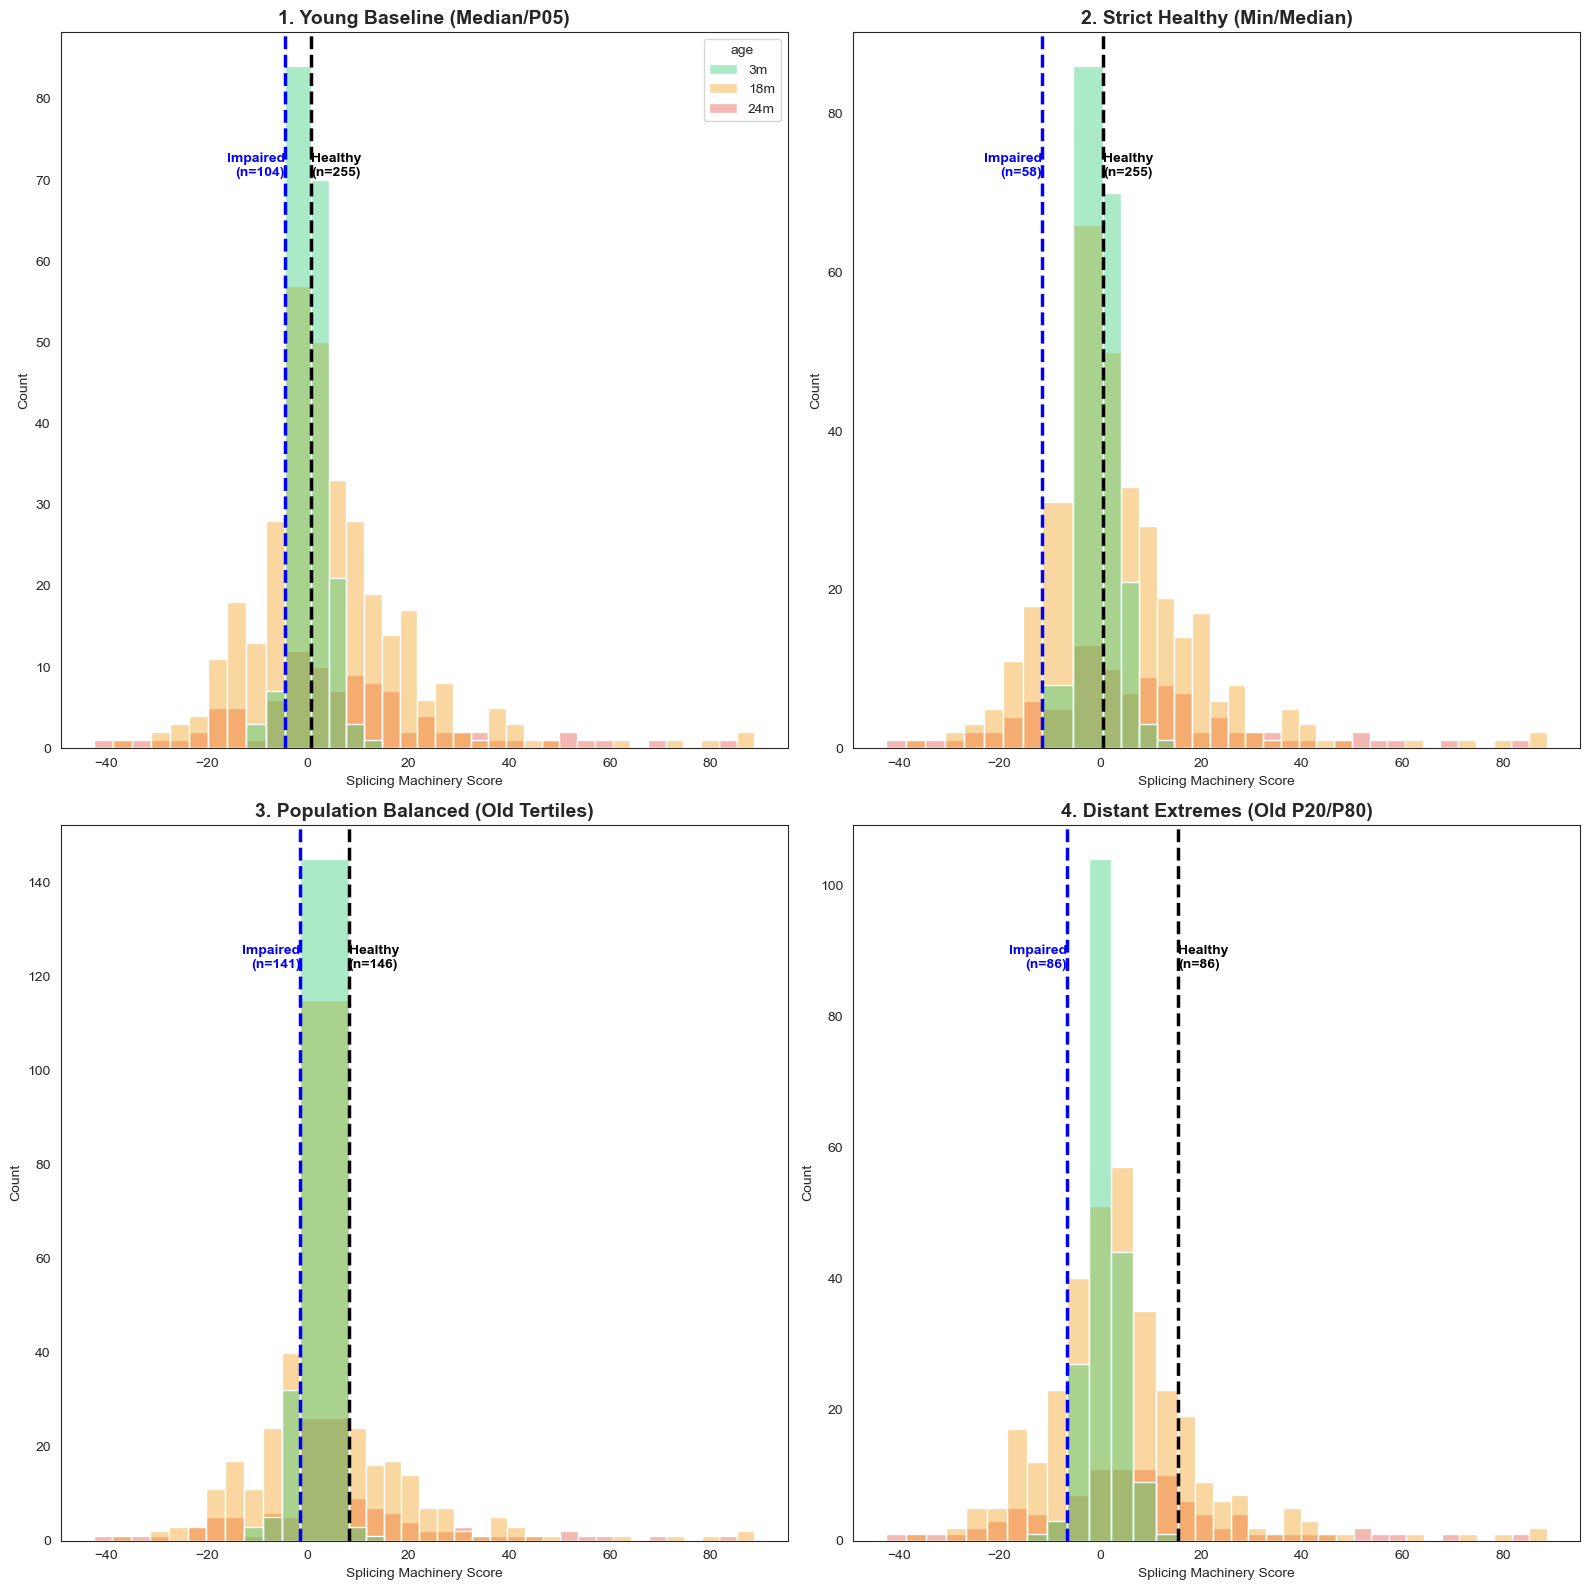

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# =============================================================================
# 1. LOAD DATA & ISOLATE ENDOTHELIAL CELLS
# =============================================================================
file_path = "Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad"
print(f"Loading {file_path}...")
adata = sc.read_h5ad(file_path)

target_val = 'endothelial cell of hepatic sinusoid'
# Subset for all ages of this cell type
endo = adata[adata.obs['cell_ontology_class'] == target_val].copy()

# CRITICAL: Align index to symbols for scoring
if 'mouse_gene_symbols' in endo.var.columns:
    endo.var_names = endo.var['mouse_gene_symbols'].astype(str)
    endo.var_names_make_unique()

# =============================================================================
# 2. CALCULATE SPLICING MACHINERY SCORE
# =============================================================================
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

all_splicing_genes = []
for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            valid = [g for g in [l.strip() for l in lines[1:]] if g in endo.var_names]
            all_splicing_genes.extend(valid)

all_splicing_genes = list(set(all_splicing_genes))
print(f"Scoring using {len(all_splicing_genes)} splicing genes...")
sc.tl.score_genes(endo, all_splicing_genes, score_name='splicing_score')

# =============================================================================
# 3. DEFINE EXPLORATION STRATEGIES
# =============================================================================
# Split into Young (Reference) and Old (Analysis Population)
young_scores = endo.obs.loc[endo.obs['age'] == '3m', 'splicing_score']
old_scores = endo.obs.loc[endo.obs['age'].isin(['18m', '24m']), 'splicing_score']

# We define 4 ways to cut the data based on score magnitude
# Note: For splicing, High = Healthy, Low = Impaired
strategies = {
    "1. Young Baseline (Median/P05)": {
        'low': young_scores.quantile(0.05), # Bottom 5% of young
        'high': young_scores.median()       # Median of young
    },
    "2. Strict Healthy (Min/Median)": {
        'low': young_scores.min(),
        'high': young_scores.median()
    },
    "3. Population Balanced (Old Tertiles)": {
        'low': old_scores.quantile(0.33),
        'high': old_scores.quantile(0.66)
    },
    "4. Distant Extremes (Old P20/P80)": {
        'low': old_scores.quantile(0.20),
        'high': old_scores.quantile(0.80)
    }
}

# =============================================================================
# 4. PLOTTING THE GRID (Colored by Age)
# =============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
axes = axes.flatten()
sns.set_style("white")

age_palette = {'3m': '#2ecc71', '18m': '#f39c12', '24m': '#e74c3c'}
age_order = ['3m', '18m', '24m']
bin_width = (old_scores.max() - old_scores.min()) / 40 # Adaptive bin width

def get_aligned_bins(start, t1, t2, end, width):
    b1 = np.linspace(start, t1, max(2, int(abs(t1-start)/width)))
    b2 = np.linspace(t1, t2, max(2, int(abs(t2-t1)/width)))
    b3 = np.linspace(t2, end, max(2, int(abs(end-t2)/width)))
    return np.unique(np.concatenate([b1, b2, b3]))

print(f"{'STRATEGY':<35} | {'IMPAIRED':<8} | {'INTER':<8} | {'HEALTHY':<8}")
print("-" * 75)

for i, (name, thresh) in enumerate(strategies.items()):
    ax = axes[i]
    t_l, t_h = thresh['low'], thresh['high']
    
    # Stats for Console (Calculating n for Old cells only)
    n_imp = (old_scores <= t_l).sum()
    n_heal = (old_scores > t_h).sum()
    n_inter = len(old_scores) - (n_imp + n_heal)
    print(f"{name:<35} | {n_imp:<8} | {n_inter:<8} | {n_heal:<8}")

    # Plot
    x_min, x_max = endo.obs['splicing_score'].min(), endo.obs['splicing_score'].max()
    bins = get_aligned_bins(x_min, t_l, t_h, x_max, bin_width)
    
    sns.histplot(data=endo.obs, x='splicing_score', hue='age', hue_order=age_order,
                 palette=age_palette, bins=bins, element="bars", fill=True, alpha=0.4, 
                 common_norm=False, edgecolor="white", ax=ax, legend=(i==0))
    
    # Threshold Lines: Blue (Impaired cutoff), Black (Healthy cutoff)
    ax.axvline(t_l, color='blue', linestyle='--', lw=2.5, zorder=10)
    ax.axvline(t_h, color='black', linestyle='--', lw=2.5, zorder=10)
    
    # Annotation of Counts for Old Cells
    ax.text(t_l - 0.01, ax.get_ylim()[1]*0.8, f"Impaired\n(n={n_imp})", color='blue', ha='right', fontweight='bold')
    ax.text(t_h + 0.01, ax.get_ylim()[1]*0.8, f"Healthy\n(n={n_heal})", color='black', ha='left', fontweight='bold')

    ax.set_title(name, fontsize=14, fontweight='bold')
    ax.set_xlabel("Splicing Machinery Score")

plt.tight_layout()
plt.show()

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import os

# =============================================================================
# 1. LOAD DATA
# =============================================================================
print("Loading Liver Atlas...")
adata = sc.read_h5ad("Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad")

# =============================================================================
# 2. ISOLATE OLD ENDOTHELIAL CELLS (18m & 24m)
# =============================================================================
target_val = 'endothelial cell of hepatic sinusoid'
print(f"Isolating old {target_val}...")

# Filter for cell type AND age
adata_old = adata[
    (adata.obs['cell_ontology_class'] == target_val) & 
    (adata.obs['age'].isin(['18m', '24m']))
].copy()

# Align index to gene symbols for scoring
if 'mouse_gene_symbols' in adata_old.var.columns:
    adata_old.var_names = adata_old.var['mouse_gene_symbols'].astype(str)
    adata_old.var_names_make_unique()

# =============================================================================
# 3. CALCULATE SPLICING MACHINERY SCORE
# =============================================================================
paths = {
    'Spliceosomal Complex': 'Spliceosomal Complex.txt',
    'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
    'RNA Splicing': 'RNA Splicing.txt'
}

all_splicing_genes = []
genes_in_data = set(adata_old.var_names)

for label, path in paths.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            # Standard logic: skip header, strip whitespace/quotes
            valid = [g for g in [l.strip().strip('"').strip("'") for l in lines[1:]] if g in genes_in_data]
            all_splicing_genes.extend(valid)

all_splicing_genes = sorted(list(set(all_splicing_genes)))
print(f"Scoring using {len(all_splicing_genes)} matched splicing genes...")

# Calculate the enrichment score
sc.tl.score_genes(adata_old, all_splicing_genes, score_name='splicing_score')

# =============================================================================
# 4. DEFINE EXTREME TAILS (P20 & P80)
# =============================================================================
# Calculate thresholds specifically on the old population
t_low = adata_old.obs['splicing_score'].quantile(0.20)
t_high = adata_old.obs['splicing_score'].quantile(0.80)

# Assign groups
# Note: For splicing machinery, HIGH score = Healthy, LOW score = Impaired
adata_old.obs['splicing_group'] = 'Intermediate_Splicing'
adata_old.obs.loc[adata_old.obs['splicing_score'] <= t_low, 'splicing_group'] = 'Impaired_Splicing'
adata_old.obs.loc[adata_old.obs['splicing_score'] >= t_high, 'splicing_group'] = 'Healthy_Splicing'

# =============================================================================
# 5. REPORTING & VERIFICATION
# =============================================================================
print("\n" + "="*60)
print(f"SPLICING EXTREMES SUMMARY: {target_val}")
print("="*60)
print(f"Impaired Threshold (P20):  {t_low:.4f}")
print(f"Healthy Threshold (P80):   {t_high:.4f}")
print("-" * 60)
counts = adata_old.obs['splicing_group'].value_counts()
print("Group Composition (Number of cells):")
print(counts)
print("-" * 60)
print("Breakdown by Age:")
print(pd.crosstab(adata_old.obs['age'], adata_old.obs['splicing_group']))
print("="*60)

# =============================================================================
# 6. SAVE FOR VAST-TOOLS WORKFLOW
# =============================================================================
# Suffix updated to match your naming convention
output_name = "Old_Endothelial_Splicing_3groups.h5ad"
adata_old.write(output_name)

print(f"\n[SUCCESS] File saved as: {output_name}")
print("You can now proceed to FASTQ pooling using the 'splicing_group' column.")

Loading Liver Atlas...
Isolating old endothelial cell of hepatic sinusoid...
Scoring using 339 matched splicing genes...

SPLICING EXTREMES SUMMARY: endothelial cell of hepatic sinusoid
Impaired Threshold (P20):  -21.2305
Healthy Threshold (P80):   3.7717
------------------------------------------------------------
Group Composition (Number of cells):
splicing_group
Intermediate_Splicing    256
Healthy_Splicing          86
Impaired_Splicing         86
Name: count, dtype: int64
------------------------------------------------------------
Breakdown by Age:
splicing_group  Healthy_Splicing  Impaired_Splicing  Intermediate_Splicing
age                                                                       
18m                           58                 66                    206
24m                           28                 20                     50

[SUCCESS] File saved as: Old_Endothelial_Splicing_3groups.h5ad
You can now proceed to FASTQ pooling using the 'splicing_group' column.


---

Loading Senescence and Splicing AnnData objects...


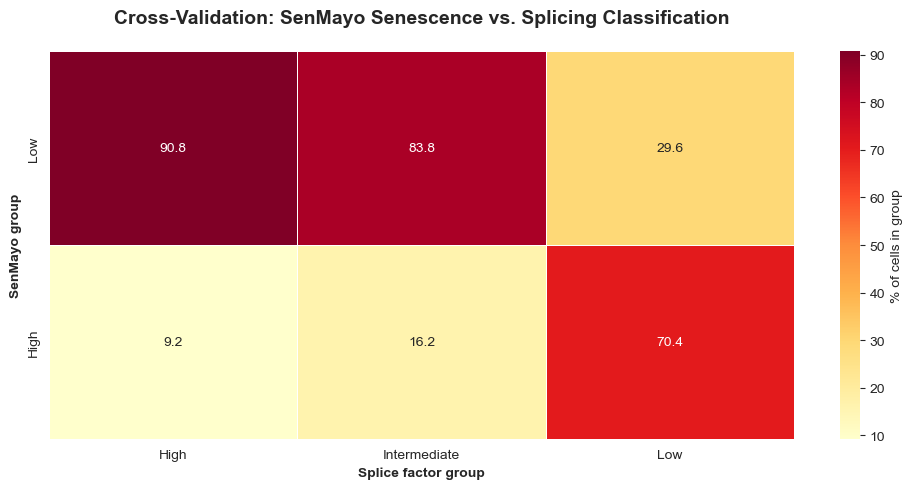


CELL COUNT CROSS-TABULATION
splicing_group    High  Intermediate  Low
senescence_group                         
Low                138           382   45
High                14            74  107
----------------------------------------------------------------------
PERCENTAGE BREAKDOWN (Row %):
splicing_group     High  Intermediate    Low
senescence_group                            
Low               90.79         83.77  29.61
High               9.21         16.23  70.39

BIOLOGICAL CORRESPONDENCE CHECK:
1. Sensitivity: 70.4% of High-SenMayo cells overlap with the Low-Splicing group.
2. Specificity: 90.8% of Low-SenMayo cells overlap with the High-Splicing group.


In [3]:
import scanpy as sc
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. LOAD BOTH FILES
print("Loading Senescence and Splicing AnnData objects...")
adata_sen = sc.read_h5ad("Old_Hepatocytes_95th_Senescence_Groups_for_VastTools.h5ad")
adata_spl = sc.read_h5ad("Old_Hepatocytes_Splicing_3groups.h5ad")

# 2. EXTRACT METADATA (.obs)
df_sen = adata_sen.obs[['senescence_group']].copy()
df_spl = adata_spl.obs[['splicing_group']].copy()

# 3. MERGE METADATA ON CELL BARCODE (Index)
merged_df = df_sen.merge(df_spl, left_index=True, right_index=True, how='inner')

# =============================================================================
# 4. RENAME AND REORDER CATEGORIES
# =============================================================================

# Define the Mappings
splicing_map = {
    'Healthy_Splicing': 'High',
    'Intermediate_Splicing': 'Intermediate',
    'Impaired_Splicing': 'Low'
}

senescence_map = {
    'Low_Senescence': 'Low',
    'High_Senescence': 'High'
}

# Apply Renaming
merged_df['splicing_group'] = merged_df['splicing_group'].map(splicing_map)
merged_df['senescence_group'] = merged_df['senescence_group'].map(senescence_map)

# Define the specific order
# For X-axis: High, Intermediate, Low
spl_order = ['High', 'Intermediate', 'Low']
# For Y-axis: Low (top row), High (bottom row)
sen_order = ['Low', 'High']

# Convert to Categorical to force the order
merged_df['splicing_group'] = pd.Categorical(merged_df['splicing_group'], categories=spl_order, ordered=True)
merged_df['senescence_group'] = pd.Categorical(merged_df['senescence_group'], categories=sen_order, ordered=True)

# =============================================================================
# 5. CALCULATE PERCENTAGES
# =============================================================================
pct_table = pd.crosstab(merged_df['senescence_group'], 
                        merged_df['splicing_group'], 
                        normalize='columns') * 100

counts_table = pd.crosstab(merged_df['senescence_group'], merged_df['splicing_group'])

# =============================================================================
# 6. VISUALIZATION
# =============================================================================
plt.figure(figsize=(10, 5))
sns.set_style("white")

# Heatmap
ax = sns.heatmap(pct_table, annot=True, fmt=".1f", cmap="YlOrRd", 
            linewidths=0.5, cbar_kws={'label': '% of cells in group'})

plt.title("Cross-Validation: SenMayo Senescence vs. Splicing Classification", 
          fontsize=14, fontweight='bold', pad=20)

# Updated Axis Labels
plt.ylabel("SenMayo group", fontweight='bold')
plt.xlabel("Splice factor group", fontweight='bold')

plt.tight_layout()
plt.show()

# =============================================================================
# 7. TEXT REPORT (Updated with new names)
# =============================================================================
print("\n" + "="*70)
print("CELL COUNT CROSS-TABULATION")
print("="*70)
print(counts_table)
print("-" * 70)
print("PERCENTAGE BREAKDOWN (Row %):")
print(pct_table.round(2))
print("="*70)

# Check logic updated to new labels
hi_sen_in_low_spl = pct_table.loc['High', 'Low']
low_sen_in_high_spl = pct_table.loc['Low', 'High']

print(f"\nBIOLOGICAL CORRESPONDENCE CHECK:")
print(f"1. Sensitivity: {hi_sen_in_low_spl:.1f}% of High-SenMayo cells overlap with the Low-Splicing group.")
print(f"2. Specificity: {low_sen_in_high_spl:.1f}% of Low-SenMayo cells overlap with the High-Splicing group.")

Loading Liver Atlas...
Calculating Global Context Score (includes 3m cells)...
Calculating Local Context Score (excludes 3m cells)...


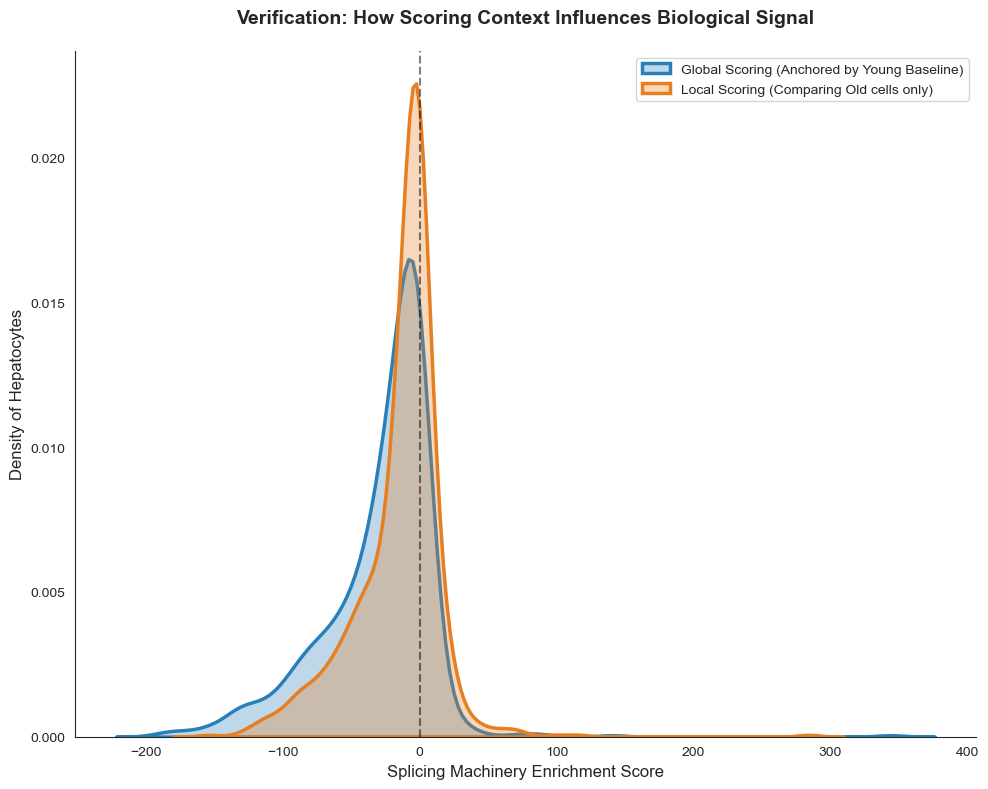


SENSITIVITY VERDICT
Mean (Global): -29.5203
Mean (Local):  -15.6720
--------------------------------------------------
The 'Local' curve is likely centered closer to 0.
The 'Global' curve represents the true decline relative to youth.


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# =============================================================================
# --- STEP 1: LOAD FULL DATA (establishing context) ---
# =============================================================================
file_path = "Liver_facs_filtered_nonzero_normalized_HVG_reduced_clustered_annotated_allscores.h5ad"
print("Loading Liver Atlas...")
adata_full = sc.read_h5ad(file_path)

# Isolate all hepatocytes (3m, 18m, 24m)
adata_heps = adata_full[adata_full.obs['cell_ontology_class'] == 'hepatocyte'].copy()

# Align Index
if 'mouse_gene_symbols' in adata_heps.var.columns:
    adata_heps.var_names = adata_heps.var['mouse_gene_symbols'].astype(str)
    adata_heps.var_names_make_unique()

# =============================================================================
# --- STEP 2: LOAD GENE SET ---
# =============================================================================
paths = {'Spliceosomal Complex': 'Spliceosomal Complex.txt',
         'mRNA Splicing': 'mRNA Splicing via spliceosome.txt',
         'RNA Splicing': 'RNA Splicing.txt'}

all_splicing_genes = []
for path in paths.values():
    if os.path.exists(path):
        with open(path, 'r') as f:
            all_splicing_genes.extend([line.strip() for line in f.readlines()[1:] if line.strip() in adata_heps.var_names])
all_splicing_genes = list(set(all_splicing_genes))

# =============================================================================
# --- STEP 3: CALCULATE BOTH SCORES ---
# =============================================================================
# 1. Global context: Score calculated using all 1161 cells (including young)
print("Calculating Global Context Score (includes 3m cells)...")
sc.tl.score_genes(adata_heps, all_splicing_genes, score_name='score_global')

# 2. Local context: Isolate old cells first, then score (error logic)
adata_old = adata_heps[adata_heps.obs['age'].isin(['18m', '24m'])].copy()
print("Calculating Local Context Score (excludes 3m cells)...")
sc.tl.score_genes(adata_old, all_splicing_genes, score_name='score_local')

# =============================================================================
# --- STEP 4: VISUALIZE THE "SQUASHING" EFFECT ---
# =============================================================================
# We pull the global scores for the specific cells present in adata_old
global_vals = adata_heps[adata_old.obs_names].obs['score_global']
local_vals = adata_old.obs['score_local']

plt.figure(figsize=(10, 8))
sns.set_style("white")

# Plotting distributions for the SAME cells under different contexts
sns.kdeplot(global_vals, fill=True, label='Global Scoring (Anchored by Young Baseline)', 
            color='#2980b9', linewidth=2.5, alpha=0.3)
sns.kdeplot(local_vals, fill=True, label='Local Scoring (Comparing Old cells only)', 
            color='#e67e22', linewidth=2.5, alpha=0.3)

# Reference line at 0 (Average expression of control genes)
plt.axvline(0, color='black', linestyle='--', alpha=0.5)

# Formatting
plt.title('Verification: How Scoring Context Influences Biological Signal', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Splicing Machinery Enrichment Score', fontsize=12)
plt.ylabel('Density of Hepatocytes', fontsize=12)
plt.legend(loc='upper right', frameon=True)
sns.despine()

plt.tight_layout()
plt.show()

# =============================================================================
# --- STATISTICAL VERDICT ---
# =============================================================================
print("\n" + "="*50)
print("SENSITIVITY VERDICT")
print("="*50)
print(f"Mean (Global): {global_vals.mean():.4f}")
print(f"Mean (Local):  {local_vals.mean():.4f}")
print("-" * 50)
print("The 'Local' curve is likely centered closer to 0.")
print("The 'Global' curve represents the true decline relative to youth.")
print("="*50)